In [1]:
rm(list = ls())
options(stringsAsFactors = FALSE)
getwd()

[1] "/Users/luye/Library/Mobile Documents/com~apple~CloudDocs/Projects/Ongoing/202504ZL"

In [2]:
############################################################
# iCCA RNAseq数据集整合与分子分型分析
# 包括批次效应评估、数据整合、聚类和特征基因识别
############################################################

In [4]:
# 安装必要的程序包（如果尚未安装）
if (!requireNamespace("BiocManager", quietly = TRUE))
  install.packages("BiocManager")

required_packages <- c("sva", "ConsensusClusterPlus", "limma", "pheatmap", 
                      "ggplot2", "RColorBrewer", "NMF", "cluster", "gplots",
                      "clusterProfiler", "org.Hs.eg.db", "EnhancedVolcano",
                      "ggrepel", "fgsea", "factoextra", "corrplot", "survival", 
                      "survminer", "umap", "WGCNA")

for (pkg in required_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    if (pkg %in% c("limma", "sva", "ConsensusClusterPlus", "clusterProfiler", 
                   "org.Hs.eg.db", "fgsea", "WGCNA")) {
      BiocManager::install(pkg)
    } else {
      install.packages(pkg)
    }
  }
  library(pkg, character.only = TRUE)
}

In [3]:
# 设置随机种子，确保结果可重复
set.seed(61)

In [5]:
# 创建输出目录
output_dir <- "1-Clustering"
dir.create(output_dir, showWarnings = FALSE, recursive = TRUE)
fig_dir <- file.path(output_dir, "figures")
dir.create(fig_dir, showWarnings = FALSE)
data_dir <- file.path(output_dir, "data")
dir.create(data_dir, showWarnings = FALSE)

#===============================================================
# 第1部分: 数据准备与整合
#===============================================================

In [6]:
load(file = "./0-Data/0-Data-rnaseq.Rdata")
# 创建数据集列表
datasets <- list(
  "Ahn2019" = log2tpm_2019Ahn,
  "Dong2022" = log2tpm_2022Dong,
  "Deng2023" = log2tpm_2023Deng,
  "Jeon2023" = log2tpm_2023Jeon,
  "Lee2023" = log2tpm_2023Lee,
  "Fan2024" = log2tpm_2024Fan,
  "TCGA" = log2tpm_tcga
)

# 检查每个数据集的维度
cat("Data summary:\n")
for (name in names(datasets)) {
  cat(sprintf("%s: %d genes x %d samples\n", name, nrow(datasets[[name]]), ncol(datasets[[name]])))
}

Data summary:
Ahn2019: 18128 genes x 30 samples
Dong2022: 15511 genes x 255 samples
Deng2023: 12666 genes x 84 samples
Jeon2023: 18345 genes x 59 samples
Lee2023: 17611 genes x 13 samples
Fan2024: 20992 genes x 114 samples
TCGA: 20013 genes x 31 samples


In [7]:
# 找出共同基因
common_genes <- Reduce(intersect, lapply(datasets, rownames))
cat(sprintf("Common genes: %d\n", length(common_genes)))

Common genes: 10531


In [8]:
# 提取共同基因表达数据并合并
combined_expr <- NULL
batch_labels <- c()
sample_info <- data.frame(
  Sample = character(),
  Dataset = character(),
  stringsAsFactors = FALSE
)

for (name in names(datasets)) {
  current_data <- datasets[[name]][common_genes, ]
  
  # 记录样本信息
  current_samples <- data.frame(
    Sample = colnames(current_data),
    Dataset = rep(name, ncol(current_data)),
    stringsAsFactors = FALSE
  )
  sample_info <- rbind(sample_info, current_samples)
  
  # 合并表达矩阵
  if (is.null(combined_expr)) {
    combined_expr <- current_data
  } else {
    combined_expr <- cbind(combined_expr, current_data)
  }
  
  # 记录批次信息
  batch_labels <- c(batch_labels, rep(name, ncol(current_data)))
}

# 确保行列名正确
rownames(combined_expr) <- common_genes
colnames(combined_expr) <- sample_info$Sample

In [9]:
dim(combined_expr)
head(combined_expr)

[1] 10531   586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TMSB10,12.42285,12.484571,13.53880,14.371845,12.588715,12.819780,11.62890,11.99223,12.89766,13.76290,...,13.07475,13.10433,13.17295,14.086709,13.559507,14.705270,13.848072,13.4938287,13.27971,11.573455
ALB,12.81017,13.938569,11.55651,6.530445,7.824004,5.313971,13.39888,13.20717,10.84078,10.78463,...,11.32158,12.51302,11.00012,12.814422,2.727877,8.770168,7.728296,0.8095791,12.90087,7.850412
FTL,11.67904,13.910736,12.73534,12.085804,13.156241,13.150382,14.86791,13.33050,12.10362,12.09342,...,13.11082,11.12466,11.90212,11.775967,13.644783,13.683527,14.707300,12.9866967,12.07425,12.788640
S100A6,12.64002,7.914086,13.86312,13.316423,13.385458,12.455070,10.10460,13.22521,12.90087,13.01768,...,12.00041,12.08158,10.07790,9.291329,13.720643,13.265563,11.966502,9.6517368,10.32510,9.784263
RPS18,12.62867,12.705200,12.98620,12.816784,12.101647,11.588715,11.74020,12.31203,14.03626,12.63458,...,11.95021,12.44324,10.92414,11.874976,10.851977,10.948616,11.182886,12.4480687,11.92380,10.963043
TMSB4X,12.01681,11.809366,12.71960,13.125091,12.709299,12.696533,12.17866,12.81438,12.28915,13.25400,...,10.68554,10.83844,10.63022,11.553805,11.987683,12.248743,10.821340,12.7196008,11.11425,9.493028


In [10]:
# 检查合并后的数据维度
cat(sprintf("Merged dataset: %dGene x %dSample\n", nrow(combined_expr), ncol(combined_expr)))

Merged dataset: 10531Gene x 586Sample


In [25]:
save(combined_expr, file = paste0(data_dir, "/combined_expr_before_correction.rds"))

#===============================================================
# 第2部分: 批次效应评估与校正
#===============================================================

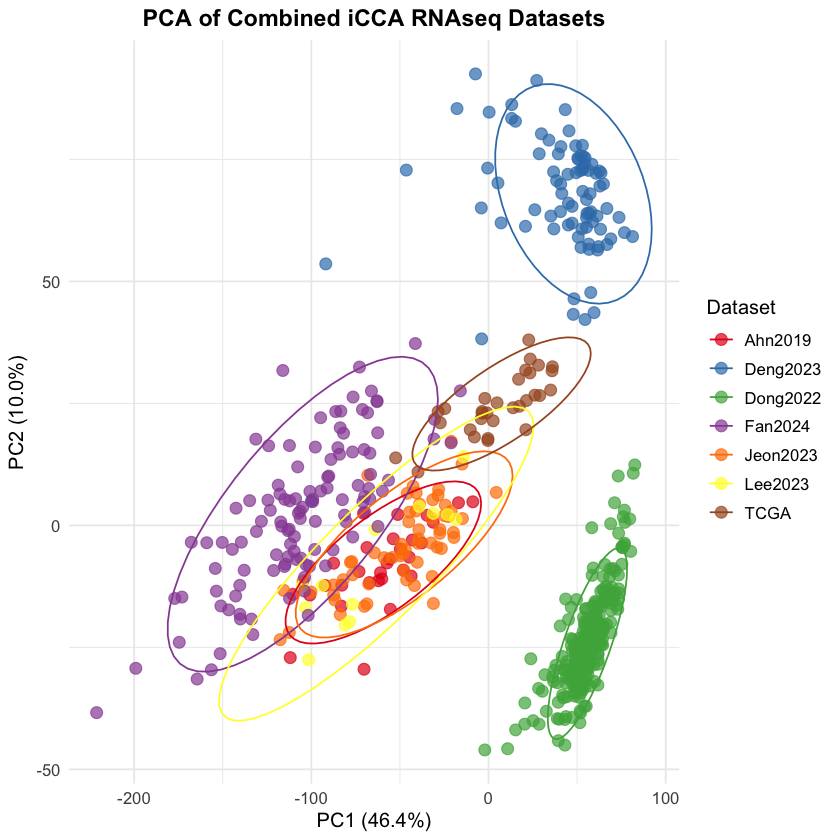

In [11]:
# PCA分析可视化批次效应
pca_res <- prcomp(t(combined_expr), scale = TRUE, center = TRUE)
var_explained <- (pca_res$sdev^2) / sum(pca_res$sdev^2) * 100

# 提取前两个主成分用于绘图
pca_data <- as.data.frame(pca_res$x[, 1:10])
pca_data$Dataset <- factor(batch_labels)

# 绘制PCA图
p1 <- ggplot(pca_data, aes(x = PC1, y = PC2, color = Dataset)) +
  geom_point(size = 3, alpha = 0.7) +
  stat_ellipse(aes(group = Dataset), level = 0.95) +
  labs(
    title = "PCA of Combined iCCA RNAseq Datasets",
    x = sprintf("PC1 (%.1f%%)", var_explained[1]),
    y = sprintf("PC2 (%.1f%%)", var_explained[2])
  ) +
  theme_minimal() +
  theme(
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
    legend.title = element_text(size = 12),
    legend.text = element_text(size = 10),
    axis.title = element_text(size = 12),
    axis.text = element_text(size = 10)
  ) +
  scale_color_brewer(palette = "Set1")
p1
# 保存PCA图
ggsave(file.path(fig_dir, "PCA_before_correction.pdf"), p1, width = 10, height = 8)

In [12]:
# 定量评估批次效应 - 检查主成分与批次的相关性
pc_batch_correlation <- function(pca_result, batch_factor, n_pcs = 10) {
  n_pcs <- min(n_pcs, ncol(pca_result$x))
  pcs <- pca_result$x[, 1:n_pcs]
  result <- data.frame(PC = character(), R_squared = numeric(), P_value = numeric())
  
  for (i in 1:ncol(pcs)) {
    pc_name <- colnames(pcs)[i]
    # ANOVA分析PC与批次的关系
    fit <- aov(pcs[, i] ~ factor(batch_factor))
    r_squared <- summary(fit)[[1]]["Sum Sq"][1, ] / sum(summary(fit)[[1]]["Sum Sq"])
    p_value <- summary(fit)[[1]]["Pr(>F)"][1, ]
    
    result <- rbind(result, data.frame(
      PC = pc_name,
      R_squared = r_squared,
      P_value = p_value,
      stringsAsFactors = FALSE
    ))
  }
  
  return(result)
}

# 计算PCs与批次的相关性
pc_batch_corr <- pc_batch_correlation(pca_res, batch_labels)
print(pc_batch_corr)

     PC  R_squared       P_value
1   PC1 0.87496457 1.265443e-257
2   PC2 0.87918032 6.225653e-262
3   PC3 0.91067492 7.121677e-300
4   PC4 0.09464955  1.276469e-10
5   PC5 0.03110212  5.399150e-03
6   PC6 0.22355615  3.332513e-29
7   PC7 0.09876183  3.708986e-11
8   PC8 0.56492214 3.149037e-101
9   PC9 0.02924901  8.417293e-03
10 PC10 0.22680586  1.018101e-29


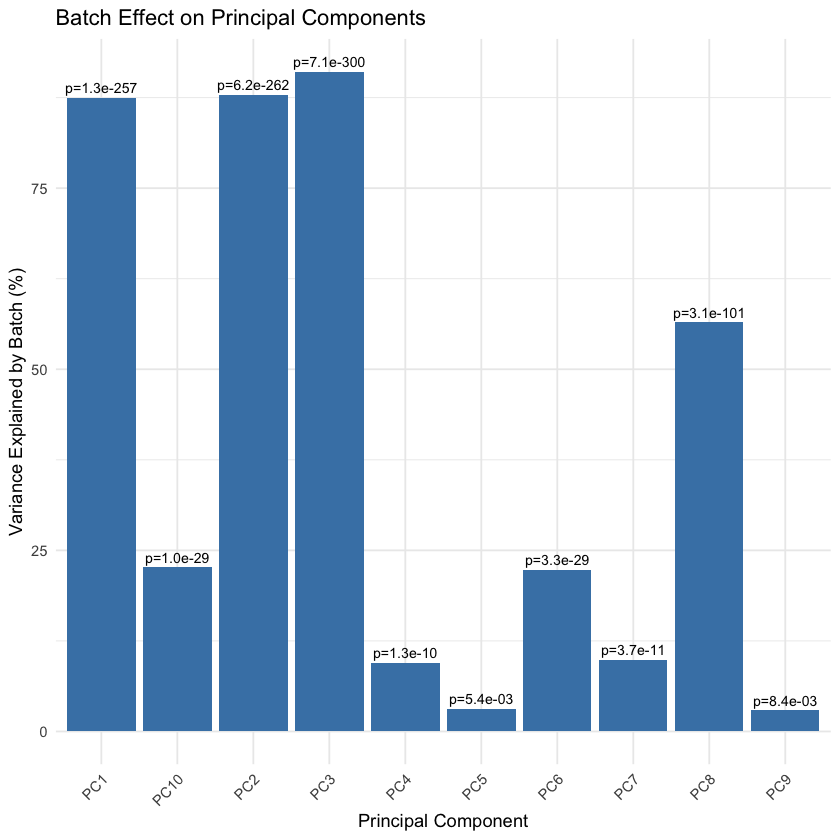

In [13]:
# 绘制主成分与批次相关性条形图
p2 <- ggplot(pc_batch_corr, aes(x = PC, y = R_squared * 100)) +
  geom_bar(stat = "identity", fill = "steelblue") +
  geom_text(aes(label = sprintf("p=%.1e", P_value)), vjust = -0.5, size = 3) +
  theme_minimal() +
  labs(
    title = "Batch Effect on Principal Components",
    x = "Principal Component",
    y = "Variance Explained by Batch (%)"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
p2
# 保存批次效应评估图
ggsave(file.path(fig_dir, "PC_batch_correlation.pdf"), p2, width = 10, height = 6)

In [14]:
# 基于PC批次相关性结果判断是否需要批次校正
# 如果PC1/PC2与批次有显著相关性(R^2>0.3, p<0.05)，则需要校正
significant_batch_effect <- (
  (pc_batch_corr$R_squared[1] > 0.3 & pc_batch_corr$P_value[1] < 0.05) |
  (pc_batch_corr$R_squared[2] > 0.3 & pc_batch_corr$P_value[2] < 0.05)
)

cat(sprintf("Batch effect evaluation: Main PC and batch correlation R^2(PC1)=%.2f, p=%.1e\n", 
            pc_batch_corr$R_squared[1], pc_batch_corr$P_value[1]))
cat(sprintf("Batch effect is significant (R^2>0.3 & p<0.05): %s\n", 
            ifelse(significant_batch_effect, "Yes - Correction recommended", "No - Correction optional")))

Batch effect evaluation: Main PC and batch correlation R^2(PC1)=0.87, p=1.3e-257
Batch effect is significant (R^2>0.3 & p<0.05): Yes - Correction recommended


In [15]:
# Ensure the limma library is loaded
if (!requireNamespace("limma", quietly = TRUE)) {
  if (!requireNamespace("BiocManager", quietly = TRUE)) {
    install.packages("BiocManager")
  }
  BiocManager::install("limma")
}
library(limma)

cat("Performing batch correction using limma::removeBatchEffect...\n")

# 'combined_expr' is your log-transformed TPM data (genes as rows, samples as columns)
# 'batch_labels' is your vector indicating the batch for each sample

# Ensure batch_labels is a factor if it's not already
# (though removeBatchEffect can handle a character vector for the batch argument)
batch_factor <- factor(batch_labels)

# Apply limma::removeBatchEffect
# For log-TPM data, and when not specifying other covariates to protect,
# this is a common approach.
# removeBatchEffect expects log-transformed data.
corrected_expr_limma <- removeBatchEffect(
  x = combined_expr,
  batch = batch_factor
  # You can optionally add a design matrix if you have covariates to preserve,
  # e.g., design = model.matrix(~ some_other_covariate, data = sample_info_df)
  # If no other covariates, it defaults to preserving the overall mean.
)

cat("Batch correction with limma completed.\n")

Performing batch correction using limma::removeBatchEffect...
Batch correction with limma completed.


In [26]:
save(corrected_expr_limma, file = paste0(data_dir, "/combined_expr_after_correction.rds"))

In [16]:
# --- Validate correction effect ---
cat("Performing PCA on limma-corrected data to validate correction effect...\n")
pca_corrected <- prcomp(t(corrected_expr_limma), scale. = TRUE, center = TRUE)
var_explained_corrected <- (pca_corrected$sdev^2) / sum(pca_corrected$sdev^2) * 100

pca_data_corrected <- as.data.frame(pca_corrected$x[, 1:10]) # Using first 10 PCs
pca_data_corrected$Dataset <- factor(batch_labels) # Use the original batch_labels for coloring

Performing PCA on limma-corrected data to validate correction effect...


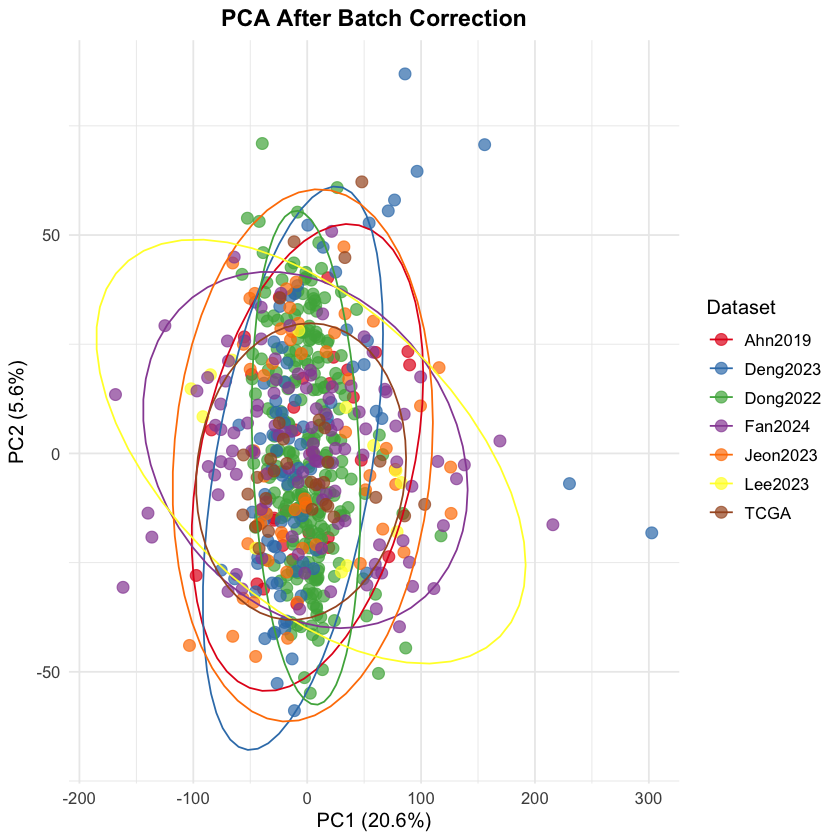

In [17]:
# 绘制校正后的PCA图
p3 <- ggplot(pca_data_corrected, aes(x = PC1, y = PC2, color = Dataset)) +
  geom_point(size = 3, alpha = 0.7) +
  stat_ellipse(aes(group = Dataset), level = 0.95) +
  labs(
    title = "PCA After Batch Correction",
    x = sprintf("PC1 (%.1f%%)", var_explained_corrected[1]),
    y = sprintf("PC2 (%.1f%%)", var_explained_corrected[2])
  ) +
  theme_minimal() +
  theme(
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
    legend.title = element_text(size = 12),
    legend.text = element_text(size = 10),
    axis.title = element_text(size = 12),
    axis.text = element_text(size = 10)
  ) +
  scale_color_brewer(palette = "Set1")
p3
# 保存校正后PCA图
ggsave(file.path(fig_dir, "PCA_after_correction.pdf"), p3, width = 10, height = 8)

Quantitatively evaluating batch effect on limma-corrected data...


     PC    R_squared P_value
1   PC1 8.148303e-29       1
2   PC2 3.079206e-30       1
3   PC3 5.801993e-31       1
4   PC4 2.465301e-29       1
5   PC5 1.706591e-28       1
6   PC6 6.421005e-30       1
7   PC7 6.542006e-29       1
8   PC8 5.703397e-30       1
9   PC9 1.405716e-29       1
10 PC10 8.381156e-30       1
Batch effect evaluation AFTER LIMMA: Main PC and batch correlation R^2(PC1)=0.00, p=1.0e+00
Batch effect is still significant (R^2>0.3 & p<0.05) after limma: No


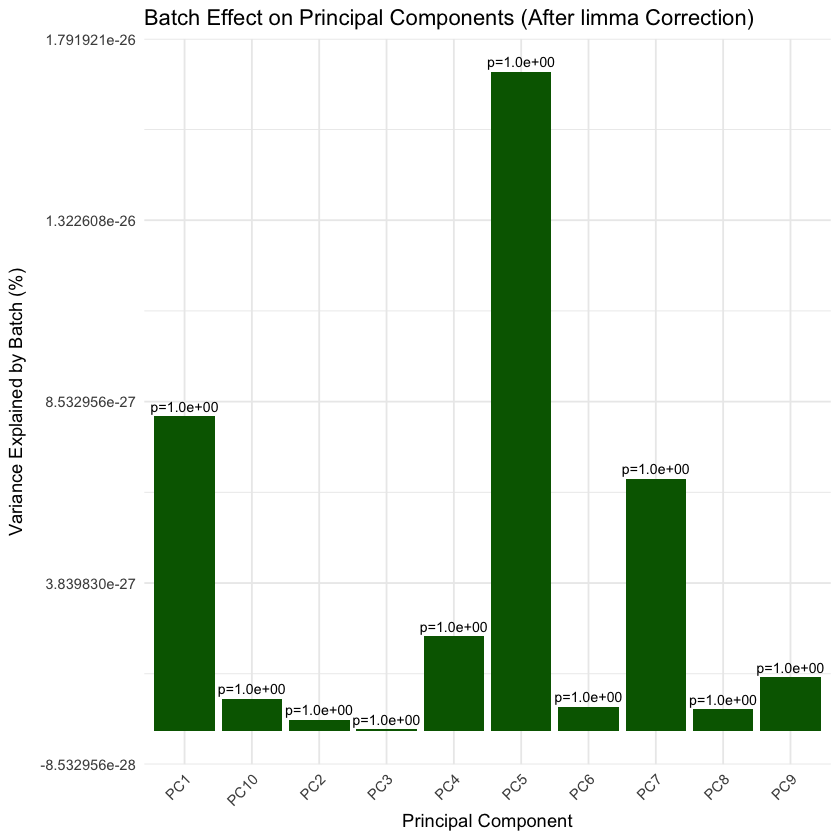

In [18]:
# Define fig_dir if not already defined (replace with your actual figure directory)
# fig_dir <- "path/to/your/figures"
# ggsave(file.path(fig_dir, "PCA_after_limma_correction.pdf"), p_corrected, width = 10, height = 8)

# --- Quantitatively re-evaluate batch effect on corrected data ---
cat("Quantitatively evaluating batch effect on limma-corrected data...\n")
pc_batch_corr_corrected <- pc_batch_correlation(pca_corrected, batch_labels) # Using your existing function
print(pc_batch_corr_corrected)

# Plot the R-squared values for the corrected data
p_corr_corrected_plot <- ggplot(pc_batch_corr_corrected, aes(x = PC, y = R_squared * 100)) +
  geom_bar(stat = "identity", fill = "darkgreen") + # Changed color for distinction
  geom_text(aes(label = sprintf("p=%.1e", P_value)), vjust = -0.5, size = 3) +
  theme_minimal() +
  labs(
    title = "Batch Effect on Principal Components (After limma Correction)",
    x = "Principal Component",
    y = "Variance Explained by Batch (%)"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

print(p_corr_corrected_plot)
ggsave(file.path(fig_dir, "PC_batch_correlation_after_limma.pdf"), p_corr_corrected_plot, width = 10, height = 6)

# --- Re-evaluate if correction was sufficient ---
significant_batch_effect_after_limma <- (
  (pc_batch_corr_corrected$R_squared[1] > 0.3 & pc_batch_corr_corrected$P_value[1] < 0.05) |
  (pc_batch_corr_corrected$R_squared[2] > 0.3 & pc_batch_corr_corrected$P_value[2] < 0.05)
)

cat(sprintf("Batch effect evaluation AFTER LIMMA: Main PC and batch correlation R^2(PC1)=%.2f, p=%.1e\n",
            pc_batch_corr_corrected$R_squared[1], pc_batch_corr_corrected$P_value[1]))
cat(sprintf("Batch effect is still significant (R^2>0.3 & p<0.05) after limma: %s\n",
            ifelse(significant_batch_effect_after_limma, "Yes", "No")))

#===============================================================
# 第3部分: 数据筛选和特征选择
#===============================================================

In [6]:
load(file = paste0(data_dir, "/combined_expr_after_correction.rds"))

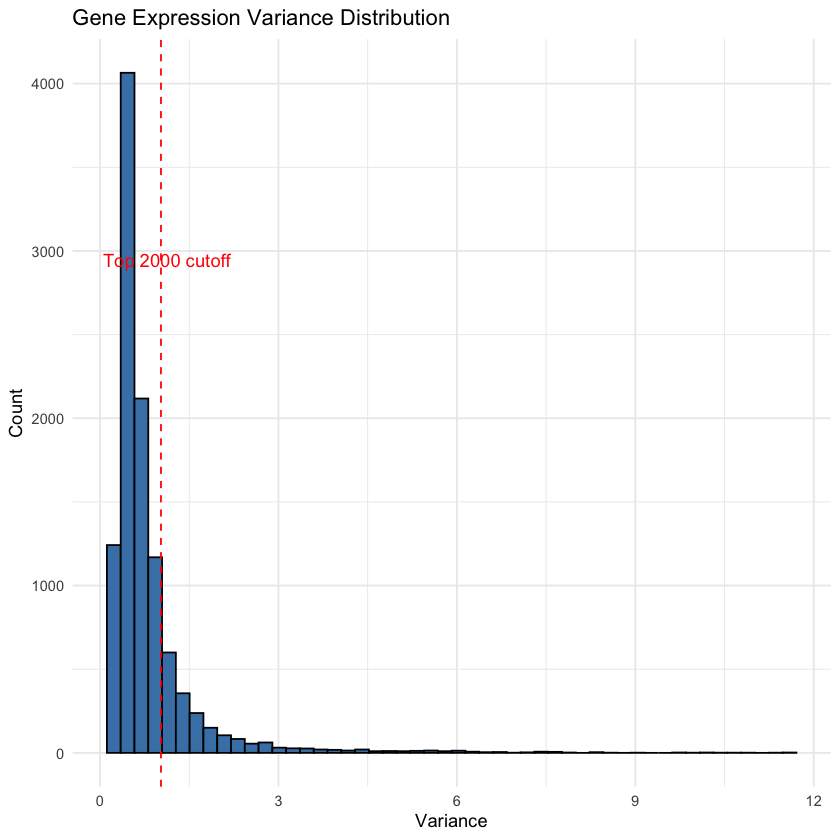

In [20]:
# 使用校正后的数据进行后续分析
expr_matrix <- corrected_expr_limma

# 计算每个基因的变异系数
gene_cv <- apply(expr_matrix, 1, function(x) sd(x) / mean(exp(x)))

# 计算基因变异度
gene_var <- apply(expr_matrix, 1, var)
top_var_genes <- names(sort(gene_var, decreasing = TRUE))[1:2000]

# 保存变异系数分布图
p5 <- ggplot(data.frame(Gene = names(gene_var), Variance = gene_var), 
            aes(x = Variance)) +
  geom_histogram(bins = 50, fill = "steelblue", color = "black") +
  geom_vline(xintercept = gene_var[top_var_genes[2000]], 
             color = "red", linetype = "dashed") +
  labs(
    title = "Gene Expression Variance Distribution",
    x = "Variance", 
    y = "Count"
  ) +
  theme_minimal() +
  annotate("text", 
           x = gene_var[top_var_genes[2000]] * 1.1, 
           y = max(hist(gene_var, breaks = 50, plot = FALSE)$counts) * 0.9, 
           label = "Top 2000 cutoff", 
           color = "red")
p5
ggsave(file.path(fig_dir, "gene_variance_distribution.pdf"), p5, width = 8, height = 6)

In [22]:
# 使用选出的高变异基因
var_expr <- expr_matrix[top_var_genes, ]

# 保存特征基因列表
write.csv(
  data.frame(
    Gene = top_var_genes,
    Variance = gene_var[top_var_genes]
  ),
  file.path(data_dir, "top_variable_genes.csv"),
  row.names = FALSE
)

#===============================================================
# 第4部分: 无监督聚类分析
#===============================================================

In [ ]:
dim(var_expr)
head(var_expr)

In [28]:
cat("Applying multiple unsupervised clustering methods...\n")

# Use selected high variance gene expression matrix
var_expr <- expr_matrix[top_var_genes, ]

# Ensure output directories exist
dir.create(file.path(fig_dir, "clustering"), showWarnings = FALSE, recursive = TRUE)

# Save multiple clustering results
clustering_results <- list()
max_k <- 6  # Maximum number of clusters

Applying multiple unsupervised clustering methods...


## Method 1: Consensus Clustering (ConsensusClusterPlus)

In [63]:
#---------------------------------------------------------------
# Method 1: Consensus Clustering (ConsensusClusterPlus) - REVISED
#---------------------------------------------------------------
cat("1. Performing consensus clustering analysis (Revised with pre-calculated distance)...\n")

# 确保加载必要的包
if (!requireNamespace("ConsensusClusterPlus", quietly = TRUE)) {
  BiocManager::install("ConsensusClusterPlus")
}
library(ConsensusClusterPlus)

# 定义PAC函数
PAC <- function(consensus_matrix, k, class_ids) {
  # 确保consensus_matrix是方阵
  if(nrow(consensus_matrix) != ncol(consensus_matrix)) {
    stop("Consensus matrix must be square")
  }
  
  n <- nrow(consensus_matrix)
  
  # 计算每个类别的样本数
  cluster_counts <- table(class_ids)
  
  # 初始化PAC分数
  pac_sum <- 0
  
  # 计算类间共识
  for(i in 1:k) {
    for(j in 1:k) {
      if(i != j) {
        # 获取每个类别的样本索引
        samples_i <- which(class_ids == i)
        samples_j <- which(class_ids == j)
        
        if(length(samples_i) > 0 && length(samples_j) > 0) {
          # 提取这两个类别之间的共识值并求和
          consensus_sum <- sum(consensus_matrix[samples_i, samples_j])
          # 归一化
          pac_sum <- pac_sum + consensus_sum / (length(samples_i) * length(samples_j))
        }
      }
    }
  }
  
  return(pac_sum)
}

# 检查输入数据维度
cat("DEBUG: Dimensions of var_expr (genes x samples):", dim(var_expr), "\n")

# 转置数据准备计算距离
consensus_data_for_dist_calc <- t(var_expr)
cat("DEBUG: Dimensions of transposed data (samples x genes):", dim(consensus_data_for_dist_calc), "\n")

# 关键修改: 计算样本间相关系数矩阵
# 正确计算586个样本之间的相关性，而不是2000个基因之间的相关性
# 使用t()确保计算的是样本间的相关性
sample_correlation_matrix <- cor(t(consensus_data_for_dist_calc), method = "pearson")
cat("DEBUG: Dimensions of correlation matrix:", dim(sample_correlation_matrix), "\n")
cat("DEBUG: Range of correlation values:", range(sample_correlation_matrix, na.rm=TRUE), "\n")

# 处理潜在的NA值
na_count <- sum(is.na(sample_correlation_matrix))
if(na_count > 0) {
  cat("WARNING: Found", na_count, "NA values in correlation matrix\n")
  sample_correlation_matrix[is.na(sample_correlation_matrix)] <- 0
}

# 转换为距离矩阵
sample_distance_matrix <- 1 - sample_correlation_matrix
sample_distance_object <- as.dist(sample_distance_matrix)
cat("DEBUG: Class of sample_distance_object:", class(sample_distance_object), "\n")
cat("DEBUG: Size of sample_distance_object:", length(sample_distance_object), "\n")
cat("DEBUG: Range of distance values:", range(sample_distance_object), "\n")

# 设置聚类参数
reps <- 100
max_k <- 6  # 如果没有定义，请设置一个合理的值

# 运行共识聚类
set.seed(123)
consensus_results <- ConsensusClusterPlus(
  sample_distance_object,
  maxK = max_k,
  reps = reps,
  pItem = 0.8,
  clusterAlg = "hc",
  seed = 123,
  plot = "png",
  title = file.path(fig_dir, "clustering/consensus_clustering_revised")
)

# 计算PAC分数来选择最优k值
pac_scores <- numeric(max_k-1)
for(k in 2:max_k) {
  m <- consensus_results[[k]]$consensusMatrix
  class_ids <- consensus_results[[k]]$consensusClass
  pac_scores[k-1] <- PAC(m, k, class_ids)
}

# 显示所有PAC分数
cat("PAC Scores for k=2 to k=", max_k, ":\n")
print(pac_scores)

# 选择最优k值（PAC分数最低的k）
optimal_k_consensus <- which.min(pac_scores) + 1
cat("Selected optimal k based on PAC score:", optimal_k_consensus, "\n")

# 获取并验证聚类结果
if (length(consensus_results) >= optimal_k_consensus && !is.null(consensus_results[[optimal_k_consensus]])) {
  consensus_clusters <- consensus_results[[optimal_k_consensus]]$consensusClass
  
  cat("VERIFIED: Length of consensusClass:", length(consensus_clusters), "\n")
  cat("VERIFIED: Sample distribution across clusters:\n")
  print(table(consensus_clusters))
  
  # 确保聚类结果有正确的样本名称
  if(is.null(names(consensus_clusters))) {
    names(consensus_clusters) <- colnames(var_expr)  # 使用原始样本名称
  }
  
  # 保存结果
  clustering_results[["ConsensusCluster"]] <- list(
    k = optimal_k_consensus,
    clusters = consensus_clusters,
    method = "ConsensusClusterPlus (dist)",
    pac_scores = pac_scores
  )
  cat("ConsensusCluster results successfully processed and stored.\n")
} else {
  cat("ERROR: Could not retrieve consensus results for optimal_k_consensus.\n")
  clustering_results[["ConsensusCluster"]] <- NULL
}

1. Performing consensus clustering analysis (Revised with pre-calculated distance)...
DEBUG: Dimensions of var_expr (genes x samples): 2000 586 
DEBUG: Dimensions of transposed data (samples x genes): 586 2000 
DEBUG: Dimensions of correlation matrix: 586 586 
DEBUG: Range of correlation values: -0.247178 1 
DEBUG: Class of sample_distance_object: dist 
DEBUG: Size of sample_distance_object: 171405 
DEBUG: Range of distance values: 0.004295763 1.247178 


end fraction

clustered

clustered

clustered

clustered

clustered



PAC Scores for k=2 to k= 6 :
[1] 0.0000000 0.8185591 0.9670123 1.2329894 1.8404953
Selected optimal k based on PAC score: 2 
VERIFIED: Length of consensusClass: 586 
VERIFIED: Sample distribution across clusters:
consensus_clusters
  1   2 
585   1 
ConsensusCluster results successfully processed and stored.


In [64]:
clustering_results[["ConsensusCluster"]]

$k
[1] 2

$clusters
      GSM2883928       GSM2883929       GSM2883930       GSM2883931 
               1                1                1                1 
      GSM2883932       GSM2883933       GSM2883934       GSM2883935 
               1                1                1                1 
      GSM2883936       GSM2883937       GSM2883938       GSM2883939 
               1                1                1                1 
      GSM2883940       GSM2883941       GSM2883942       GSM2883943 
               1                1                1                1 
      GSM2883944       GSM2883945       GSM2883946       GSM2883947 
               1                1                1                1 
      GSM2883948       GSM2883949       GSM2883950       GSM2883951 
               1                1                1                1 
      GSM2883952       GSM2883953       GSM2883954       GSM2883955 
               1                1                1                1 
      GSM2883956       GSM2883957              111              113 
               1                1                1                1 
             115              117              121              123 
               1                1                1                1 
             125              127              131              133 
               1                1                1                1 
             135              137              141              143 
               1                1                1                1 
             145              147              151              153 
               1                1                1                1 
             155              157              161              163 
               1                1                1                1 
             165              167              171              173 
               1                1                1                1 
             175              177              181              183 
               1                1                1                1 
             185              187              191              193 
               1                1                1                1 
             195              197              211              213 
               1                1                1                1 
             215              217              221              223 
               1                1                1                1 
             225              231              233              235 
               1                1                1                1 
             237              241              243              245 
               1                1                1                1 
             247              251              253              255 
               1                1                1                1 
             257              261              263              265 
               1                1                1                1 
             267              271              273              275 
               1                1                1                1 
             277              281              283              285 
               1                1                1                1 
             311              313              317              323 
               1                1                1                1 
             325              327              331              335 
               1                1                1                1 
             337              341              343              345 
               1                1                1                1 
             347              351              353              355 
               1                1                1                1 
             357              361              363              365 
               1                1              

## Method 2: Non-negative Matrix Factorization (NMF)

In [33]:
# Ensure NMF package is loaded
if (!requireNamespace("NMF", quietly = TRUE)) {
  install.packages("NMF")
}
library(NMF)

# For parallel processing
if (!requireNamespace("doParallel", quietly = TRUE)) {
  install.packages("doParallel")
}
library(doParallel)

cat("2. Performing NMF clustering analysis...\n")
cat(sprintf("Using NMF package version: %s\n", packageVersion("NMF")))

# Ensure data is non-negative
nmf_data <- var_expr
nmf_data[nmf_data < 0] <- 0
nmf_data <- nmf_data + 1e-6

# Setting NMF verbosity
nmf.options(verbose = TRUE) # Corrected to lowercase 'nmf'

# --- Setup doParallel Backend ---
num_cores_to_use <- 18
cat(sprintf("Attempting to register doParallel backend with %d cores...\n", num_cores_to_use))

# Stop any existing cluster first to be clean
if (exists("cl") && inherits(cl, "cluster") && !is.null(cl)) {
  # Check if cl is a valid cluster object before trying to stop it
  # This check might need to be more robust depending on how 'cl' could be initialized
  tryCatch({
    parallel::stopCluster(cl)
    cat("Stopped existing parallel cluster.\n")
  }, error = function(e) {
    cat("Could not stop existing cluster or no existing cluster to stop:", e$message, "\n")
  })
}
cl <- parallel::makeCluster(num_cores_to_use)
doParallel::registerDoParallel(cl)
cat(sprintf("Successfully registered doParallel backend with %d workers.\n", foreach::getDoParWorkers()))

# --- Improved Optimal k (Rank) Selection using nmfEstimateRank ---
cat("Estimating optimal NMF rank using nmfEstimateRank...\n")

set.seed(123)
# Use "P" to tell NMF to use the registered foreach backend
parallel_options_foreach <- "P"

estimate_rank_results <- NULL # Initialize
tryCatch({
  estimate_rank_results <- nmfEstimateRank(
    nmf_data,
    range = 2:max_k,
    method = "brunet",
    nrun = 20, # Number of runs for each rank
    seed = 123,
    .options = parallel_options_foreach # Use "P" for foreach
  )
}, error = function(e) {
  cat("Error during nmfEstimateRank:", e$message, "\n")
  # Fallback or further error handling if needed
}, finally = {
  # --- Stop the Parallel Backend ---
  cat("Stopping doParallel backend...\n")
  if (exists("cl") && inherits(cl, "cluster") && !is.null(cl)) {
    parallel::stopCluster(cl)
    cat("Parallel backend stopped.\n")
  }
})

Loading required package: foreach

Loading required package: iterators

Loading required package: parallel



2. Performing NMF clustering analysis...
Using NMF package version: 0.28
Attempting to register doParallel backend with 18 cores...
Successfully registered doParallel backend with 18 workers.
Estimating optimal NMF rank using nmfEstimateRank...


NMF algorithm: 'brunet'

Multiple runs: 20

Mode: parallel (2/20 core(s))



Runs: |==================================================| 100%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |=======                                           |  14%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |==========                                        |  19%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |============                                      |  24%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |==============                                    |  29%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |=================                                 |  33%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |===================                               |  38%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |=====================                             |  43%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |======================== 

NMF algorithm: 'brunet'

Multiple runs: 20

Mode: parallel (2/20 core(s))

NMF algorithm: 'brunet'

Multiple runs: 20

Mode: parallel (2/20 core(s))

NMF algorithm: 'brunet'

Multiple runs: 20

Mode: parallel (2/20 core(s))

NMF algorithm: 'brunet'

Multiple runs: 20

Mode: parallel (2/20 core(s))



ERROR: Error in if (!is.na(user_chosen_k) && user_chosen_k != optimal_k_nmf) {: missing value where TRUE/FALSE needed


In [35]:
if (!is.null(estimate_rank_results)) {
  plot(estimate_rank_results)
  ggsave(file.path(fig_dir, "clustering/nmf_rank_estimation_plots.png"), width = 10, height = 8) # ggsave might not work directly on base plot

  # Save base R plot to PNG
  png(file.path(fig_dir, "clustering/nmf_rank_estimation_plots.png"), width = 800, height = 600)
  plot(estimate_rank_results)
  dev.off()

  summary_stats <- summary(estimate_rank_results)
  optimal_k_nmf <- as.integer(summary_stats$measures[which.max(summary_stats$measures$cophenetic), "rank"])
  cat(sprintf("Programmatically selected NMF k: %d\n", optimal_k_nmf)) # See what it picked
  
  # --- UNCOMMENT AND USE THIS FALLBACK LOGIC ---
  if (length(optimal_k_nmf) == 0 || is.na(optimal_k_nmf) || optimal_k_nmf < 2) {
      cat("Cophenetic-based optimal k selection failed or gave invalid rank. Examining other metrics or using fallback.\n")
      # Attempt to use silhouette if available and calculated by nmfEstimateRank
      if ("silhouette.avg" %in% colnames(summary_stats$measures)) {
          valid_sil_ranks <- summary_stats$measures[!is.na(summary_stats$measures$silhouette.avg), ]
          if (nrow(valid_sil_ranks) > 0) {
              optimal_k_nmf <- as.integer(valid_sil_ranks[which.max(valid_sil_ranks$silhouette.avg), "rank"])
              cat(sprintf("Using fallback optimal k based on max silhouette: %d\n", optimal_k_nmf))
          } else {
              optimal_k_nmf <- 3 # Fallback if silhouette also fails
              cat("Silhouette-based fallback also failed. Using absolute fallback optimal k: 3\n")
          }
      } else { # Fallback to RSS if silhouette not available
          non_na_ranks_rss <- summary_stats$measures[!is.na(summary_stats$measures$rss), "rank"]
          if(length(non_na_ranks_rss) > 0) {
              # A more robust RSS elbow detection would be better than min(non_na_ranks_rss)
              # For now, as a simple fallback, let's stick to a default or a simple choice
              # Or you could try to find an elbow in RSS here if you have a function for it.
              # Defaulting to a common choice like 3 or the smallest k if other heuristics fail.
              optimal_k_nmf <- 3 # Or non_na_ranks_rss[1] which is k=2 if available
              cat(sprintf("Using fallback optimal k (e.g., preset or min valid rank from RSS): %d\n", optimal_k_nmf))
          } else {
              optimal_k_nmf <- 3 # Absolute fallback
              cat("All primary and secondary fallbacks failed. Using absolute fallback optimal k: 3\n")
          }
      }
      # Ensure k is at least 2 if it somehow became less after fallbacks
      if (is.na(optimal_k_nmf) || optimal_k_nmf < 2) optimal_k_nmf <- 2 
  }
  # This line should reflect the k after fallback logic
  cat(sprintf("Optimal NMF k after programmatic selection and fallbacks: %d\n", optimal_k_nmf))
  
  # --- USER DECISION POINT / MANUAL OVERRIDE ---
  # After inspecting nmf_rank_estimation_plots.png, if you decide k=3 is best:
  user_chosen_k <- 3
  if (!is.na(user_chosen_k) && user_chosen_k != optimal_k_nmf) {
    cat(sprintf("NOTE: Overriding programmatically selected k=%d with user-chosen k=%d based on plot inspection.\n", optimal_k_nmf, user_chosen_k))
    optimal_k_nmf <- user_chosen_k
  }
  cat(sprintf("Final Optimal NMF k to be used for NMF run: %d\n", optimal_k_nmf))
  
  # --- Run final NMF with optimal k and higher nrun ---
  # Re-register backend if it was stopped or run sequentially if preferred for single final run
  cl_final <- parallel::makeCluster(num_cores_to_use) # Or fewer if desired for single run
  doParallel::registerDoParallel(cl_final)
  cat(sprintf("Re-registered parallel backend for final NMF run with %d workers.\n", foreach::getDoParWorkers()))
  
  nmf_result_final <- NULL
  tryCatch({
      cat(sprintf("Running final NMF with optimal k=%d and higher nrun...\n", optimal_k_nmf))
      set.seed(123)
      nmf_result_final <- nmf(
        nmf_data,
        rank = optimal_k_nmf,
        method = "brunet",
        nrun = 50,
        seed = 123,
        .options = parallel_options_foreach # Use "P"
      )
      nmf_clusters <- predict(nmf_result_final)
      nmf_clusters <- as.numeric(nmf_clusters)
      names(nmf_clusters) <- colnames(nmf_data)

      clustering_results[["NMF"]] <- list(
        k = optimal_k_nmf,
        clusters = nmf_clusters,
        method = "NMF"
      )
      # ... rest of your heatmap and saving code using nmf_result_final ...
       cat("Generating NMF heatmaps...\n")
        try({
          # For basis matrix (genes x components)
          pdf(file.path(fig_dir, "clustering/nmf_basis_heatmap.pdf"), width = 12, height = 10)
          basis_mat <- basis(nmf_result_final)
          n_top_genes_display <- min(30, nrow(basis_mat) %/% optimal_k_nmf) 
          top_genes_display <- c()
          for (i in 1:ncol(basis_mat)) {
            component_contrib <- basis_mat[, i]
            top_idx <- order(component_contrib, decreasing = TRUE)[1:n_top_genes_display]
            top_genes_display <- c(top_genes_display, rownames(basis_mat)[top_idx])
          }
          top_genes_display <- unique(top_genes_display)
          if (length(top_genes_display) > ncol(basis_mat) * 2) { 
              heatmap(basis_mat[top_genes_display, ], main = paste("NMF Basis Matrix (k =", optimal_k_nmf, ")"),
                     scale = "row", col = colorRampPalette(c("blue", "white", "red"))(100),
                     Colv = TRUE, Rowv = TRUE, cexRow = max(0.2, 1 - length(top_genes_display)/200) )
          } else {
              cat("Too few unique top genes for a meaningful basis heatmap, skipping.\n")
          }
          dev.off()

          # For coefficient matrix (components x samples -> samples x components for heatmap)
          pdf(file.path(fig_dir, "clustering/nmf_coef_heatmap.pdf"), width = 10, height = 8)
          coef_mat <- coef(nmf_result_final) 
          sample_order <- order(nmf_clusters) 
          heatmap(t(coef_mat)[sample_order, ],
                 main = paste("NMF Coefficient Matrix (k =", optimal_k_nmf, ")"),
                 xlab = "NMF Components (k)", ylab = "Samples (ordered by cluster)",
                 scale = "column", 
                 col = colorRampPalette(c("blue", "white", "red"))(100),
                 Rowv = FALSE, 
                 Colv = TRUE) 
          dev.off()
        }, error = function(e_heatmap) {
            cat(sprintf("Error generating NMF heatmaps: %s\n", e_heatmap$message))
        })

  }, error = function(e_final_nmf) {
    cat("Error during final NMF run:", e_final_nmf$message, "\n")
  }, finally = {
    cat("Stopping parallel backend for final NMF run...\n")
    if (exists("cl_final") && inherits(cl_final, "cluster") && !is.null(cl_final)) {
      parallel::stopCluster(cl_final)
      cat("Parallel backend for final NMF run stopped.\n")
    }
  })

} else {
  cat("nmfEstimateRank failed, skipping subsequent NMF steps.\n")
}

nmf.options(verbose = FALSE) # Reset NMF verbosity

Cophenetic-based optimal k selection failed or gave invalid rank. Examining other metrics or using fallback.
All primary and secondary fallbacks failed. Using absolute fallback optimal k: 3
Optimal NMF k after programmatic selection and fallbacks: 3
Final Optimal NMF k to be used for NMF run: 3
Re-registered parallel backend for final NMF run with 18 workers.
Running final NMF with optimal k=3 and higher nrun...


NMF algorithm: 'brunet'

Multiple runs: 50

Mode: parallel (2/20 core(s))



Runs: |==================================================| 100%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |===                                               |   6%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |====                                              |   8%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |=====                                             |  10%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |======                                            |  12%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |=======                                           |  14%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |========                                          |  16%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |=========                                         |  18%R_zmq_msg_send errno: 4 strerror: Interrupted system call
Runs: |==========               

In [21]:
#---------------------------------------------------------------
# Skip NMF and proceed with other clustering methods
#---------------------------------------------------------------
#cat("Skipping NMF clustering due to computational time constraints...\n")

# Add a placeholder in the clustering results if needed for later code
#clustering_results[["NMF"]] <- list(
#  k = NA,
#  clusters = NULL,
#  method = "NMF (skipped)"
#)

Skipping NMF clustering due to computational time constraints...


In [36]:
clustering_results[["NMF"]]

$k
[1] 3

$clusters
      GSM2883928       GSM2883929       GSM2883930       GSM2883931 
               2                1                3                3 
      GSM2883932       GSM2883933       GSM2883934       GSM2883935 
               3                3                1                1 
      GSM2883936       GSM2883937       GSM2883938       GSM2883939 
               3                2                3                2 
      GSM2883940       GSM2883941       GSM2883942       GSM2883943 
               2                1                2                3 
      GSM2883944       GSM2883945       GSM2883946       GSM2883947 
               1                3                3                2 
      GSM2883948       GSM2883949       GSM2883950       GSM2883951 
               2                3                2                3 
      GSM2883952       GSM2883953       GSM2883954       GSM2883955 
               2                3                2                2 
      GSM2883956       GSM2883957              111              113 
               3                3                3                2 
             115              117              121              123 
               1                1                2                1 
             125              127              131              133 
               3                3                3                3 
             135              137              141              143 
               2                2                3                2 
             145              147              151              153 
               2                3                3                2 
             155              157              161              163 
               1                3                2                1 
             165              167              171              173 
               2                3                2                1 
             175              177              181              183 
               1                2                3                2 
             185              187              191              193 
               2                2                2                2 
             195              197              211              213 
               3                2                1                2 
             215              217              221              223 
               2                3                1                1 
             225              231              233              235 
               3                2                1                3 
             237              241              243              245 
               2                1                3                2 
             247              251              253              255 
               2                1                2                1 
             257              261              263              265 
               2                3                2                2 
             267              271              273              275 
               2                1                2                3 
             277              281              283              285 
               2                3                3                2 
             311              313              317              323 
               1                2                2                2 
             325              327              331              335 
               3                1                1                2 
             337              341              343              345 
               3                3                3                2 
             347              351              353              355 
               1                3                2                2 
             357              361              363              365 
               3                2              

## Method 3: K-Means Clustering

In [37]:
cat("3. Performing K-means clustering analysis...\n")

# Calculate optimal number of clusters
kmeans_wss <- numeric(max_k)
for (k in 1:max_k) {
  kmeans_wss[k] <- sum(kmeans(t(var_expr), centers = k, nstart = 25)$withinss)
}

# Calculate elbow point
wss_diff <- diff(kmeans_wss)
wss_diff_norm <- abs(wss_diff) / abs(wss_diff[1])  # Normalize
optimal_k_kmeans <- which.max(wss_diff_norm) + 1

# If elbow not obvious, use silhouette coefficient
if (max(wss_diff_norm) < 0.3 || optimal_k_kmeans == 2) {
  silhouette_scores <- numeric(max_k - 1)
  for (k in 2:max_k) {
    km <- kmeans(t(var_expr), centers = k, nstart = 25)
    ss <- silhouette(km$cluster, dist(t(var_expr)))
    silhouette_scores[k-1] <- mean(ss[, "sil_width"])
  }
  
  # Take k with maximum silhouette coefficient
  optimal_k_kmeans <- which.max(silhouette_scores) + 1
  
  # Plot silhouette coefficients
  p_kmeans_sil <- ggplot(data.frame(k = 2:max_k, Silhouette = silhouette_scores), 
                        aes(x = k, y = Silhouette)) +
    geom_line(color = "blue", size = 1) +
    geom_point(color = "red", size = 3) +
    labs(title = "K-means Silhouette Score by Cluster Number", 
         x = "Number of Clusters (k)", 
         y = "Average Silhouette Width") +
    theme_minimal() +
    scale_x_continuous(breaks = 2:max_k)
  
  ggsave(file.path(fig_dir, "clustering/kmeans_silhouette.png"), p_kmeans_sil, width = 8, height = 6)
}

# Plot elbow method graph
p_kmeans_wss <- ggplot(data.frame(k = 1:max_k, WSS = kmeans_wss), aes(x = k, y = WSS)) +
  geom_line(color = "blue", size = 1) +
  geom_point(color = "red", size = 3) +
  geom_vline(xintercept = optimal_k_kmeans, linetype = "dashed") +
  labs(title = "K-means Elbow Method", 
       x = "Number of Clusters (k)", 
       y = "Within Sum of Squares") +
  theme_minimal() +
  scale_x_continuous(breaks = 1:max_k)

ggsave(file.path(fig_dir, "clustering/kmeans_elbow.png"), p_kmeans_wss, width = 8, height = 6)

# Run K-means with optimal k
set.seed(123)
kmeans_result <- kmeans(t(var_expr), centers = optimal_k_kmeans, nstart = 25)

# Extract cluster labels
kmeans_clusters <- kmeans_result$cluster
names(kmeans_clusters) <- colnames(var_expr)

# Save results
clustering_results[["KMeans"]] <- list(
  k = optimal_k_kmeans,
  clusters = kmeans_clusters,
  method = "K-means"
)

cat(sprintf("Optimal K-means k: %d\n", optimal_k_kmeans))

3. Performing K-means clustering analysis...
Optimal K-means k: 3


## Method 4: Hierarchical Clustering

In [38]:
cat("4. Performing hierarchical clustering analysis...\n")

# Calculate distance matrix
hc_dist <- dist(t(var_expr), method = "euclidean")

# Apply different clustering methods
hc_methods <- c("ward.D2", "complete", "average")
hc_results <- list()

for (method in hc_methods) {
  # Perform hierarchical clustering
  hc <- hclust(hc_dist, method = method)
  
  # Calculate clustering quality for different k values
  sil_scores <- numeric(max_k - 1)
  for (k in 2:max_k) {
    clusters <- cutree(hc, k = k)
    sil <- silhouette(clusters, hc_dist)
    sil_scores[k-1] <- mean(sil[, "sil_width"])
  }
  
  # Save results
  hc_results[[method]] <- list(
    hc = hc,
    silhouette = sil_scores
  )
  
  # Plot silhouette coefficients
  p_hc_sil <- ggplot(data.frame(k = 2:max_k, Silhouette = sil_scores), 
                    aes(x = k, y = Silhouette)) +
    geom_line(color = "blue", size = 1) +
    geom_point(color = "red", size = 3) +
    labs(title = paste("Hierarchical Clustering (", method, ") Silhouette Score"), 
         x = "Number of Clusters (k)", 
         y = "Average Silhouette Width") +
    theme_minimal() +
    scale_x_continuous(breaks = 2:max_k)
  
  ggsave(file.path(fig_dir, paste0("clustering/hc_", method, "_silhouette.png")), 
        p_hc_sil, width = 8, height = 6)
}

# Select best method and k value
best_method <- NULL
best_k_hc <- 0
best_sil <- -1

for (method in hc_methods) {
  max_sil <- max(hc_results[[method]]$silhouette, na.rm = TRUE)
  max_k <- which.max(hc_results[[method]]$silhouette) + 1
  
  if (max_sil > best_sil) {
    best_sil <- max_sil
    best_method <- method
    best_k_hc <- max_k
  }
}

cat(sprintf("Best hierarchical clustering method: %s, optimal k: %d\n", best_method, best_k_hc))

# Get clustering results with the best method and k value
hc_clusters <- cutree(hc_results[[best_method]]$hc, k = best_k_hc)
names(hc_clusters) <- colnames(var_expr)

# Save results
clustering_results[["HC"]] <- list(
  k = best_k_hc,
  clusters = hc_clusters,
  method = paste("Hierarchical (", best_method, ")", sep = "")
)

# Plot hierarchical clustering dendrogram
pdf(file.path(fig_dir, "clustering/hc_dendrogram.pdf"), width = 12, height = 8)
plot(hc_results[[best_method]]$hc, main = paste("Hierarchical Clustering Dendrogram (", best_method, ")", sep = ""))
rect.hclust(hc_results[[best_method]]$hc, k = best_k_hc, border = "red")
dev.off()

4. Performing hierarchical clustering analysis...
Best hierarchical clustering method: complete, optimal k: 2


pdf 
  2

In [65]:
names(clustering_results)

[1] "ConsensusCluster" "NMF"              "KMeans"           "HC"              
[5] "Ensemble"

In [66]:
#---------------------------------------------------------------
# Compare and integrate different clustering results
#---------------------------------------------------------------
cat("6. Comparing and integrating different clustering results...\n")

# Create data frame for comparison
comparison_data <- data.frame(
  Sample = colnames(var_expr)
)

# Add clustering results from each method
for (method_name in names(clustering_results)) {
  # Skip methods that didn't produce results (like skipped NMF)
  if (is.null(clustering_results[[method_name]]$clusters)) {
    cat(sprintf("Skipping %s as it has no clustering results\n", method_name))
    next
  }
  
  clusters <- clustering_results[[method_name]]$clusters
  # Initialize column with NAs
  comparison_data[[method_name]] <- NA
  
  # Only assign values to existing samples (avoid NA in names)
  valid_samples <- intersect(names(clusters), comparison_data$Sample)
  valid_idx <- match(valid_samples, comparison_data$Sample)
  comparison_data[valid_idx, method_name] <- clusters[valid_samples]
  
  cat(sprintf("Added clusters from %s: %d samples matched\n", 
              method_name, length(valid_samples)))
}

# Remove methods with no results from clustering_results
methods_to_keep <- names(clustering_results)[sapply(clustering_results, function(x) !is.null(x$clusters))]
if (length(methods_to_keep) < length(clustering_results)) {
  cat("Removing methods with no clustering results from comparison\n")
  clustering_results <- clustering_results[methods_to_keep]
}

# Check if we have at least 2 methods to compare
if (length(methods_to_keep) < 2) {
  cat("Not enough clustering methods with results for comparison.\n")
} else {
  # Calculate consistency between methods (adjusted Rand index)
  library(fossil)
  rand_indices <- matrix(NA, nrow = length(methods_to_keep), ncol = length(methods_to_keep))
  rownames(rand_indices) <- methods_to_keep
  colnames(rand_indices) <- methods_to_keep
  
  for (i in 1:length(methods_to_keep)) {
    method_i <- methods_to_keep[i]
    for (j in i:length(methods_to_keep)) {
      method_j <- methods_to_keep[j]
      
      # Get clustering results from both methods
      clusters_i <- clustering_results[[method_i]]$clusters
      clusters_j <- clustering_results[[method_j]]$clusters
      
      # Find samples with results from both methods
      common_samples <- intersect(names(clusters_i), names(clusters_j))
      
      if (length(common_samples) > 0) {
        # Calculate adjusted Rand index
        clusters_i_common <- as.integer(clusters_i[common_samples])
        clusters_j_common <- as.integer(clusters_j[common_samples])
        
        # Make sure clusters are integers, not factors
        tryCatch({
          ari <- adj.rand.index(clusters_i_common, clusters_j_common)
          rand_indices[i, j] <- ari
          rand_indices[j, i] <- ari
          cat(sprintf("ARI between %s and %s: %.3f (based on %d common samples)\n", 
                     method_i, method_j, ari, length(common_samples)))
        }, error = function(e) {
          cat(sprintf("Error calculating ARI between %s and %s: %s\n", 
                     method_i, method_j, e$message))
        })
      } else {
        cat(sprintf("No common samples between %s and %s\n", method_i, method_j))
      }
    }
  }
  
  # Plot heatmap if corrplot is available
  if (requireNamespace("corrplot", quietly = TRUE)) {
    tryCatch({
      pdf(file.path(fig_dir, "clustering/clustering_comparison_heatmap.pdf"), width = 10, height = 8)
      corrplot::corrplot(rand_indices, method = "color", type = "upper", 
              title = "Adjusted Rand Index Between Clustering Methods",
              mar = c(0, 0, 2, 0), 
              diag = FALSE, 
              col = colorRampPalette(c("white", "red"))(200))
      dev.off()
      
      # Also save as PNG for easier viewing
      png(file.path(fig_dir, "clustering/clustering_comparison_heatmap.png"), width = 10, height = 8, units = "in", res = 300)
      corrplot::corrplot(rand_indices, method = "color", type = "upper", 
              title = "Adjusted Rand Index Between Clustering Methods",
              mar = c(0, 0, 2, 0), 
              diag = FALSE, 
              col = colorRampPalette(c("white", "red"))(200))
      dev.off()
    }, error = function(e) {
      cat(sprintf("Error creating heatmap: %s\n", e$message))
    })
  } else {
    cat("Package 'corrplot' not available. Skipping heatmap visualization.\n")
  }
}

# Save the comparison data
write.csv(comparison_data, file.path(data_dir, "clustering_comparison.csv"), row.names = FALSE)

6. Comparing and integrating different clustering results...
Added clusters from ConsensusCluster: 586 samples matched
Added clusters from NMF: 586 samples matched
Added clusters from KMeans: 586 samples matched
Added clusters from HC: 586 samples matched
Added clusters from Ensemble: 586 samples matched
ARI between ConsensusCluster and ConsensusCluster: 1.000 (based on 586 common samples)
ARI between ConsensusCluster and NMF: 0.617 (based on 586 common samples)
ARI between ConsensusCluster and KMeans: 0.536 (based on 586 common samples)
ARI between ConsensusCluster and HC: 1.000 (based on 586 common samples)
ARI between ConsensusCluster and Ensemble: 0.001 (based on 586 common samples)
ARI between NMF and NMF: 1.000 (based on 586 common samples)
ARI between NMF and KMeans: 0.619 (based on 586 common samples)
ARI between NMF and HC: 0.000 (based on 586 common samples)
ARI between NMF and Ensemble: 0.444 (based on 586 common samples)
ARI between KMeans and KMeans: 1.000 (based on 586 co

pdf 
  2

In [67]:
save(comparison_data, clustering_results,file = paste0(data_dir, "clustering_results.RData"))

In [68]:
# Integrate clustering results - using consensus clustering
# Create ensemble voting matrix
n_samples <- nrow(comparison_data)
vote_matrix <- matrix(0, nrow = n_samples, ncol = n_samples)
rownames(vote_matrix) <- comparison_data$Sample
colnames(vote_matrix) <- comparison_data$Sample

# For each clustering method
for (method_name in names(clustering_results)) {
  clusters <- clustering_results[[method_name]]$clusters
  
  # Extract cluster labels for current method
  current_cluster_labels <- comparison_data[[method_name]]
  
  # Add votes for each pair of samples
  for (i in 1:(n_samples-1)) {
    for (j in (i+1):n_samples) {
      sample_i <- comparison_data$Sample[i]
      sample_j <- comparison_data$Sample[j]
      
      # If both samples have cluster labels
      if (!is.na(current_cluster_labels[i]) && !is.na(current_cluster_labels[j])) {
        # If assigned to same cluster, add vote
        if (current_cluster_labels[i] == current_cluster_labels[j]) {
          vote_matrix[i, j] <- vote_matrix[i, j] + 1
          vote_matrix[j, i] <- vote_matrix[j, i] + 1
        }
      }
    }
  }
}

# Normalize voting matrix
vote_matrix <- vote_matrix / length(clustering_results)

# Use hierarchical clustering to find ensemble clustering result
ensemble_dist <- 1 - vote_matrix
ensemble_dist <- as.dist(ensemble_dist)
ensemble_hc <- hclust(ensemble_dist, method = "ward.D2")

# Calculate clustering quality for different k values
ensemble_sil_scores <- numeric(max_k - 1)
for (k in 2:max_k) {
  ensemble_clusters <- cutree(ensemble_hc, k = k)
  sil <- silhouette(ensemble_clusters, ensemble_dist)
  ensemble_sil_scores[k-1] <- mean(sil[, "sil_width"])
}

# Plot silhouette scores
p_ensemble_sil <- ggplot(data.frame(k = 2:max_k, Silhouette = ensemble_sil_scores), 
                        aes(x = k, y = Silhouette)) +
  geom_line(color = "blue", size = 1) +
  geom_point(color = "red", size = 3) +
  labs(title = "Ensemble Clustering Silhouette Score", 
       x = "Number of Clusters (k)", 
       y = "Average Silhouette Width") +
  theme_minimal() +
  scale_x_continuous(breaks = 2:max_k)

ggsave(file.path(fig_dir, "clustering/ensemble_silhouette.png"), p_ensemble_sil, width = 8, height = 6)

# Select optimal k value
optimal_k_ensemble <- which.max(ensemble_sil_scores) + 1
cat(sprintf("Optimal ensemble clustering k: %d\n", optimal_k_ensemble))

# Get ensemble clustering results
ensemble_clusters <- cutree(ensemble_hc, k = optimal_k_ensemble)
names(ensemble_clusters) <- rownames(vote_matrix)

# Save results
clustering_results[["Ensemble"]] <- list(
  k = optimal_k_ensemble,
  clusters = ensemble_clusters,
  method = "Ensemble"
)

# Plot clustering dendrogram
pdf(file.path(fig_dir, "clustering/ensemble_dendrogram.pdf"), width = 12, height = 8)
plot(ensemble_hc, main = "Ensemble Clustering Dendrogram")
rect.hclust(ensemble_hc, k = optimal_k_ensemble, border = "red")
dev.off()

# Visualize ensemble clustering results heatmap
ensemble_heatmap_data <- vote_matrix
ensemble_annotation <- data.frame(
  Cluster = factor(ensemble_clusters)
)
rownames(ensemble_annotation) <- names(ensemble_clusters)

Optimal ensemble clustering k: 6


pdf 
  2

In [69]:
# Update global clustering result to ensemble result
final_clusters <- ensemble_clusters

In [70]:
#---------------------------------------------------------------
# Integrate and save all clustering results
#---------------------------------------------------------------
cat("7. Integrating and saving all clustering results...\n")

# Create data frame with results from all clustering methods
all_clustering_results <- data.frame(
  Sample = colnames(var_expr)
)

# Add results from each method
for (method_name in names(clustering_results)) {
  # Skip methods with no clusters
  if (is.null(clustering_results[[method_name]]$clusters)) {
    cat(sprintf("Skipping %s - no clustering results available\n", method_name))
    next
  }
  
  # Get clusters for this method
  clusters <- clustering_results[[method_name]]$clusters
  
  # Initialize column with NA
  all_clustering_results[[method_name]] <- NA
  
  # Find samples that exist in both the results and our data frame
  valid_samples <- intersect(names(clusters), all_clustering_results$Sample)
  
  if (length(valid_samples) > 0) {
    # Create a safer matching approach that avoids NA indices
    for (sample_name in valid_samples) {
      row_idx <- which(all_clustering_results$Sample == sample_name)
      if (length(row_idx) == 1) {
        all_clustering_results[row_idx, method_name] <- clusters[sample_name]
      }
    }
    cat(sprintf("Added clusters from %s: %d samples matched\n", 
                method_name, length(valid_samples)))
  } else {
    cat(sprintf("Warning: No matching samples found for %s\n", method_name))
  }
}

# Save all clustering results
write.csv(all_clustering_results, file.path(data_dir, "all_clustering_results.csv"), row.names = FALSE)

# Save detailed information for each clustering method
clustering_summary <- data.frame(
  Method = character(),
  OptimalK = integer(),
  Description = character(),
  NumSamples = integer(),
  stringsAsFactors = FALSE
)

for (method_name in names(clustering_results)) {
  if (!is.null(clustering_results[[method_name]]$clusters)) {
    num_samples <- length(clustering_results[[method_name]]$clusters)
    clustering_summary <- rbind(clustering_summary, data.frame(
      Method = method_name,
      OptimalK = ifelse(is.null(clustering_results[[method_name]]$k), 
                        NA, clustering_results[[method_name]]$k),
      Description = ifelse(is.null(clustering_results[[method_name]]$method), 
                           method_name, clustering_results[[method_name]]$method),
      NumSamples = num_samples,
      stringsAsFactors = FALSE
    ))
  } else {
    # Add a row with NA values for methods without clusters
    clustering_summary <- rbind(clustering_summary, data.frame(
      Method = method_name,
      OptimalK = NA,
      Description = ifelse(is.null(clustering_results[[method_name]]$method), 
                           paste0(method_name, " (no results)"), 
                           paste0(clustering_results[[method_name]]$method, " (no results)")),
      NumSamples = 0,
      stringsAsFactors = FALSE
    ))
  }
}

# Print summary
cat("\nClustering methods summary:\n")
print(clustering_summary)

# Save summary
write.csv(clustering_summary, file.path(data_dir, "clustering_methods_summary.csv"), row.names = FALSE)

# Optional: Visualize cluster counts distribution for each method
if (nrow(clustering_summary) > 0 && requireNamespace("ggplot2", quietly = TRUE)) {
  # Prepare data for plotting cluster size distributions
  cluster_counts_data <- data.frame(
    Method = character(),
    Cluster = integer(),
    Count = integer(),
    stringsAsFactors = FALSE
  )
  
  for (method_name in names(clustering_results)) {
    if (!is.null(clustering_results[[method_name]]$clusters)) {
      clusters <- clustering_results[[method_name]]$clusters
      counts <- table(clusters)
      method_counts <- data.frame(
        Method = rep(method_name, length(counts)),
        Cluster = as.integer(names(counts)),
        Count = as.integer(counts),
        stringsAsFactors = FALSE
      )
      cluster_counts_data <- rbind(cluster_counts_data, method_counts)
    }
  }
  
  if (nrow(cluster_counts_data) > 0) {
    # Create barplot of cluster sizes
    p_cluster_sizes <- ggplot(cluster_counts_data, 
                             aes(x = factor(Cluster), y = Count, fill = Method)) +
      geom_bar(stat = "identity", position = position_dodge()) +
      labs(title = "Sample counts by cluster for each method",
           x = "Cluster", y = "Number of samples") +
      theme_minimal() +
      theme(axis.text.x = element_text(angle = 0))
    
    # Save plot
    ggsave(file.path(fig_dir, "cluster_size_distribution.png"), p_cluster_sizes, 
           width = max(8, length(unique(cluster_counts_data$Method)) * 2), height = 6)
  }
}

cat("Clustering results integration completed and saved\n")

7. Integrating and saving all clustering results...


Added clusters from ConsensusCluster: 586 samples matched
Added clusters from NMF: 586 samples matched
Added clusters from KMeans: 586 samples matched
Added clusters from HC: 586 samples matched
Added clusters from Ensemble: 586 samples matched

Clustering methods summary:
            Method OptimalK                 Description NumSamples
1 ConsensusCluster        2 ConsensusClusterPlus (dist)        586
2              NMF        3                         NMF        586
3           KMeans        3                     K-means        586
4               HC        2     Hierarchical (complete)        586
5         Ensemble        6                    Ensemble        586
Clustering results integration completed and saved


8. Creating UMAP visualization...


Created UMAP plot for ConsensusCluster clustering
Created UMAP plot for NMF clustering
Created UMAP plot for KMeans clustering
Created UMAP plot for HC clustering
Created UMAP plot for Ensemble clustering
Created multi-panel UMAP comparison of all methods

===== Clustering Results Summary =====
Total clustering methods analyzed: 5 
ConsensusCluster: Optimal clusters k=2
NMF: Optimal clusters k=3
KMeans: Optimal clusters k=3
HC: Optimal clusters k=2
Ensemble: Optimal clusters k=6

Final ensemble clustering result: k = 6 
Sample distribution across clusters: 223, 112, 39, 162, 41, 9 
Visualization step completed


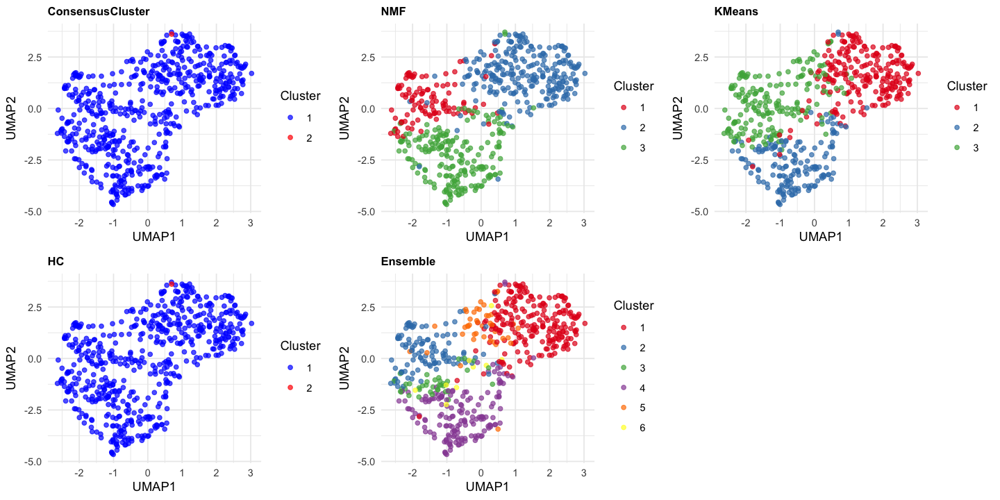

In [ ]:
#---------------------------------------------------------------
# Create UMAP visualization of clustering results
#---------------------------------------------------------------
cat("8. Creating UMAP visualization...\n")
options(repr.plot.width = 12, repr.plot.height = 6)

# Ensure required packages are available
required_viz_packages <- c("umap", "ggplot2", "RColorBrewer")
missing_packages <- required_viz_packages[!sapply(required_viz_packages, requireNamespace, quietly = TRUE)]

if (length(missing_packages) > 0) {
  cat("Warning: The following packages are required for visualization but not available:", 
      paste(missing_packages, collapse = ", "), "\n")
  cat("Installing missing packages...\n")
  for (pkg in missing_packages) {
    if (pkg == "umap") {
      install.packages("umap")
    } else {
      install.packages(pkg)
    }
  }
}

# Check if gridExtra is available for multi-panel plots
has_gridExtra <- requireNamespace("gridExtra", quietly = TRUE)
if (!has_gridExtra) {
  cat("Note: Package 'gridExtra' is not available. Will create individual plots only.\n")
  cat("To enable multi-panel plots, please install: install.packages('gridExtra')\n")
  # Try to install gridExtra
  tryCatch({
    install.packages("gridExtra")
    has_gridExtra <- requireNamespace("gridExtra", quietly = TRUE)
  }, error = function(e) {
    cat("Could not install gridExtra:", e$message, "\n")
  })
}

# Create directory for UMAP plots
dir.create(file.path(fig_dir, "clustering"), showWarnings = FALSE, recursive = TRUE)

# Calculate UMAP
tryCatch({
  library(umap)
  umap_result <- umap(t(var_expr))
  umap_data <- as.data.frame(umap_result$layout)
  colnames(umap_data) <- c("UMAP1", "UMAP2")
  umap_data$Sample <- rownames(umap_data)
  
  # Merge all clustering results
  umap_with_clusters <- merge(umap_data, all_clustering_results, by = "Sample")
  
  # Create separate UMAP plot for each method
  for (method_name in names(clustering_results)) {
    # Skip methods with no results or missing k value
    if (is.null(clustering_results[[method_name]]$clusters) ||
        is.null(clustering_results[[method_name]]$k) ||
        is.na(clustering_results[[method_name]]$k)) {
      cat(sprintf("Skipping UMAP for %s - insufficient data\n", method_name))
      next
    }
    
    # Create UMAP data for current method
    if (!method_name %in% colnames(umap_with_clusters)) {
      cat(sprintf("Warning: Method %s not found in clustering results\n", method_name))
      next
    }
    
    current_data <- umap_with_clusters[, c("Sample", "UMAP1", "UMAP2", method_name)]
    # Remove rows with NA in cluster column
    current_data <- current_data[!is.na(current_data[[method_name]]), ]
    if (nrow(current_data) == 0) {
      cat(sprintf("Warning: No valid clustering data for %s\n", method_name))
      next
    }
    
    colnames(current_data)[4] <- "Cluster"
    current_data$Cluster <- factor(current_data$Cluster)
    
    # Generate colors
    cluster_count <- length(unique(current_data$Cluster))
    if (cluster_count < 3) {
      cluster_colors <- c("blue", "red")
    } else if (cluster_count <= 9) {
      cluster_colors <- RColorBrewer::brewer.pal(max(3, cluster_count), "Set1")[1:cluster_count]
    } else {
      cluster_colors <- colorRampPalette(RColorBrewer::brewer.pal(9, "Set1"))(cluster_count)
    }
    
    # Create UMAP plot
    p_umap <- ggplot2::ggplot(current_data, ggplot2::aes(x = UMAP1, y = UMAP2, color = Cluster)) +
      ggplot2::geom_point(size = 2.5, alpha = 0.7) +
      ggplot2::labs(title = paste("UMAP -", method_name, "Clustering"),
           color = "Cluster") +
      ggplot2::theme_minimal() +
      ggplot2::scale_color_manual(values = cluster_colors) +
      ggplot2::theme(legend.position = "right")
    
    # Save plot
    ggplot2::ggsave(file.path(fig_dir, paste0("clustering/umap_", method_name, ".png")), 
           p_umap, width = 10, height = 8)
    
    cat(sprintf("Created UMAP plot for %s clustering\n", method_name))
  }
  
  # Create multi-panel comparison if gridExtra is available
  if (has_gridExtra) {
    # Get methods with valid clustering results
    valid_methods <- character(0)
    for (method_name in names(clustering_results)) {
      if (!is.null(clustering_results[[method_name]]$clusters) && 
          !is.null(clustering_results[[method_name]]$k) &&
          !is.na(clustering_results[[method_name]]$k) &&
          method_name %in% colnames(umap_with_clusters)) {
        valid_methods <- c(valid_methods, method_name)
      }
    }
    
    if (length(valid_methods) > 0) {
      num_methods <- length(valid_methods)
      cols <- min(3, num_methods)
      rows <- ceiling(num_methods / cols)
      
      multi_umap_plots <- list()
      for (i in 1:num_methods) {
        method_name <- valid_methods[i]
        
        # Create UMAP data for current method
        current_data <- umap_with_clusters[, c("Sample", "UMAP1", "UMAP2", method_name)]
        current_data <- current_data[!is.na(current_data[[method_name]]), ]
        
        colnames(current_data)[4] <- "Cluster"
        current_data$Cluster <- factor(current_data$Cluster)
        
        # Generate colors
        cluster_count <- length(unique(current_data$Cluster))
        if (cluster_count < 3) {
          cluster_colors <- c("blue", "red")
        } else if (cluster_count <= 9) {
          cluster_colors <- RColorBrewer::brewer.pal(max(3, cluster_count), "Set1")[1:cluster_count]
        } else {
          cluster_colors <- colorRampPalette(RColorBrewer::brewer.pal(9, "Set1"))(cluster_count)
        }
        
        # Create UMAP plot
        multi_umap_plots[[i]] <- ggplot2::ggplot(current_data, ggplot2::aes(x = UMAP1, y = UMAP2, color = Cluster)) +
          ggplot2::geom_point(size = 1.5, alpha = 0.7) +
          ggplot2::labs(title = method_name) +
          ggplot2::theme_minimal() +
          ggplot2::scale_color_manual(values = cluster_colors) +
          ggplot2::theme(
            legend.position = "right",
            plot.title = ggplot2::element_text(size = 10, face = "bold")
          )
      }
      
      # Combine all plots
      library(gridExtra)
      combined_plot <- gridExtra::grid.arrange(grobs = multi_umap_plots, ncol = cols)
      
      # Save multi-panel plot
      ggplot2::ggsave(file.path(fig_dir, "clustering/all_methods_umap_comparison.png"), 
             combined_plot, width = 15, height = 12)
      
      cat("Created multi-panel UMAP comparison of all methods\n")
    } else {
      cat("No valid methods available for multi-panel UMAP comparison\n")
    }
  } else {
    cat("Skipping multi-panel UMAP comparison (gridExtra package not available)\n")
  }
  
  # Print clustering results summary
  cat("\n===== Clustering Results Summary =====\n")
  cat("Total clustering methods analyzed:", length(clustering_results), "\n")
  
  for (method_name in names(clustering_results)) {
    if (!is.null(clustering_results[[method_name]]$k) && !is.na(clustering_results[[method_name]]$k)) {
      k <- clustering_results[[method_name]]$k
      cat(sprintf("%s: Optimal clusters k=%d\n", method_name, k))
    } else {
      cat(sprintf("%s: No valid clustering result\n", method_name))
    }
  }
  
  # Check if Ensemble clustering result is available
  if (exists("ensemble_clusters") && length(ensemble_clusters) > 0) {
    cat("\nFinal ensemble clustering result: k =", optimal_k_ensemble, "\n")
    cat("Sample distribution across clusters:", paste(table(ensemble_clusters), collapse = ", "), "\n")
    
    # Save ensemble clustering result as final clustering result
    write.csv(data.frame(
      Sample = names(ensemble_clusters),
      Cluster = ensemble_clusters
    ), file.path(data_dir, "final_ensemble_clusters.csv"), row.names = FALSE)
    
    # Return ensemble clustering result as final clustering result
    final_clusters <- ensemble_clusters
  } else {
    # If no ensemble result, try to use results from ConsensusCluster or another method
    if ("ConsensusCluster" %in% names(clustering_results) && 
        !is.null(clustering_results[["ConsensusCluster"]]$clusters)) {
      final_clusters <- clustering_results[["ConsensusCluster"]]$clusters
      cat("\nUsing ConsensusCluster result as final clustering\n")
    } else if (length(clustering_results) > 0) {
      # Just use the first available method
      for (method_name in names(clustering_results)) {
        if (!is.null(clustering_results[[method_name]]$clusters)) {
          final_clusters <- clustering_results[[method_name]]$clusters
          cat(sprintf("\nUsing %s result as final clustering\n", method_name))
          break
        }
      }
    }
  }
}, error = function(e) {
  cat("Error in UMAP visualization:", e$message, "\n")
  # Try a simpler PCA visualization as fallback
  tryCatch({
    cat("Attempting PCA visualization as fallback...\n")
    # PCA doesn't require additional packages
    pca_res <- prcomp(t(var_expr), scale = TRUE)
    pca_data <- as.data.frame(pca_res$x[, 1:2])
    colnames(pca_data) <- c("PC1", "PC2")
    pca_data$Sample <- rownames(pca_data)
    
    # Merge with clustering results
    pca_with_clusters <- merge(pca_data, all_clustering_results, by = "Sample")
    
    # Create simple PCA plot for each method
    for (method_name in names(clustering_results)) {
      if (!is.null(clustering_results[[method_name]]$clusters) && 
          method_name %in% colnames(pca_with_clusters)) {
        
        current_data <- pca_with_clusters[, c("Sample", "PC1", "PC2", method_name)]
        current_data <- current_data[!is.na(current_data[[method_name]]), ]
        
        if (nrow(current_data) > 0) {
          colnames(current_data)[4] <- "Cluster"
          current_data$Cluster <- factor(current_data$Cluster)
          
          # Simple plot with default colors
          png(file.path(fig_dir, paste0("clustering/pca_", method_name, ".png")), 
              width = 800, height = 600)
          plot(current_data$PC1, current_data$PC2, 
               col = as.integer(current_data$Cluster),
               pch = 16, 
               main = paste("PCA -", method_name, "Clustering"),
               xlab = "PC1", ylab = "PC2")
          legend("topright", legend = levels(current_data$Cluster),
                 col = 1:length(levels(current_data$Cluster)), pch = 16)
          dev.off()
          
          cat(sprintf("Created PCA plot for %s clustering\n", method_name))
        }
      }
    }
  }, error = function(e2) {
    cat("Error in PCA visualization fallback:", e2$message, "\n")
    cat("Unable to create visualizations. Please check that required packages are installed.\n")
  })
})

cat("Visualization step completed\n")

In [72]:
# 准备两种方法的聚类标签
consensus_labels <- clustering_results[["NMF"]]$clusters
kmeans_labels <- clustering_results[["KMeans"]]$clusters

# 确保样本顺序一致
common_samples <- intersect(names(consensus_labels), names(kmeans_labels))
consensus_subset <- consensus_labels[common_samples]
kmeans_subset <- kmeans_labels[common_samples]

# 创建混淆矩阵
confusion_matrix <- table(NMF = consensus_subset, KMeans = kmeans_subset)
print(confusion_matrix)

# 计算调整兰德指数(ARI)
library(fossil)
ari <- adj.rand.index(consensus_subset, kmeans_subset)
cat("Adjusted Rand Index:", ari, "\n")

# 可视化混淆矩阵
library(pheatmap)
pheatmap(confusion_matrix, 
         display_numbers = TRUE,
         main = "Confusion Matrix: NMF vs KMeans",
         filename = file.path(fig_dir, "NMF_vs_KMeans_confusion.png"),
         width = 8, height = 6)

   KMeans
NMF   1   2   3
  1   1   0 112
  2 223   1  40
  3   8 162  39
Adjusted Rand Index: 0.6194892 


In [73]:
# 创建一个聚类比较可视化
library(ggplot2)
library(cowplot)

# 准备数据
umap_compare <- umap_data
umap_compare$NMF <- consensus_labels[umap_compare$Sample]
umap_compare$KMeans <- kmeans_labels[umap_compare$Sample]

# 移除缺失值
umap_compare <- umap_compare[!is.na(umap_compare$NMF) & !is.na(umap_compare$KMeans),]

# 创建聚类标签的色彩映射
consensus_colors <- RColorBrewer::brewer.pal(3, "Set1")
kmeans_colors <- RColorBrewer::brewer.pal(3, "Set2")

# 绘制两个方法的UMAP图
p1 <- ggplot(umap_compare, aes(x=UMAP1, y=UMAP2, color=factor(NMF))) +
  geom_point(size=2, alpha=0.7) +
  scale_color_manual(values=consensus_colors) +
  labs(title="NMF", color="Cluster") +
  theme_minimal()

p2 <- ggplot(umap_compare, aes(x=UMAP1, y=UMAP2, color=factor(KMeans))) +
  geom_point(size=2, alpha=0.7) +
  scale_color_manual(values=kmeans_colors) +
  labs(title="KMeans", color="Cluster") +
  theme_minimal()

# 合并图形
combined <- plot_grid(p1, p2, ncol=2)
save_plot(file.path(fig_dir, "NMF_vs_KMeans_UMAP.png"), combined, 
          ncol=2, base_height=5, base_width=10)

# 创建一个展示不一致样本的图
umap_compare$Consistent <- consensus_subset == kmeans_subset
p3 <- ggplot(umap_compare, aes(x=UMAP1, y=UMAP2, color=Consistent)) +
  geom_point(size=2, alpha=0.7) +
  scale_color_manual(values=c("FALSE"="red", "TRUE"="grey")) +
  labs(title="Inconsistent Classifications", 
       color="Consistent between\nmethods") +
  theme_minimal()

ggsave(file.path(fig_dir, "Inconsistent_samples_UMAP.png"), p3, width=8, height=6)

In [74]:
dim(comparison_data)
head(comparison_data)

[1] 586   6

,Sample,ConsensusCluster,NMF,KMeans,HC,Ensemble
,<chr>,<int>,<dbl>,<int>,<int>,<int>
1,GSM2883928,1,2,1,1,1
2,GSM2883929,1,1,3,1,2
3,GSM2883930,1,3,3,1,2
4,GSM2883931,1,3,2,1,2
5,GSM2883932,1,3,2,1,2
6,GSM2883933,1,3,2,1,2


In [75]:
sample_info <- readxl::read_excel("./sample_information.xlsx")
dim(sample_info)
head(sample_info)

[1] 1092   34

SampleID,Study,Platform,Sex,Age,Country,Race,iCCA classification,Subclass,Subclass-add,...,"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling,RNA
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
GSM653074,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653075,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653076,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653077,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653078,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653079,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA


In [76]:
sample_info <- sample_info[sample_info$SampleID %in% comparison_data$Sample,]
dim(sample_info)

[1] 586  34

In [78]:
sample_cluster <- dplyr::left_join(comparison_data, sample_info, by = c("Sample" ="SampleID"))
dim(sample_cluster)
head(sample_cluster)

[1] 586  39

,Sample,ConsensusCluster,NMF,KMeans,HC,Ensemble,Study,Platform,Sex,Age,...,"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling,RNA
,<chr>,<int>,<dbl>,<int>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,...,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
1,GSM2883928,1,2,1,1,1,2019Ahn,RNAseq (Illumina),Male,54,...,NA,NA,NA,1.14,12.9,NA,NA,NO,NO,NA
2,GSM2883929,1,1,3,1,2,2019Ahn,RNAseq (Illumina),Male,49,...,NA,NA,NA,1.15,128.5,NA,NA,NO,NO,NA
3,GSM2883930,1,3,3,1,2,2019Ahn,RNAseq (Illumina),Male,76,...,NA,NA,NA,4.09,63.58,NA,NA,NO,NO,NA
4,GSM2883931,1,3,2,1,2,2019Ahn,RNAseq (Illumina),Male,55,...,NA,NA,NA,2.10,3049,NA,NA,NO,NO,NA
5,GSM2883932,1,3,2,1,2,2019Ahn,RNAseq (Illumina),Male,61,...,NA,NA,NA,12.80,26.08,NA,NA,NO,NO,NA
6,GSM2883933,1,3,2,1,2,2019Ahn,RNAseq (Illumina),Male,65,...,NA,NA,NA,1.84,169.71,NA,NA,NO,NO,NA


In [79]:
# 更新带聚类标签的样本信息
write.csv(sample_cluster, file.path(data_dir, "sample_info_with_clusters.csv"), row.names = FALSE)

#===============================================================
# 第5部分: 聚类结果可视化
#===============================================================

In [7]:
load(file = paste0(data_dir, "/combined_expr_after_correction.rds"))
ls()

[1] "corrected_expr_limma" "data_dir"             "fig_dir"             
[4] "output_dir"           "pkg"                  "required_packages"

In [8]:
top_var_genes <- read.csv(paste0(data_dir, "/top_variable_genes.csv"))
top_var_genes <- top_var_genes$Gene
var_expr <- corrected_expr_limma[top_var_genes, ]
dim(var_expr)

[1] 2000  586

In [9]:
head(var_expr)

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
AGR2,-1.6070417,-1.4371293,8.058513,5.998575,9.088118,10.172491,5.1613282,9.019738,8.646718,-0.7480520,...,8.300053,6.776280,4.3066168,2.038226,12.0205280,7.812894,2.0398302,2.2741953,2.117453,1.978011
RPS4Y1,4.5146141,4.7707406,4.970964,0.668001,5.308624,8.543831,6.2956166,7.149047,7.135424,7.5568351,...,9.247006,9.363643,0.5373478,0.991313,0.5373478,7.767159,0.9970941,0.7869751,10.845060,1.384864
APOA2,8.0316785,12.5066827,10.097454,3.454750,5.305846,2.452445,9.2791108,9.869482,8.934140,6.0685903,...,9.833707,3.750004,6.4444012,7.792793,1.6190735,6.768808,12.8575103,1.9838700,12.451293,6.692598
APOC3,7.8473605,8.9205635,9.420874,3.195946,5.005174,2.627286,8.6166084,9.320015,8.586875,2.4120797,...,10.053816,4.008832,4.3636350,4.232026,1.9325470,5.765386,6.5851023,2.1462986,12.842842,6.085460
CEACAM5,-0.6430147,-0.7617758,6.433203,5.482220,9.255777,1.882357,-0.8914281,7.399052,7.401354,-0.5222687,...,1.963319,1.711830,1.8264748,1.370299,11.5432476,3.298878,1.5691708,1.5108164,1.503600,3.567032
HP,8.2867781,9.0689352,11.582767,3.889679,4.894185,2.695805,10.3153633,11.168352,10.037754,3.2133251,...,11.911654,5.823217,5.3994293,4.895138,4.1854607,10.006367,5.3582198,3.9722913,13.574577,7.871704


In [10]:
sample_cluster <- readxl::read_excel(paste0(data_dir, "/sample_info_with_clusters.xlsx"))
dim(sample_cluster)
head(sample_cluster)

[1] 586  38

Sample,NMF,KMeans,Ensemble,Study,Platform,Sex,Age_num,Age_group,Country,...,Distal metastasis (1=Positive),"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
111,3,1,C2_C3,2022Dong,RNAseq (Illumina),Male,49,40-60,China,...,0,8.4,36,5147,2.5,25.2,18,80,YES,NO
113,2,1,C2,2022Dong,RNAseq (Illumina),Male,59,40-60,China,...,0,9.1999999999999993,38,1.8,2.8,35,18,40,YES,NO
115,1,3,C1,2022Dong,RNAseq (Illumina),Male,74,>60,China,...,0,7.9,39,42.7,2,8.1999999999999904,11,29,YES,YES
117,1,3,C1,2022Dong,RNAseq (Illumina),Female,64,>60,China,...,0,14.1,47,2.8,1,7.9,17,27,YES,YES
121,2,1,C2,2022Dong,RNAseq (Illumina),Female,71,>60,China,...,0,8.6,42,215.1,1.4,24.9,10,23,YES,YES
123,1,3,C1,2022Dong,RNAseq (Illumina),Male,55,40-60,China,...,0,17.8,44,2.1,0.8,30.4,89,384,YES,YES


In [12]:
table(sample_cluster$Ensemble)


   C1 C1_C2 C1_C3    C2 C2_C3    C3 
  112    41    39   223     9   162 

In [11]:
#===============================================================
# Prerequisites: Ensure these variables are defined from previous steps
#===============================================================
# expr: Expression matrix (genes as rows, samples as columns).
#           Rownames should be gene symbols. Colnames should be sample IDs.
#           This should be your batch-corrected, normalized data, possibly with top variable genes.
#
# final_clusters: A named vector of final cluster assignments for samples.
#                 Names of the vector should be sample IDs (matching colnames(var_expr)).
#                 Values are the cluster numbers (e.g., 1, 2, 3).
#
# batch_labels: A named vector of batch/dataset labels for samples.
#               Names of the vector should be sample IDs (matching colnames(var_expr)).
#               Values are the batch/dataset identifiers.
#
# fig_dir: Path to the directory where figures will be saved.
# data_dir: Path to the directory where data files (like DEG tables) will be saved.
# max_k: While optimal_k is derived, max_k might be used if you adapt parts of old code.
#        For this script, optimal_k derived from final_clusters is key.

# Example (REPLACE with your actual variable definitions if not already in environment):
# load(file = paste0(data_dir, "/combined_expr_after_correction.rds"))
# fig_dir <- "figures/final_analysis"
# data_dir <- "data/final_analysis"
# dir.create(fig_dir, showWarnings = FALSE, recursive = TRUE)
# dir.create(data_dir, showWarnings = FALSE, recursive = TRUE)

#===============================================================
# Load Required Libraries
#===============================================================
cat("Loading required libraries...\n")
if (!requireNamespace("limma", quietly = TRUE)) BiocManager::install("limma")
if (!requireNamespace("pheatmap", quietly = TRUE)) install.packages("pheatmap")
if (!requireNamespace("RColorBrewer", quietly = TRUE)) install.packages("RColorBrewer")
if (!requireNamespace("ggplot2", quietly = TRUE)) install.packages("ggplot2")
if (!requireNamespace("uwot", quietly = TRUE)) install.packages("uwot") # For umap function
if (!requireNamespace("EnhancedVolcano", quietly = TRUE)) BiocManager::install("EnhancedVolcano")
if (!requireNamespace("clusterProfiler", quietly = TRUE)) BiocManager::install("clusterProfiler")
if (!requireNamespace("org.Hs.eg.db", quietly = TRUE)) BiocManager::install("org.Hs.eg.db") # For Human
# For other organisms, install the appropriate OrgDb, e.g., org.Mm.eg.db for mouse

library(limma)
library(pheatmap)
library(RColorBrewer)
library(ggplot2)
library(uwot) # uwot::umap is a common implementation
library(EnhancedVolcano)
library(clusterProfiler)
library(org.Hs.eg.db) # Ensure this is loaded for gene ID mapping

#===============================================================
# Initial Setup
#===============================================================
# Determine the final_clusters assignments
final_clusters <- sample_cluster$Ensemble
names(final_clusters) <- sample_cluster$Sample

batch_labels <- sample_cluster$Study
names(batch_labels) <- sample_cluster$Sample

expr <- var_expr

if (!exists("final_clusters") || is.null(final_clusters)) {
  stop("Error: 'final_clusters' is not defined or is NULL. Please ensure it contains the final sample cluster assignments.")
}
if (!is.vector(final_clusters) || is.null(names(final_clusters))) {
  stop("Error: 'final_clusters' must be a named vector (names being sample IDs).")
}

optimal_k <- length(unique(final_clusters))
cat(sprintf("Derived optimal_k (number of unique clusters) from final_clusters: %d\n", optimal_k))

if (optimal_k < 2) {
  stop(sprintf("Error: Number of unique clusters in final_clusters is %d. Need at least 2 clusters for DGE analysis.", optimal_k))
}

# Ensure expr and final_clusters have overlapping samples
common_samples_for_analysis <- intersect(colnames(corrected_expr_limma), names(final_clusters))
if (length(common_samples_for_analysis) == 0) {
    stop("No common samples between colnames(var_expr) and names(final_clusters). Check sample IDs.")
}
if (length(common_samples_for_analysis) < length(names(final_clusters))) {
    cat("Warning: Not all samples in final_clusters are present in var_expr. Subsetting final_clusters.\n")
}
if (length(common_samples_for_analysis) < ncol(corrected_expr_limma)){
    cat("Warning: Not all samples in var_expr have cluster assignments. Subsetting var_expr.\n")
}

expr_subset <- corrected_expr_limma[, common_samples_for_analysis, drop = FALSE]
final_clusters_subset <- final_clusters[common_samples_for_analysis]
# Also subset batch_labels if it's being used and is a named vector
if (exists("batch_labels") && !is.null(names(batch_labels))) {
    batch_labels_subset <- batch_labels[common_samples_for_analysis]
} else if (exists("batch_labels") && length(batch_labels) == ncol(corrected_expr_limma)) {
    # If batch_labels was ordered like original var_expr
    original_expr_colnames <- colnames(corrected_expr_limma) # Assuming this was the order for batch_labels
    batch_labels_subset <- setNames(batch_labels[match(common_samples_for_analysis, original_expr_colnames)], common_samples_for_analysis)
} else {
    cat("Warning: batch_labels not found or not properly formatted/aligned. Dataset annotation might be incorrect or missing.\n")
    # Create a dummy batch_labels if it's essential and missing, or handle its absence later
    batch_labels_subset <- setNames(rep("Unknown", length(common_samples_for_analysis)), common_samples_for_analysis)
}

Loading required libraries...


Loading required package: Matrix


Attaching package: 'Matrix'


The following object is masked from 'package:S4Vectors':

    expand



Attaching package: 'uwot'


The following object is masked from 'package:umap':

    umap




Derived optimal_k (number of unique clusters) from final_clusters: 6


In [12]:
#===============================================================
# Section 1: Plotting Cluster Heatmap
#===============================================================
cat("Section 1: Identifying cluster marker genes and plotting heatmap...\n")

# Use limma to find marker genes for each cluster
# Ensure final_clusters_subset is a factor with levels in sorted order for design matrix
final_clusters_factor <- factor(final_clusters_subset, levels = sort(unique(final_clusters_subset)))
design <- model.matrix(~0 + final_clusters_factor)
cluster_levels_sorted <- sort(unique(final_clusters_subset))
#colnames(design) <- paste0("Cluster", cluster_levels_sorted)
colnames(design) <- cluster_levels_sorted

fit <- lmFit(expr_subset, design)

# Create contrast matrix (each cluster vs. the average of others)
actual_k_in_subset <- length(unique(final_clusters_subset)) # This is the effective optimal_k for the subset

if (actual_k_in_subset > 1) {
    contrast_formulas_list <- list()
    cluster_names_in_design <- colnames(design)

    for (i in 1:actual_k_in_subset) {
        current_cluster_name <- cluster_names_in_design[i]
        other_cluster_names <- setdiff(cluster_names_in_design, current_cluster_name)

        if (length(other_cluster_names) > 0) {
            others_sum <- paste(other_cluster_names, collapse = " + ")
            # Formula for one-vs-average-of-rest
            formula_str <- sprintf("%s - (%s)/%d", current_cluster_name, others_sum, length(other_cluster_names))
        } else { # Should not happen if actual_k_in_subset > 1
            formula_str <- current_cluster_name # Or handle error
        }
        contrast_formulas_list[[paste0(gsub("-", "_", cluster_levels_sorted[i]), "vsOthers")]] <- formula_str
    }
    contrast_matrix_cmd <- paste0("makeContrasts(", paste0(names(contrast_formulas_list), "=", "\"", unlist(contrast_formulas_list), "\"", collapse=", "), ", levels=design)")
    contrasts <- eval(parse(text=contrast_matrix_cmd))
} else {
    cat("Only one cluster present in the subset. Skipping DGE for heatmap markers.\n")
    contrasts <- NULL
}

if (!is.null(contrasts)) {
    fit2 <- contrasts.fit(fit, contrasts)
    fit2 <- eBayes(fit2)

    # Extract top marker genes for each cluster
    top_markers <- list()
    # The coefficient names in fit2 will match the names given in contrast_formulas_list
    for (coef_name in colnames(contrasts)) {
        # Assuming coef_name is like "C1vsOthers"
        markers <- topTable(fit2, coef = coef_name, p.value = 0.05, lfc = 0.5, number = 50, sort.by = "logFC", adjust.method="BH")
        # Filter for upregulated genes in that specific cluster for this contrast
        top_markers[[coef_name]] <- rownames(markers[markers$logFC > 0, ]) # Only upregulated
    }

    all_markers <- unique(unlist(top_markers))

    max_heatmap_markers <- 100 # Max total markers for heatmap clarity
    if (length(all_markers) > max_heatmap_markers && actual_k_in_subset > 0) {
        per_cluster_markers <- ceiling(max_heatmap_markers / actual_k_in_subset)
        temp_markers_list <- list()
        for (coef_name in colnames(contrasts)) {
            markers_df <- topTable(fit2, coef = coef_name, p.value = 0.05, lfc = 0.5, number = per_cluster_markers, sort.by = "logFC", adjust.method="BH")
            temp_markers_list[[coef_name]] <- rownames(markers_df[markers_df$logFC > 0,])
        }
        all_markers <- unique(unlist(temp_markers_list))
        if (length(all_markers) > max_heatmap_markers) {
            all_markers <- all_markers[1:max_heatmap_markers] # Truncate if still too many
        }
    }
    
    if (length(all_markers) > 1) {
        heatmap_data <- expr_subset[all_markers, , drop = FALSE]

        # Prepare sample annotation for heatmap
        # Ensure rownames of annotation_col match colnames of heatmap_data
        ordered_samples_heatmap <- colnames(heatmap_data)
        annotation_col_df <- data.frame(
            Cluster = factor(final_clusters_subset[ordered_samples_heatmap], levels = cluster_levels_sorted)
        )
        if (exists("batch_labels_subset") && !is.null(batch_labels_subset)) {
             annotation_col_df$Dataset <- factor(batch_labels_subset[ordered_samples_heatmap])
        }
        rownames(annotation_col_df) <- ordered_samples_heatmap

        # Define colors
        cluster_color_palette <- RColorBrewer::brewer.pal(n = max(3, actual_k_in_subset), name = "Set1")
        ann_colors_list <- list(
          Cluster = setNames(cluster_color_palette[1:actual_k_in_subset], 
                    as.character(cluster_levels_sorted)) # Use the actual levels (1, 2, 3) as names
        )
        if ("Dataset" %in% colnames(annotation_col_df)) {
            unique_datasets <- levels(annotation_col_df$Dataset)
            dataset_color_palette <- RColorBrewer::brewer.pal(n = max(3, length(unique_datasets)), name = "Dark2")
            ann_colors_list$Dataset <- setNames(dataset_color_palette[1:length(unique_datasets)], unique_datasets)
        }

        pheatmap(
          heatmap_data,
          scale = "row", # Scale genes to have mean 0 and SD 1
          clustering_distance_rows = "correlation",
          clustering_distance_cols = "correlation", # Or "euclidean" on samples
          clustering_method = "ward.D2",
          cluster_cols = TRUE,
          cluster_rows = TRUE,
          show_rownames = (length(all_markers) <= 50), # Show if not too many
          show_colnames = FALSE,
          annotation_col = annotation_col_df,
          annotation_colors = ann_colors_list,
          main = paste0("Top Marker Genes Across ", actual_k_in_subset, " Clusters"),
          filename = file.path(fig_dir, "cluster_heatmap.png"),
          width = 12,
          height = 10
        )
        cat("Heatmap saved to:", file.path(fig_dir, "cluster_heatmap.png"), "\n")
    } else {
        cat("Not enough marker genes found to plot heatmap.\n")
    }
} else {
    cat("Skipping heatmap as no valid contrasts were generated (e.g., only 1 cluster).\n")
}

Section 1: Identifying cluster marker genes and plotting heatmap...
Heatmap saved to: 1-Clustering/figures/cluster_heatmap.png 



Section 2: Performing UMAP dimensionality reduction and visualization...
UMAP by Cluster saved.


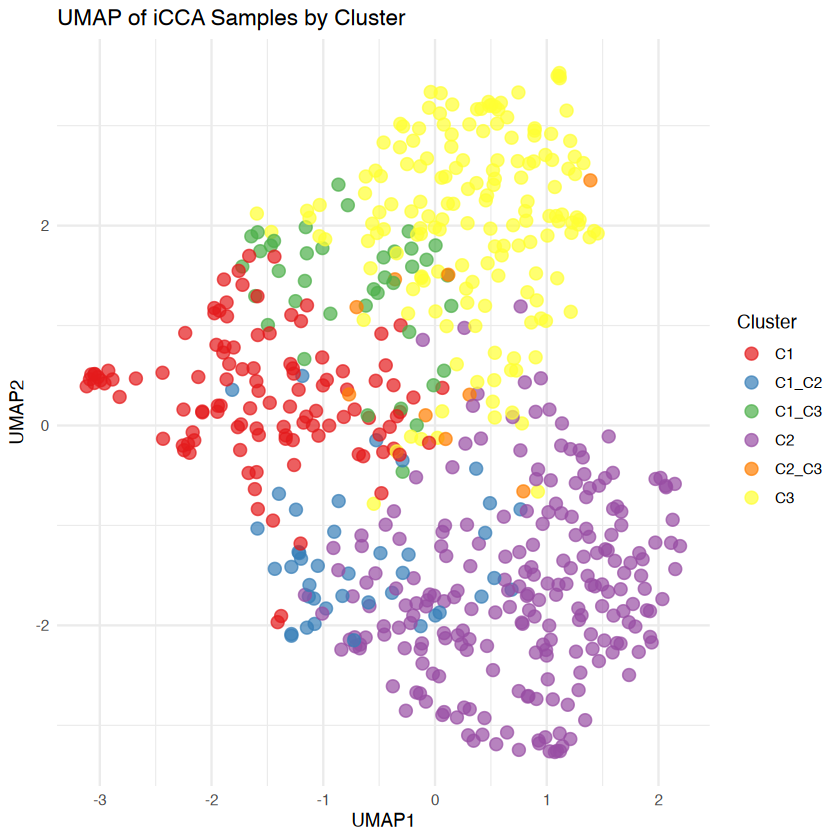

UMAP by Dataset saved.


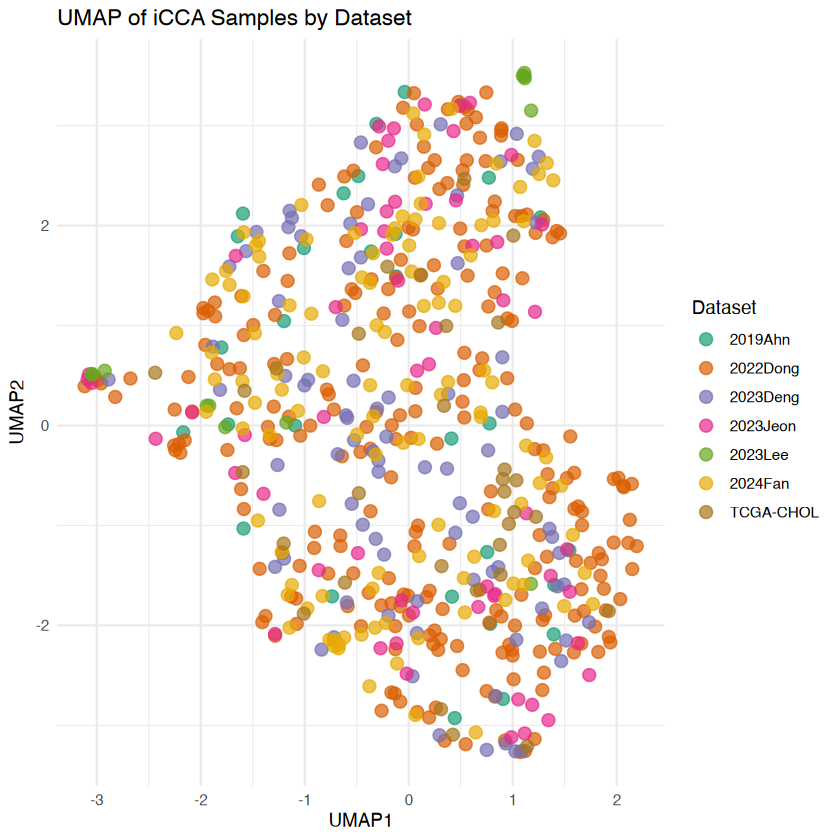

In [14]:
#===============================================================
# Section 2: UMAP Dimensionality Reduction and Visualization
#===============================================================
cat("\nSection 2: Performing UMAP dimensionality reduction and visualization...\n")

# Run UMAP on samples (transpose var_expr_subset: samples x genes)
# Ensure enough samples and features for UMAP
if (nrow(t(expr_subset)) > 3 && ncol(t(expr_subset)) > 3) {
    set.seed(123) # for reproducibility of UMAP
    umap_result <- uwot::umap(t(expr_subset), n_neighbors = min(15, nrow(t(expr_subset))-1), min_dist = 0.1, metric="cosine")
    umap_data_df <- as.data.frame(umap_result)
    colnames(umap_data_df) <- c("UMAP1", "UMAP2")

    # Add cluster and dataset information, ensuring alignment by sample ID
    umap_data_df$Sample <- rownames(umap_data_df) # uwot::umap preserves rownames if input has them
    umap_data_df$Cluster <- factor(final_clusters_subset[umap_data_df$Sample], levels = cluster_levels_sorted)
    if (exists("batch_labels_subset") && !is.null(batch_labels_subset)) {
        umap_data_df$Dataset <- factor(batch_labels_subset[umap_data_df$Sample])
    }


    # Plot UMAP colored by Cluster
    p_umap_cluster <- ggplot(umap_data_df, aes(x = UMAP1, y = UMAP2, color = Cluster)) +
      geom_point(size = 3, alpha = 0.7) +
      labs(title = "UMAP of iCCA Samples by Cluster", color = "Cluster") +
      theme_minimal() +
      scale_color_manual(values = ann_colors_list$Cluster, name = "Cluster") # Use consistent colors
    ggsave(file.path(fig_dir, "umap_by_cluster.png"), p_umap_cluster, width = 10, height = 8)
    print(p_umap_cluster)
    cat("UMAP by Cluster saved.\n")

    # Plot UMAP colored by Dataset (if Dataset info exists)
    if ("Dataset" %in% colnames(umap_data_df)) {
      p_umap_dataset <- ggplot(umap_data_df, aes(x = UMAP1, y = UMAP2, color = Dataset)) +
        geom_point(size = 3, alpha = 0.7) +
        labs(title = "UMAP of iCCA Samples by Dataset", color = "Dataset") +
        theme_minimal() +
        scale_color_manual(values = ann_colors_list$Dataset, name = "Dataset") # Use consistent colors
      ggsave(file.path(fig_dir, "umap_by_dataset.png"), p_umap_dataset, width = 10, height = 8)
      print(p_umap_dataset)
      cat("UMAP by Dataset saved.\n")
    }
} else {
    cat("Skipping UMAP: Not enough samples or features after subsetting.\n")
}

In [101]:
# 统计每个数据集各分型数量
df_study <- sample_cluster %>%
  group_by(Study, Ensemble) %>%
  summarise(n = n()) %>%
  group_by(Study) %>%
  mutate(percent = n / sum(n) * 100)
df_study$Ensemble <- factor(df_study$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

`summarise()` has grouped output by 'Study'. You can override using the
`.groups` argument.


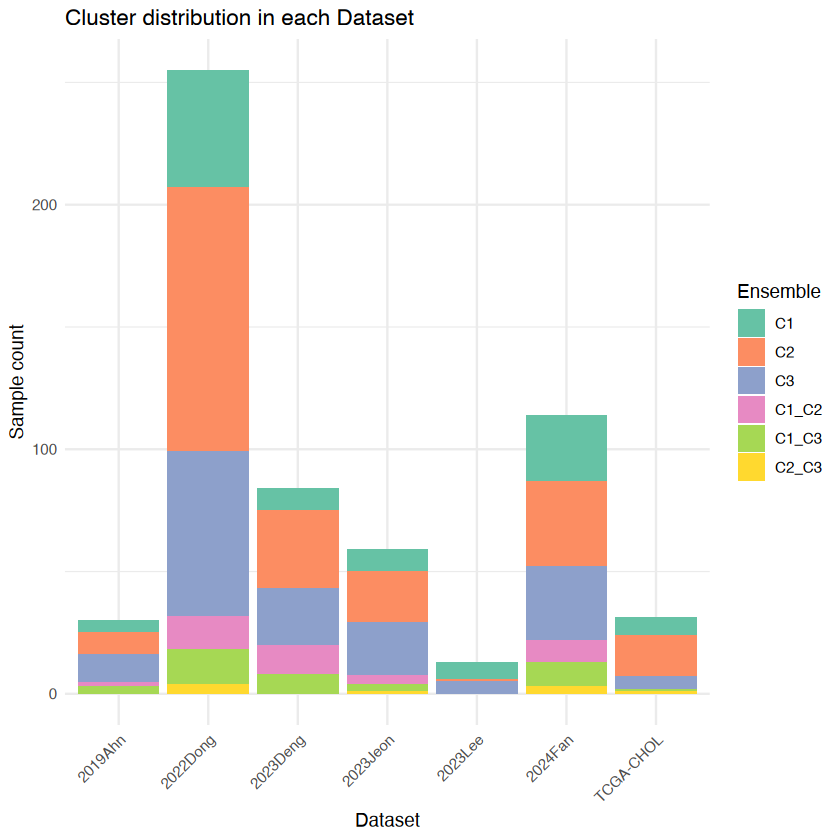

In [102]:
# 按数量堆叠条形图
ggplot(df_study, aes(x = Study, y = n, fill = Ensemble)) +
  geom_bar(stat = "identity") +
  labs(y = "Sample count", x = "Dataset", title = "Cluster distribution in each Dataset") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

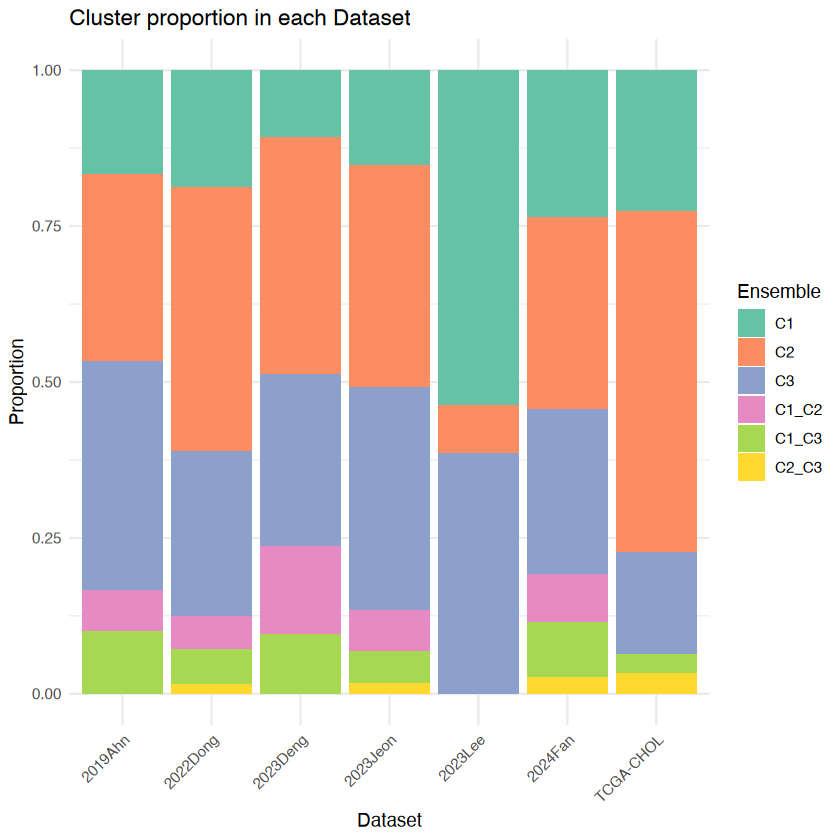

In [103]:
ggplot(df_study, aes(x = Study, y = percent, fill = Ensemble)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Dataset", title = "Cluster proportion in each Dataset") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

### clinical features

In [109]:
sample_cluster <- readxl::read_excel(paste0(data_dir, "/sample_info_with_clusters.xlsx"))
dim(sample_cluster)
head(sample_cluster)

[1] 586  37

Sample,NMF,KMeans,Ensemble,Study,Platform,Sex,Age_num,Age_group,Country,...,Distal metastasis (1=Positive),"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
111,3,1,C2_C3,2022Dong,RNAseq (Illumina),Male,49,40-60,China,...,0,8.4,36,5147,2.5,25.2,18,80,YES,NO
113,2,1,C2,2022Dong,RNAseq (Illumina),Male,59,40-60,China,...,0,9.1999999999999993,38,1.8,2.8,35,18,40,YES,NO
115,1,3,C1,2022Dong,RNAseq (Illumina),Male,74,>60,China,...,0,7.9,39,42.7,2,8.1999999999999904,11,29,YES,YES
117,1,3,C1,2022Dong,RNAseq (Illumina),Female,64,>60,China,...,0,14.1,47,2.8,1,7.9,17,27,YES,YES
121,2,1,C2,2022Dong,RNAseq (Illumina),Female,71,>60,China,...,0,8.6,42,215.1,1.4,24.9,10,23,YES,YES
123,1,3,C1,2022Dong,RNAseq (Illumina),Male,55,40-60,China,...,0,17.8,44,2.1,0.8,30.4,89,384,YES,YES


`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


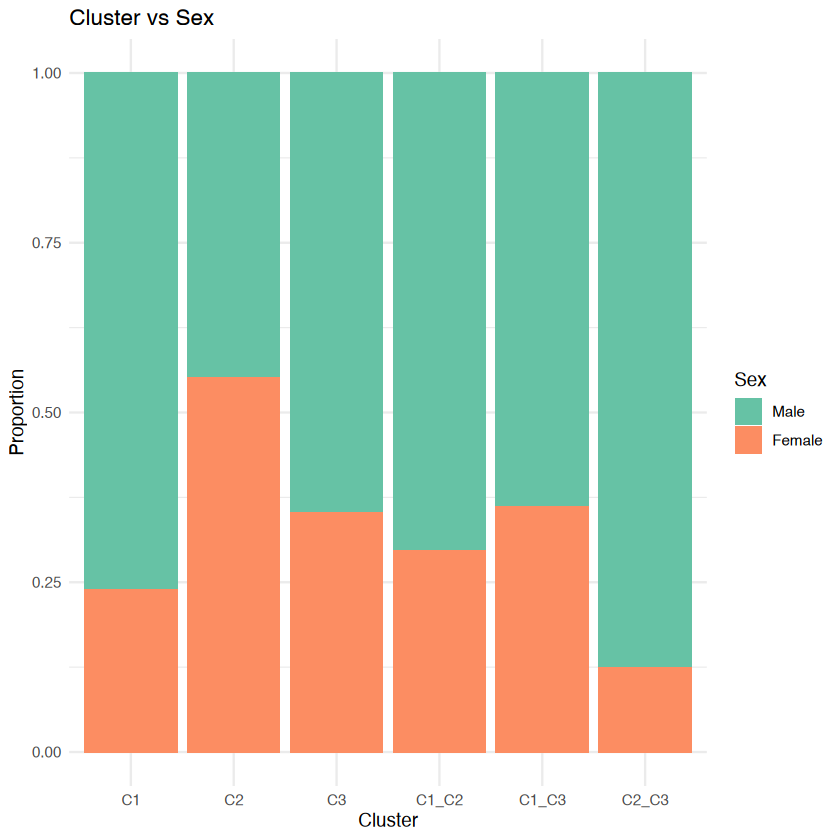

In [110]:
##分型与性别
# 性别变量标准化（有些数据Male/Female大小写不统一
sub <- sample_cluster[sample_cluster$Sex != "NA",]
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))
sub$Sex <- factor(sub$Sex, levels = c("Male", "Female"))

# 计算分型-性别比例
df_gender <- sub %>%
  group_by(Ensemble, Sex) %>%
  summarise(n = n()) %>%
  group_by(Ensemble) %>%
  mutate(percent = n / sum(n) * 100)

# 分型-性别堆叠条形图
ggplot(df_gender, aes(x = Ensemble, y = percent, fill = Sex)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Sex") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


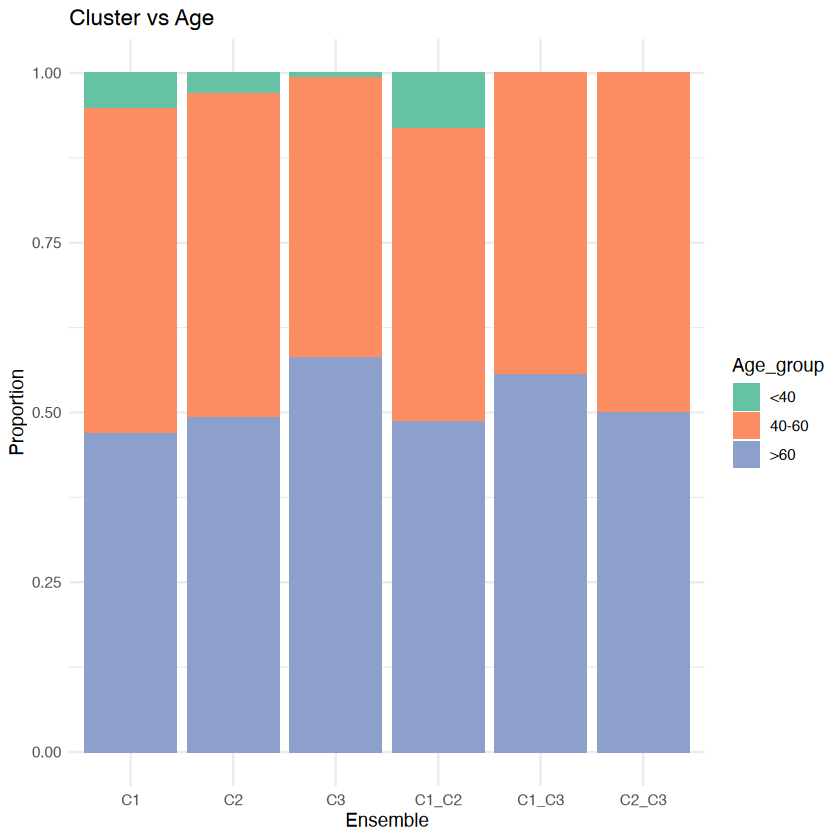

In [111]:
## 分型与Age
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Age_group != "NA",]
sub$Age_group <- factor(sub$Age_group, levels = c("<40", "40-60", ">60"))
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_bar <- sub %>%
  group_by(Ensemble, Age_group) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = Ensemble, y = Percent, fill = Age_group)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Age") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

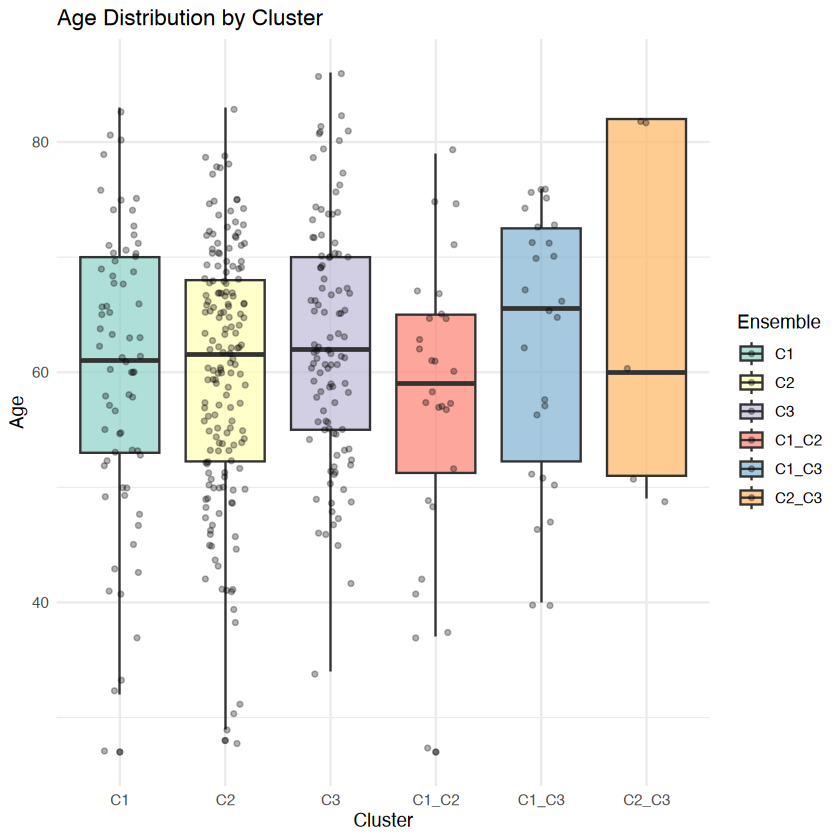

In [112]:
# 年龄转为数值型
sub <- sample_cluster[sample_cluster$Age_num != "NA",]
sub$Age_num <- as.numeric(sub$Age_num)
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

ggplot(sub, aes(x = Ensemble, y = Age_num, fill = Ensemble)) +
  geom_boxplot(alpha = 0.7, outlier.size=1) +
  geom_jitter(width=0.2, alpha=0.3, size=1) +
  labs(title = "Age Distribution by Cluster", x = "Cluster", y = "Age") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set3")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


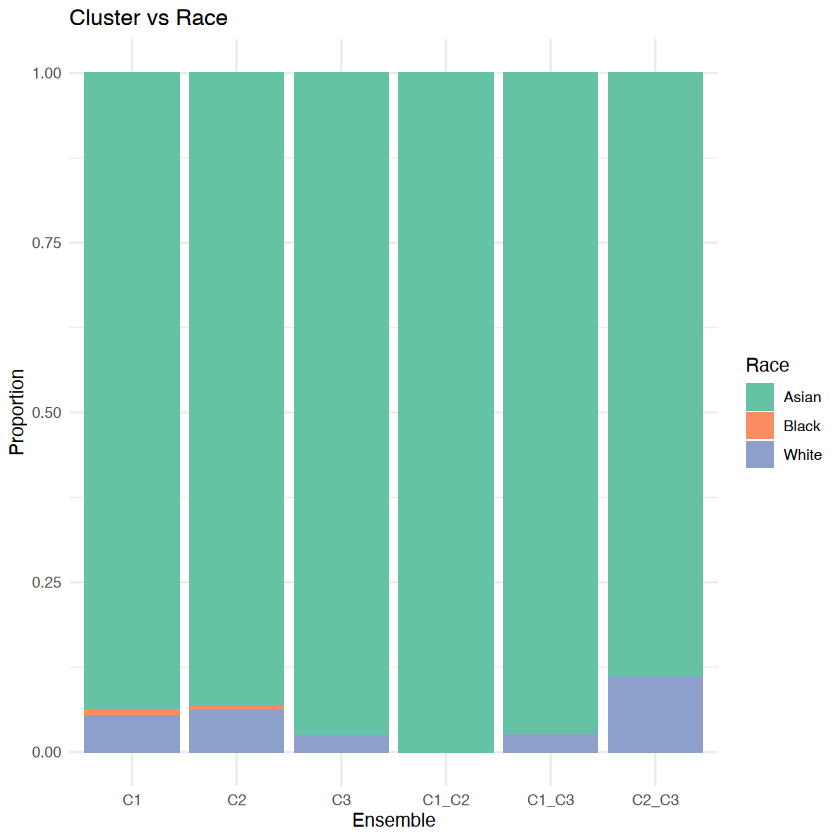

In [113]:
## 分型与race
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Race != "NA",]
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))
df_bar <- sub %>%
  group_by(Ensemble, Race) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = Ensemble, y = Percent, fill = Race)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Race") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


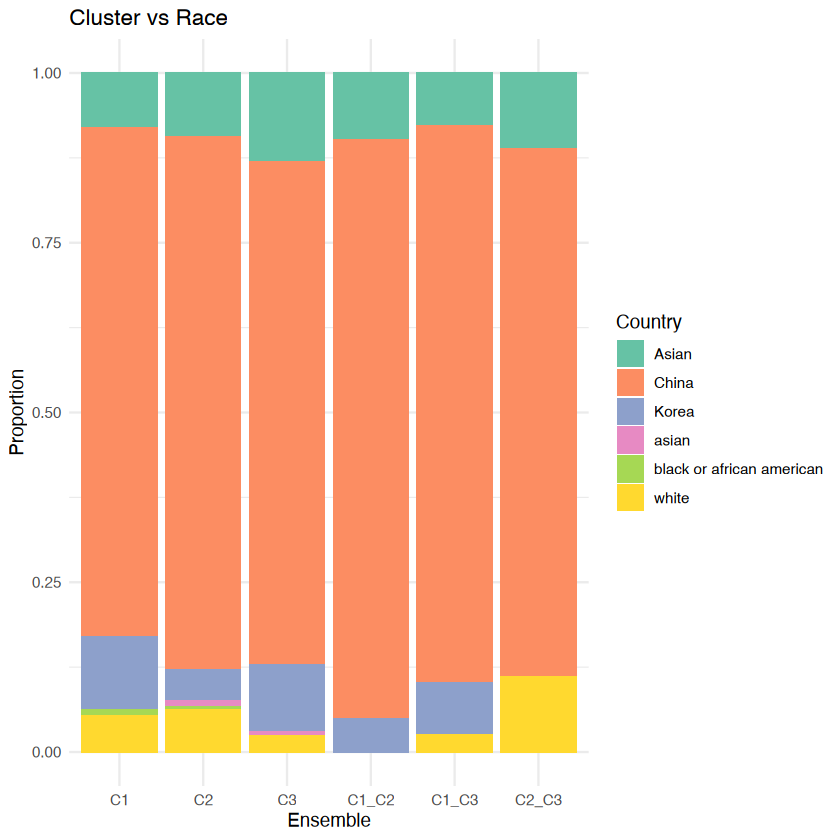

In [114]:
## 分型与Country
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Country != "NA",]
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))
df_bar <- sub %>%
  group_by(Ensemble, Country) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = Ensemble, y = Percent, fill = Country)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Race") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


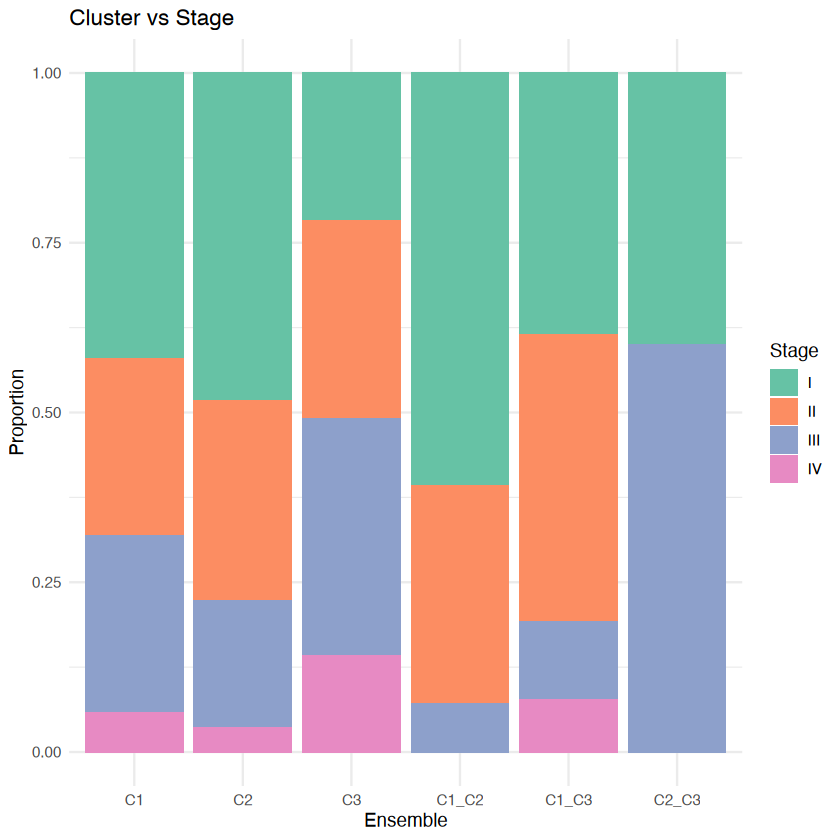

In [115]:
## 分型与Stage
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Stage != "NA",]
sub$Stage <- factor(sub$Stage, levels = c("I", "II", "III", "IV"))
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_bar <- sub %>%
  group_by(Ensemble, Stage) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = Ensemble, y = Percent, fill = Stage)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Stage") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


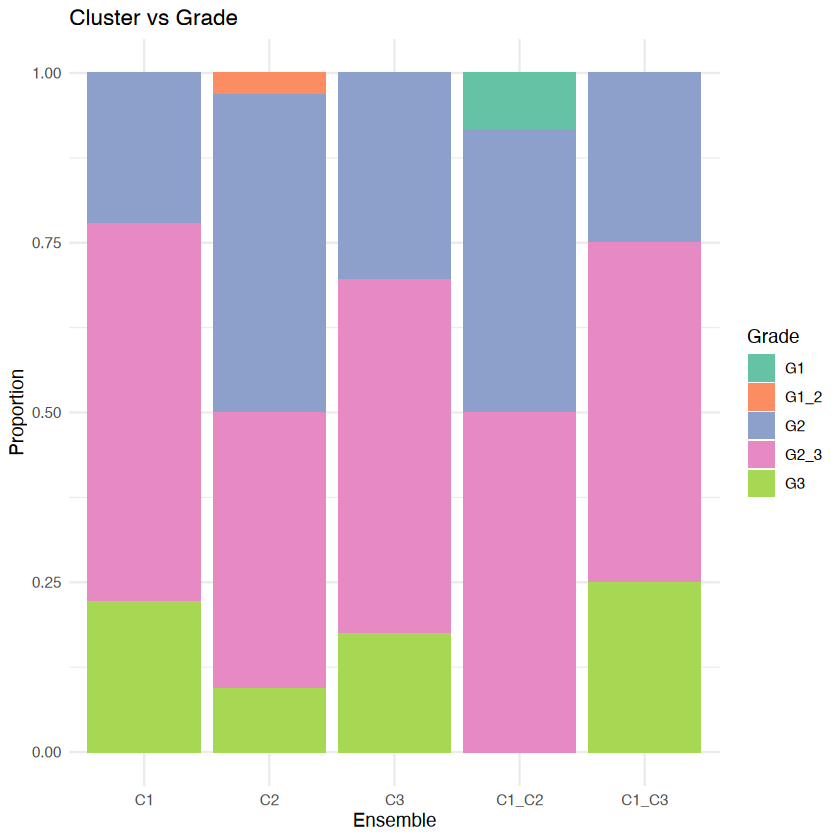

In [116]:
## 分型与Grade
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Grade != "NA",]
sub$Grade <- factor(sub$Grade, levels = c("G1", "G1_2", "G2", "G2_3", "G3"))
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_bar <- sub %>%
  group_by(Ensemble, Grade) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = Ensemble, y = Percent, fill = Grade)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Grade") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


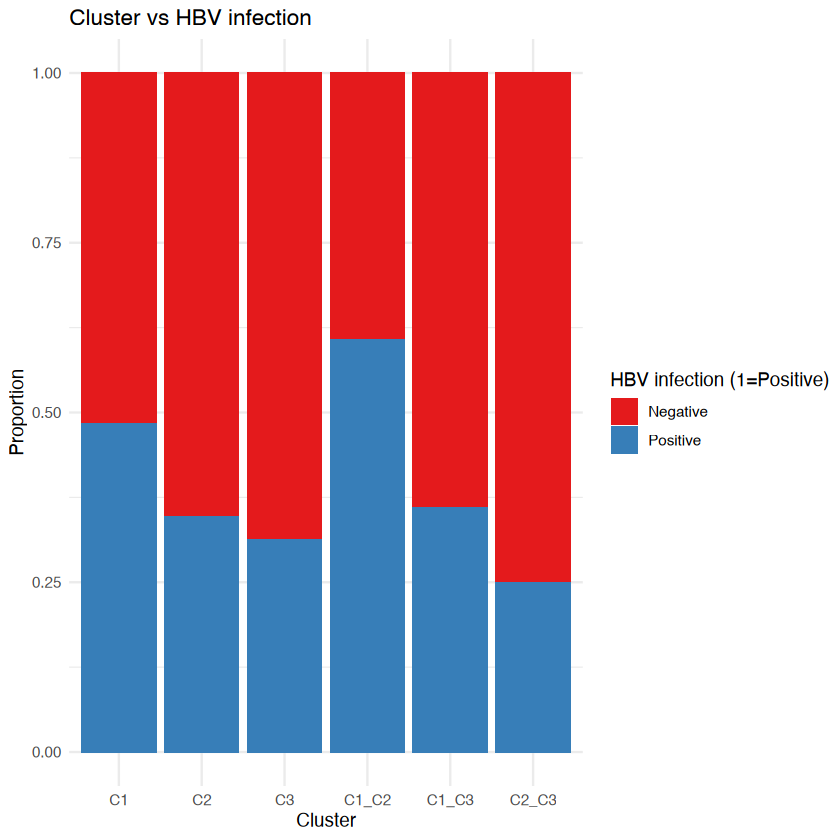

In [117]:
## 分型与HBV infection
sub <- sample_cluster[sample_cluster$`HBV infection (1=Positive)` != "NA",]
sub$`HBV infection (1=Positive)` <- factor(sub$`HBV infection (1=Positive)`, levels = c("0", "1"), labels = c("Negative", "Positive"))
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_survival <- sub %>%
  group_by(Ensemble, `HBV infection (1=Positive)`) %>%
  summarise(n = n()) %>%
  group_by(Ensemble) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = Ensemble, y = percent, fill = `HBV infection (1=Positive)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs HBV infection") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


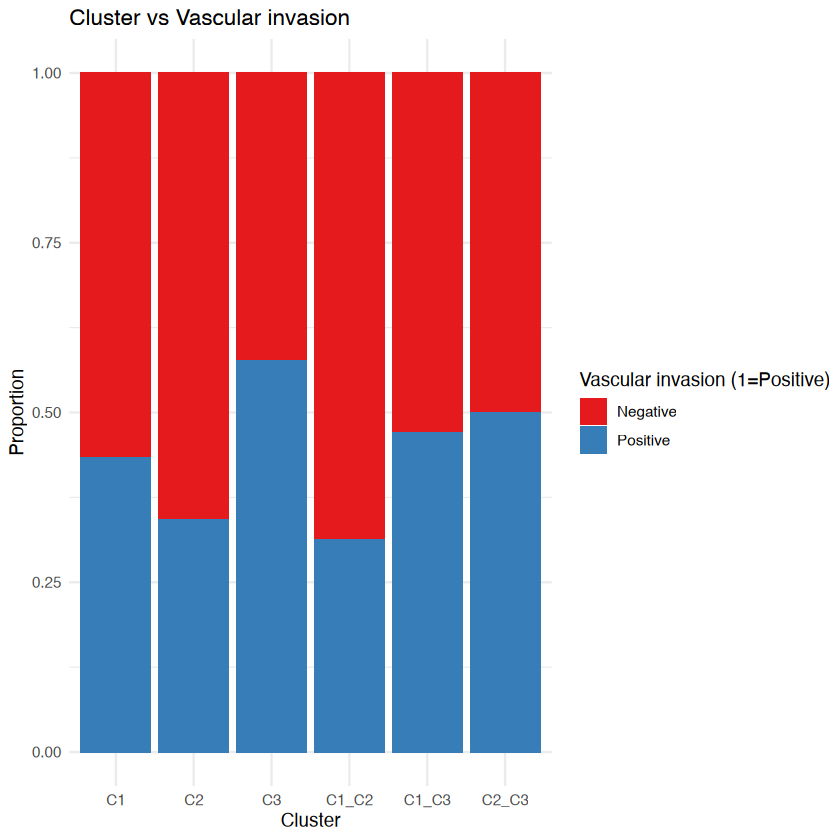

In [118]:
## 分型与Vascular invasion
sub <- sample_cluster[sample_cluster$`Vascular invasion (1=Positive)` != "NA",]
sub$`Vascular invasion (1=Positive)` <- factor(sub$`Vascular invasion (1=Positive)`, levels = c("0", "1"), labels = c("Negative", "Positive"))
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_survival <- sub %>%
  group_by(Ensemble, `Vascular invasion (1=Positive)`) %>%
  summarise(n = n()) %>%
  group_by(Ensemble) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = Ensemble, y = percent, fill = `Vascular invasion (1=Positive)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Vascular invasion") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


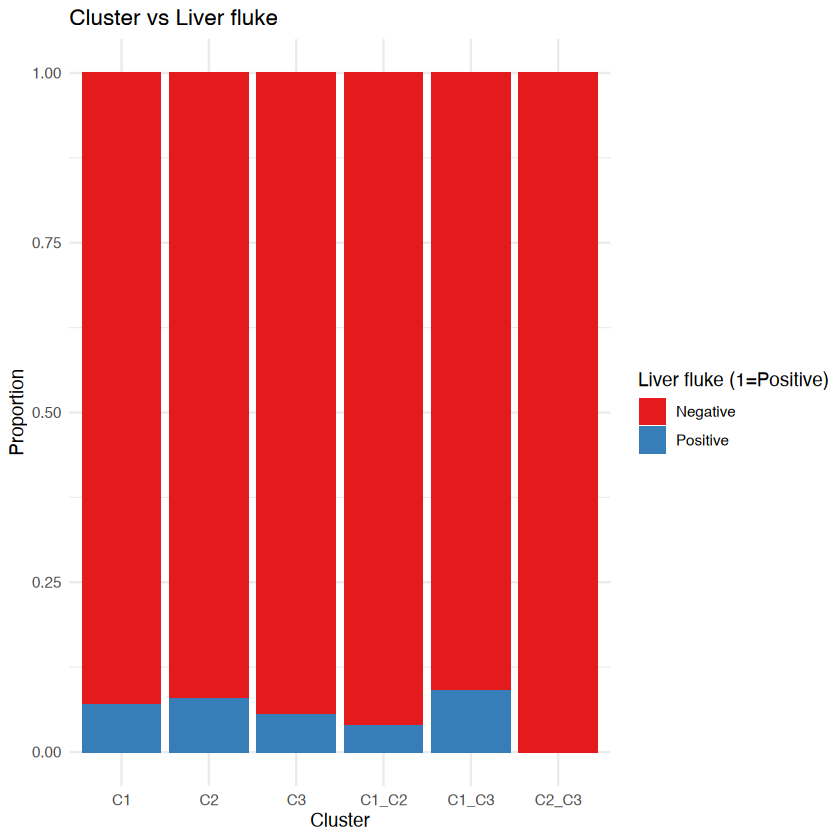

In [119]:
## 分型与Liver fluke
sub <- sample_cluster[sample_cluster$`Liver fluke (1=Positive)` != "NA",]
sub$`Liver fluke (1=Positive)` <- factor(sub$`Liver fluke (1=Positive)`, levels = c("0", "1"), labels = c("Negative", "Positive"))
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_survival <- sub %>%
  group_by(Ensemble, `Liver fluke (1=Positive)`) %>%
  summarise(n = n()) %>%
  group_by(Ensemble) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = Ensemble, y = percent, fill = `Liver fluke (1=Positive)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Liver fluke") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


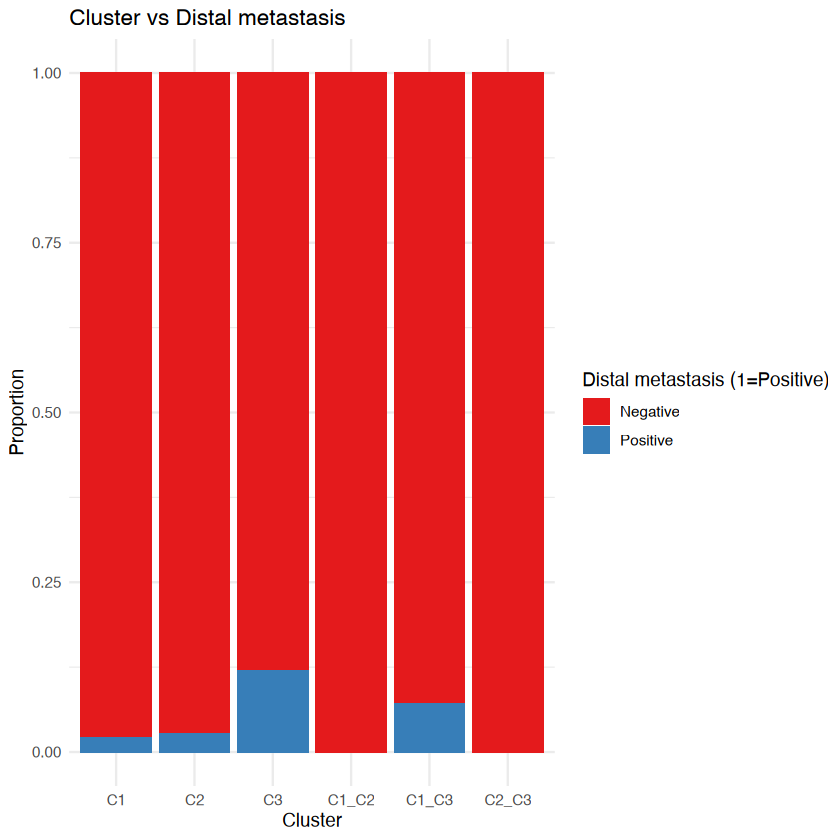

In [120]:
## 分型与Distal metastasis
sub <- sample_cluster[sample_cluster$`Distal metastasis (1=Positive)` != "NA",]
sub$`Distal metastasis (1=Positive)` <- factor(sub$`Distal metastasis (1=Positive)`, levels = c("0", "1"), labels = c("Negative", "Positive"))
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_survival <- sub %>%
  group_by(Ensemble, `Distal metastasis (1=Positive)`) %>%
  summarise(n = n()) %>%
  group_by(Ensemble) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = Ensemble, y = percent, fill = `Distal metastasis (1=Positive)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Distal metastasis") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

### duct type

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


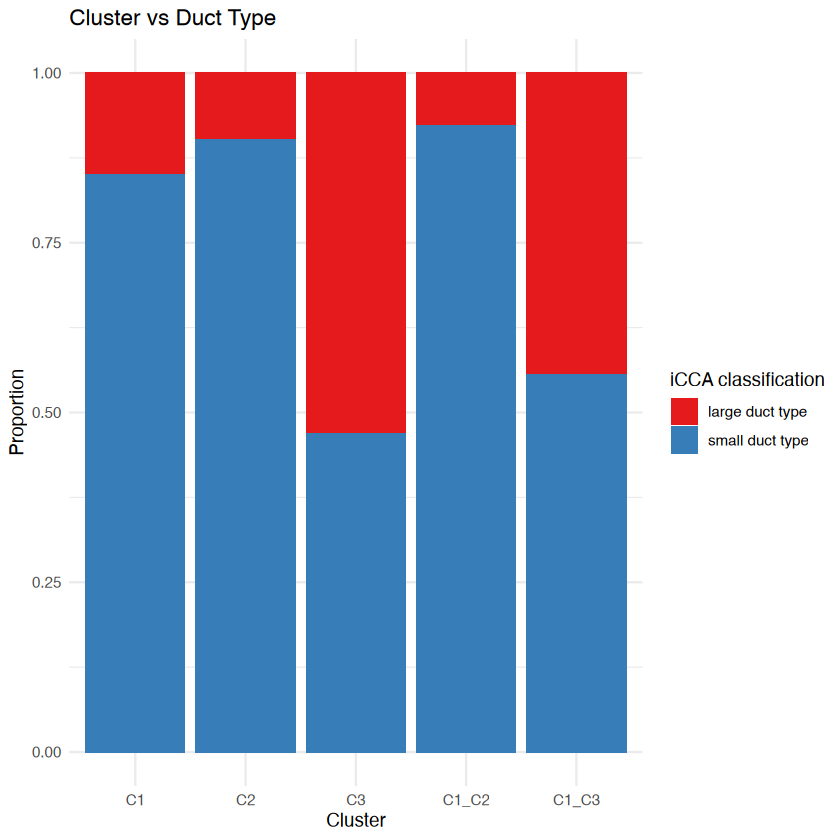

In [121]:
##分型与胆管类型
sub <- sample_cluster[sample_cluster$'iCCA classification' != "w/o",]
sub$`iCCA classification` <- factor(sub$`iCCA classification`)
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_duct <- sub %>%
  filter(!is.na(`iCCA classification`)) %>%
  group_by(Ensemble, `iCCA classification`) %>%
  summarise(n = n()) %>%
  group_by(Ensemble) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_duct, aes(x = Ensemble, y = percent, fill = `iCCA classification`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Duct Type") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


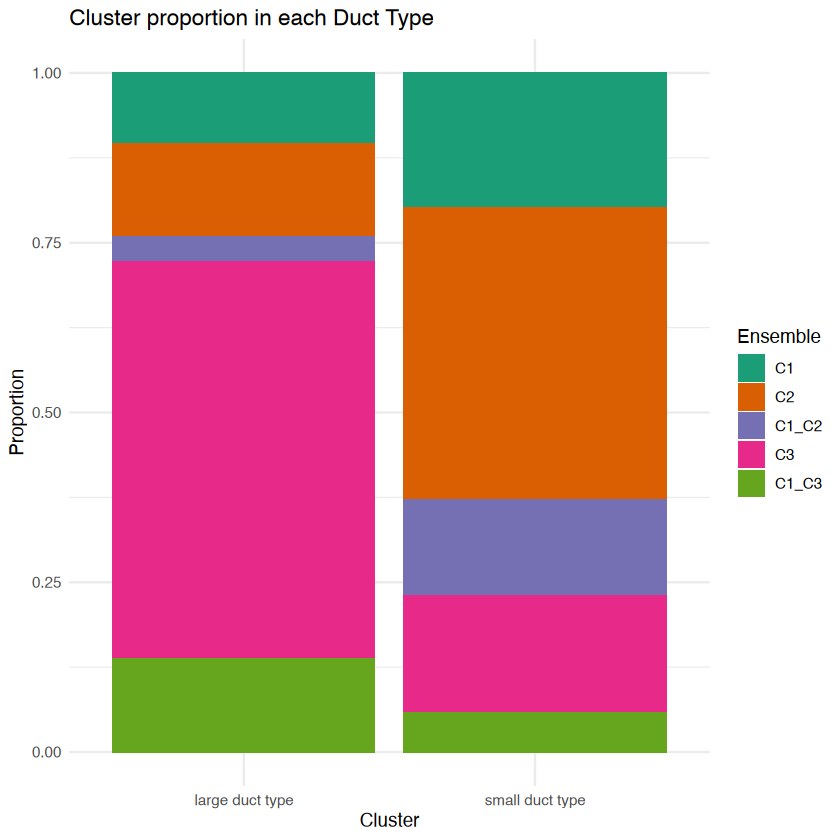

In [122]:
df_cluster <- sub %>%
  group_by(Ensemble, `iCCA classification`) %>%
  summarise(n = n()) %>%
  group_by(`iCCA classification`) %>%
  mutate(percent = n / sum(n) * 100)
df_cluster$Ensemble <- factor(df_cluster$Ensemble, levels = c("C1","C2","C1_C2","C3","C1_C3"))

ggplot(df_cluster, aes(x = `iCCA classification`, y = percent, fill = Ensemble)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster proportion in each Duct Type") +
  theme_minimal() +
  scale_fill_brewer(palette = "Dark2")

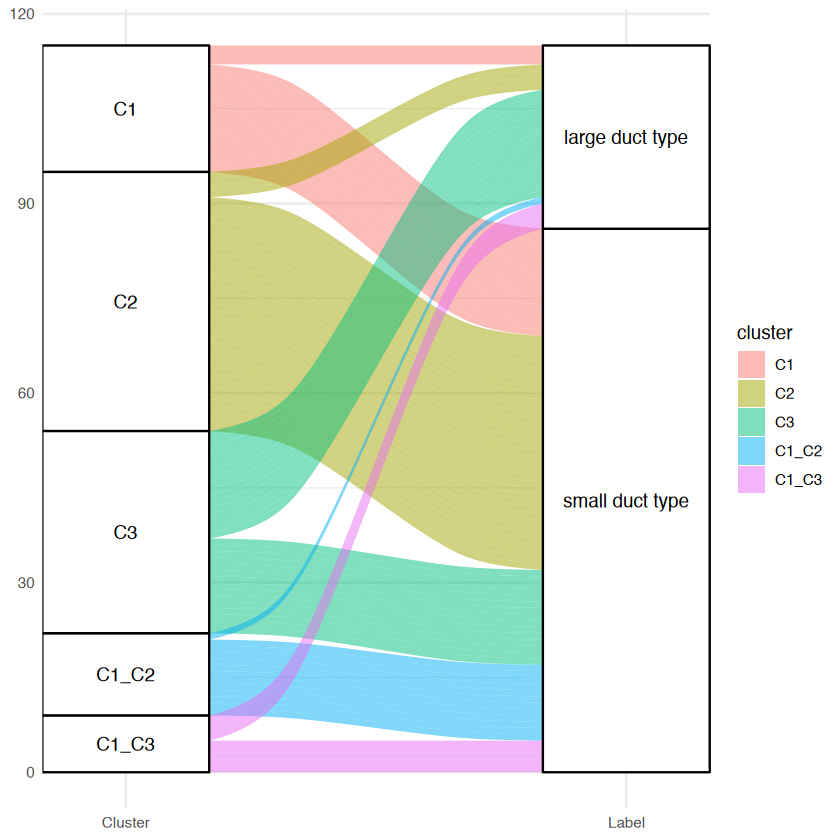

In [123]:
library(ggalluvial)
data <- data.frame(
  cluster = sub$Ensemble,
  label = sub$'iCCA classification'
)
ggplot(data,
       aes(axis1 = cluster, axis2 = label)) +
  geom_alluvium(aes(fill = cluster)) +
  geom_stratum() +
  geom_text(stat = "stratum", aes(label = after_stat(stratum))) +
  scale_x_discrete(limits = c("Cluster", "Label"), expand = c(.05, .05)) +
  theme_minimal()

### survival

`summarise()` has grouped output by 'Ensemble'. You can override using the
`.groups` argument.


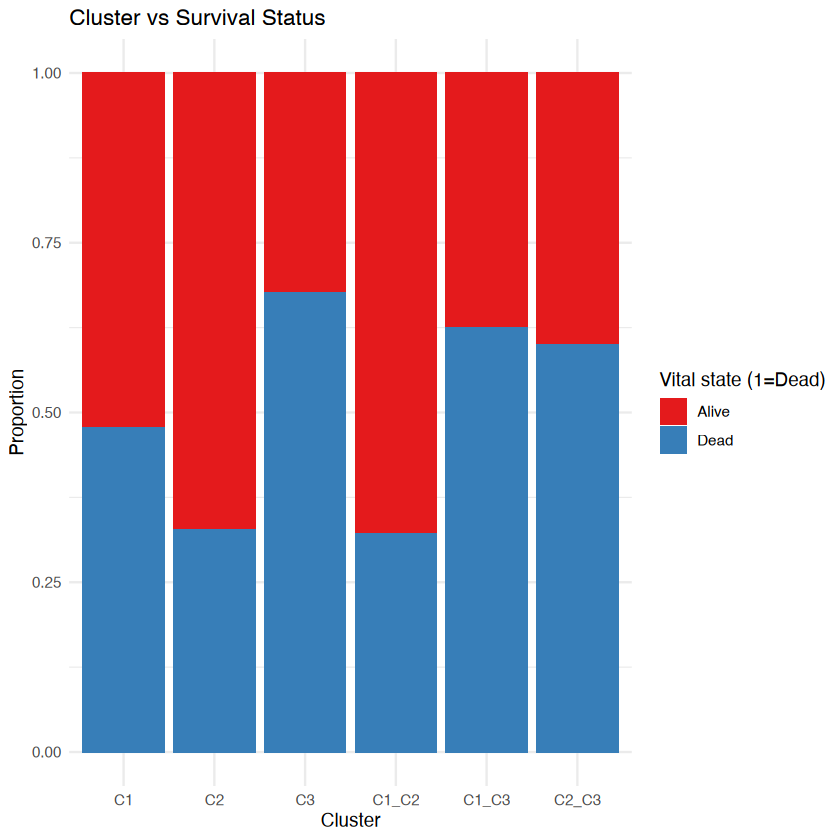

In [124]:
## 分型与survival state
sub <- sample_cluster[sample_cluster$`Vital state (1=Dead)` != "NA",]
sub$`Vital state (1=Dead)` <- factor(sub$`Vital state (1=Dead)`, levels = c("0", "1"), labels = c("Alive", "Dead"))
sub$Ensemble <- factor(sub$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

df_survival <- sub %>%
  group_by(Ensemble, `Vital state (1=Dead)`) %>%
  summarise(n = n()) %>%
  group_by(Ensemble) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = Ensemble, y = percent, fill = `Vital state (1=Dead)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Survival Status") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

In [125]:
## 分型与survival
library(survival)
library(survminer)
library(dplyr)

# 1. 整理数据
km_data <- sample_cluster %>%
  filter(`Vital state (1=Dead)` != "NA") %>%
  select(`Overall survival (months)`, `Vital state (1=Dead)`, Ensemble) %>%
  mutate(
    # 转为数值型
    OS_months = as.numeric(`Overall survival (months)`),
    Status = as.numeric(`Vital state (1=Dead)`),  # 1=Dead, 0=Alive
    Cluster = Ensemble
  )
km_data <- km_data %>%
  filter(OS_months >=1)

In [126]:
# Surv(生存时间, 状态)  状态1=事件（死亡）, 0=截尾（活）
surv_object <- Surv(time = km_data$OS_months, event = km_data$Status)

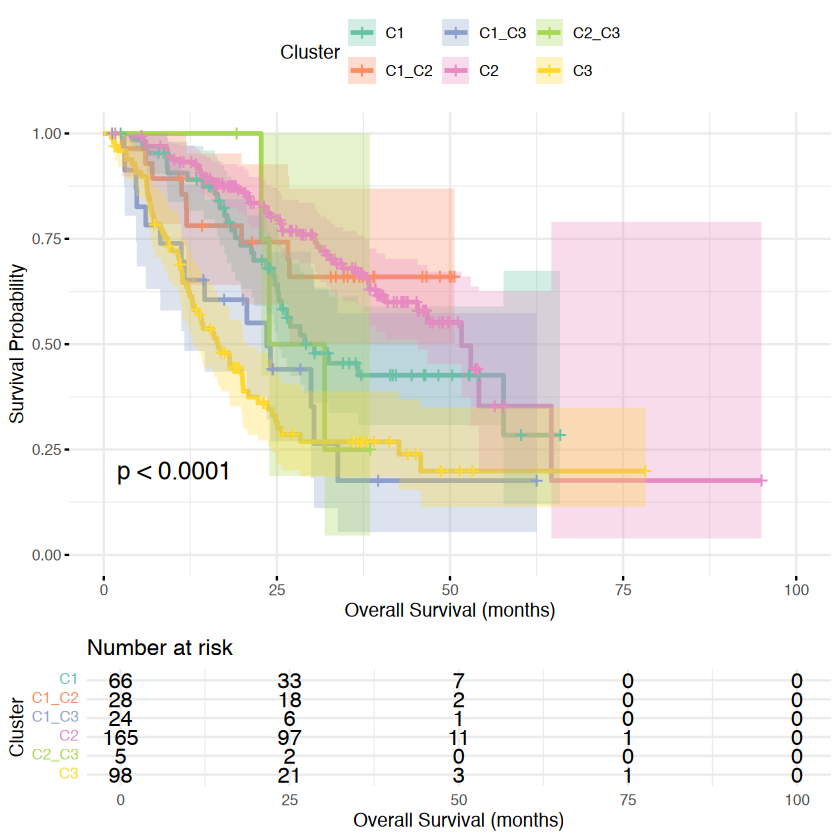

In [127]:
# 拟合KM曲线
fit <- survfit(surv_object ~ Cluster, data = km_data)

# 绘制KM曲线
ggsurvplot(
  fit, 
  data = km_data,
  pval = TRUE,                 # 显示log-rank检验p值
  risk.table = TRUE,           # 显示风险表
  conf.int = TRUE,             # 置信区间
  legend.title = "Cluster",
  legend.labs = levels(factor(km_data$Cluster)), # 保证图例顺序
  palette = "Set2",            # 你也可以自定义颜色
  xlab = "Overall Survival (months)",
  ylab = "Survival Probability",
  #xlim = c(0, 60),
  ggtheme = theme_minimal()
)

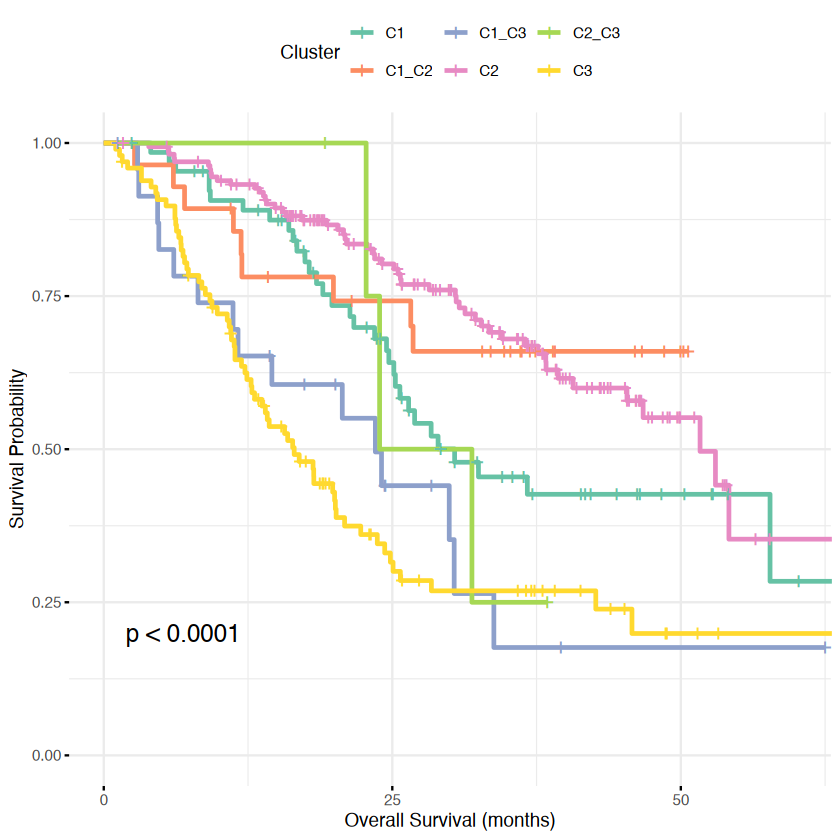

In [128]:
# 拟合KM曲线
fit <- survfit(surv_object ~ Cluster, data = km_data)

# 绘制KM曲线
ggsurvplot(
  fit, 
  data = km_data,
  pval = TRUE,                 # 显示log-rank检验p值
  risk.table = FALSE,           # 显示风险表
  conf.int = FALSE,             # 置信区间
  legend.title = "Cluster",
  legend.labs = levels(factor(km_data$Cluster)), # 保证图例顺序
  palette = "Set2",            # 你也可以自定义颜色
  xlab = "Overall Survival (months)",
  ylab = "Survival Probability",
  xlim = c(0, 60),
  ggtheme = theme_minimal()
)

#===============================================================
# 第6部分: DEG & GSEA
#===============================================================

In [6]:
library(clusterProfiler)
library(org.Hs.eg.db)
library(DOSE)
library(ggplot2)
library(enrichplot)

In [5]:
load(file = paste0(data_dir, "/combined_expr_after_correction.rds"))
dim(corrected_expr_limma)
head(corrected_expr_limma)

[1] 10531   586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
TMSB10,10.82928,10.890999,11.94522,12.778273,10.995143,11.226208,10.035329,10.398659,11.30408,12.16933,...,10.99660,11.026177,11.094798,12.008558,11.481356,12.627119,11.769922,11.4156781,11.201563,9.495304
ALB,12.05004,13.178437,10.79637,5.770313,7.063872,4.553839,12.638745,12.447035,10.08065,10.02450,...,11.00465,12.196094,10.683190,12.497491,2.410946,8.453237,7.411365,0.4926482,12.583942,7.533481
FTL,10.66605,12.897749,11.72236,11.072817,12.143254,12.137395,13.854919,12.317509,11.09063,11.08043,...,11.76724,9.781075,10.558542,10.432385,12.301201,12.339945,13.363718,11.6431148,10.730668,11.445058
S100A6,10.31944,5.593509,11.54254,10.995845,11.064880,10.134493,7.784021,10.904630,10.58029,10.69710,...,10.62347,10.704640,8.700956,7.914385,12.343699,11.888619,10.589558,8.2747927,8.948155,8.407319
RPS18,10.09080,10.167330,10.44833,10.278913,9.563777,9.050844,9.202332,9.774162,11.49839,10.09671,...,10.64097,11.134008,9.614914,10.565745,9.542747,9.639386,9.873656,11.1388385,10.614570,9.653813
TMSB4X,10.61613,10.408689,11.31893,11.724414,11.308622,11.295856,10.777988,11.413705,10.88848,11.85332,...,10.43501,10.587907,10.379686,11.303271,11.737150,11.998210,10.570807,12.4690672,10.863712,9.242494


In [6]:
sample_cluster <- readxl::read_excel(paste0(data_dir, "/sample_info_with_clusters.xlsx"))
dim(sample_cluster)
head(sample_cluster)

[1] 586  38

Sample,NMF,KMeans,Ensemble,Study,Platform,Sex,Age_num,Age_group,Country,...,Distal metastasis (1=Positive),"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
111,3,1,C2_C3,2022Dong,RNAseq (Illumina),Male,49,40-60,China,...,0,8.4,36,5147,2.5,25.2,18,80,YES,NO
113,2,1,C2,2022Dong,RNAseq (Illumina),Male,59,40-60,China,...,0,9.1999999999999993,38,1.8,2.8,35,18,40,YES,NO
115,1,3,C1,2022Dong,RNAseq (Illumina),Male,74,>60,China,...,0,7.9,39,42.7,2,8.1999999999999904,11,29,YES,YES
117,1,3,C1,2022Dong,RNAseq (Illumina),Female,64,>60,China,...,0,14.1,47,2.8,1,7.9,17,27,YES,YES
121,2,1,C2,2022Dong,RNAseq (Illumina),Female,71,>60,China,...,0,8.6,42,215.1,1.4,24.9,10,23,YES,YES
123,1,3,C1,2022Dong,RNAseq (Illumina),Male,55,40-60,China,...,0,17.8,44,2.1,0.8,30.4,89,384,YES,YES


In [9]:
expr_mat <- corrected_expr_limma
cluster_vec <- sample_cluster$Ensemble
names(cluster_vec) <- sample_cluster$Sample
# 确保分型标签顺序和表达矩阵一致
cluster_vec <- as.factor(cluster_vec[colnames(expr_mat)])

In [12]:
#===============================================================
# Differential Expression Analysis
#===============================================================
# DEG分析参数
logfc_cutoff <- 1
adjp_cutoff <- 0.05

all_degs_list <- list()

for(cl in levels(cluster_vec)){
  group <- ifelse(cluster_vec == cl, cl, "Others")
  group <- factor(group, levels = c(cl, "Others"))
  
  design <- model.matrix(~group)
  fit <- lmFit(expr_mat, design)
  fit <- eBayes(fit)
  degs <- topTable(fit, coef = 2, number = Inf, sort.by = "p")

  # 保存结果
  all_degs_list[[cl]] <- degs
  write.csv(degs, paste0("DGE_all_genes_", cl, "_vs_Others.csv"))
  
  # 简单Volcano
  if(nrow(degs) > 0){
    library(EnhancedVolcano)
    volcano <- EnhancedVolcano(
      degs, lab = rownames(degs), x = "logFC", y = "adj.P.Val",
      title = paste0(cl, " vs Others"), pCutoff = adjp_cutoff, FCcutoff = logfc_cutoff
    )
    ggsave(paste0("volcano_", cl, "_vs_Others.png"), volcano, width=8, height=6)
  }
}

In [13]:
save(all_degs_list, file = paste0(data_dir, "/all_degs_list.rds"))

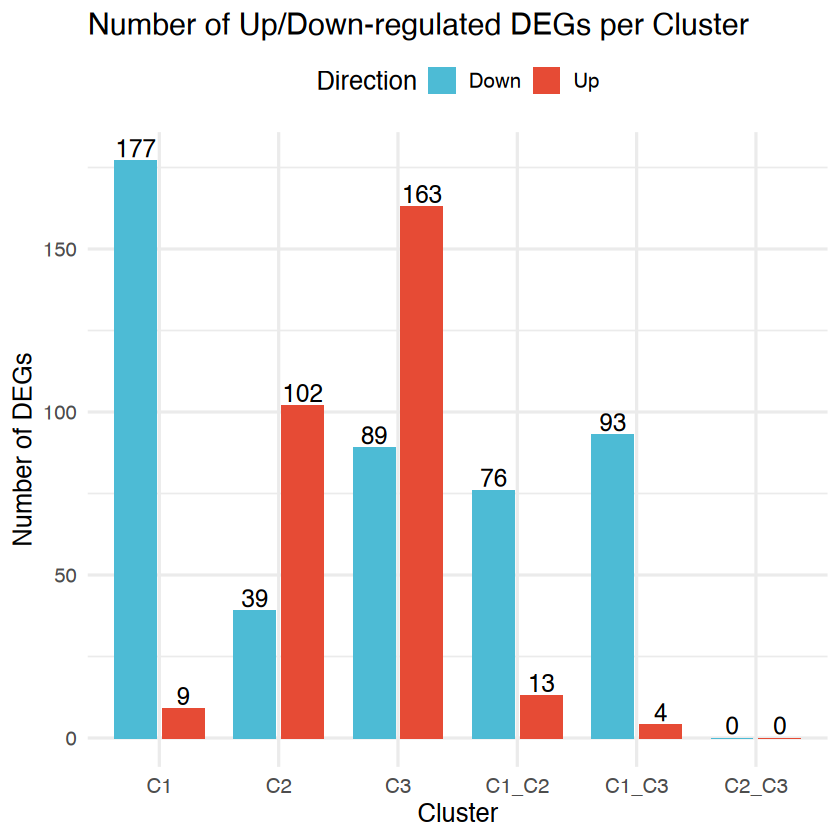

In [21]:
# 假设 all_degs_list 中每个元素是某cluster vs others的DEG data.frame，含 logFC
deg_stat <- data.frame(
  Cluster = character(),
  Direction = character(),
  Count = integer()
)

logfc_cutoff <- 1.5
adjp_cutoff <- 0.05

for(cl in names(all_degs_list)){
  deg_table <- all_degs_list[[cl]]
  deg_table <- deg_table[abs(deg_table$logFC) > logfc_cutoff & deg_table$adj.P.Val < adjp_cutoff, ]
  up_count <- sum(deg_table$logFC > 0)
  down_count <- sum(deg_table$logFC < 0)
  deg_stat <- rbind(deg_stat,
                    data.frame(Cluster = cl, Direction = "Up", Count = up_count),
                    data.frame(Cluster = cl, Direction = "Down", Count = down_count))
}

# 保证Cluster顺序
deg_stat$Cluster <- factor(deg_stat$Cluster, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))

# 绘图
ggplot(deg_stat, aes(x = Cluster, y = Count, fill = Direction)) +
  geom_bar(stat = "identity", position = position_dodge(width = 0.8), width = 0.7) +
  geom_text(aes(label = Count), 
            position = position_dodge(width = 0.8), 
            vjust = -0.2, size = 5) +
  scale_fill_manual(values = c("Up"="#E64B35FF", "Down"="#4DBBD5FF")) +
  labs(title = "Number of Up/Down-regulated DEGs per Cluster",
       y = "Number of DEGs", x = "Cluster") +
  theme_minimal(base_size = 15) +
  theme(legend.position = "top")

In [20]:
#===============================================================
# Functional Enrichment
#===============================================================
# DEG分析参数
logfc_cutoff <- 1
adjp_cutoff <- 0.05
p_cutoff <- 0.2
q_cutoff <- 0.5

KEGG <- read.csv(file = "/Users/luye/Data/Sig/hsaMetaGenes.csv")
m_t2g <- KEGG[, c(1,3)]
colnames(m_t2g) <- c("gs_name", "gene_symbol")

all_genes_in_subset_symbols <- rownames(expr_mat) # 作为universe

for(cl in levels(cluster_vec)){
  degs_df <- all_degs_list[[cl]]
  sig_degs_df <- degs_df[abs(degs_df$logFC) > logfc_cutoff & degs_df$adj.P.Val < adjp_cutoff, ]
  if(nrow(sig_degs_df) < 10) next
  up_genes_symbols <- rownames(sig_degs_df[sig_degs_df$logFC > 0, ])
  down_genes_symbols <- rownames(sig_degs_df[sig_degs_df$logFC < 0, ])
  
  # GO BP Up
  if(length(up_genes_symbols) >= 10){
    go_up <- enrichGO(
      gene = up_genes_symbols,
      OrgDb = org.Hs.eg.db, keyType = "SYMBOL",
      ont = "BP", universe = all_genes_in_subset_symbols,
      pAdjustMethod = "BH", pvalueCutoff = p_cutoff, qvalueCutoff = q_cutoff,
      readable = TRUE)
    if(!is.null(go_up) && nrow(go_up)>0){
      write.csv(as.data.frame(go_up), paste0("GO_BP_up_", cl, ".csv"), row.names=FALSE)
      p_go_up <- dotplot(go_up, showCategory=15, title=paste0("GO BP Up - ", cl))
      ggsave(paste0("GO_BP_up_", cl, ".png"), p_go_up, width=10, height=7)
    }
  }
  # GO BP Down
  if(length(down_genes_symbols) >= 10){
    go_down <- enrichGO(
      gene = down_genes_symbols,
      OrgDb = org.Hs.eg.db, keyType = "SYMBOL",
      ont = "BP", universe = all_genes_in_subset_symbols,
      pAdjustMethod = "BH", pvalueCutoff = p_cutoff, qvalueCutoff = q_cutoff,
      readable = TRUE)
    if(!is.null(go_down) && nrow(go_down)>0){
      write.csv(as.data.frame(go_down), paste0("GO_BP_down_", cl, ".csv"), row.names=FALSE)
      p_go_down <- dotplot(go_down, showCategory=15, title=paste0("GO BP Down - ", cl))
      ggsave(paste0("GO_BP_down_", cl, ".png"), p_go_down, width=10, height=7)
    }
  }
  # KEGG Up
  if(length(up_genes_symbols) >= 5){
    eKEGG_up <- enricher(
      gene = up_genes_symbols,
      pvalueCutoff = p_cutoff, pAdjustMethod = "BH",
      minGSSize = 3, maxGSSize = 500, qvalueCutoff = q_cutoff,
      TERM2GENE = m_t2g)
    if(!is.null(eKEGG_up) && nrow(eKEGG_up)>0){
      write.csv(as.data.frame(eKEGG_up), paste0("eKEGG_up_", cl, ".csv"), row.names=FALSE)
      p_kegg_up <- dotplot(eKEGG_up, showCategory=15, title=paste0("Metabolic KEGG Up - ", cl))
      ggsave(paste0("eKEGG_up_", cl, ".png"), p_kegg_up, width=10, height=7)
    }
  }
  # KEGG Down
  if(length(down_genes_symbols) >= 5){
    eKEGG_down <- enricher(
      gene = down_genes_symbols,
      pvalueCutoff = p_cutoff, pAdjustMethod = "BH",
      minGSSize = 2, maxGSSize = 500, qvalueCutoff = q_cutoff,
      TERM2GENE = m_t2g)
    if(!is.null(eKEGG_down) && nrow(eKEGG_down)>0){
      write.csv(as.data.frame(eKEGG_down), paste0("eKEGG_down_", cl, ".csv"), row.names=FALSE)
      p_kegg_down <- dotplot(eKEGG_down, showCategory=15, title=paste0("Metabolic KEGG Down - ", cl))
      ggsave(paste0("eKEGG_down_", cl, ".png"), p_kegg_down, width=10, height=7)
    }
  }
}

### HALLMARK gsva

In [10]:
dim(expr_mat)
head(expr_mat)

[1] 10531   586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
TMSB10,10.82928,10.890999,11.94522,12.778273,10.995143,11.226208,10.035329,10.398659,11.30408,12.16933,...,10.99660,11.026177,11.094798,12.008558,11.481356,12.627119,11.769922,11.4156781,11.201563,9.495304
ALB,12.05004,13.178437,10.79637,5.770313,7.063872,4.553839,12.638745,12.447035,10.08065,10.02450,...,11.00465,12.196094,10.683190,12.497491,2.410946,8.453237,7.411365,0.4926482,12.583942,7.533481
FTL,10.66605,12.897749,11.72236,11.072817,12.143254,12.137395,13.854919,12.317509,11.09063,11.08043,...,11.76724,9.781075,10.558542,10.432385,12.301201,12.339945,13.363718,11.6431148,10.730668,11.445058
S100A6,10.31944,5.593509,11.54254,10.995845,11.064880,10.134493,7.784021,10.904630,10.58029,10.69710,...,10.62347,10.704640,8.700956,7.914385,12.343699,11.888619,10.589558,8.2747927,8.948155,8.407319
RPS18,10.09080,10.167330,10.44833,10.278913,9.563777,9.050844,9.202332,9.774162,11.49839,10.09671,...,10.64097,11.134008,9.614914,10.565745,9.542747,9.639386,9.873656,11.1388385,10.614570,9.653813
TMSB4X,10.61613,10.408689,11.31893,11.724414,11.308622,11.295856,10.777988,11.413705,10.88848,11.85332,...,10.43501,10.587907,10.379686,11.303271,11.737150,11.998210,10.570807,12.4690672,10.863712,9.242494


In [18]:
library(GSVA)

# 获取MSigDB hallmark基因集
msigdb <- readRDS("/Users/luye/Data/Sig/msigdb.2024.1.Hs.rds")
sub_msigdb <- msigdb[msigdb$gs_collection == "H", ]
gene_sets <- split(sub_msigdb$db_gene_symbol, sub_msigdb$gs_name)

# 创建ssGSEA参数对象
#创建一个参数对象
params <- gsvaParam(
    as.matrix(expr_mat), 
    gene_sets, minSize = 1, maxSize = Inf, 
    kcdf = "Gaussian", tau = 1, maxDiff = TRUE, absRanking = FALSE
    )
#执行 GSVA 分析
gsva_res <- gsva(params, verbose = TRUE, BPPARAM = BiocParallel::SerialParam(progressbar = TRUE))

# 转换结果并添加聚类信息
gsva_res <- as.data.frame(t(gsva_res))
gsva_res$cluster <- cluster_vec
#gsva_res <- rownames_to_column(gsva_res,"Sample")

Estimating GSVA scores for 50 gene sets.
Estimating ECDFs with Gaussian kernels
  |======================================================================| 100%



In [19]:
dim(gsva_res)
head(gsva_res)

[1] 586  51

,HALLMARK_ADIPOGENESIS,HALLMARK_ALLOGRAFT_REJECTION,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ANGIOGENESIS,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_APOPTOSIS,HALLMARK_BILE_ACID_METABOLISM,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_COAGULATION,...,HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY,HALLMARK_SPERMATOGENESIS,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_UV_RESPONSE_DN,HALLMARK_UV_RESPONSE_UP,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_XENOBIOTIC_METABOLISM,cluster
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
GSM2883928,-0.17983000,-0.02874732,0.073130878,0.24086131,0.2110432,0.17334541,0.1044419,0.18138951,0.01585285,-0.02769826,...,-0.22852399,-0.11836771,0.4315375,0.33978541,-0.08572867,0.26070021,-0.081150595,0.11166675,-0.03443422,C2
GSM2883929,0.18800437,-0.11762119,0.204517679,0.28209998,-0.1879413,0.15813689,-0.1197709,0.40174480,0.30226118,0.07911717,...,0.24955937,0.15144420,-0.1038034,-0.30336398,0.14560523,-0.08854154,0.074855437,0.25462115,0.38356305,C1
GSM2883930,-0.08498542,0.42699612,0.143476233,0.26602249,0.2412866,0.34192629,0.2518237,-0.09319915,-0.07302845,0.49450174,...,0.17100222,-0.23485601,0.1956860,0.19996989,-0.06786370,0.13334781,0.001939266,-0.27344212,0.32472321,C1_C3
GSM2883931,-0.21553477,0.27683188,0.037253496,0.23658121,0.3841780,0.20654540,0.3256507,-0.44921309,-0.25553982,-0.12487781,...,0.02593466,-0.01526035,0.2163414,0.33409982,0.28333911,0.18155487,0.023189203,-0.18835950,-0.35268399,C3
GSM2883932,-0.29994897,0.28204145,-0.030000449,0.07510768,0.3512944,0.18451634,0.2065495,-0.46862726,0.10525357,-0.23129350,...,-0.40929618,0.01774434,0.1696911,-0.08511941,-0.06257001,0.21804215,-0.130860661,-0.09220867,-0.32884775,C3
GSM2883933,0.02598168,-0.36353535,-0.007732827,-0.38524487,-0.0580512,-0.02662902,-0.1120546,-0.11827918,0.17289587,-0.28780738,...,0.11050989,0.11692530,-0.1955145,-0.37369676,0.24841294,-0.11128770,0.049800095,0.05275917,-0.15137442,C3


Warning message:
"The input is a data frame, convert it to the matrix."


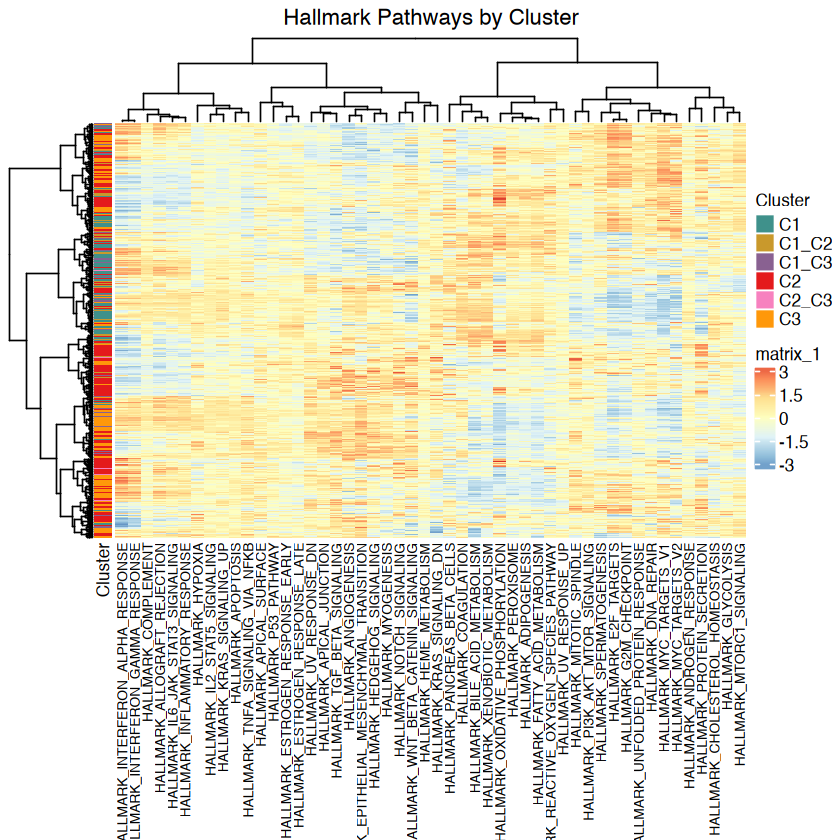

In [22]:
library(ggplot2)
library(dplyr)
library(tidyr)
library(pheatmap)
library(ComplexHeatmap)
library(RColorBrewer)
library(patchwork) # 用于组合图表

# 假设您已经有了ssgsea_res.df，其中包含所有Hallmark通路的得分和聚类信息
# ssgsea_res.df的每一行是一个样本，每一列是一个Hallmark通路得分，最后一列是cluster

# 将聚类列转换为因子
gsva_res$cluster <- as.factor(gsva_res$cluster)

#==============================================
# 方法1: 使用热图显示所有样本的所有通路得分
#==============================================

# 准备热图数据
pathway_columns <- setdiff(colnames(gsva_res), "cluster")
heatmap_data <- gsva_res[, pathway_columns]
row_annotation <- data.frame(Cluster = gsva_res$cluster)
rownames(row_annotation) <- rownames(heatmap_data)

# 使用pheatmap创建热图
pheatmap(
  heatmap_data,
  annotation_row = row_annotation,
  scale = "row",  # 对行进行z-score标准化
  clustering_method = "ward.D2",
  clustering_distance_rows = "correlation",
  clustering_distance_cols = "correlation",
  show_rownames = FALSE,  # 如果样本太多，不显示行名
  fontsize_col = 8,
  main = "Hallmark Pathways by Cluster",
  annotation_colors = list(
    Cluster = setNames(
      colorRampPalette(brewer.pal(8, "Set1"))(length(unique(gsva_res$cluster))),
      unique(gsva_res$cluster)
    )
  )
)

Warning message:
"The input is a data frame, convert it to the matrix."


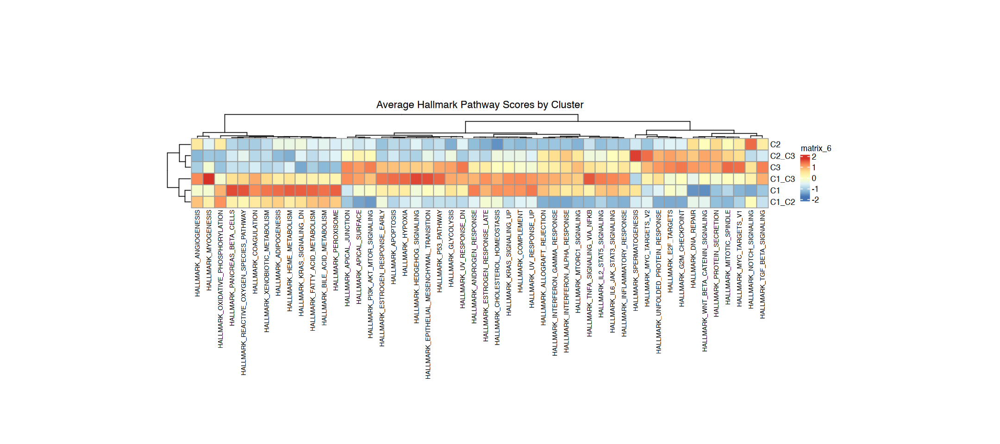

In [45]:
#==============================================
# 方法2: 每个聚类的通路平均得分热图
#==============================================

# 计算每个聚类中每个通路的平均得分
cluster_means <- gsva_res %>%
  group_by(cluster) %>%
  summarise(across(all_of(pathway_columns), mean)) %>%
  as.data.frame()

rownames(cluster_means) <- cluster_means$cluster
cluster_means$cluster <- NULL
options(repr.plot.width=18, repr.plot.height=8)
# 创建热图 - 正确的参数设置
pheatmap(
  cluster_means,
  scale = "column",  # 对列进行z-score标准化
  clustering_method = "ward.D2",
  clustering_distance_rows = "correlation",
  clustering_distance_cols = "correlation",
  main = "Average Hallmark Pathway Scores by Cluster",
  fontsize_col = 8,
  # 设置显示参数，调整列标签的可读性
  cellwidth = 15,  # 单元格宽度
  cellheight = 15, # 单元格高度
  fontsize = 10,   # 文本大小
  treeheight_row = 30,  # 行聚类树高度
  treeheight_col = 30   # 列聚类树高度
)

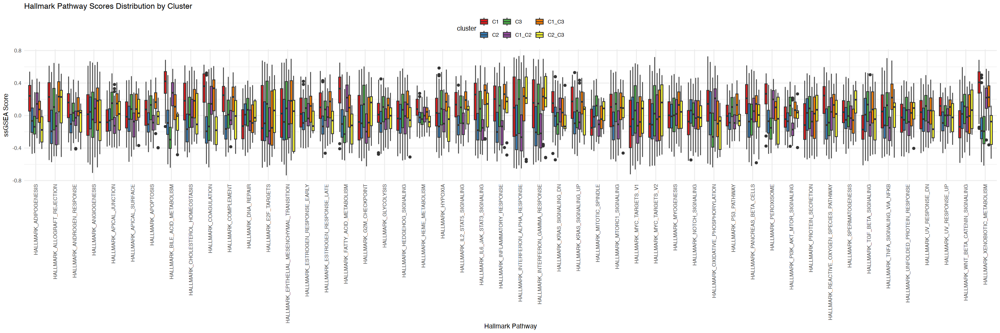

In [28]:
#==============================================
# 方法3: 箱线图展示每个聚类的通路得分分布
#==============================================

# 将数据转换为长格式
long_data <- gsva_res %>%
  pivot_longer(
    cols = all_of(pathway_columns),
    names_to = "Pathway",
    values_to = "Score"
  )
options(repr.plot.width=24, repr.plot.height=8)
long_data$cluster <- factor(long_data$cluster, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))
# 创建箱线图
ggplot(long_data, aes(x = Pathway, y = Score, fill = cluster)) +
  geom_boxplot() +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
    legend.position = "top"
  ) +
  labs(
    title = "Hallmark Pathway Scores Distribution by Cluster",
    x = "Hallmark Pathway",
    y = "ssGSEA Score"
  ) +
  scale_fill_brewer(palette = "Set1")

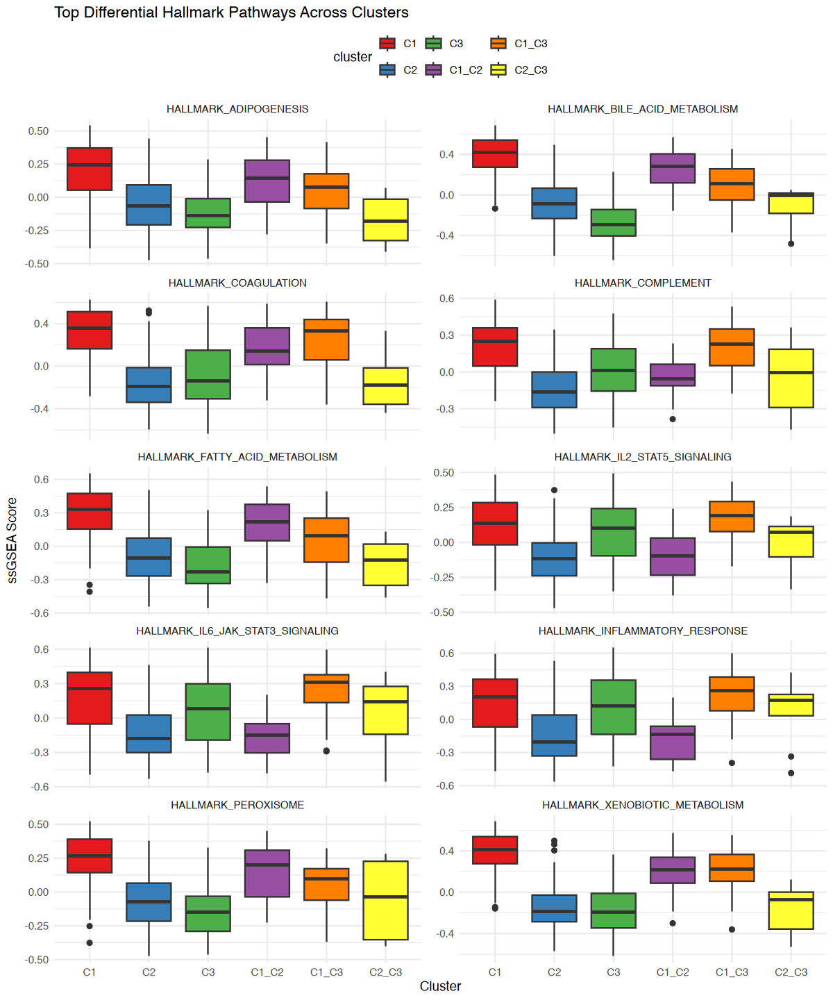

In [32]:
#==============================================
# 方法4: 每个通路单独的箱线图(面板)
#==============================================

# 为每个通路创建一个单独的箱线图
# 可能通路太多，所以选择一部分最有差异的通路
options(repr.plot.width=10, repr.plot.height=12)
# 计算哪些通路在不同聚类间差异最大（使用ANOVA）
pathway_pvalues <- sapply(pathway_columns, function(pathway) {
  model <- aov(as.formula(paste(pathway, "~ cluster")), data = gsva_res)
  summary(model)[[1]]["Pr(>F)"][[1]][1]
})

# 选择p值最小的前10个通路（差异最显著的）
top_pathways <- names(sort(pathway_pvalues))[1:min(10, length(pathway_pvalues))]

# 为top_pathways创建子集长格式数据
top_long_data <- long_data %>%
  filter(Pathway %in% top_pathways)

# 创建分面箱线图
ggplot(top_long_data, aes(x = cluster, y = Score, fill = cluster)) +
  geom_boxplot() +
  facet_wrap(~ Pathway, scales = "free_y", ncol = 2) +
  theme_minimal() +
  theme(
    legend.position = "top",
    strip.text = element_text(face = "bold")
  ) +
  labs(
    title = "Top Differential Hallmark Pathways Across Clusters",
    x = "Cluster",
    y = "ssGSEA Score"
  ) +
  scale_fill_brewer(palette = "Set1")

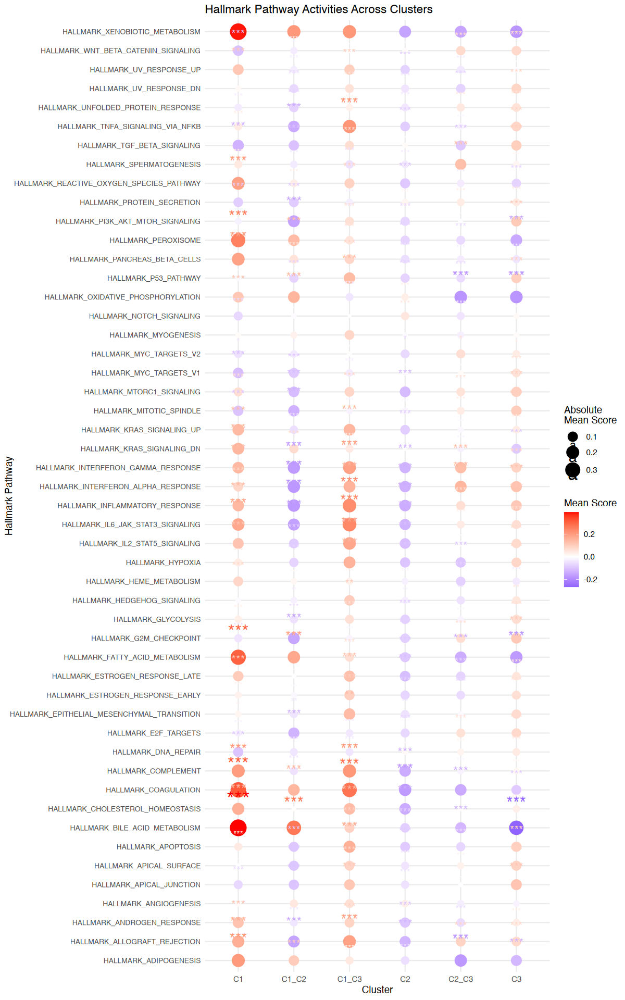

In [34]:
#==============================================
# 方法5: 气泡图展示通路活性
#==============================================
options(repr.plot.width=10, repr.plot.height=16)
# 计算每个聚类中每个通路的平均得分和显著性
pathway_stats <- data.frame()

for (pathway in pathway_columns) {
  # 执行ANOVA检验
  model <- aov(as.formula(paste(pathway, "~ cluster")), data = gsva_res)
  p_value <- summary(model)[[1]]["Pr(>F)"][[1]][1]
  
  # 计算每个聚类的平均得分
  means_by_cluster <- gsva_res %>%
    group_by(cluster) %>%
    summarise(mean_score = mean(!!sym(pathway))) %>%
    mutate(pathway = pathway, p_value = p_value)
  
  pathway_stats <- rbind(pathway_stats, means_by_cluster)
}

# 调整p值以控制多重检验
pathway_stats$adj_p_value <- p.adjust(pathway_stats$p_value, method = "BH")
pathway_stats$significance <- ifelse(pathway_stats$adj_p_value < 0.05, "*", "")
pathway_stats$significance[pathway_stats$adj_p_value < 0.01] <- "**"
pathway_stats$significance[pathway_stats$adj_p_value < 0.001] <- "***"

# 创建气泡图
ggplot(pathway_stats, aes(x = cluster, y = pathway, size = abs(mean_score), color = mean_score)) +
  geom_point() +
  geom_text(aes(label = significance), vjust = -1.5) +
  scale_color_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  scale_size(range = c(1, 8)) +
  theme_minimal() +
  theme(
    axis.text.y = element_text(size = 8),
    legend.position = "right"
  ) +
  labs(
    title = "Hallmark Pathway Activities Across Clusters",
    x = "Cluster",
    y = "Hallmark Pathway",
    color = "Mean Score",
    size = "Absolute\nMean Score"
  )

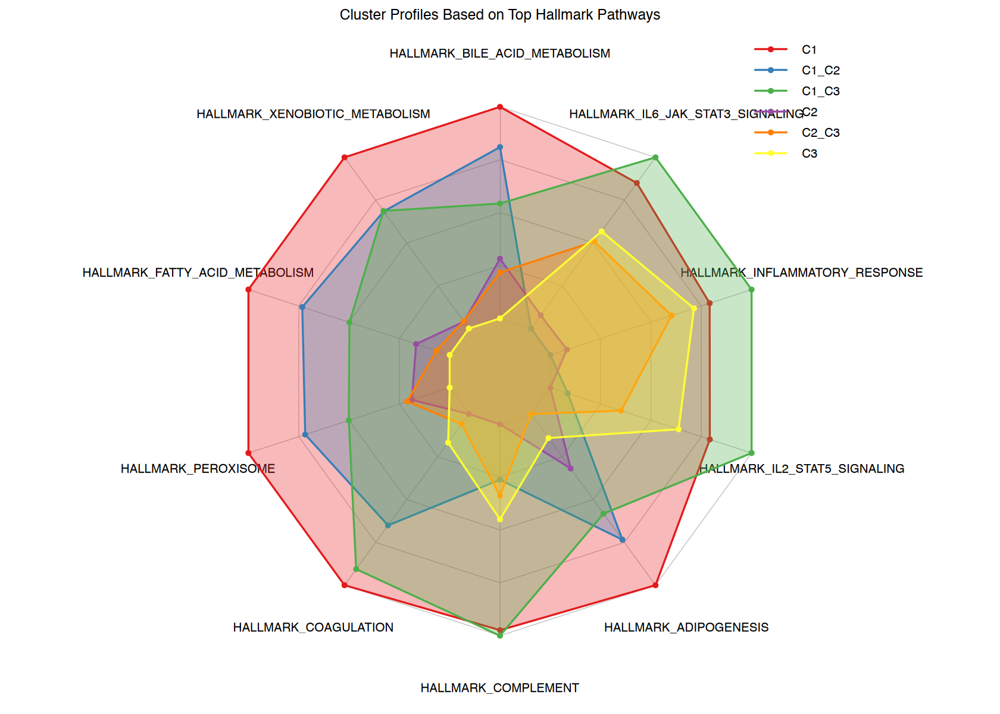

In [39]:
#==============================================
# 方法6: 雷达图展示聚类特征
#==============================================
options(repr.plot.width=14, repr.plot.height=10)
# 使用前5或10个最有差异的通路创建雷达图
library(fmsb)

# 选择top_pathways数量
n_top <- min(10, length(pathway_pvalues))
top_pathways <- names(sort(pathway_pvalues))[1:n_top]

# 为雷达图准备数据
radar_data <- cluster_means[, top_pathways, drop = FALSE]
# 添加最大最小值行
radar_data <- rbind(
  apply(radar_data, 2, max),  # 最大值行
  apply(radar_data, 2, min),  # 最小值行
  radar_data
)

# 创建雷达图
colors <- brewer.pal(nrow(radar_data) - 2, "Set1")
par(mar = c(0, 0, 2, 0))  # 调整边距

radarchart(
  radar_data,
  pcol = colors,
  pfcol = sapply(colors, function(col) adjustcolor(col, alpha.f = 0.3)),
  plwd = 2,
  plty = 1,
  cglcol = "grey",
  cglty = 1,
  axislabcol = "grey20",
  caxislabels = seq(min(radar_data[1:2,]), max(radar_data[1:2,]), length.out = 5),
  cglwd = 0.8,
  title = "Cluster Profiles Based on Top Hallmark Pathways"
)

# 添加图例
legend(
  "topright",
  legend = rownames(radar_data)[-c(1,2)],
  col = colors,
  lty = 1,
  lwd = 2,
  pch = 16,
  bty = "n"
)

Heatmap dimensions: 15 5 
Number of unique pathways: 15 
Number of unique clusters: 5 
Range of effect sizes: 0.2248351 2.049496 
# A tibble: 22 x 5
   cluster pathway                            effect_size  p_value adj_p_value
   <chr>   <chr>                                    <dbl>    <dbl>       <dbl>
 1 C1      HALLMARK_XENOBIOTIC_METABOLISM           2.05  2.19e-58    3.28e-56
 2 C1      HALLMARK_BILE_ACID_METABOLISM            2.01  4.50e-59    1.35e-56
 3 C1      HALLMARK_FATTY_ACID_METABOLISM           1.64  1.61e-38    9.68e-37
 4 C1      HALLMARK_PEROXISOME                      1.63  9.90e-39    7.42e-37
 5 C1      HALLMARK_COAGULATION                     1.44  1.69e-36    8.44e-35
 6 C1_C2   HALLMARK_BILE_ACID_METABOLISM            0.967 2.81e-12    1.84e-11
 7 C1_C2   HALLMARK_XENOBIOTIC_METABOLISM           0.776 2.31e- 8    1.04e- 7
 8 C1_C2   HALLMARK_FATTY_ACID_METABOLISM           0.725 6.45e- 6    1.95e- 5
 9 C1_C2   HALLMARK_PEROXISOME                      0.685 2.4

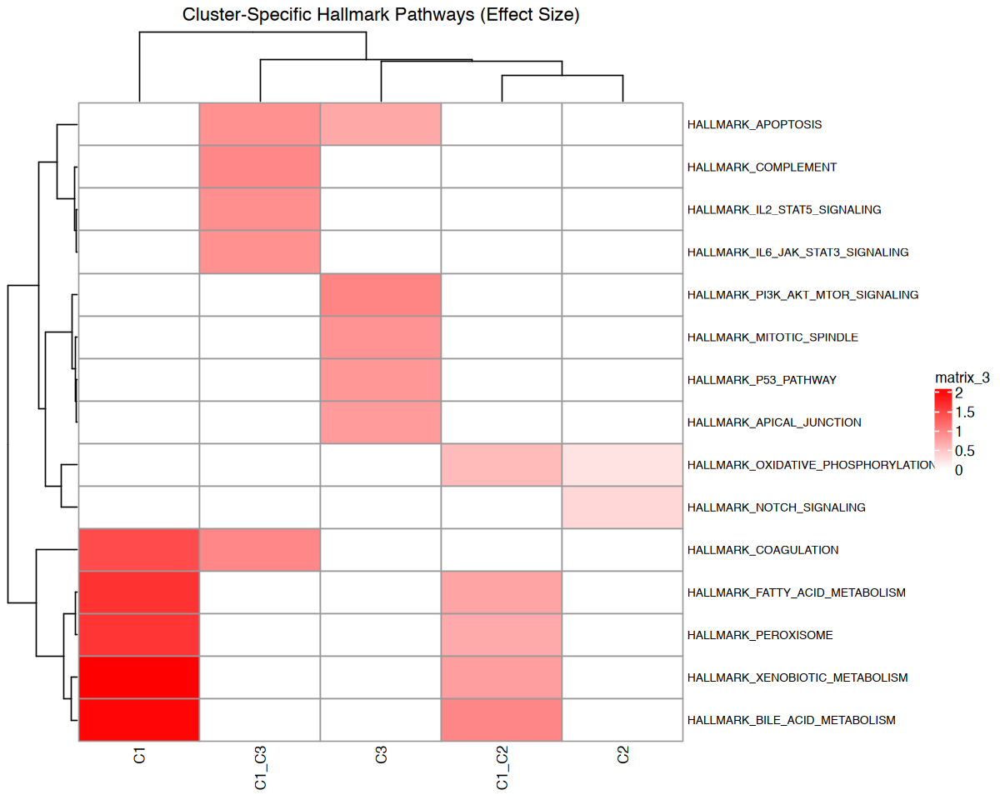

In [41]:
#==============================================
# 方法7: 聚类特异性通路富集热图（增强版）
#==============================================
options(repr.plot.width=10, repr.plot.height=8)
# 找出每个聚类特异的通路（哪些通路在某个聚类中显著高于其他聚类）
library(rstatix)

# 假设gsva_res包含通路得分和聚类信息
# 获取pathway列名（所有非聚类和非辅助列）
pathway_columns <- setdiff(colnames(gsva_res), c("cluster", "is_cluster"))

# 为每个聚类找出显著特异的通路
cluster_specific_pathways <- data.frame()

for (cl in unique(gsva_res$cluster)) {
  # 创建比较列
  gsva_res$is_cluster <- ifelse(gsva_res$cluster == cl, "Yes", "No")
  
  # 对每个通路进行t检验
  for (pathway in pathway_columns) {
    # 获取当前组和其他组的数据
    group_data <- gsva_res[gsva_res$is_cluster == "Yes", pathway]
    other_data <- gsva_res[gsva_res$is_cluster == "No", pathway]
    
    # 移除NA值
    group_data <- group_data[!is.na(group_data)]
    other_data <- other_data[!is.na(other_data)]
    
    # 检查数据是否足够进行t检验
    if (length(group_data) < 2 || length(other_data) < 2) {
      # 如果样本太少，跳过这个通路
      next
    }
    
    # 检查数据是否有变异
    if (var(group_data) == 0 || var(other_data) == 0) {
      # 如果任一组数据完全相同（无变异），跳过
      next
    }
    
    # 使用tryCatch进行t检验
    t_test_result <- tryCatch({
      t.test(group_data, other_data)
    }, error = function(e) {
      # 如果t检验失败，返回NULL
      return(NULL)
    })
    
    # 如果t检验成功，计算效应量并添加到结果
    if (!is.null(t_test_result)) {
      mean_diff <- t_test_result$estimate[1] - t_test_result$estimate[2]
      
      # 计算效应量（Cohen's d）
      # 使用更稳健的计算方法
      n1 <- length(group_data)
      n2 <- length(other_data)
      s1 <- var(group_data)
      s2 <- var(other_data)
      
      # 计算合并标准差
      pooled_sd <- sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
      
      # 如果pooled_sd为0或NA，则跳过
      if (is.na(pooled_sd) || pooled_sd == 0) {
        next
      }
      
      effect_size <- mean_diff / pooled_sd
      
      cluster_specific_pathways <- rbind(
        cluster_specific_pathways,
        data.frame(
          cluster = cl,
          pathway = pathway,
          p_value = t_test_result$p.value,
          effect_size = effect_size,
          mean_diff = mean_diff,
          n_cluster = n1,
          n_other = n2
        )
      )
    }
  }
}

# 如果结果为空，提供信息并停止
if (nrow(cluster_specific_pathways) == 0) {
  stop("No valid pathway comparisons could be made. Check your data for NA values or lack of variation.")
}

# 调整p值
cluster_specific_pathways$adj_p_value <- p.adjust(cluster_specific_pathways$p_value, method = "BH")

# 找出每个聚类中最显著的通路（p值小，效应量大且为正）
# 先检查是否有显著的通路
if (sum(cluster_specific_pathways$adj_p_value < 0.05 & cluster_specific_pathways$effect_size > 0) == 0) {
  cat("No pathways meet significance criteria (adj_p_value < 0.05 and effect_size > 0).\n")
  cat("Using top pathways by effect size instead.\n")
  
  # 如果没有显著通路，选择每个聚类中效应量最大的通路
  significant_pathways <- cluster_specific_pathways %>%
    filter(effect_size > 0) %>%  # 仍然要求效应量为正
    group_by(cluster) %>%
    arrange(desc(effect_size)) %>%
    slice_head(n = 5) %>%  # 每个聚类取前5个
    ungroup()
} else {
  # 使用原来的过滤方法
  significant_pathways <- cluster_specific_pathways %>%
    filter(adj_p_value < 0.05, effect_size > 0) %>%
    group_by(cluster) %>%
    arrange(desc(effect_size)) %>%
    slice_head(n = 5) %>%  # 每个聚类取前5个
    ungroup()
}

# 如果结果为空，提供信息并停止
if (nrow(significant_pathways) == 0) {
  stop("No significant pathways found with positive effect size.")
}

# 创建热图数据
# 先检查是否有足够的通路和聚类
unique_pathways <- unique(significant_pathways$pathway)
unique_clusters <- unique(significant_pathways$cluster)

if (length(unique_pathways) == 0 || length(unique_clusters) == 0) {
  stop("Not enough unique pathways or clusters for heatmap.")
}

sig_heatmap_data <- matrix(0, 
                         nrow = length(unique_pathways),
                         ncol = length(unique_clusters))

rownames(sig_heatmap_data) <- unique_pathways
colnames(sig_heatmap_data) <- unique_clusters

# 填充热图数据
for (i in 1:nrow(significant_pathways)) {
  pathway <- significant_pathways$pathway[i]
  cluster <- significant_pathways$cluster[i]
  
  row_idx <- which(rownames(sig_heatmap_data) == pathway)
  col_idx <- which(colnames(sig_heatmap_data) == cluster)
  
  # 检查索引是否有效
  if (length(row_idx) > 0 && length(col_idx) > 0) {
    sig_heatmap_data[row_idx, col_idx] <- significant_pathways$effect_size[i]
  }
}

# 在绘制热图前，检查数据
if (all(sig_heatmap_data == 0)) {
  stop("Heatmap data is all zeros. Check your filtering criteria.")
}

# 打印一些统计信息，帮助诊断
cat("Heatmap dimensions:", dim(sig_heatmap_data), "\n")
cat("Number of unique pathways:", length(unique_pathways), "\n")
cat("Number of unique clusters:", length(unique_clusters), "\n")
cat("Range of effect sizes:", range(significant_pathways$effect_size), "\n")

# 创建热图
pheatmap(
  sig_heatmap_data,
  color = colorRampPalette(c("white", "red"))(100),
  cluster_rows = TRUE,
  cluster_cols = TRUE,
  fontsize_row = 8,
  fontsize_col = 10,
  main = "Cluster-Specific Hallmark Pathways (Effect Size)"
)

# 可选：如果热图创建失败，尝试使用更简单的热图函数
if (FALSE) {  # 设为TRUE以启用备选方案
  heatmap(
    sig_heatmap_data,
    col = colorRampPalette(c("white", "red"))(100),
    main = "Cluster-Specific Hallmark Pathways (Effect Size)"
  )
}

# 额外：输出主要结果表格，便于查看
top_results <- significant_pathways %>%
  select(cluster, pathway, effect_size, p_value, adj_p_value) %>%
  arrange(cluster, desc(effect_size))

print(top_results)

### KEGG gsva

In [13]:
library(GSVA)
library(dplyr)
library(tibble)
library(tidyr)
library(BiocParallel)

# 读取KEGG通路数据
KEGG <- read.csv(file = "/Users/luye/Data/Sig/hsaMetaGenes.csv")

# 检查数据结构
head(KEGG)

# 根据通路名称分组并创建基因集列表
kegg_pathways <- KEGG %>%
  # 从通路名称中提取纯KEGG通路名称(去掉 "- Homo sapiens (human)" 部分)
  mutate(clean_pathway = gsub(" - Homo sapiens \\(human\\)$", "", Pathways)) %>%
  # 按通路名称分组
  group_by(clean_pathway) %>%
  # 收集每个通路的基因符号列表
  summarise(genes = list(Symbol), .groups = "drop")

# 创建KEGG基因集列表(格式与GSVA兼容)
kegg_gene_sets <- setNames(kegg_pathways$genes, kegg_pathways$clean_pathway)

# 检查一些KEGG通路的基因数
kegg_sizes <- sapply(kegg_gene_sets, length)
head(sort(kegg_sizes, decreasing = TRUE))
cat("KEGG通路数量:", length(kegg_gene_sets), "\n")

# 使用新的API创建gsvaParam对象
# 首先检查gsvaParam的可用参数
args(gsvaParam)

# 创建gsvaParam对象，只使用支持的参数
params <- gsvaParam(
  expr = as.matrix(expr_mat),
  geneSets = kegg_gene_sets,
  minSize = 3,        # 每个基因集的最小基因数
  maxSize = Inf,      # 每个基因集的最大基因数
  kcdf = "Gaussian", tau=1,maxDiff = TRUE,
  absRanking = FALSE  # 注意这里是absRanking而不是abs.ranking
)

# 执行GSVA分析
gsva_res <- gsva(
  params,
  verbose = TRUE,
  BPPARAM = BiocParallel::SerialParam(progressbar = TRUE)
)

# 转换结果为数据框并添加聚类信息
gsva_res <- as.data.frame(t(gsva_res))
gsva_res$cluster <- cluster_vec

# 保存结果
write.csv(gsva_res, "KEGG_GSVA_scores.csv")


Attaching package: 'dplyr'


The following object is masked from 'package:AnnotationDbi':

    select


The following objects are masked from 'package:IRanges':

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from 'package:S4Vectors':

    first, intersect, rename, setdiff, setequal, union


The following object is masked from 'package:Biobase':

    combine


The following objects are masked from 'package:BiocGenerics':

    combine, intersect, setdiff, union


The following object is masked from 'package:nlme':

    collapse


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union



Attaching package: 'tidyr'


The following objects are masked from 'package:Matrix':

    expand, pack, unpack


The following object is masked from 'package:S4Vectors':

    expand




,Pathways,Entrez,Symbol
,<chr>,<int>,<chr>
1,Glycolysis / Gluconeogenesis - Homo sapiens (human),3101,HK3
2,Glycolysis / Gluconeogenesis - Homo sapiens (human),3098,HK1
3,Glycolysis / Gluconeogenesis - Homo sapiens (human),3099,HK2
4,Glycolysis / Gluconeogenesis - Homo sapiens (human),80201,HKDC1
5,Glycolysis / Gluconeogenesis - Homo sapiens (human),2645,GCK
6,Glycolysis / Gluconeogenesis - Homo sapiens (human),2821,GPI


Oxidative phosphorylation 
                                         136 
                           Purine metabolism 
                                         128 
              Glycerophospholipid metabolism 
                                         102 
             Drug metabolism - other enzymes 
                                          81 
Metabolism of xenobiotics by cytochrome P450 
                                          78 
               Inositol phosphate metabolism 
                                          73

KEGG<U+901A><U+8DEF><U+6570><U+91CF>: 84 


function (exprData, geneSets, assay = NA_character_, annotation = NA_character_, 
    minSize = 1, maxSize = Inf, kcdf = c("Gaussian", "Poisson", 
        "none"), tau = 1, maxDiff = TRUE, absRanking = FALSE) 
NULL

Estimating GSVA scores for 82 gene sets.
Estimating ECDFs with Gaussian kernels
  |======================================================================| 100%



Loading required package: grid

ComplexHeatmap version 2.25.2
Bioconductor page: http://bioconductor.org/packages/ComplexHeatmap/
Github page: https://github.com/jokergoo/ComplexHeatmap
Documentation: http://jokergoo.github.io/ComplexHeatmap-reference

If you use it in published research, please cite either one:
- Gu, Z. Complex Heatmap Visualization. iMeta 2022.
- Gu, Z. Complex heatmaps reveal patterns and correlations in multidimensional 
    genomic data. Bioinformatics 2016.


The new InteractiveComplexHeatmap package can directly export static 
complex heatmaps into an interactive Shiny app with zero effort. Have a try!

This message can be suppressed by:
  suppressPackageStartupMessages(library(ComplexHeatmap))
! pheatmap() has been masked by ComplexHeatmap::pheatmap(). Most of the arguments
   in the original pheatmap() are identically supported in the new function. You 
   can still use the original function by explicitly calling pheatmap::pheatmap().



Attaching package: 'Co

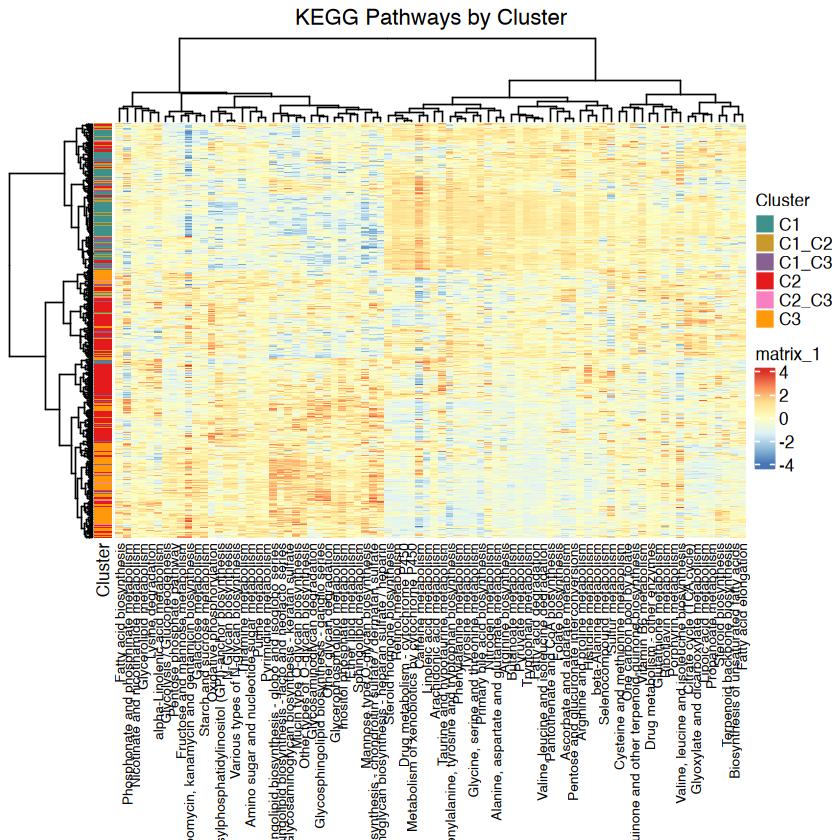

In [14]:
library(ggplot2)
library(dplyr)
library(tidyr)
library(pheatmap)
library(ComplexHeatmap)
library(RColorBrewer)
library(patchwork) # 用于组合图表

# 假设您已经有了ssgsea_res.df，其中包含所有Hallmark通路的得分和聚类信息
# ssgsea_res.df的每一行是一个样本，每一列是一个Hallmark通路得分，最后一列是cluster

# 将聚类列转换为因子
gsva_res$cluster <- as.factor(gsva_res$cluster)

#==============================================
# 方法1: 使用热图显示所有样本的所有通路得分
#==============================================

# 准备热图数据
pathway_columns <- setdiff(colnames(gsva_res), "cluster")
heatmap_data <- gsva_res[, pathway_columns]
row_annotation <- data.frame(Cluster = gsva_res$cluster)
rownames(row_annotation) <- rownames(heatmap_data)

# 使用pheatmap创建热图
pheatmap(
  heatmap_data,
  annotation_row = row_annotation,
  scale = "row",  # 对行进行z-score标准化
  clustering_method = "ward.D2",
  clustering_distance_rows = "correlation",
  clustering_distance_cols = "correlation",
  show_rownames = FALSE,  # 如果样本太多，不显示行名
  fontsize_col = 8,
  main = "KEGG Pathways by Cluster",
  annotation_colors = list(
    Cluster = setNames(
      colorRampPalette(brewer.pal(8, "Set1"))(length(unique(gsva_res$cluster))),
      unique(gsva_res$cluster)
    )
  )
)

Warning message:
"The input is a data frame, convert it to the matrix."


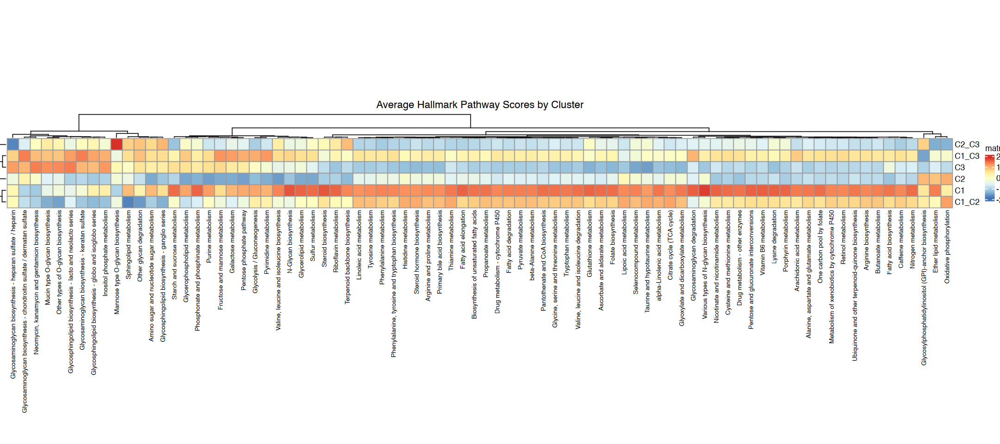

In [15]:
#==============================================
# 方法2: 每个聚类的通路平均得分热图
#==============================================

# 计算每个聚类中每个通路的平均得分
cluster_means <- gsva_res %>%
  group_by(cluster) %>%
  summarise(across(all_of(pathway_columns), mean)) %>%
  as.data.frame()

rownames(cluster_means) <- cluster_means$cluster
cluster_means$cluster <- NULL
options(repr.plot.width=18, repr.plot.height=8)
# 创建热图 - 正确的参数设置
pheatmap(
  cluster_means,
  scale = "column",  # 对列进行z-score标准化
  clustering_method = "ward.D2",
  clustering_distance_rows = "correlation",
  clustering_distance_cols = "correlation",
  main = "Average Hallmark Pathway Scores by Cluster",
  fontsize_col = 8,
  # 设置显示参数，调整列标签的可读性
  cellwidth = 15,  # 单元格宽度
  cellheight = 15, # 单元格高度
  fontsize = 10,   # 文本大小
  treeheight_row = 30,  # 行聚类树高度
  treeheight_col = 30   # 列聚类树高度
)

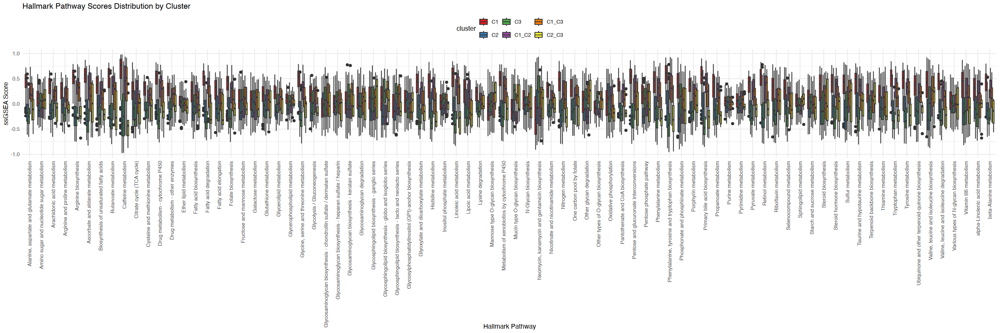

In [16]:
#==============================================
# 方法3: 箱线图展示每个聚类的通路得分分布
#==============================================

# 将数据转换为长格式
long_data <- gsva_res %>%
  pivot_longer(
    cols = all_of(pathway_columns),
    names_to = "Pathway",
    values_to = "Score"
  )
options(repr.plot.width=24, repr.plot.height=8)
long_data$cluster <- factor(long_data$cluster, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))
# 创建箱线图
ggplot(long_data, aes(x = Pathway, y = Score, fill = cluster)) +
  geom_boxplot() +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
    legend.position = "top"
  ) +
  labs(
    title = "Hallmark Pathway Scores Distribution by Cluster",
    x = "Hallmark Pathway",
    y = "ssGSEA Score"
  ) +
  scale_fill_brewer(palette = "Set1")


Attaching package: 'rstatix'


The following object is masked from 'package:AnnotationDbi':

    select


The following object is masked from 'package:IRanges':

    desc


The following object is masked from 'package:genefilter':

    Anova


The following object is masked from 'package:stats':

    filter




Heatmap dimensions: 19 6 
Number of unique pathways: 19 
Number of unique clusters: 6 
Range of effect sizes: 0.376557 2.059973 
# A tibble: 23 x 5
   cluster pathway                              effect_size  p_value adj_p_value
   <chr>   <chr>                                      <dbl>    <dbl>       <dbl>
 1 C1      Tryptophan metabolism                      2.06  3.10e-66    7.63e-64
 2 C1      Glycine, serine and threonine metab~       2.00  1.46e-61    1.43e-59
 3 C1      Arginine biosynthesis                      1.99  1.82e-63    2.99e-61
 4 C1      Alanine, aspartate and glutamate me~       1.99  1.04e-59    5.71e-58
 5 C1      Fatty acid degradation                     1.99  2.65e-60    2.18e-58
 6 C1_C2   Arginine biosynthesis                      0.952 5.78e-12    2.16e-11
 7 C1_C2   Linoleic acid metabolism                   0.951 1.74e-11    6.29e-11
 8 C1_C2   Primary bile acid biosynthesis             0.942 2.19e-11    7.82e-11
 9 C1_C2   beta-Alanine metabolism        

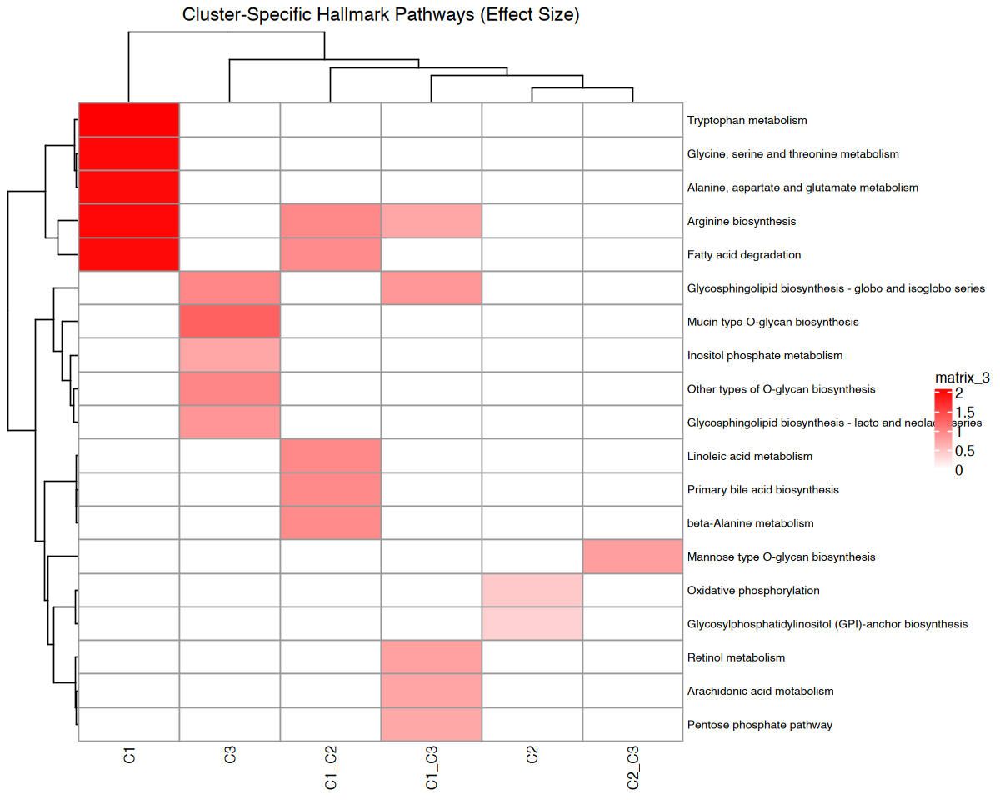

In [21]:
#==============================================
# 方法7: 聚类特异性通路富集热图（增强版）
#==============================================
options(repr.plot.width=10, repr.plot.height=8)
# 找出每个聚类特异的通路（哪些通路在某个聚类中显著高于其他聚类）
library(rstatix)

# 假设gsva_res包含通路得分和聚类信息
# 获取pathway列名（所有非聚类和非辅助列）
pathway_columns <- setdiff(colnames(gsva_res), c("cluster", "is_cluster"))

# 为每个聚类找出显著特异的通路
cluster_specific_pathways <- data.frame()

for (cl in unique(gsva_res$cluster)) {
  # 创建比较列
  gsva_res$is_cluster <- ifelse(gsva_res$cluster == cl, "Yes", "No")
  
  # 对每个通路进行t检验
  for (pathway in pathway_columns) {
    # 获取当前组和其他组的数据
    group_data <- gsva_res[gsva_res$is_cluster == "Yes", pathway]
    other_data <- gsva_res[gsva_res$is_cluster == "No", pathway]
    
    # 移除NA值
    group_data <- group_data[!is.na(group_data)]
    other_data <- other_data[!is.na(other_data)]
    
    # 检查数据是否足够进行t检验
    if (length(group_data) < 2 || length(other_data) < 2) {
      # 如果样本太少，跳过这个通路
      next
    }
    
    # 检查数据是否有变异
    if (var(group_data) == 0 || var(other_data) == 0) {
      # 如果任一组数据完全相同（无变异），跳过
      next
    }
    
    # 使用tryCatch进行t检验
    t_test_result <- tryCatch({
      t.test(group_data, other_data)
    }, error = function(e) {
      # 如果t检验失败，返回NULL
      return(NULL)
    })
    
    # 如果t检验成功，计算效应量并添加到结果
    if (!is.null(t_test_result)) {
      mean_diff <- t_test_result$estimate[1] - t_test_result$estimate[2]
      
      # 计算效应量（Cohen's d）
      # 使用更稳健的计算方法
      n1 <- length(group_data)
      n2 <- length(other_data)
      s1 <- var(group_data)
      s2 <- var(other_data)
      
      # 计算合并标准差
      pooled_sd <- sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
      
      # 如果pooled_sd为0或NA，则跳过
      if (is.na(pooled_sd) || pooled_sd == 0) {
        next
      }
      
      effect_size <- mean_diff / pooled_sd
      
      cluster_specific_pathways <- rbind(
        cluster_specific_pathways,
        data.frame(
          cluster = cl,
          pathway = pathway,
          p_value = t_test_result$p.value,
          effect_size = effect_size,
          mean_diff = mean_diff,
          n_cluster = n1,
          n_other = n2
        )
      )
    }
  }
}

# 如果结果为空，提供信息并停止
if (nrow(cluster_specific_pathways) == 0) {
  stop("No valid pathway comparisons could be made. Check your data for NA values or lack of variation.")
}

# 调整p值
cluster_specific_pathways$adj_p_value <- p.adjust(cluster_specific_pathways$p_value, method = "BH")

# 找出每个聚类中最显著的通路（p值小，效应量大且为正）
# 先检查是否有显著的通路
if (sum(cluster_specific_pathways$adj_p_value < 0.05 & cluster_specific_pathways$effect_size > 0) == 0) {
  cat("No pathways meet significance criteria (adj_p_value < 0.05 and effect_size > 0).\n")
  cat("Using top pathways by effect size instead.\n")
  
  # 如果没有显著通路，选择每个聚类中效应量最大的通路
  significant_pathways <- cluster_specific_pathways %>%
    filter(effect_size > 0) %>%  # 仍然要求效应量为正
    group_by(cluster) %>%
    arrange(desc(effect_size)) %>%
    slice_head(n = 5) %>%  # 每个聚类取前5个
    ungroup()
} else {
  # 使用原来的过滤方法
  significant_pathways <- cluster_specific_pathways %>%
    filter(adj_p_value < 0.05, effect_size > 0) %>%
    group_by(cluster) %>%
    arrange(desc(effect_size)) %>%
    slice_head(n = 5) %>%  # 每个聚类取前5个
    ungroup()
}

# 如果结果为空，提供信息并停止
if (nrow(significant_pathways) == 0) {
  stop("No significant pathways found with positive effect size.")
}

# 创建热图数据
# 先检查是否有足够的通路和聚类
unique_pathways <- unique(significant_pathways$pathway)
unique_clusters <- unique(significant_pathways$cluster)

if (length(unique_pathways) == 0 || length(unique_clusters) == 0) {
  stop("Not enough unique pathways or clusters for heatmap.")
}

sig_heatmap_data <- matrix(0, 
                         nrow = length(unique_pathways),
                         ncol = length(unique_clusters))

rownames(sig_heatmap_data) <- unique_pathways
colnames(sig_heatmap_data) <- unique_clusters

# 填充热图数据
for (i in 1:nrow(significant_pathways)) {
  pathway <- significant_pathways$pathway[i]
  cluster <- significant_pathways$cluster[i]
  
  row_idx <- which(rownames(sig_heatmap_data) == pathway)
  col_idx <- which(colnames(sig_heatmap_data) == cluster)
  
  # 检查索引是否有效
  if (length(row_idx) > 0 && length(col_idx) > 0) {
    sig_heatmap_data[row_idx, col_idx] <- significant_pathways$effect_size[i]
  }
}

# 在绘制热图前，检查数据
if (all(sig_heatmap_data == 0)) {
  stop("Heatmap data is all zeros. Check your filtering criteria.")
}

# 打印一些统计信息，帮助诊断
cat("Heatmap dimensions:", dim(sig_heatmap_data), "\n")
cat("Number of unique pathways:", length(unique_pathways), "\n")
cat("Number of unique clusters:", length(unique_clusters), "\n")
cat("Range of effect sizes:", range(significant_pathways$effect_size), "\n")

# 创建热图
pheatmap(
  sig_heatmap_data,
  color = colorRampPalette(c("white", "red"))(100),
  cluster_rows = TRUE,
  cluster_cols = TRUE,
  fontsize_row = 8,
  fontsize_col = 10,
  main = "Cluster-Specific Hallmark Pathways (Effect Size)"
)

# 可选：如果热图创建失败，尝试使用更简单的热图函数
if (FALSE) {  # 设为TRUE以启用备选方案
  heatmap(
    sig_heatmap_data,
    col = colorRampPalette(c("white", "red"))(100),
    main = "Cluster-Specific Hallmark Pathways (Effect Size)"
  )
}

# 额外：输出主要结果表格，便于查看
top_results <- significant_pathways %>%
  select(cluster, pathway, effect_size, p_value, adj_p_value) %>%
  arrange(cluster, desc(effect_size))

print(top_results)

### Immune gsva

In [11]:
library(GSVA)

In [ ]:
genesets <- read.csv(file = "/Users/luye/Data/Sig/28_immune_cell_markers.csv", header = T)
dim(genesets)
head(genesets)

[1] 782   3

,X...Metagene,Cell.type,Immunity
,<chr>,<chr>,<chr>
1,ADAM28,Activated B cell,Adaptive
2,CD180,Activated B cell,Adaptive
3,CD79B,Activated B cell,Adaptive
4,BLK,Activated B cell,Adaptive
5,CD19,Activated B cell,Adaptive
6,MS4A1,Activated B cell,Adaptive


In [ ]:
#构建免疫细胞Marker基因集：
gene_sets <- split(genesets$X...Metagene,genesets$Cell.type)

In [ ]:
# 获取MSigDB hallmark基因集
#msigdb <- readRDS("/Users/luye/Data/Sig/msigdb.2024.1.Hs.rds")
#cell_type_c8 <- msigdb[msigdb$gs_collection == "C8", ]
#immune_cell_keywords <- c("T CELL", "B CELL", "NK", "NEUTROPHIL", "MACROPHAGE", 
#                         "MONOCYTE", "DENDRITIC", "MAST", "EOSINOPHIL", 
#                         "BASOPHIL", "LYMPHOCYTE", "LEUKOCYTE")
#immune_cell_c8 <- cell_type_c8[grepl(paste(immune_cell_keywords, collapse="|"), 
#                                    cell_type_c8$gs_name, ignore.case=TRUE), ]
#print(paste("筛选后的免疫细胞特征数量:", nrow(immune_cell_c8)))
#gene_sets <- split(immune_cell_c8$db_gene_symbol, immune_cell_c8$gs_name)

Estimating GSVA scores for 28 gene sets.
Estimating ECDFs with Gaussian kernels
  |======================================================================| 100%



In [ ]:
# 创建ssGSEA参数对象
#创建一个参数对象
params <- gsvaParam(
    as.matrix(expr_mat), 
    gene_sets, minSize = 1, maxSize = Inf, 
    kcdf = "Gaussian", tau = 1, maxDiff = TRUE, absRanking = FALSE
    )
#执行 GSVA 分析
gsva_res <- gsva(params, verbose = TRUE, BPPARAM = BiocParallel::SerialParam(progressbar = TRUE))

# 转换结果并添加聚类信息
gsva_res <- as.data.frame(t(gsva_res))
gsva_res$cluster <- cluster_vec
#gsva_res <- rownames_to_column(gsva_res,"Sample")

In [15]:
dim(gsva_res)
head(gsva_res)

[1] 586  29

,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,...,Natural killer T cell,Natural killer cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell,cluster
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
GSM2883928,-0.2394006,-0.0026618749,0.01456230,-0.2335350,-0.15742309,-0.343950282,0.07275189,0.04944621,0.09228806,-0.1709095,...,0.005236663,0.2201243,-0.187065216,-0.13546210,-0.1449848,-0.3463892,-0.066670465,-0.48821708,-0.1203673,C2
GSM2883929,0.1744114,0.3109498768,0.54605205,-0.2566245,-0.11729152,-0.378075631,-0.16055814,0.01178366,-0.15075918,-0.2782593,...,-0.174672731,-0.2194795,-0.002938651,-0.05704737,0.2499699,-0.1003263,0.009336396,0.07675442,-0.2592483,C1
GSM2883930,0.2117506,-0.1580108283,0.27184882,0.4767805,0.35859428,0.613527032,0.31097423,0.29236471,-0.26004192,0.3825812,...,-0.106307536,0.3945074,0.418438683,0.21502291,-0.1158498,0.3723167,0.265230006,0.24574000,0.0290356,C1_C3
GSM2883931,-0.1758864,0.4375917252,0.16580953,0.3814821,0.19264932,0.004619497,0.27007507,0.20200799,0.55054655,0.6076768,...,0.257361024,0.3685456,0.282905962,0.10609682,0.4491638,0.1355324,0.305780733,-0.52871853,0.4979278,C3
GSM2883932,-0.2555774,-0.0005933704,-0.12517058,0.2568770,-0.09858825,0.052291626,0.24612735,0.07719654,0.15386599,0.4440111,...,0.229678100,0.3175852,-0.348203570,0.23209798,0.5309731,0.3524761,0.014495475,-0.05672160,0.0694789,C3
GSM2883933,-0.3176948,-0.3436650052,-0.01630111,-0.2027521,-0.07948589,-0.114724227,-0.03755576,0.01348827,0.27746958,-0.2653113,...,-0.442210923,-0.3387736,-0.389179206,0.04605076,-0.3531975,-0.1177068,-0.091688756,-0.06798788,0.1450594,C3



Attaching package: 'dplyr'


The following object is masked from 'package:AnnotationDbi':

    select


The following objects are masked from 'package:IRanges':

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from 'package:S4Vectors':

    first, intersect, rename, setdiff, setequal, union


The following object is masked from 'package:Biobase':

    combine


The following objects are masked from 'package:BiocGenerics':

    combine, intersect, setdiff, union


The following object is masked from 'package:nlme':

    collapse


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union



Attaching package: 'tidyr'


The following object is masked from 'package:S4Vectors':

    expand


Loading required package: grid

ComplexHeatmap version 2.20.0
Bioconductor page: http://bioconductor.org/packages/ComplexHeatmap/
Github page: https://

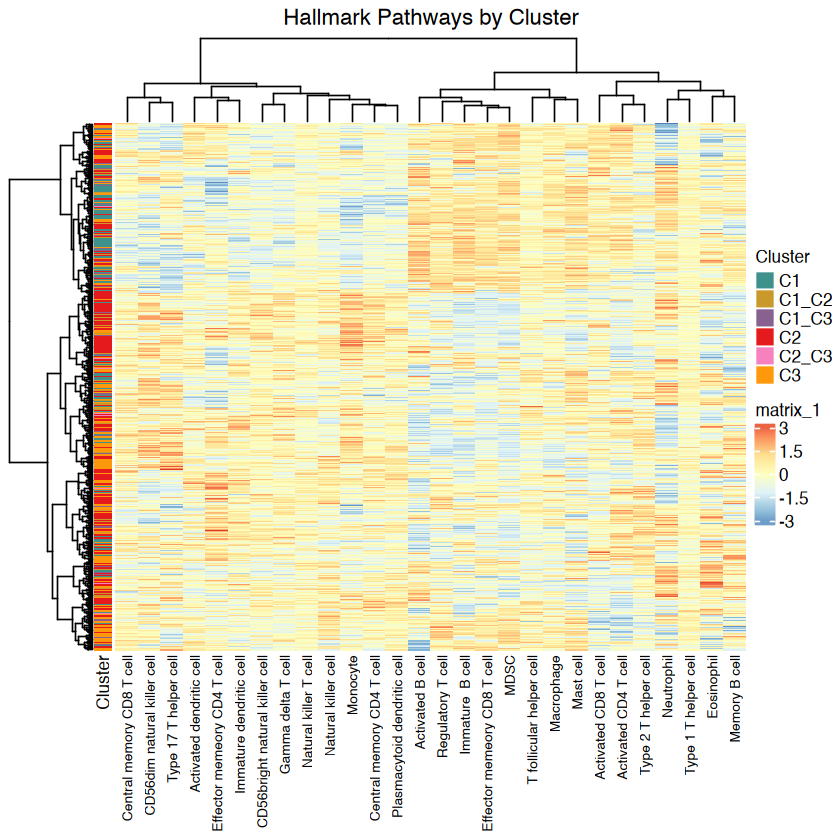

In [16]:
library(ggplot2)
library(dplyr)
library(tidyr)
library(pheatmap)
library(ComplexHeatmap)
library(RColorBrewer)
library(patchwork) # 用于组合图表

# 假设您已经有了ssgsea_res.df，其中包含所有Hallmark通路的得分和聚类信息
# ssgsea_res.df的每一行是一个样本，每一列是一个Hallmark通路得分，最后一列是cluster

# 将聚类列转换为因子
gsva_res$cluster <- as.factor(gsva_res$cluster)

#==============================================
# 方法1: 使用热图显示所有样本的所有通路得分
#==============================================

# 准备热图数据
pathway_columns <- setdiff(colnames(gsva_res), "cluster")
heatmap_data <- gsva_res[, pathway_columns]
row_annotation <- data.frame(Cluster = gsva_res$cluster)
rownames(row_annotation) <- rownames(heatmap_data)

# 使用pheatmap创建热图
pheatmap(
  heatmap_data,
  annotation_row = row_annotation,
  scale = "row",  # 对行进行z-score标准化
  clustering_method = "ward.D2",
  clustering_distance_rows = "correlation",
  clustering_distance_cols = "correlation",
  show_rownames = FALSE,  # 如果样本太多，不显示行名
  fontsize_col = 8,
  main = "Hallmark Pathways by Cluster",
  annotation_colors = list(
    Cluster = setNames(
      colorRampPalette(brewer.pal(8, "Set1"))(length(unique(gsva_res$cluster))),
      unique(gsva_res$cluster)
    )
  )
)

Warning message:
"The input is a data frame, convert it to the matrix."


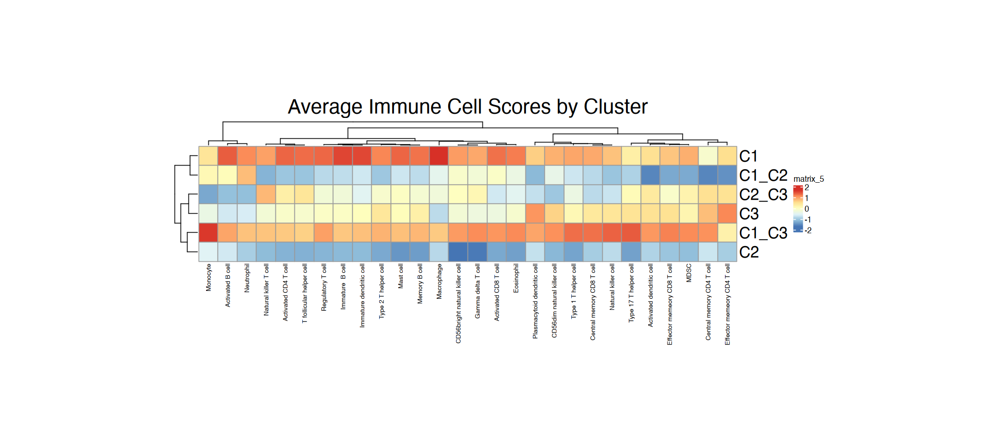

In [20]:
#==============================================
# 方法2: 每个聚类的通路平均得分热图
#==============================================

# 计算每个聚类中每个通路的平均得分
cluster_means <- gsva_res %>%
  group_by(cluster) %>%
  summarise(across(all_of(pathway_columns), mean)) %>%
  as.data.frame()

rownames(cluster_means) <- cluster_means$cluster
cluster_means$cluster <- NULL
options(repr.plot.width=18, repr.plot.height=8)
# 创建热图 - 正确的参数设置
pheatmap(
  cluster_means,
  scale = "column",  # 对列进行z-score标准化
  clustering_method = "ward.D2",
  clustering_distance_rows = "correlation",
  clustering_distance_cols = "correlation",
  main = "Average Immune Cell Scores by Cluster",
  fontsize_col = 8,
  # 设置显示参数，调整列标签的可读性
  cellwidth = 25,  # 单元格宽度
  cellheight = 25, # 单元格高度
  fontsize = 20,   # 文本大小
  treeheight_row = 30,  # 行聚类树高度
  treeheight_col = 30   # 列聚类树高度
)

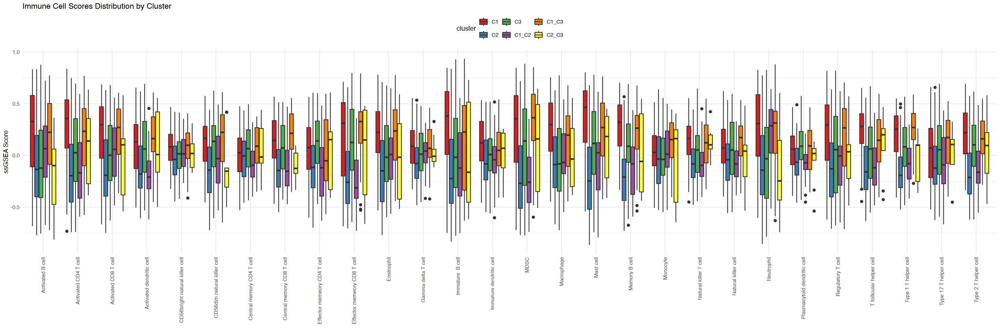

In [22]:
#==============================================
# 方法3: 箱线图展示每个聚类的通路得分分布
#==============================================

# 将数据转换为长格式
long_data <- gsva_res %>%
  pivot_longer(
    cols = all_of(pathway_columns),
    names_to = "Pathway",
    values_to = "Score"
  )
options(repr.plot.width=24, repr.plot.height=8)
long_data$cluster <- factor(long_data$cluster, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))
# 创建箱线图
ggplot(long_data, aes(x = Pathway, y = Score, fill = cluster)) +
  geom_boxplot() +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
    legend.position = "top"
  ) +
  labs(
    title = "Immune Cell Scores Distribution by Cluster",
    x = " ",
    y = "ssGSEA Score"
  ) +
  scale_fill_brewer(palette = "Set1")

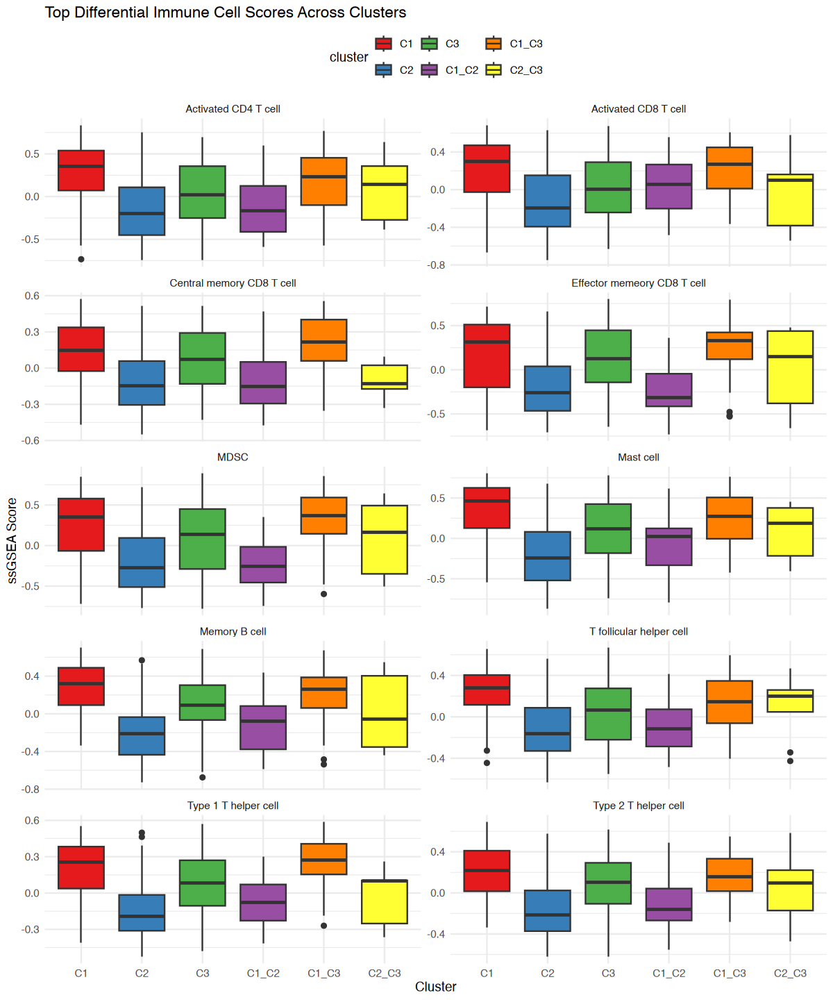

In [26]:
#==============================================
# 方法4: 每个通路单独的箱线图(面板)
#==============================================

# 为每个通路创建一个单独的箱线图
# 可能通路太多，所以选择一部分最有差异的通路
options(repr.plot.width=10, repr.plot.height=12)

# 计算哪些通路在不同聚类间差异最大（使用ANOVA）
# 修复公式创建，使用反引号包围路径名
pathway_pvalues <- sapply(pathway_columns, function(pathway) {
  model <- aov(as.formula(paste("`", pathway, "`", "~ cluster", sep="")), data = gsva_res)
  summary(model)[[1]]["Pr(>F)"][[1]][1]
})

# 选择p值最小的前10个通路（差异最显著的）
top_pathways <- names(sort(pathway_pvalues))[1:min(10, length(pathway_pvalues))]

# 为top_pathways创建子集长格式数据
top_long_data <- long_data %>%
  filter(Pathway %in% top_pathways)

# 创建分面箱线图
ggplot(top_long_data, aes(x = cluster, y = Score, fill = cluster)) +
  geom_boxplot() +
  facet_wrap(~ Pathway, scales = "free_y", ncol = 2) +
  theme_minimal() +
  theme(
    legend.position = "top",
    strip.text = element_text(face = "bold")
  ) +
  labs(
    title = "Top Differential Immune Cell Scores Across Clusters",
    x = "Cluster",
    y = "ssGSEA Score"
  ) +
  scale_fill_brewer(palette = "Set1")

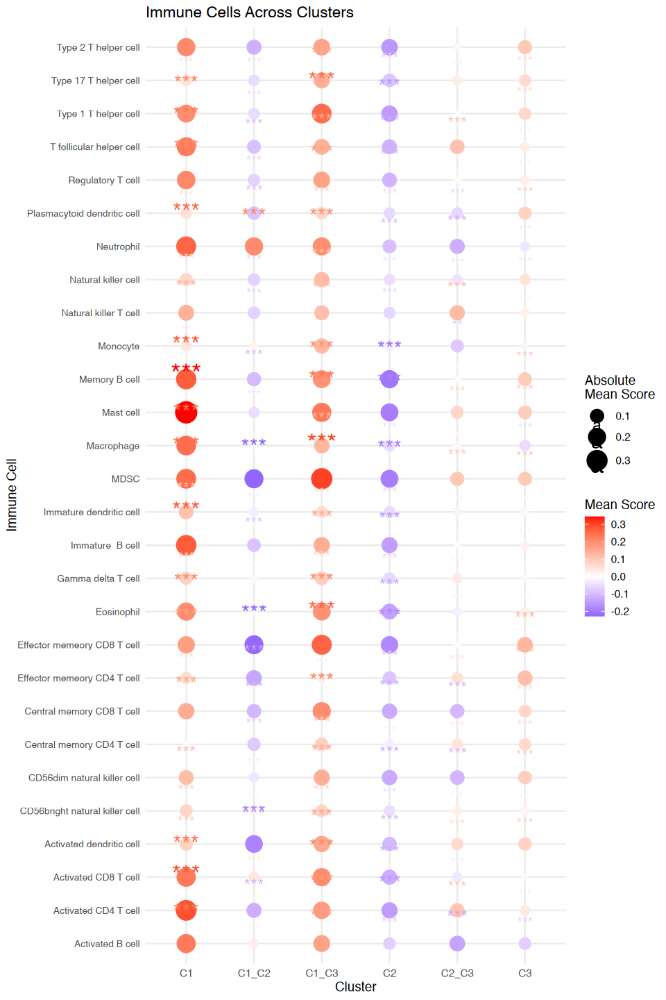

In [28]:
#==============================================
# 方法5: 气泡图展示通路活性
#==============================================
options(repr.plot.width=8, repr.plot.height=12)

# 计算每个聚类中每个通路的平均得分和显著性
pathway_stats <- data.frame()

for (pathway in pathway_columns) {
  # 执行ANOVA检验 - 使用反引号包围路径名
  model <- aov(as.formula(paste("`", pathway, "`", "~ cluster", sep="")), data = gsva_res)
  p_value <- summary(model)[[1]]["Pr(>F)"][[1]][1]
  
  # 计算每个聚类的平均得分
  # 使用sym()和!!操作符时，也需要确保路径名称被正确处理
  means_by_cluster <- gsva_res %>%
    group_by(cluster) %>%
    summarise(mean_score = mean(!!sym(pathway), na.rm = TRUE)) %>%
    mutate(pathway = pathway, p_value = p_value)
  
  pathway_stats <- rbind(pathway_stats, means_by_cluster)
}

# 调整p值以控制多重检验
pathway_stats$adj_p_value <- p.adjust(pathway_stats$p_value, method = "BH")
pathway_stats$significance <- ifelse(pathway_stats$adj_p_value < 0.05, "*", "")
pathway_stats$significance[pathway_stats$adj_p_value < 0.01] <- "**"
pathway_stats$significance[pathway_stats$adj_p_value < 0.001] <- "***"

# 创建气泡图
ggplot(pathway_stats, aes(x = cluster, y = pathway, size = abs(mean_score), color = mean_score)) +
  geom_point() +
  geom_text(aes(label = significance), vjust = -1.5) +
  scale_color_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  scale_size(range = c(1, 8)) +
  theme_minimal() +
  theme(
    axis.text.y = element_text(size = 8),
    legend.position = "right"
  ) +
  labs(
    title = "Immune Cells Across Clusters",
    x = "Cluster",
    y = "Immune Cell",
    color = "Mean Score",
    size = "Absolute\nMean Score"
  )

Warning message:
"There was 1 warning in `summarise()`.
i In argument: `across(all_of(top_pathways), mean, na.rm = TRUE)`.
i In group 1: `cluster = C1`.
Caused by warning:
! The `...` argument of `across()` is deprecated as of dplyr 1.1.0.
Supply arguments directly to `.fns` through an anonymous function instead.

  # Previously
  across(a:b, mean, na.rm = TRUE)

  # Now
  across(a:b, \(x) mean(x, na.rm = TRUE))"


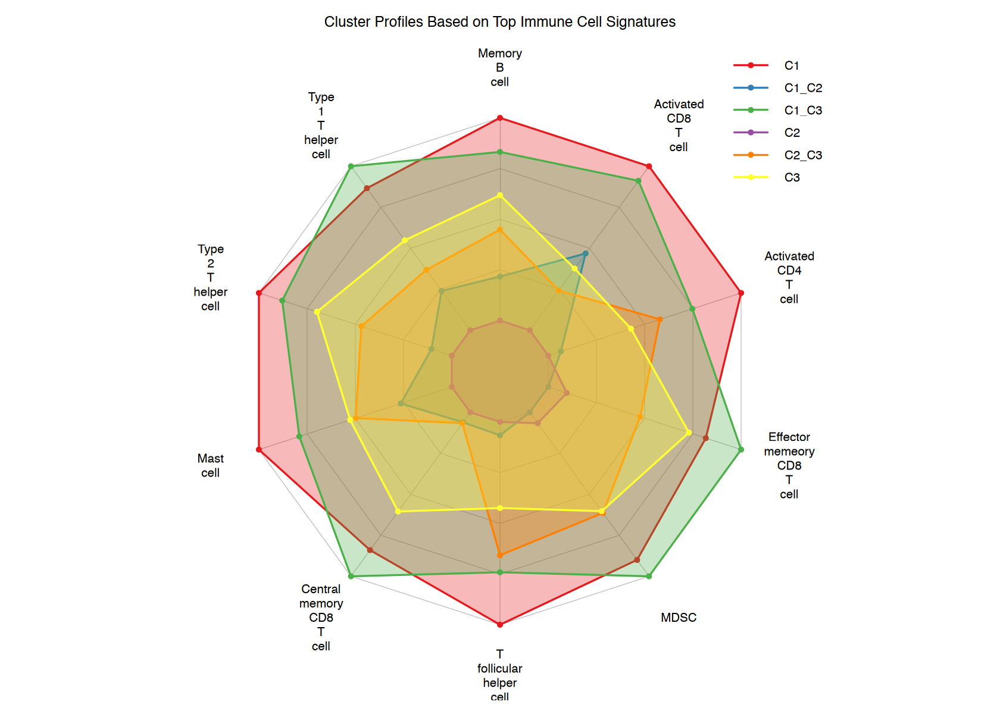

In [30]:
#==============================================
# 方法6: 雷达图展示聚类特征
#==============================================
options(repr.plot.width=14, repr.plot.height=10)
library(fmsb)
library(RColorBrewer)

# 选择top_pathways数量
n_top <- min(10, length(pathway_pvalues))
top_pathways <- names(sort(pathway_pvalues))[1:n_top]

# 计算每个聚类在每个通路上的平均得分
# 这部分是您代码中缺少的，我们需要先计算cluster_means
cluster_means <- gsva_res %>%
  group_by(cluster) %>%
  summarise(across(all_of(top_pathways), mean, na.rm = TRUE)) %>%
  as.data.frame()

# 将cluster列设为行名
rownames(cluster_means) <- cluster_means$cluster
cluster_means <- cluster_means[, -1, drop = FALSE]  # 删除cluster列

# 为雷达图准备数据
radar_data <- cluster_means
# 添加最大最小值行
radar_data <- rbind(
  apply(radar_data, 2, max),  # 最大值行
  apply(radar_data, 2, min),  # 最小值行
  radar_data
)

# 确保列名不含空格（fmsb包可能不能很好地处理带空格的列名）
colnames(radar_data) <- gsub(" ", "\n", colnames(radar_data))

# 创建雷达图
colors <- brewer.pal(min(9, nrow(radar_data) - 2), "Set1")  # 最多9种颜色
if(nrow(radar_data) - 2 > 9) {
  # 如果有超过9个聚类，则重复使用颜色
  colors <- colorRampPalette(colors)(nrow(radar_data) - 2)
}

par(mar = c(1, 1, 3, 1))  # 调整边距

radarchart(
  radar_data,
  pcol = colors,
  pfcol = sapply(colors, function(col) adjustcolor(col, alpha.f = 0.3)),
  plwd = 2,
  plty = 1,
  cglcol = "grey",
  cglty = 1,
  axislabcol = "grey20",
  caxislabels = seq(min(radar_data[2,]), max(radar_data[1,]), length.out = 5),
  cglwd = 0.8,
  title = "Cluster Profiles Based on Top Immune Cell Signatures"
)

# 添加图例
legend(
  "topright",
  legend = rownames(radar_data)[-c(1,2)],
  col = colors,
  lty = 1,
  lwd = 2,
  pch = 16,
  bty = "n"
)


Attaching package: 'rstatix'


The following object is masked from 'package:AnnotationDbi':

    select


The following object is masked from 'package:IRanges':

    desc


The following object is masked from 'package:genefilter':

    Anova


The following object is masked from 'package:stats':

    filter




Heatmap dimensions: 13 4 
Number of unique pathways: 13 
Number of unique clusters: 4 
Range of effect sizes: 0.4016825 1.052471 
# A tibble: 16 x 5
   cluster pathway                     effect_size  p_value adj_p_value
   <chr>   <chr>                             <dbl>    <dbl>       <dbl>
 1 C1      Memory B cell                     1.05  4.35e-24    1.46e-22
 2 C1      Mast cell                         0.969 1.26e-18    2.11e-17
 3 C1      T follicular helper cell          0.959 3.19e-19    6.70e-18
 4 C1      Type 1 T helper cell              0.902 3.63e-16    4.06e-15
 5 C1      Activated CD4 T cell              0.898 3.95e-17    5.10e-16
 6 C1_C2   Neutrophil                        0.458 4.72e- 4    1.17e- 3
 7 C1_C3   Type 1 T helper cell              0.978 1.48e- 9    7.79e- 9
 8 C1_C3   Central memory CD8 T cell         0.797 2.99e- 6    1.05e- 5
 9 C1_C3   MDSC                              0.725 1.22e- 5    3.72e- 5
10 C1_C3   Effector memeory CD8 T cell       0.700 4.52e- 6

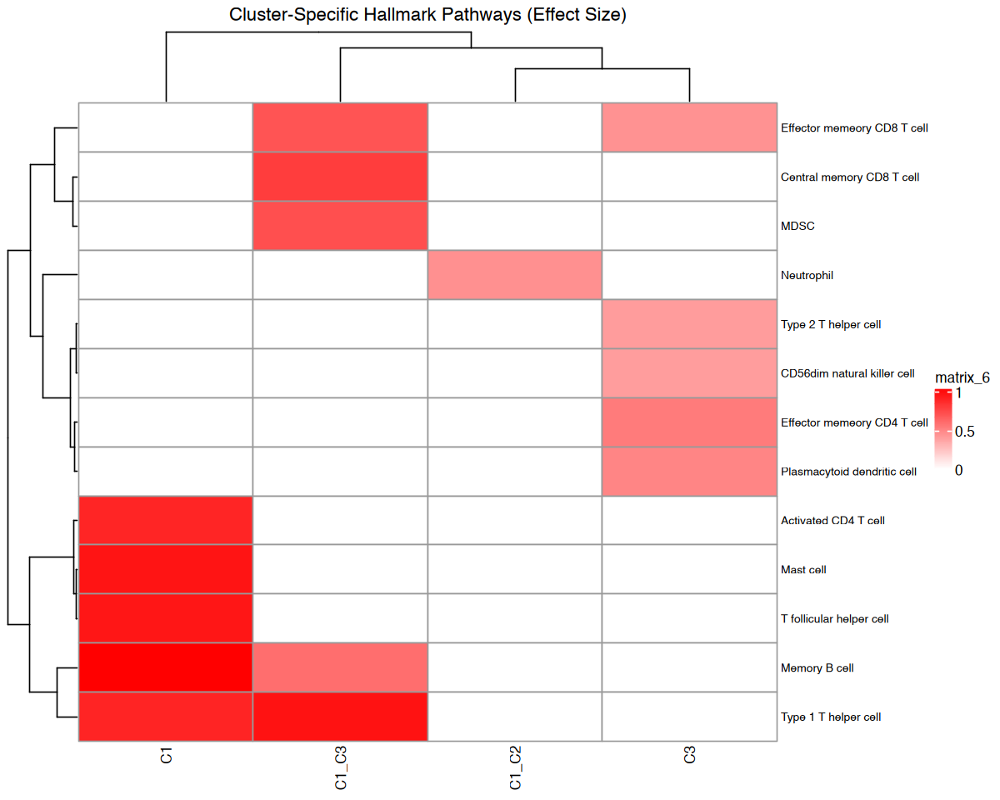

In [29]:
#==============================================
# 方法7: 聚类特异性通路富集热图（增强版）
#==============================================
options(repr.plot.width=10, repr.plot.height=8)
# 找出每个聚类特异的通路（哪些通路在某个聚类中显著高于其他聚类）
library(rstatix)

# 假设gsva_res包含通路得分和聚类信息
# 获取pathway列名（所有非聚类和非辅助列）
pathway_columns <- setdiff(colnames(gsva_res), c("cluster", "is_cluster"))

# 为每个聚类找出显著特异的通路
cluster_specific_pathways <- data.frame()

for (cl in unique(gsva_res$cluster)) {
  # 创建比较列
  gsva_res$is_cluster <- ifelse(gsva_res$cluster == cl, "Yes", "No")
  
  # 对每个通路进行t检验
  for (pathway in pathway_columns) {
    # 获取当前组和其他组的数据
    group_data <- gsva_res[gsva_res$is_cluster == "Yes", pathway]
    other_data <- gsva_res[gsva_res$is_cluster == "No", pathway]
    
    # 移除NA值
    group_data <- group_data[!is.na(group_data)]
    other_data <- other_data[!is.na(other_data)]
    
    # 检查数据是否足够进行t检验
    if (length(group_data) < 2 || length(other_data) < 2) {
      # 如果样本太少，跳过这个通路
      next
    }
    
    # 检查数据是否有变异
    if (var(group_data) == 0 || var(other_data) == 0) {
      # 如果任一组数据完全相同（无变异），跳过
      next
    }
    
    # 使用tryCatch进行t检验
    t_test_result <- tryCatch({
      t.test(group_data, other_data)
    }, error = function(e) {
      # 如果t检验失败，返回NULL
      return(NULL)
    })
    
    # 如果t检验成功，计算效应量并添加到结果
    if (!is.null(t_test_result)) {
      mean_diff <- t_test_result$estimate[1] - t_test_result$estimate[2]
      
      # 计算效应量（Cohen's d）
      # 使用更稳健的计算方法
      n1 <- length(group_data)
      n2 <- length(other_data)
      s1 <- var(group_data)
      s2 <- var(other_data)
      
      # 计算合并标准差
      pooled_sd <- sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
      
      # 如果pooled_sd为0或NA，则跳过
      if (is.na(pooled_sd) || pooled_sd == 0) {
        next
      }
      
      effect_size <- mean_diff / pooled_sd
      
      cluster_specific_pathways <- rbind(
        cluster_specific_pathways,
        data.frame(
          cluster = cl,
          pathway = pathway,
          p_value = t_test_result$p.value,
          effect_size = effect_size,
          mean_diff = mean_diff,
          n_cluster = n1,
          n_other = n2
        )
      )
    }
  }
}

# 如果结果为空，提供信息并停止
if (nrow(cluster_specific_pathways) == 0) {
  stop("No valid pathway comparisons could be made. Check your data for NA values or lack of variation.")
}

# 调整p值
cluster_specific_pathways$adj_p_value <- p.adjust(cluster_specific_pathways$p_value, method = "BH")

# 找出每个聚类中最显著的通路（p值小，效应量大且为正）
# 先检查是否有显著的通路
if (sum(cluster_specific_pathways$adj_p_value < 0.05 & cluster_specific_pathways$effect_size > 0) == 0) {
  cat("No pathways meet significance criteria (adj_p_value < 0.05 and effect_size > 0).\n")
  cat("Using top pathways by effect size instead.\n")
  
  # 如果没有显著通路，选择每个聚类中效应量最大的通路
  significant_pathways <- cluster_specific_pathways %>%
    filter(effect_size > 0) %>%  # 仍然要求效应量为正
    group_by(cluster) %>%
    arrange(desc(effect_size)) %>%
    slice_head(n = 5) %>%  # 每个聚类取前5个
    ungroup()
} else {
  # 使用原来的过滤方法
  significant_pathways <- cluster_specific_pathways %>%
    filter(adj_p_value < 0.05, effect_size > 0) %>%
    group_by(cluster) %>%
    arrange(desc(effect_size)) %>%
    slice_head(n = 5) %>%  # 每个聚类取前5个
    ungroup()
}

# 如果结果为空，提供信息并停止
if (nrow(significant_pathways) == 0) {
  stop("No significant pathways found with positive effect size.")
}

# 创建热图数据
# 先检查是否有足够的通路和聚类
unique_pathways <- unique(significant_pathways$pathway)
unique_clusters <- unique(significant_pathways$cluster)

if (length(unique_pathways) == 0 || length(unique_clusters) == 0) {
  stop("Not enough unique pathways or clusters for heatmap.")
}

sig_heatmap_data <- matrix(0, 
                         nrow = length(unique_pathways),
                         ncol = length(unique_clusters))

rownames(sig_heatmap_data) <- unique_pathways
colnames(sig_heatmap_data) <- unique_clusters

# 填充热图数据
for (i in 1:nrow(significant_pathways)) {
  pathway <- significant_pathways$pathway[i]
  cluster <- significant_pathways$cluster[i]
  
  row_idx <- which(rownames(sig_heatmap_data) == pathway)
  col_idx <- which(colnames(sig_heatmap_data) == cluster)
  
  # 检查索引是否有效
  if (length(row_idx) > 0 && length(col_idx) > 0) {
    sig_heatmap_data[row_idx, col_idx] <- significant_pathways$effect_size[i]
  }
}

# 在绘制热图前，检查数据
if (all(sig_heatmap_data == 0)) {
  stop("Heatmap data is all zeros. Check your filtering criteria.")
}

# 打印一些统计信息，帮助诊断
cat("Heatmap dimensions:", dim(sig_heatmap_data), "\n")
cat("Number of unique pathways:", length(unique_pathways), "\n")
cat("Number of unique clusters:", length(unique_clusters), "\n")
cat("Range of effect sizes:", range(significant_pathways$effect_size), "\n")

# 创建热图
pheatmap(
  sig_heatmap_data,
  color = colorRampPalette(c("white", "red"))(100),
  cluster_rows = TRUE,
  cluster_cols = TRUE,
  fontsize_row = 8,
  fontsize_col = 10,
  main = "Cluster-Specific Hallmark Pathways (Effect Size)"
)

# 可选：如果热图创建失败，尝试使用更简单的热图函数
if (FALSE) {  # 设为TRUE以启用备选方案
  heatmap(
    sig_heatmap_data,
    col = colorRampPalette(c("white", "red"))(100),
    main = "Cluster-Specific Hallmark Pathways (Effect Size)"
  )
}

# 额外：输出主要结果表格，便于查看
top_results <- significant_pathways %>%
  select(cluster, pathway, effect_size, p_value, adj_p_value) %>%
  arrange(cluster, desc(effect_size))

print(top_results)

### TME estimate

In [10]:
library(estimate)

#=============================================
# 直接创建GCT文件，跳过filterCommonGenes
#=============================================

# 1. 确保表达矩阵格式正确
# 检查表达矩阵结构
dim_expr <- dim(expr_mat)
cat("表达矩阵维度:", dim_expr[1], "行 ×", dim_expr[2], "列\n")

# 2. 直接创建GCT文件 (GCT 1.2 格式)
# 使用writeLines而不是write.table，以确保正确的格式

# 打开文件连接
gct_file <- file("direct_estimate_input.gct", "w")

# 写入GCT格式头部
writeLines("#1.2", gct_file)
writeLines(paste(nrow(expr_mat), ncol(expr_mat)), gct_file)

# 创建并写入列名行 (NAME, Description, 样本名)
header_line <- paste(c("NAME", "Description", colnames(expr_mat)), collapse="\t")
writeLines(header_line, gct_file)

# 写入每一行基因表达数据
for (i in 1:nrow(expr_mat)) {
  gene_name <- rownames(expr_mat)[i]
  # GCT格式需要NAME和Description列
  gene_row <- c(gene_name, "na", as.character(expr_mat[i,]))
  gene_line <- paste(gene_row, collapse="\t")
  writeLines(gene_line, gct_file)
}

# 关闭文件连接
close(gct_file)

cat("GCT文件已创建: direct_estimate_input.gct\n")

# 3. 直接使用创建的GCT文件计算ESTIMATE分数
estimateScore(
  input.ds = "direct_estimate_input.gct", 
  output.ds = "direct_estimate_score.gct", 
  platform = "affymetrix" # 根据你的数据平台选择，如"affymetrix", "illumina", "agilent"
)

# 4. 读取结果文件
# 先查看文件的前几行，了解结构
estimate_header <- readLines("direct_estimate_score.gct", n = 5)
cat("ESTIMATE结果文件前几行:\n")
cat(paste(estimate_header, collapse="\n"), "\n")

# 正确读取GCT格式文件
estimate_result <- read.table(
  "direct_estimate_score.gct", 
  skip = 2,        # 跳过前两行GCT格式信息
  header = TRUE,   # 第三行是列名
  sep = "\t",      # 制表符分隔
  check.names = FALSE, 
  comment.char = ""
)

# 5. 处理结果
# GCT文件通常第一列是NAME，第二列是Description
cat("ESTIMATE结果数据结构:\n")
str(estimate_result[1:5, 1:5])  # 只显示一部分

# 提取分数
estimate_scores <- estimate_result[, -c(1:2)]  # 移除NAME和Description列
rownames(estimate_scores) <- estimate_result[, 1]  # 使用第一列作为行名

# 转置结果，使样本成为行
estimate_scores_t <- as.data.frame(t(estimate_scores))

# --- 第6步：【新增】使用官方公式计算肿瘤纯度 ---
# 这个公式来源于ESTIMATE的原始研究
# Purity = cos(0.6049872018 + 0.0001467884 * ESTIMATEScore)

# 确保ESTIMATEScore列存在
if ("ESTIMATEScore" %in% colnames(estimate_scores_t)) {
  
  cat("--- 正在计算肿瘤纯度 ---\n")
  
  estimate_scores_t <- estimate_scores_t %>%
    mutate(
      TumorPurity = cos(0.6049872018 + 0.0001467884 * ESTIMATEScore)
    )
  
} else {
  warning("在ESTIMATE结果中未找到 'ESTIMATEScore' 列，无法计算肿瘤纯度。")
}

# 7. 添加聚类信息
# 确保cluster_vec的名称与样本名匹配
#common_samples <- intersect(names(cluster_vec), rownames(estimate_scores_t))
#cat("共有", length(common_samples), "个样本同时存在于聚类向量和ESTIMATE结果中\n")

#estimate_scores_t$cluster <- cluster_vec[rownames(estimate_scores_t)]
estimate_scores_t$cluster <- cluster_vec

# 8. 检查和处理可能的NA值
na_count <- sum(is.na(estimate_scores_t$cluster))
if (na_count > 0) {
  cat("警告: 有", na_count, "个样本无法匹配到聚类信息\n")
}

# 9. 保存处理后的结果
write.csv(estimate_scores_t, "estimate_scores_with_clusters.csv")
cat("已将ESTIMATE分数与聚类信息保存到: estimate_scores_with_clusters.csv\n")

# 10. 显示结果概要
cat("\nESTIMATE分数概要统计 (按聚类):\n")
# 如果存在'StromalScore', 'ImmuneScore', 'ESTIMATEScore'列
if (all(c("StromalScore", "ImmuneScore", "ESTIMATEScore") %in% colnames(estimate_scores_t))) {
  by_cluster <- aggregate(estimate_scores_t[, c("StromalScore", "ImmuneScore", "ESTIMATEScore")], 
                         by = list(Cluster = estimate_scores_t$cluster), 
                         FUN = function(x) c(mean = mean(x, na.rm = TRUE), 
                                           sd = sd(x, na.rm = TRUE)))
  print(by_cluster)
}

<U+8868><U+8FBE><U+77E9><U+9635><U+7EF4><U+5EA6>: 10531 <U+884C> <U+00D7> 586 <U+5217>
GCT<U+6587><U+4EF6><U+5DF2><U+521B><U+5EFA>: direct_estimate_input.gct
[1] "1 gene set: StromalSignature  overlap= 79"
[1] "2 gene set: ImmuneSignature  overlap= 111"


GSM6654041: out of bounds



ESTIMATE<U+7ED3><U+679C><U+6587><U+4EF6><U+524D><U+51E0><U+884C>:
#1.2																																																																																																																																																																																																																																																																																																																																																																																																																																																																																																																																																																																																											
4	586																																																																																																																																																																																																																																																																																																																																																	

In [11]:
library(ggplot2)
library(dplyr)
library(tidyr)
library(patchwork)
library(pheatmap)
library(viridis)
library(scales)
library(corrplot)

# 假设estimate_scores_t已经包含了ESTIMATE分数和聚类信息
# 确保cluster列是因子型
estimate_scores_t$cluster <- as.factor(estimate_scores_t$cluster)
head(estimate_scores_t)


Attaching package: 'dplyr'


The following object is masked from 'package:AnnotationDbi':

    select


The following objects are masked from 'package:IRanges':

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from 'package:S4Vectors':

    first, intersect, rename, setdiff, setequal, union


The following object is masked from 'package:Biobase':

    combine


The following objects are masked from 'package:BiocGenerics':

    combine, intersect, setdiff, union


The following object is masked from 'package:nlme':

    collapse


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union



Attaching package: 'tidyr'


The following object is masked from 'package:S4Vectors':

    expand



Attaching package: 'patchwork'


The following object is masked from 'package:genefilter':

    area


Loading required package: viridisLite


Attachi

,StromalScore,ImmuneScore,ESTIMATEScore,TumorPurity,cluster
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
GSM2883928,-722.40635,201.0595,-521.3469,0.8635848,C2
GSM2883929,52.45391,166.5011,218.9550,0.8038080,C1
GSM2883930,74.96978,728.8078,803.7776,0.7498424,C1_C3
GSM2883931,767.84463,1166.7519,1934.5966,0.6302171,C3
GSM2883932,887.51187,1204.7009,2092.2128,0.6120866,C3
GSM2883933,-2112.40056,-671.6954,-2784.0960,0.9807922,C3


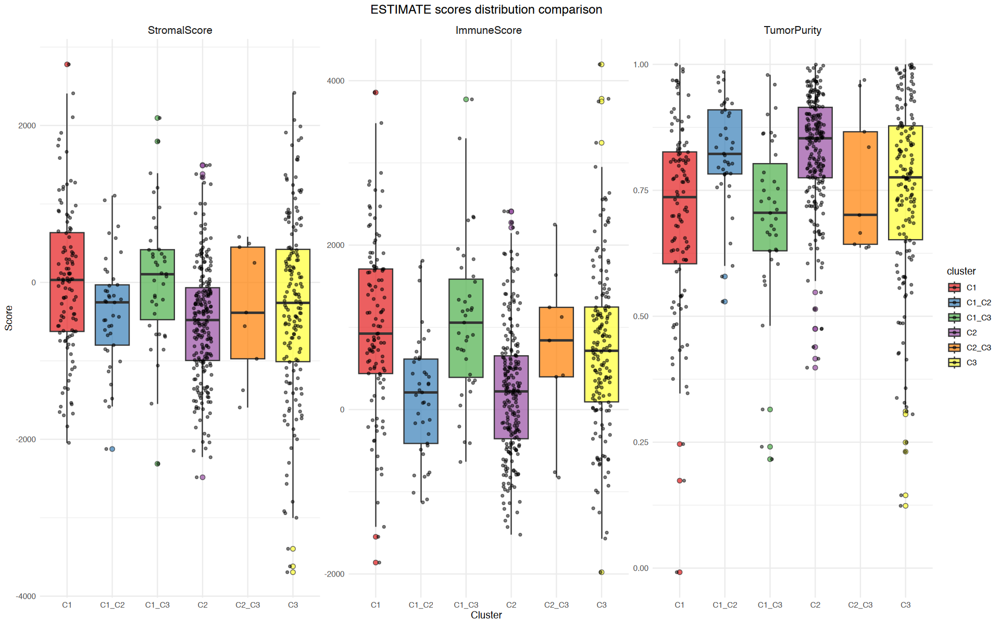

In [13]:
#=================================================
# 1. 箱线图 - 比较不同聚类的ESTIMATE分数分布
#=================================================

# 转换为长格式，便于ggplot绘图
estimate_long <- estimate_scores_t %>%
  select(StromalScore, ImmuneScore, TumorPurity, cluster) %>% #ESTIMATEScore, TumorPurity, 
  pivot_longer(
    cols = c(StromalScore, ImmuneScore, TumorPurity), #, TumorPurity, ESTIMATEScore
    names_to = "Score_Type",
    values_to = "Score"
  )

# 设置分数类型因子水平顺序
estimate_long$Score_Type <- factor(
  estimate_long$Score_Type,
  levels = c("StromalScore", "ImmuneScore", "TumorPurity") #, "TumorPurity", "ESTIMATEScore"
)
options(repr.plot.width=16, repr.plot.height=10)
# 绘制箱线图
p1 <- ggplot(estimate_long, aes(x = cluster, y = Score, fill = cluster)) +
  geom_boxplot(alpha = 0.7, outlier.shape = 21, outlier.size = 2) +
  geom_jitter(width = 0.2, alpha = 0.5, size = 1) +
  facet_wrap(~ Score_Type, scales = "free_y", ncol = 3) +
  scale_fill_brewer(palette = "Set1") +
  labs(
    title = "ESTIMATE scores distribution comparison",
    x = "Cluster",
    y = "Score"
  ) +
  theme_minimal() +
  theme(
    strip.text = element_text(size = 12, face = "bold"),
    axis.title = element_text(size = 11),
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14)
  )

print(p1)

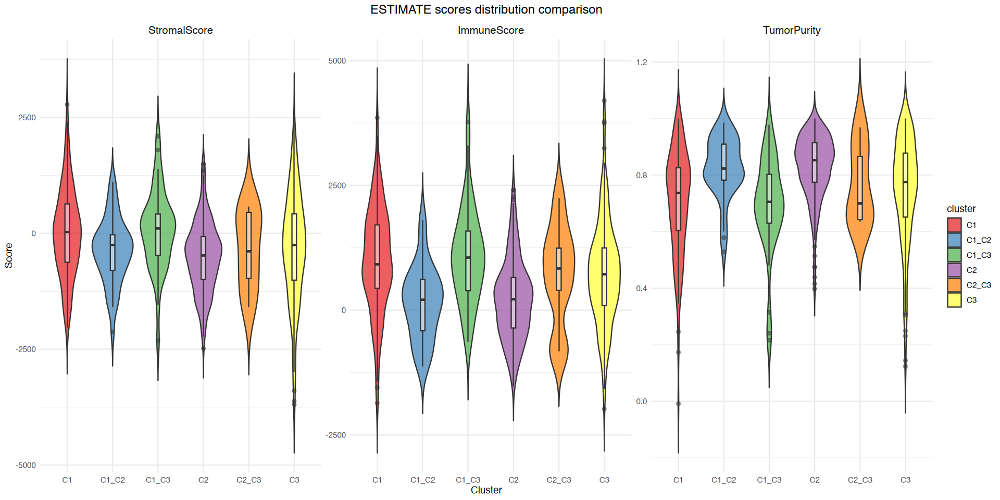

In [17]:
#=================================================
# 2. 小提琴图 - 更好地展示分布形状
#=================================================
options(repr.plot.width=16, repr.plot.height=8)
p2 <- ggplot(estimate_long, aes(x = cluster, y = Score, fill = cluster)) +
  geom_violin(alpha = 0.7, trim = FALSE) +
  geom_boxplot(width = 0.1, fill = "white", alpha = 0.5) +
  facet_wrap(~ Score_Type, scales = "free_y", ncol = 3) +
  scale_fill_brewer(palette = "Set1") +
  labs(
    title = "ESTIMATE scores distribution comparison",
    x = "Cluster",
    y = "Score"
  ) +
  theme_minimal() +
  theme(
    strip.text = element_text(size = 12, face = "bold"),
    axis.title = element_text(size = 11),
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14)
  )

print(p2)

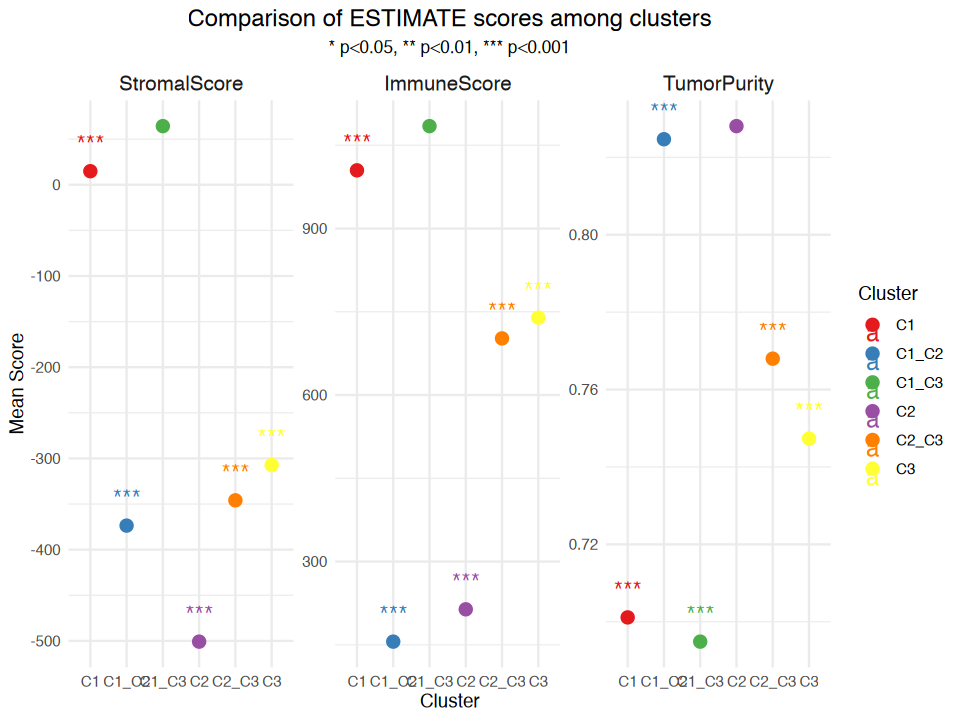

In [18]:
#=================================================
# 3. 点图 - 显示统计检验结果
#=================================================
options(repr.plot.width=8, repr.plot.height=6)
# 执行组间统计检验
stat_results <- data.frame()

for (score_type in c("StromalScore", "ImmuneScore", "TumorPurity")) {
  # 如果聚类数大于2，使用ANOVA
  if (length(unique(estimate_scores_t$cluster)) > 2) {
    # ANOVA
    anova_result <- aov(as.formula(paste(score_type, "~ cluster")), data = estimate_scores_t)
    p_val <- summary(anova_result)[[1]]["Pr(>F)"][[1]][1]
    
    # 使用TukeyHSD进行多重比较
    tukey <- TukeyHSD(anova_result)
    
    # 提取各组均值
    means <- aggregate(as.formula(paste(score_type, "~ cluster")), 
                      data = estimate_scores_t, FUN = mean)
    
    for (clust in unique(estimate_scores_t$cluster)) {
      stat_results <- rbind(stat_results, data.frame(
        Score_Type = score_type,
        Cluster = clust,
        Mean = means[means$cluster == clust, 2],
        P_value = p_val
      ))
    }
  } else {
    # 如果只有两个聚类，使用t检验
    t_test <- t.test(as.formula(paste(score_type, "~ cluster")), data = estimate_scores_t)
    p_val <- t_test$p.value
    
    # 提取各组均值
    means <- aggregate(as.formula(paste(score_type, "~ cluster")), 
                      data = estimate_scores_t, FUN = mean)
    
    for (clust in unique(estimate_scores_t$cluster)) {
      stat_results <- rbind(stat_results, data.frame(
        Score_Type = score_type,
        Cluster = clust,
        Mean = means[means$cluster == clust, 2],
        P_value = p_val
      ))
    }
  }
}

# 添加显著性标记
stat_results$Significance <- ""
stat_results$Significance[stat_results$P_value < 0.05] <- "*"
stat_results$Significance[stat_results$P_value < 0.01] <- "**"
stat_results$Significance[stat_results$P_value < 0.001] <- "***"

# 设置分数类型因子水平顺序
stat_results$Score_Type <- factor(
  stat_results$Score_Type,
  levels = c("StromalScore", "ImmuneScore", "TumorPurity")
)

# 绘制点图
p3 <- ggplot(stat_results, aes(x = Cluster, y = Mean, color = Cluster)) +
  geom_point(size = 3) +
  geom_text(aes(label = Significance), vjust = -1, size = 5) +
  facet_wrap(~ Score_Type, scales = "free_y", ncol = 3) +
  scale_color_brewer(palette = "Set1") +
  labs(
    title = "Comparison of ESTIMATE scores among clusters",
    subtitle = "* p<0.05, ** p<0.01, *** p<0.001",
    x = "Cluster",
    y = "Mean Score"
  ) +
  theme_minimal() +
  theme(
    strip.text = element_text(size = 12, face = "bold"),
    axis.title = element_text(size = 11),
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14),
    plot.subtitle = element_text(hjust = 0.5, size = 10)
  )

print(p3)

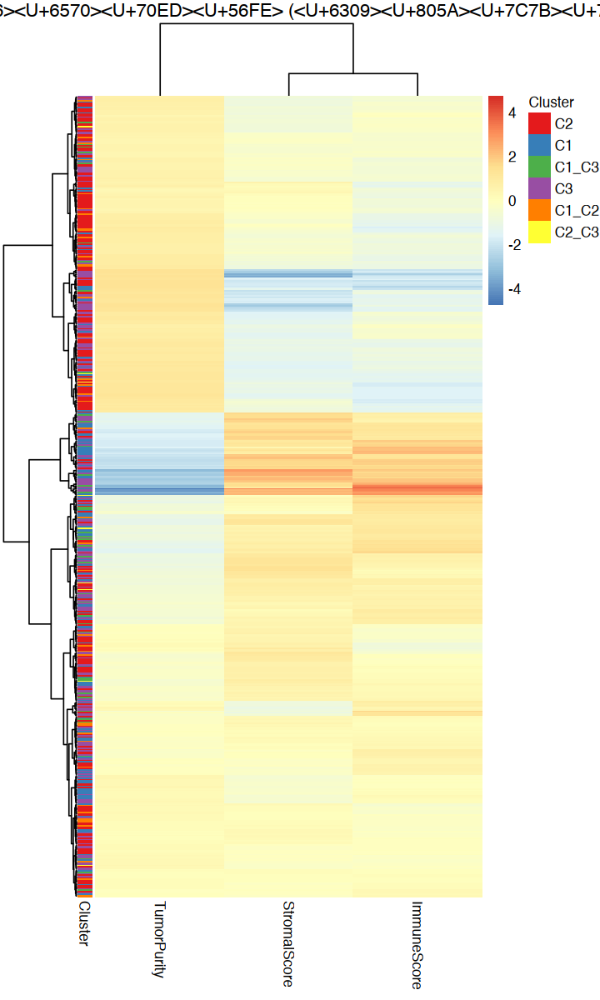

In [19]:
#=================================================
# 4. 热图 - 样本级别分数可视化
#=================================================
options(repr.plot.width=6, repr.plot.height=10)
# 准备热图数据
heatmap_data <- estimate_scores_t %>%
  select(StromalScore, ImmuneScore, TumorPurity) #, ESTIMATEScore, TumorPurity

# 设置行注释
row_anno <- data.frame(Cluster = estimate_scores_t$cluster)
rownames(row_anno) <- rownames(heatmap_data)

# 创建颜色映射
cluster_colors <- RColorBrewer::brewer.pal(n = min(8, length(unique(estimate_scores_t$cluster))), name = "Set1")
names(cluster_colors) <- unique(estimate_scores_t$cluster)
anno_colors <- list(Cluster = cluster_colors)

# 绘制热图
pheatmap(
  heatmap_data,
  scale = "column",  # 对列进行Z分数标准化
  clustering_distance_rows = "euclidean",
  clustering_distance_cols = "euclidean",
  clustering_method = "ward.D2",
  annotation_row = row_anno,
  annotation_colors = anno_colors,
  show_rownames = FALSE,  # 如果样本太多，不显示行名
  main = "ESTIMATE分数热图 (按聚类着色)",
  fontsize = 10,
  fontsize_col = 10
)

`geom_smooth()` using formula = 'y ~ x'


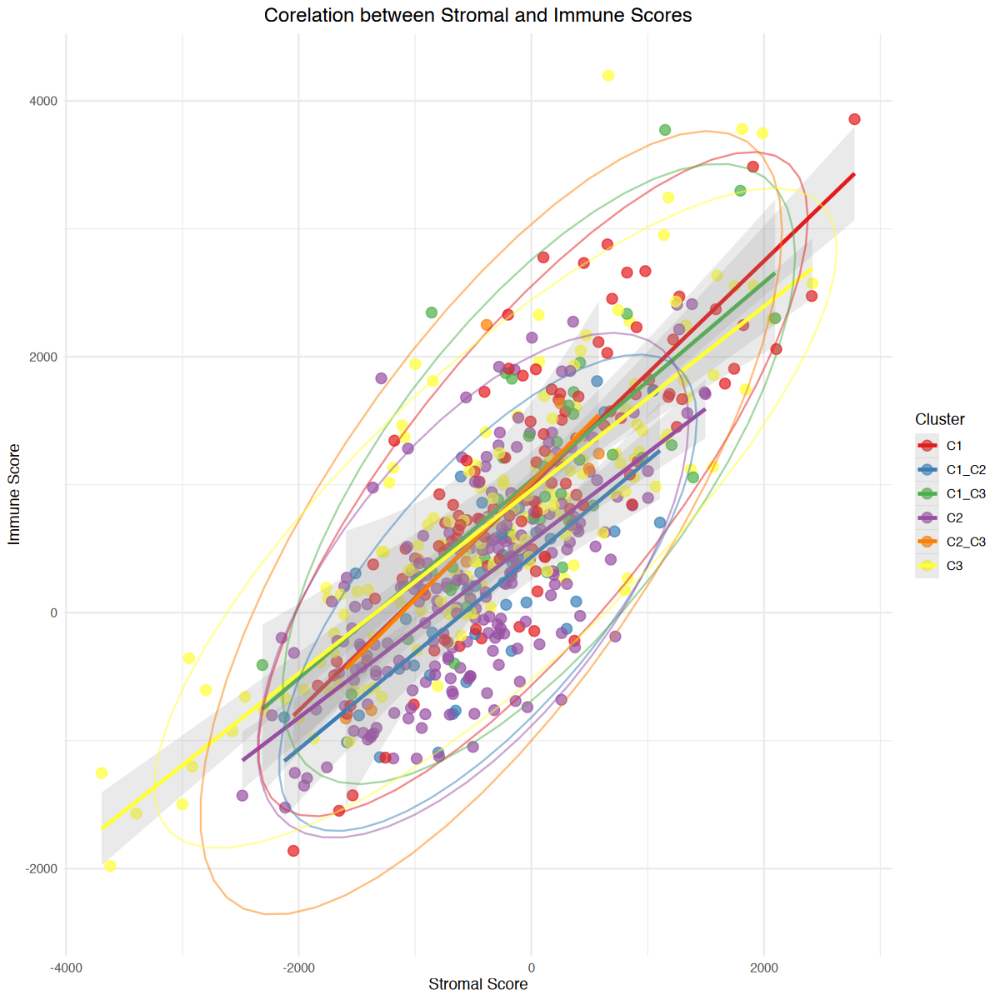

In [20]:
#=================================================
# 5. 散点图 - 免疫分数与基质分数关系
#=================================================
options(repr.plot.width=10, repr.plot.height=10)
p5 <- ggplot(estimate_scores_t, aes(x = StromalScore, y = ImmuneScore, color = cluster)) +
  geom_point(size = 3, alpha = 0.7) +
  geom_smooth(method = "lm", se = TRUE, alpha = 0.2) +
  stat_ellipse(type = "norm", level = 0.95, alpha = 0.5) +
  scale_color_brewer(palette = "Set1") +
  labs(
    title = "Corelation between Stromal and Immune Scores",
    x = "Stromal Score",
    y = "Immune Score",
    color = "Cluster"
  ) +
  theme_minimal() +
  theme(
    axis.title = element_text(size = 11),
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14)
  )

print(p5)

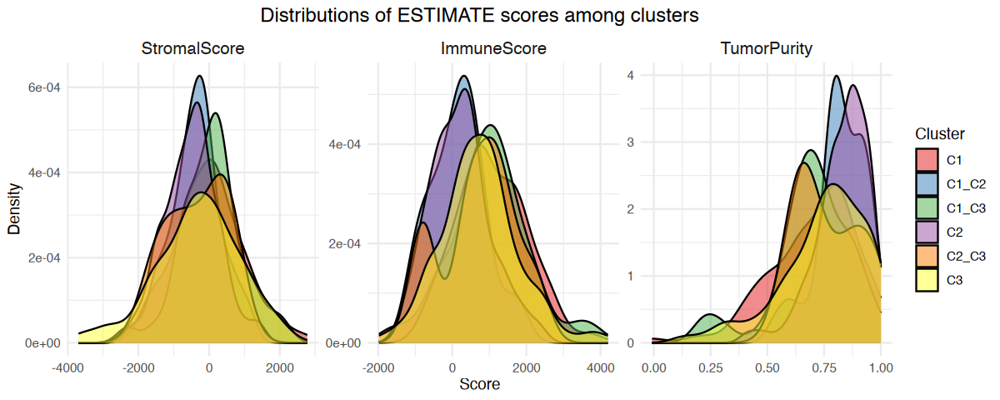

In [23]:
#=================================================
# 6. 密度图 - 各分数在聚类间分布比较
#=================================================
options(repr.plot.width=10, repr.plot.height=4)
p6 <- ggplot(estimate_long, aes(x = Score, fill = cluster)) +
  geom_density(alpha = 0.5) +
  facet_wrap(~ Score_Type, scales = "free", ncol = 3) +
  scale_fill_brewer(palette = "Set1") +
  labs(
    title = "Distributions of ESTIMATE scores among clusters",
    x = "Score",
    y = "Density",
    fill = "Cluster"
  ) +
  theme_minimal() +
  theme(
    strip.text = element_text(size = 12, face = "bold"),
    axis.title = element_text(size = 11),
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14)
  )

print(p6)

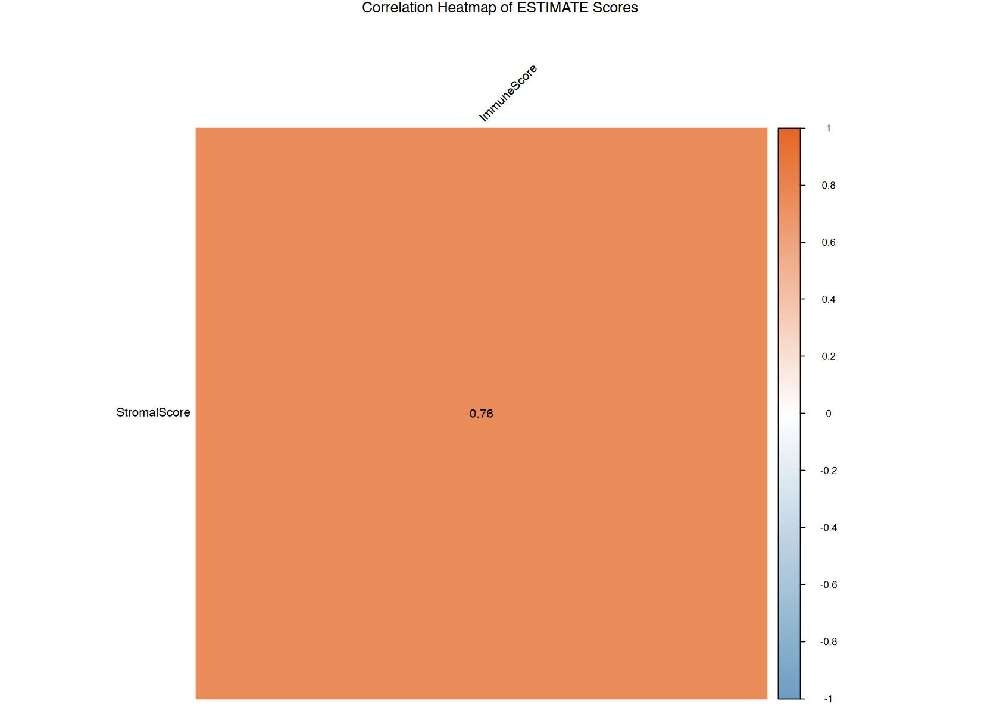

In [40]:
#=================================================
# 7. 相关性热图 - 不同分数间的相关性
#=================================================
options(repr.plot.width=14, repr.plot.height=10)
# 计算相关性
cor_matrix <- cor(estimate_scores_t[, c("StromalScore", "ImmuneScore")], 
                 use = "pairwise.complete.obs")

# 绘制相关性热图
corrplot(cor_matrix, 
         method = "color", 
         type = "upper", 
         addCoef.col = "black", 
         tl.col = "black", 
         tl.srt = 45, 
         diag = FALSE,
         col = colorRampPalette(c("#6D9EC1", "white", "#E46726"))(200),
         title = "Correlation Heatmap of ESTIMATE Scores",
         mar = c(0,0,1,0))

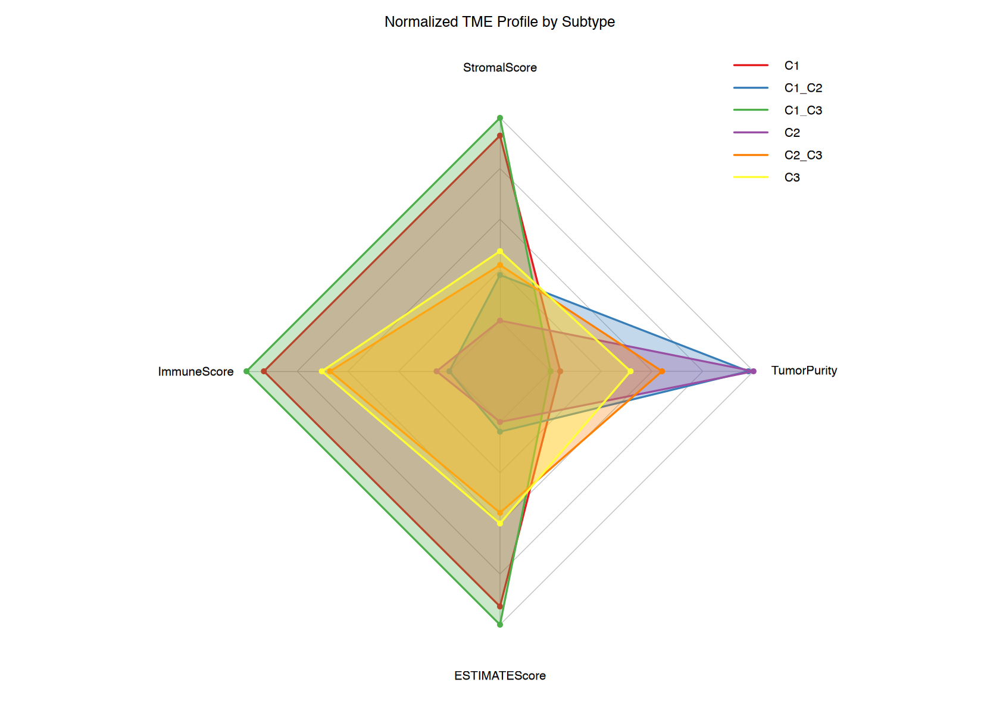

In [34]:
#=================================================
# 8. 雷达图 - 多维比较聚类特征
#=================================================
options(repr.plot.width=14, repr.plot.height=10)
# 计算每个聚类的平均分数
cluster_means <- estimate_scores_t %>%
  group_by(cluster) %>%
  summarise(
    StromalScore = mean(StromalScore, na.rm = TRUE),
    ImmuneScore = mean(ImmuneScore, na.rm = TRUE),
    ESTIMATEScore = mean(ESTIMATEScore, na.rm = TRUE),
    TumorPurity = mean(TumorPurity, na.rm = TRUE)
  )

# 为雷达图准备数据 (使用fmsb包)
if (!requireNamespace("fmsb", quietly = TRUE)) {
  install.packages("fmsb")
}
library(fmsb)

# --- 1. 提取需要可视化的数值数据 ---
# 【修正】不要转置数据，保持原有结构
radar_data_raw <- as.data.frame(cluster_means[, -1])
rownames(radar_data_raw) <- cluster_means$cluster

# --- 2. 对数据进行归一化 (Min-Max Scaling) ---
# 创建一个函数，将任何向量的值都缩放到0-1范围
normalize <- function(x) {
  return((x - min(x)) / (max(x) - min(x)))
}

# 对数据框的每一列（即每一种Score）应用归一化函数
radar_data_normalized <- as.data.frame(apply(radar_data_raw, 2, normalize))
rownames(radar_data_normalized) <- rownames(radar_data_raw)

# 添加最大值(1)和最小值(0)行
radar_data_final <- rbind(
  rep(1, ncol(radar_data_normalized)), # 最大值行
  rep(0, ncol(radar_data_normalized)), # 最小值行
  radar_data_normalized
)

# --- 4. 绘制修正后的雷达图 ---
library(fmsb)
library(RColorBrewer)

par(mar = c(1, 1, 3, 1)) # 设置边距

# 定义颜色
num_clusters <- nrow(radar_data_normalized)
colors <- brewer.pal(n = min(num_clusters, 9), name = "Set1")
if(num_clusters > 9) colors <- colorRampPalette(colors)(num_clusters)

radarchart(
  radar_data_final,
  pcol = colors,
  pfcol = scales::alpha(colors, 0.3),
  plwd = 2,
  plty = 1,
  cglcol = "grey",
  cglty = 1,
  axislabcol = "grey30",
  # 坐标轴刻度现在是0-1范围
  caxislabels = seq(0, 1, length.out = 5),
  cglwd = 0.8,
  title = "Normalized TME Profile by Subtype"
)

# 添加图例
legend(
  x = "topright",
  legend = rownames(radar_data_normalized),
  col = colors,
  lty = 1,
  lwd = 2,
  bty = "n"
)

`geom_smooth()` using formula = 'y ~ x'


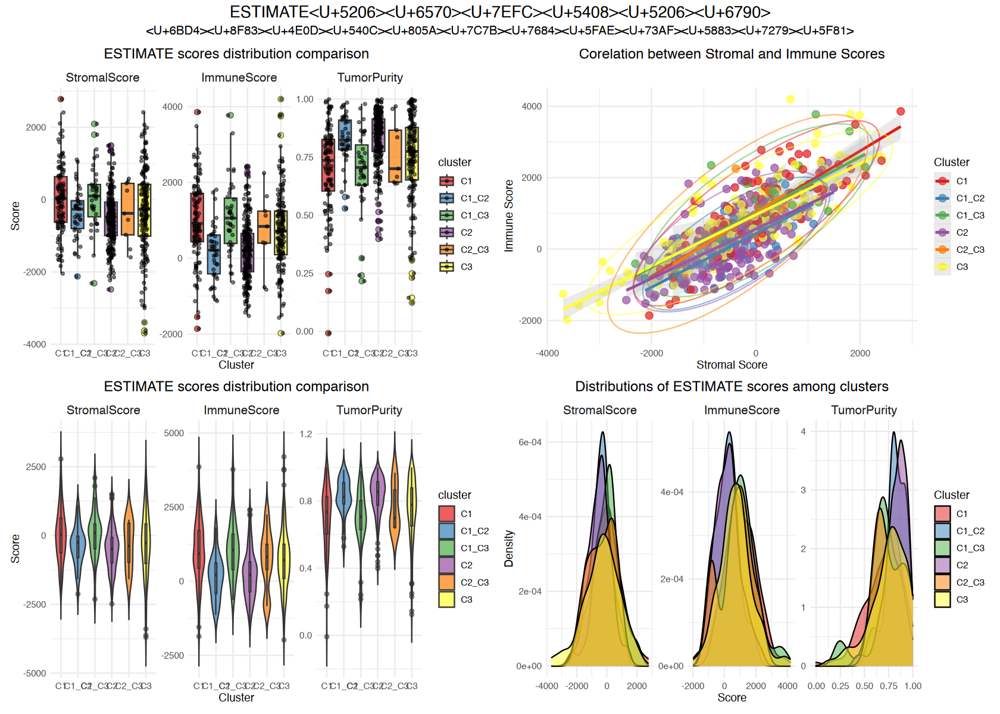

In [25]:
#=================================================
# 9. 组合图 - 使用patchwork组合多个图表
#=================================================
options(repr.plot.width=14, repr.plot.height=10)
# 使用patchwork包组合多个图表
combined_plot <- (p1 / p2) | (p5 / p6)
combined_plot + plot_annotation(
  title = "ESTIMATE分数综合分析",
  subtitle = "比较不同聚类的微环境特征",
  theme = theme(
    plot.title = element_text(size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 12, hjust = 0.5)
  )
)

In [ ]:
#=================================================
# 10. 统计分析表格
#=================================================

# 每个聚类的描述性统计
summary_stats <- estimate_scores_t %>%
  group_by(cluster) %>%
  summarise(
    N = n(),
    StromalScore_Mean = mean(StromalScore, na.rm = TRUE),
    StromalScore_SD = sd(StromalScore, na.rm = TRUE),
    ImmuneScore_Mean = mean(ImmuneScore, na.rm = TRUE),
    ImmuneScore_SD = sd(ImmuneScore, na.rm = TRUE),
    ESTIMATEScore_Mean = mean(ESTIMATEScore, na.rm = TRUE),
    ESTIMATEScore_SD = sd(ESTIMATEScore, na.rm = TRUE),
    TumorPurity_Mean = mean(TumorPurity, na.rm = TRUE),
    TumorPurity_SD = sd(TumorPurity, na.rm = TRUE)
  )

print(summary_stats)

# 保存所有图表
ggsave("estimate_boxplot.pdf", p1, width = 10, height = 7)
ggsave("estimate_violin.pdf", p2, width = 10, height = 7)
ggsave("estimate_dotplot.pdf", p3, width = 10, height = 7)
ggsave("estimate_scatter.pdf", p5, width = 8, height = 6)
ggsave("estimate_density.pdf", p6, width = 10, height = 7)

# 保存热图
pdf("estimate_heatmap.pdf", width = 8, height = 8)
pheatmap(
  heatmap_data,
  scale = "column",
  clustering_distance_rows = "euclidean",
  clustering_distance_cols = "euclidean",
  clustering_method = "ward.D2",
  annotation_row = row_anno,
  annotation_colors = anno_colors,
  show_rownames = FALSE,
  main = "ESTIMATE分数热图 (按聚类着色)",
  fontsize = 10,
  fontsize_col = 10
)
dev.off()

# 保存相关性热图
pdf("estimate_correlation.pdf", width = 6, height = 6)
corrplot(cor_matrix, 
         method = "color", 
         type = "upper", 
         addCoef.col = "black", 
         tl.col = "black", 
         tl.srt = 45, 
         diag = FALSE,
         col = colorRampPalette(c("#6D9EC1", "white", "#E46726"))(200),
         title = "ESTIMATE分数间相关性",
         mar = c(0,0,1,0))
dev.off()

# 保存雷达图
pdf("estimate_radar.pdf", width = 7, height = 7)
par(mar = c(1, 1, 3, 1))
radarchart(
  radar_data,
  pcol = colors,
  pfcol = scales::alpha(colors, 0.3),
  plwd = 2,
  plty = 1,
  cglcol = "grey",
  cglty = 1,
  axislabcol = "grey30",
  caxislabels = seq(min(radar_data[1:2,]), max(radar_data[1:2,]), length.out = 5),
  cglwd = 0.8,
  title = "聚类ESTIMATE分数特征比较"
)
legend(
  "topright",
  legend = colnames(radar_data),
  col = colors,
  lty = 1,
  lwd = 2,
  pch = 16,
  bty = "n"
)
dev.off()

# 保存组合图
ggsave("estimate_combined.pdf", combined_plot, width = 16, height = 12)

# 保存统计结果
write.csv(summary_stats, "estimate_summary_stats.csv", row.names = FALSE)
write.csv(stat_results, "estimate_statistical_tests.csv", row.names = FALSE)

### TME EPIC

In [44]:
# 安装并加载EPIC包
if (!requireNamespace("EPIC", quietly = TRUE)) {
  # 从Bioconductor安装
  if (!requireNamespace("BiocManager", quietly = TRUE))
    install.packages("BiocManager")
  BiocManager::install("EPIC")
  # 或者从GitHub安装最新版本
  # if (!requireNamespace("devtools", quietly = TRUE))
  #   install.packages("devtools")
  # devtools::install_github("GfellerLab/EPIC")
}
library(EPIC)

In [45]:
#=================================================
# 1. 准备表达数据
#=================================================
# 假设expr_mat是你的表达矩阵，行是基因，列是样本
# 确保基因名是标准HGNC符号或ENSEMBL ID
# 确保表达矩阵已经进行了log2转换和批次校正

# 检查表达数据格式
dim(expr_mat)
cat("表达矩阵维度:", nrow(expr_mat), "行 (基因) ×", ncol(expr_mat), "列 (样本)\n")

# 如果是log2转换的数据，需要转回线性尺度 (EPIC需要线性尺度的TPM数据)
#tpm_mat <- 2^expr_mat

# 或者如果是log2(TPM+1)格式，则使用:
tpm_mat <- 2^expr_mat - 1

#=================================================
# 2. 运行EPIC细胞比例预测
#=================================================
# 使用默认参考数据集
epic_results <- EPIC::EPIC(bulk = tpm_mat)

# 如果需要指定自定义参考数据集
# epic_results <- EPIC::EPIC(bulk = tpm_mat, reference = your_reference_dataset)

# 查看结果结构
str(epic_results)

# 提取细胞比例
cell_proportions <- epic_results$cellFractions
head(cell_proportions)

# 保存细胞比例结果
write.csv(cell_proportions, "epic_cell_proportions.csv")

[1] 10531   586

<U+8868><U+8FBE><U+77E9><U+9635><U+7EF4><U+5EA6>: 10531 <U+884C> (<U+57FA><U+56E0>) <U+00D7> 586 <U+5217> (<U+6837><U+672C>)


Warning message in EPIC::EPIC(bulk = tpm_mat):
"The optimization didn't fully converge for some samples:
GSM2883933; 215; 265; 573; 853; 883; CCA#73; CCA#179; GSM5418260; GSM5418263; GSM5418282; GSM6654041; GSM6654048; 219013156FR; TCGA-ZH-A8Y2-01A; TCGA-W5-AA2Z-01A
 - check fit.gof for the convergeCode and convergeMessage"


List of 3
 $ mRNAProportions: num [1:586, 1:8] 2.79e-03 5.00e-02 1.73e-02 3.25e-07 1.50e-06 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:586] "GSM2883928" "GSM2883929" "GSM2883930" "GSM2883931" ...
  .. ..$ : chr [1:8] "Bcells" "CAFs" "CD4_Tcells" "CD8_Tcells" ...
 $ cellFractions  : num [1:586, 1:8] 2.87e-03 5.66e-02 1.90e-02 3.44e-07 1.55e-06 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:586] "GSM2883928" "GSM2883929" "GSM2883930" "GSM2883931" ...
  .. ..$ : chr [1:8] "Bcells" "CAFs" "CD4_Tcells" "CD8_Tcells" ...
 $ fit.gof        :'data.frame':	586 obs. of  12 variables:
  ..$ convergeCode                       : int [1:586] 0 0 0 0 0 1 0 0 0 0 ...
  ..$ convergeMessage                    : chr [1:586] "" "" "" "" ...
  ..$ RMSE_weighted                      : num [1:586] 149 665 332 661 356 ...
  ..$ Root_mean_squared_geneExpr_weighted: num [1:586] 447 739 467 1294 1142 ...
  ..$ spearmanR                          : num [1:586] 0.646 0.59 0.573 0.573 0.558 

,Bcells,CAFs,CD4_Tcells,CD8_Tcells,Endothelial,Macrophages,NKcells,otherCells
GSM2883928,2.869085e-03,0.11298495,2.340325e-02,0.03612612,0.013393355,0.010076552,0.09050729,0.7106394
GSM2883929,5.655899e-02,0.07506876,6.724271e-02,0.01890817,0.009785092,0.050915627,0.06440136,0.6571193
GSM2883930,1.901883e-02,0.08490924,2.505042e-02,0.04828235,0.012395820,0.035920210,0.14691500,0.6275081
GSM2883931,3.441050e-07,0.30732818,1.447287e-02,0.20166539,0.046382720,0.020374699,0.14467314,0.2651027
GSM2883932,1.551040e-06,0.29327713,1.691346e-02,0.10894901,0.058105931,0.013296598,0.06487408,0.4445822
GSM2883933,4.702770e-02,0.01965446,1.348047e-07,0.12402360,0.014904878,0.005068906,0.13822154,0.6510988


In [46]:
#=================================================
# 3. 合并细胞比例和分组信息
#=================================================
# 假设cluster_vec包含样本的分组信息
# 确保与细胞比例结果的样本顺序一致
cell_data <- data.frame(cell_proportions)
cell_data$cluster <- cluster_vec[rownames(cell_data)]

# 检查合并后的数据
head(cell_data)
table(cell_data$cluster, useNA = "ifany")

# 保存带分组的细胞比例数据
write.csv(cell_data, "epic_cell_proportions_with_clusters.csv")

,Bcells,CAFs,CD4_Tcells,CD8_Tcells,Endothelial,Macrophages,NKcells,otherCells,cluster
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
GSM2883928,2.869085e-03,0.11298495,2.340325e-02,0.03612612,0.013393355,0.010076552,0.09050729,0.7106394,C2
GSM2883929,5.655899e-02,0.07506876,6.724271e-02,0.01890817,0.009785092,0.050915627,0.06440136,0.6571193,C1
GSM2883930,1.901883e-02,0.08490924,2.505042e-02,0.04828235,0.012395820,0.035920210,0.14691500,0.6275081,C1_C3
GSM2883931,3.441050e-07,0.30732818,1.447287e-02,0.20166539,0.046382720,0.020374699,0.14467314,0.2651027,C3
GSM2883932,1.551040e-06,0.29327713,1.691346e-02,0.10894901,0.058105931,0.013296598,0.06487408,0.4445822,C3
GSM2883933,4.702770e-02,0.01965446,1.348047e-07,0.12402360,0.014904878,0.005068906,0.13822154,0.6510988,C3



   C1 C1_C2 C1_C3    C2 C2_C3    C3 
  112    41    39   223     9   162 


Attaching package: 'reshape2'


The following object is masked from 'package:tidyr':

    smiths




,cluster,cell_type,proportion
,<fct>,<fct>,<dbl>
1,C2,Bcells,2.869085e-03
2,C1,Bcells,5.655899e-02
3,C1_C3,Bcells,1.901883e-02
4,C3,Bcells,3.441050e-07
5,C3,Bcells,1.551040e-06
6,C3,Bcells,4.702770e-02


# A tibble: 48 x 6
   cluster cell_type   mean_prop sd_prop se_prop     n
   <fct>   <fct>           <dbl>   <dbl>   <dbl> <int>
 1 C1      Bcells         0.0259  0.0337 0.00319   112
 2 C1      CAFs           0.0522  0.0419 0.00396   112
 3 C1      CD4_Tcells     0.0593  0.0633 0.00598   112
 4 C1      CD8_Tcells     0.0479  0.0776 0.00733   112
 5 C1      Endothelial    0.0220  0.0246 0.00233   112
 6 C1      Macrophages    0.0786  0.131  0.0124    112
 7 C1      NKcells        0.0691  0.0776 0.00733   112
 8 C1      otherCells     0.645   0.164  0.0155    112
 9 C1_C2   Bcells         0.0131  0.0101 0.00157    41
10 C1_C2   CAFs           0.0548  0.0324 0.00506    41
# i 38 more rows


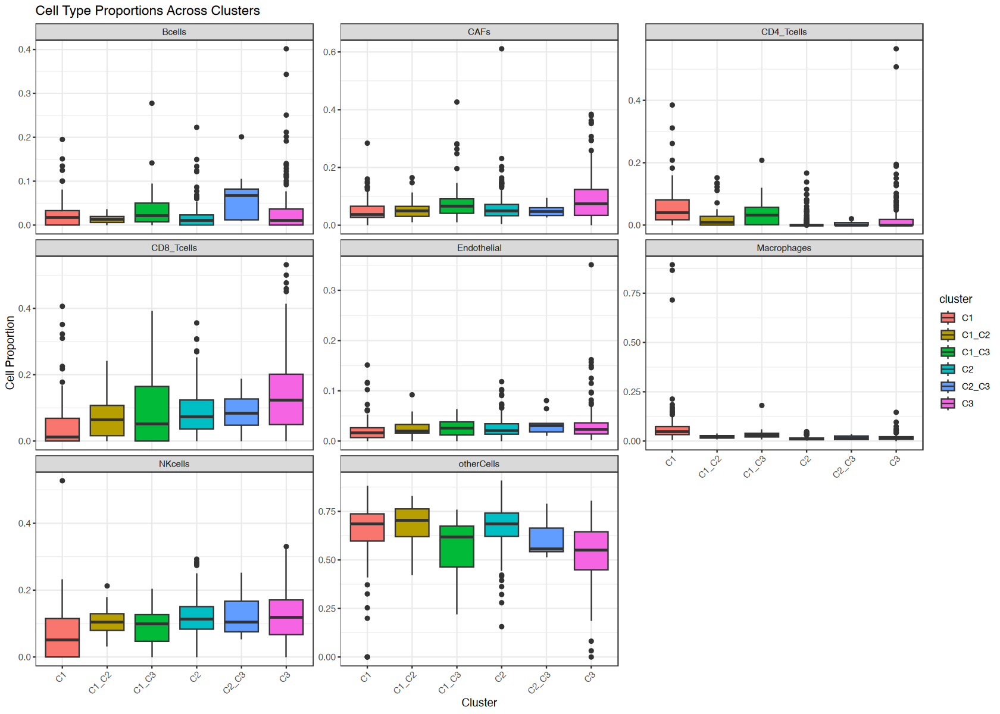

In [47]:
#=================================================
# 4. 不同分组间的细胞比例差异分析
#=================================================
library(ggplot2)
library(reshape2)
library(dplyr)

# 将数据转换为长格式，便于绘图和分析
cell_data_long <- reshape2::melt(cell_data, 
                                id.vars = "cluster",
                                variable.name = "cell_type",
                                value.name = "proportion")

# 查看转换后的数据结构
head(cell_data_long)

# 按分组和细胞类型计算平均比例和标准差
cell_stats <- cell_data_long %>%
  group_by(cluster, cell_type) %>%
  summarise(
    mean_prop = mean(proportion, na.rm = TRUE),
    sd_prop = sd(proportion, na.rm = TRUE),
    se_prop = sd_prop / sqrt(n()),
    n = n(),
    .groups = "drop"
  )

# 显示统计结果
print(cell_stats)

# 生成细胞比例的箱线图
ggplot(cell_data_long, aes(x = cluster, y = proportion, fill = cluster)) +
  geom_boxplot() +
  facet_wrap(~ cell_type, scales = "free_y") +
  theme_bw() +
  labs(
    x = "Cluster",
    y = "Cell Proportion",
    title = "Cell Type Proportions Across Clusters"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

ggsave("cell_proportions_by_cluster.pdf", width = 12, height = 10)

In [49]:
#=================================================
# 5. 统计分析：比较不同分组间的细胞比例差异
#=================================================
# 如果只有两个分组，可以使用t检验
if (length(unique(cell_data$cluster)) == 2) {
  cell_types <- colnames(cell_proportions)
  ttest_results <- data.frame()
  
  for (cell in cell_types) {
    formula <- as.formula(paste(cell, "~ cluster"))
    test_result <- t.test(formula, data = cell_data)
    
    result_row <- data.frame(
      cell_type = cell,
      p_value = test_result$p.value,
      mean_diff = diff(test_result$estimate),
      lower_ci = test_result$conf.int[1],
      upper_ci = test_result$conf.int[2]
    )
    
    ttest_results <- rbind(ttest_results, result_row)
  }
  
  # 添加FDR校正
  ttest_results$fdr <- p.adjust(ttest_results$p_value, method = "BH")
  
  # 排序并显示结果
  ttest_results <- ttest_results[order(ttest_results$p_value), ]
  print(ttest_results)
  
  # 保存结果
  write.csv(ttest_results, "epic_cell_diff_ttest.csv", row.names = FALSE)
}

# 如果有多个分组，使用ANOVA和事后检验
if (length(unique(cell_data$cluster)) > 2) {
  library(emmeans)
  
  cell_types <- colnames(cell_proportions)
  anova_results <- data.frame()
  
  for (cell in cell_types) {
    formula <- as.formula(paste(cell, "~ cluster"))
    aov_result <- aov(formula, data = cell_data)
    anova_summary <- summary(aov_result)[[1]]
    
    # ANOVA结果
    result_row <- data.frame(
      cell_type = cell,
      p_value = anova_summary$`Pr(>F)`[1],
      F_value = anova_summary$`F value`[1],
      df = paste(anova_summary$Df[1], anova_summary$Df[2], sep = ",")
    )
    
    anova_results <- rbind(anova_results, result_row)
    
    # 如果ANOVA显著，进行事后检验
    if (anova_summary$`Pr(>F)`[1] < 0.05) {
      # Tukey HSD事后检验
      tukey_result <- TukeyHSD(aov_result)
      print(paste("事后检验结果 -", cell))
      print(tukey_result)
      
      # 也可以使用emmeans包进行更灵活的事后分析
      # emm <- emmeans(aov_result, specs = "cluster")
      # pairs_result <- pairs(emm)
      # print(pairs_result)
    }
  }
  
  # 添加FDR校正
  anova_results$fdr <- p.adjust(anova_results$p_value, method = "BH")
  
  # 排序并显示结果
  anova_results <- anova_results[order(anova_results$p_value), ]
  print(anova_results)
  
  # 保存结果
  write.csv(anova_results, "epic_cell_diff_anova.csv", row.names = FALSE)
}



Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'



[1] "<U+4E8B><U+540E><U+68C0><U+9A8C><U+7ED3><U+679C> - Bcells"
  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = formula, data = cell_data)

$cluster
                    diff           lwr           upr     p adj
C1_C2-C1    -0.012787550 -0.0341280446  0.0085529449 0.5234606
C1_C3-C1     0.012798543 -0.0089388202  0.0345359067 0.5432948
C2-C1       -0.008196965 -0.0217370273  0.0053430977 0.5117711
C2_C3-C1     0.039209368 -0.0012968903  0.0797156261 0.0642055
C3-C1        0.006359619 -0.0080074601  0.0207266973 0.8036177
C1_C3-C1_C2  0.025586093 -0.0005644354  0.0517366216 0.0592471
C2-C1_C2     0.004590585 -0.0152757297  0.0244568998 0.9860533
C2_C3-C1_C2  0.051996918  0.0089609546  0.0950328809 0.0077565
C3-C1_C2     0.019147168 -0.0012917679  0.0395861048 0.0811120
C2-C1_C3    -0.020995508 -0.0412875438 -0.0007034723 0.0377108
C2_C3-C1_C3  0.026410825 -0.0168233098  0.0696449590 0.5014001
C3-C1_C3    -0.006438925 -0.0272918950  0.014414

Warning message:
"The input is a data frame, convert it to the matrix."
Warning message:
"argument `filename` is not supported in pheatmap -> Heatmap
translation, skip it."
Warning message:
"argument `width` is not supported in pheatmap -> Heatmap translation,
skip it."
Warning message:
"argument `height` is not supported in pheatmap -> Heatmap translation,
skip it."
Warning message:
"The input is a data frame, convert it to the matrix."
Warning message:
"argument `filename` is not supported in pheatmap -> Heatmap
translation, skip it."
Warning message:
"argument `width` is not supported in pheatmap -> Heatmap translation,
skip it."
Warning message:
"argument `height` is not supported in pheatmap -> Heatmap translation,
skip it."


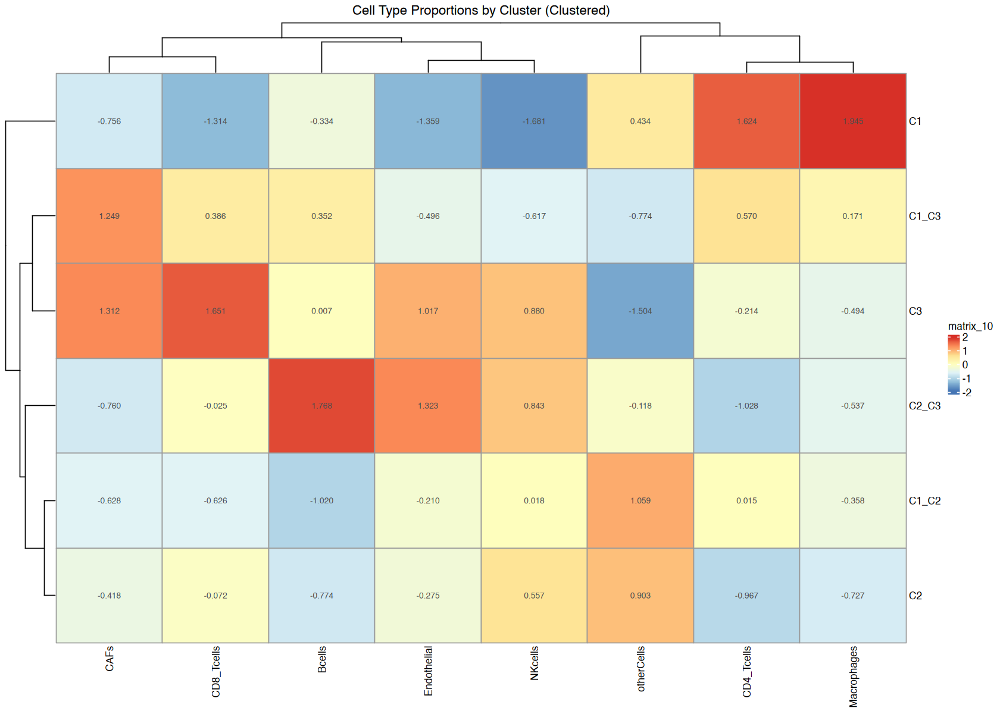

In [50]:
#=================================================
# 6. 可视化分析：热图展示不同分组的细胞组成
#=================================================
library(pheatmap)

# 计算每个分组的平均细胞比例
cluster_means <- aggregate(cell_proportions, by = list(Cluster = cell_data$cluster), mean)
rownames(cluster_means) <- cluster_means$Cluster
cluster_means <- cluster_means[, -1]

# 绘制热图
pheatmap(
  cluster_means,
  display_numbers = TRUE,
  number_format = "%.3f",
  main = "Mean Cell Type Proportions by Cluster",
  filename = "cell_proportions_heatmap.pdf",
  width = 10,
  height = 8
)

# 如果要对细胞类型或分组进行聚类
pheatmap(
  cluster_means,
  display_numbers = TRUE,
  number_format = "%.3f",
  main = "Cell Type Proportions by Cluster (Clustered)",
  cluster_rows = TRUE,
  cluster_cols = TRUE,
  scale = "column",  # 对列进行缩放，更容易比较细胞类型间的差异
  filename = "cell_proportions_heatmap_clustered.pdf",
  width = 10,
  height = 8
)

Warning message:
"argument `filename` is not supported in pheatmap -> Heatmap
translation, skip it."


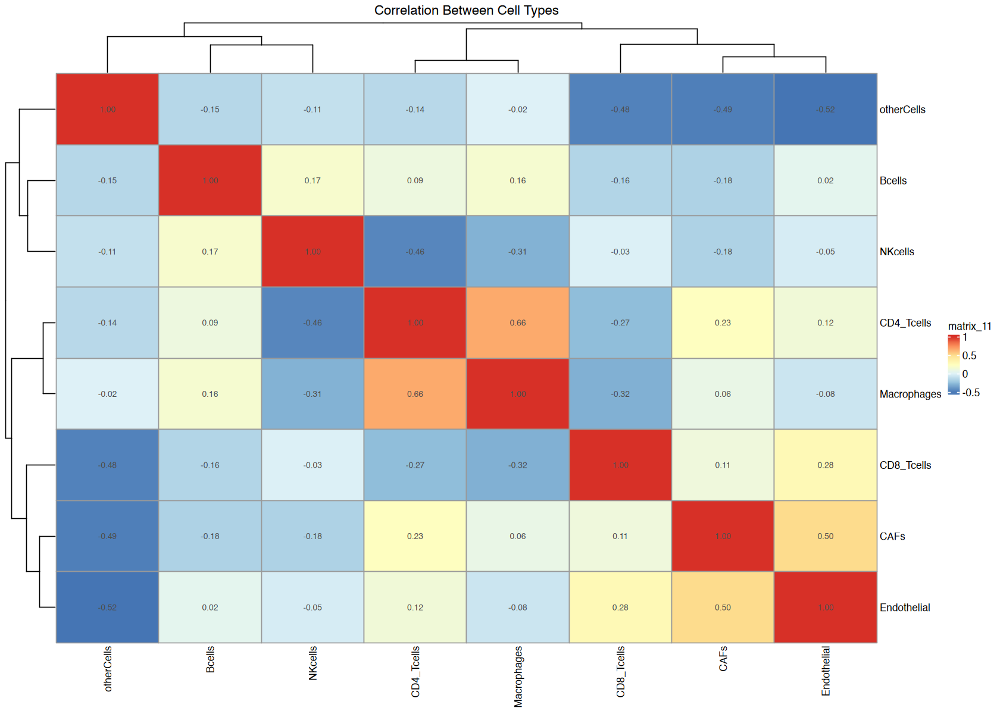

In [51]:
#=================================================
# 7. 相关性分析：细胞比例与临床指标的关联
#=================================================
# 如果有生存数据，可以分析细胞比例与生存的关系
if (exists("survival_data")) {
  library(survival)
  library(survminer)
  
  # 合并细胞比例和生存数据
  combined_data <- merge(cell_data, survival_data, by.x = 0, by.y = "sample_id")
  rownames(combined_data) <- combined_data$Row.names
  combined_data$Row.names <- NULL
  
  # 示例：T细胞比例与生存的关系
  # 假设survival_data包含time和status列
  if ("Tcells" %in% colnames(cell_proportions)) {
    # 根据T细胞比例中位数分组
    combined_data$Tcells_high <- combined_data$Tcells > median(combined_data$Tcells)
    
    # 生存分析
    surv_obj <- Surv(combined_data$time, combined_data$status)
    km_fit <- survfit(surv_obj ~ Tcells_high, data = combined_data)
    
    # 绘制K-M曲线
    ggsurvplot(
      km_fit,
      data = combined_data,
      pval = TRUE,
      conf.int = TRUE,
      risk.table = TRUE,
      xlab = "Time",
      ylab = "Survival Probability",
      title = "Survival by T Cell Proportion",
      legend.labs = c("Low T cells", "High T cells")
    )
    
    # 保存图像
    ggsave("Tcells_survival.pdf", width = 10, height = 8)
  }
}

# 绘制细胞比例相关性热图
cell_cor <- cor(cell_proportions, method = "spearman")
pheatmap(
  cell_cor,
  display_numbers = TRUE,
  main = "Correlation Between Cell Types",
  filename = "cell_type_correlation.pdf"
)

In [52]:
#=================================================
# 8. 细胞比例与其他分子特征的关联
#=================================================
# 如果有其他分子数据，如基因表达、突变状态等
if (exists("molecular_features")) {
  # 合并数据
  combined_molec <- merge(cell_data, molecular_features, by.x = 0, by.y = "sample_id")
  rownames(combined_molec) <- combined_molec$Row.names
  combined_molec$Row.names <- NULL
  
  # 示例：计算细胞比例与分子特征的相关性
  # 假设molecular_features包含感兴趣的基因或特征
  features_of_interest <- colnames(molecular_features)[-1]  # 排除样本ID列
  
  corr_results <- data.frame()
  
  for (cell in colnames(cell_proportions)) {
    for (feature in features_of_interest) {
      # 跳过非数值列
      if (!is.numeric(combined_molec[[feature]])) next
      
      cor_test <- cor.test(combined_molec[[cell]], combined_molec[[feature]], 
                         method = "spearman")
      
      result_row <- data.frame(
        cell_type = cell,
        feature = feature,
        correlation = cor_test$estimate,
        p_value = cor_test$p.value
      )
      
      corr_results <- rbind(corr_results, result_row)
    }
  }
  
  # 添加FDR校正
  corr_results$fdr <- p.adjust(corr_results$p_value, method = "BH")
  
  # 排序并显示结果
  corr_results <- corr_results[order(corr_results$p_value), ]
  print(head(corr_results, 20))
  
  # 保存结果
  write.csv(corr_results, "cell_proportion_feature_correlations.csv", row.names = FALSE)
}

In [53]:
#=================================================
# 9. 总结报告
#=================================================
cat("\n=== EPIC细胞比例分析完成 ===\n")
cat("分析的样本数:", nrow(cell_data), "\n")
cat("分组数量:", length(unique(cell_data$cluster)), "\n")
cat("细胞类型数量:", ncol(cell_proportions), "\n")
cat("预测的细胞类型:", paste(colnames(cell_proportions), collapse=", "), "\n\n")

cat("各分组样本数:\n")
print(table(cell_data$cluster))

cat("\n细胞比例汇总统计:\n")
summary_stats <- aggregate(cell_proportions, by = list(Cluster = cell_data$cluster), 
                          function(x) c(mean = mean(x), sd = sd(x)))
print(summary_stats)

cat("\n完整结果已保存为CSV文件\n")


=== EPIC<U+7EC6><U+80DE><U+6BD4><U+4F8B><U+5206><U+6790><U+5B8C><U+6210> ===
<U+5206><U+6790><U+7684><U+6837><U+672C><U+6570>: 586 
<U+5206><U+7EC4><U+6570><U+91CF>: 6 
<U+7EC6><U+80DE><U+7C7B><U+578B><U+6570><U+91CF>: 8 
<U+9884><U+6D4B><U+7684><U+7EC6><U+80DE><U+7C7B><U+578B>: Bcells, CAFs, CD4_Tcells, CD8_Tcells, Endothelial, Macrophages, NKcells, otherCells 

<U+5404><U+5206><U+7EC4><U+6837><U+672C><U+6570>:

   C1 C1_C2 C1_C3    C2 C2_C3    C3 
  112    41    39   223     9   162 

<U+7EC6><U+80DE><U+6BD4><U+4F8B><U+6C47><U+603B><U+7EDF><U+8BA1>:
  Cluster Bcells.mean  Bcells.sd  CAFs.mean    CAFs.sd CD4_Tcells.mean
1      C1  0.02588506 0.03371083 0.05218090 0.04185717     0.059258396
2   C1_C2  0.01309751 0.01008150 0.05480783 0.03241631     0.026901275
3   C1_C3  0.03868360 0.05103895 0.09342923 0.09090967     0.038068770
4      C2  0.01768809 0.02667994 0.05913352 0.05266765     0.007167386
5   C2_C3  0.06509443 0.06208300 0.05208657 0.02270990     0.005946880
6      C3  0.03

### Drug sensitivity

In [11]:
# --- 第0步：安装和加载包 ---
# oncoPredict 通常从GitHub安装以获取最新版本
# install.packages("devtools")
# devtools::install_github("marcin-krystian/oncoPredict")
library(oncoPredict)
library(ggplot2)
library(ggpubr)
library(dplyr)
library(readr)

In [12]:
# --- 第1步：下载并加载预处理好的训练数据 (GDSC2) ---
# 这个步骤只需要运行一次，之后就可以直接加载本地文件
data_dir <- "oncoPredict_data"
if (!dir.exists(data_dir)) {
  dir.create(data_dir)
}

In [14]:
cat("--- 正在加载GDSC2训练数据 ---\n")
GDSC2_Expr <- readRDS(file = "./oncoPredict_data/Training Data/GDSC2_Expr (RMA Normalized and Log Transformed).rds")
GDSC2_Res <- readRDS(file = "./oncoPredict_data/Training Data/GDSC2_Res.rds")

--- <U+6B63><U+5728><U+52A0><U+8F7D>GDSC2<U+8BAD><U+7EC3><U+6570><U+636E> ---


In [15]:
dim(GDSC2_Expr)
head(GDSC2_Expr)

[1] 17419   805

,COSMIC_906826,COSMIC_687983,COSMIC_910927,COSMIC_1240138,COSMIC_906792,COSMIC_910688,COSMIC_1240135,COSMIC_1290812,COSMIC_907045,COSMIC_906861,...,COSMIC_1299062,COSMIC_908458,COSMIC_753584,COSMIC_907044,COSMIC_998184,COSMIC_908145,COSMIC_1298157,COSMIC_1480372,COSMIC_1298533,COSMIC_930299
TSPAN6,7.632023,7.548671,8.712338,7.797142,7.074533,3.285198,6.961606,5.943046,3.455951,9.021458,...,6.287819,3.607123,7.105637,3.236503,3.038892,8.373223,8.441628,8.422922,8.089255,3.112333
TNMD,2.964585,2.777716,2.643508,2.817923,2.889677,2.828203,2.874751,2.686874,3.290184,3.098198,...,2.842090,2.866483,2.798847,2.745137,2.976406,2.852552,2.639276,2.879890,2.521169,2.870468
DPM1,10.379553,11.807341,9.880733,9.883471,9.773987,10.264385,10.205931,10.299757,11.570155,10.061110,...,10.370130,10.246750,10.486486,10.442951,10.311962,10.454830,11.463742,10.557777,10.792750,9.873902
SCYL3,3.614794,4.066887,3.956230,4.063701,4.270903,5.968168,3.715033,3.848112,5.560883,3.879039,...,3.789814,3.780485,3.696835,4.624013,4.348524,3.858121,4.425849,3.550390,4.443337,4.266828
C1orf112,3.380681,3.732485,3.236620,3.558414,3.815055,3.011867,3.268449,3.352835,3.571228,3.667935,...,3.318119,3.499160,3.726833,3.947744,3.806584,3.196988,4.384732,4.247189,3.071359,3.230197
FGR,3.324692,3.152404,3.241246,3.101247,3.298915,9.565308,3.036333,3.278688,3.370885,3.276530,...,3.154849,3.056503,3.245301,8.969347,3.562548,3.098083,3.229511,3.176336,3.238305,3.027742


In [16]:
dim(GDSC2_Res)
head(GDSC2_Res)

[1] 805 198

,Camptothecin_1003,Vinblastine_1004,Cisplatin_1005,Cytarabine_1006,Docetaxel_1007,Gefitinib_1010,Navitoclax_1011,Vorinostat_1012,Nilotinib_1013,Olaparib_1017,...,VX-11e_2096,Uprosertib_2106,LJI308_2107,AZ6102_2109,GSK591_2110,VE821_2111,AZD6482_2169,AT13148_2170,BMS-754807_2171,JQ1_2172
COSMIC_906826,-1.152528,-1.566172,7.017559,2.917980,-2.938261,5.705252,-0.199978,2.521175,3.358315,7.104088,...,4.525139,4.732755,6.573919,4.218150,6.220616,7.046352,4.991534,5.874982,NA,7.372875
COSMIC_687983,-1.263248,-4.292974,3.286848,2.790819,-4.403053,3.555591,2.619336,1.554930,3.859502,4.128832,...,3.166693,2.576740,5.537851,1.853308,5.480431,5.359617,NA,3.601838,NA,NA
COSMIC_910927,-3.521093,-5.008028,2.492692,-1.082517,-4.886498,3.093045,1.398764,1.293609,1.558438,3.422137,...,2.496956,1.189962,4.798304,1.913550,3.605307,2.103111,5.497304,2.549963,NA,3.708490
COSMIC_1240138,1.976381,NA,NA,NA,NA,NA,NA,NA,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
COSMIC_906792,-3.757428,-5.549113,2.857686,0.168482,-7.002460,3.008980,1.827037,1.241993,3.486873,2.300463,...,2.544676,1.588311,4.514789,1.105506,4.636412,4.293782,NA,3.982625,NA,NA
COSMIC_910688,-5.125983,-5.970202,0.316507,-2.102468,-6.514316,2.669753,-1.320521,0.277405,1.334536,1.576889,...,3.472644,2.005014,3.492298,2.165862,3.936603,2.975474,NA,3.555176,NA,NA


In [17]:
head(corrected_expr_limma)

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
TMSB10,10.82928,10.890999,11.94522,12.778273,10.995143,11.226208,10.035329,10.398659,11.30408,12.16933,...,10.99660,11.026177,11.094798,12.008558,11.481356,12.627119,11.769922,11.4156781,11.201563,9.495304
ALB,12.05004,13.178437,10.79637,5.770313,7.063872,4.553839,12.638745,12.447035,10.08065,10.02450,...,11.00465,12.196094,10.683190,12.497491,2.410946,8.453237,7.411365,0.4926482,12.583942,7.533481
FTL,10.66605,12.897749,11.72236,11.072817,12.143254,12.137395,13.854919,12.317509,11.09063,11.08043,...,11.76724,9.781075,10.558542,10.432385,12.301201,12.339945,13.363718,11.6431148,10.730668,11.445058
S100A6,10.31944,5.593509,11.54254,10.995845,11.064880,10.134493,7.784021,10.904630,10.58029,10.69710,...,10.62347,10.704640,8.700956,7.914385,12.343699,11.888619,10.589558,8.2747927,8.948155,8.407319
RPS18,10.09080,10.167330,10.44833,10.278913,9.563777,9.050844,9.202332,9.774162,11.49839,10.09671,...,10.64097,11.134008,9.614914,10.565745,9.542747,9.639386,9.873656,11.1388385,10.614570,9.653813
TMSB4X,10.61613,10.408689,11.31893,11.724414,11.308622,11.295856,10.777988,11.413705,10.88848,11.85332,...,10.43501,10.587907,10.379686,11.303271,11.737150,11.998210,10.570807,12.4690672,10.863712,9.242494


In [20]:
# --- 第3步：运行oncoPredict进行预测 ---
cat("\n--- 正在使用oncoPredict进行药物敏感性预测 ---\n")
# testExprData: 您的肿瘤表达数据
# trainingExprData: GDSC2的表达数据
# trainingPtypeData: GDSC2的药物响应数据 (IC50或AUC)
predicted_scores <- calcPhenotype(
  trainingExprData = GDSC2_Expr,
  trainingPtype = GDSC2_Res,
  testExprData = corrected_expr_limma,
  batchCorrect = "eb",
  powerTransformPhenotype=TRUE,
  removeLowVaryingGenes=0.2,
  removeLowVaringGenesFrom="homogenizeData",
  minNumSamples=10,
  selection = 1 ,
  printOutput=TRUE,
  pcr=FALSE,
  report_pc=FALSE,
  rsq=FALSE,
  percent=80
)


--- <U+6B63><U+5728><U+4F7F><U+7528>oncoPredict<U+8FDB><U+884C><U+836F><U+7269><U+654F><U+611F><U+6027><U+9884><U+6D4B> ---



 9821  gene identifiers overlap between the supplied expression matrices... 
 

Found2batches

Adjusting for0covariate(s) or covariate level(s)

Standardizing Data across genes

Fitting L/S model and finding priors

Finding parametric adjustments

Adjusting the Data



 1965 low variabilty genes filtered.


Fitting Ridge Regression model...


Calculating predicted phenotype...


Done making prediction for drug 1 of 198


Fitting Ridge Regression model...


Calculating predicted phenotype...


Done making prediction for drug 2 of 198


Fitting Ridge Regression model...


Calculating predicted phenotype...


Done making prediction for drug 3 of 198


Fitting Ridge Regression model...


Calculating predicted phenotype...


Done making prediction for drug 4 of 198


Fitting Ridge Regression model...


Calculating predicted phenotype...


Done making prediction for drug 5 of 198


Fitting Ridge Regression model...


Calculating predicted phenotype...


Done making prediction for drug 6 of 

In [20]:
# --- 第4步：整理并可视化结果 ---
# 结果是一个矩阵，行是样本，列是药物
ic50_df <- read.csv(file = "./calcPhenotype_Output/DrugPredictions.csv",row.names = 1)
head(ic50_df)

,Camptothecin_1003,Vinblastine_1004,Cisplatin_1005,Cytarabine_1006,Docetaxel_1007,Gefitinib_1010,Navitoclax_1011,Vorinostat_1012,Nilotinib_1013,Olaparib_1017,...,VX.11e_2096,Uprosertib_2106,LJI308_2107,AZ6102_2109,GSK591_2110,VE821_2111,AZD6482_2169,AT13148_2170,BMS.754807_2171,JQ1_2172
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GSM2883928,-1.976622,-3.557886,3.362819,1.6905749,-4.911532,2.264249,1.265463,1.070169,3.709094,4.395822,...,2.518440,1.962341,5.048117,1.847963,4.763346,4.133535,3.237416,3.032898,0.460779939,2.228822
GSM2883929,-1.777923,-3.780984,3.390185,1.7969323,-4.351748,3.229416,1.830978,1.023823,3.029299,4.338572,...,2.875198,2.230564,4.964706,2.409792,4.533151,4.006079,3.376085,3.047595,0.176961334,2.090185
GSM2883930,-2.852306,-3.708054,3.115211,1.6541812,-4.438301,3.636469,2.671559,2.062438,4.157320,4.624902,...,2.487257,3.448166,5.471860,2.672987,4.830228,4.349237,3.313408,4.346863,0.186550956,2.854010
GSM2883931,-2.324878,-4.665168,3.093879,1.3475117,-5.403258,3.402271,3.201450,1.662609,3.653789,4.179180,...,2.425238,3.736900,5.188597,2.692148,4.255035,3.635391,3.601586,3.950601,0.698295258,2.785648
GSM2883932,-2.827196,-4.588460,2.956460,0.8187973,-5.172095,2.850357,1.370010,1.506393,3.540148,4.015005,...,2.130831,2.637846,5.114900,2.218545,4.360469,3.460773,2.911988,3.443966,0.008482789,2.130601
GSM2883933,-2.483996,-3.520316,3.351587,1.8980606,-4.371571,3.299697,2.044650,1.313861,4.003555,4.694893,...,2.623712,2.953415,5.479975,3.027950,4.812954,4.478415,3.178060,4.590973,0.882482406,3.115214


In [21]:
sample_sub <- sample_cluster %>% select(Sample, Ensemble)

In [22]:
# 与亚型信息合并
ic50_df$SampleID <- rownames(ic50_df)
full_drug_data <- inner_join(sample_sub, ic50_df, by = c("Sample" = "SampleID"))
head(full_drug_data)

Sample,Ensemble,Camptothecin_1003,Vinblastine_1004,Cisplatin_1005,Cytarabine_1006,Docetaxel_1007,Gefitinib_1010,Navitoclax_1011,Vorinostat_1012,...,VX.11e_2096,Uprosertib_2106,LJI308_2107,AZ6102_2109,GSK591_2110,VE821_2111,AZD6482_2169,AT13148_2170,BMS.754807_2171,JQ1_2172
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,C2_C3,-2.544741,-4.462140,2.760441,1.273610,-5.192748,3.647424,2.722644,1.248311,...,2.796480,2.701909,4.973226,2.644635,4.375766,4.052236,3.255713,3.123800,0.2650429,2.441937
113,C2,-1.297142,-2.359235,4.394331,3.465491,-3.550025,3.857511,3.576874,1.765795,...,3.283345,3.713926,6.043105,3.580797,5.239514,5.525842,3.827239,5.655670,1.1007976,3.451443
115,C1,-1.330790,-2.122570,4.265188,2.966055,-3.337715,3.695155,2.077842,1.473303,...,3.599641,2.523678,5.423466,3.040202,4.926084,4.807267,3.258660,3.798461,0.6805672,2.151816
117,C1,-1.562138,-3.111766,3.901744,2.114558,-3.681379,3.701026,1.680300,1.135506,...,3.691751,2.860669,5.639247,2.388830,4.929919,4.496971,3.697068,3.572159,0.8304809,2.558958
121,C2,-1.835798,-3.097403,3.703273,1.939950,-3.990370,3.206096,1.820549,1.280421,...,3.204160,3.280807,5.032818,2.200763,4.657587,4.378581,3.749521,3.695947,0.7111988,2.786604
123,C1,-2.779890,-3.555830,2.615333,1.418308,-4.369219,2.803387,2.111102,1.664228,...,3.187169,2.663318,4.699736,2.298710,4.511852,3.923225,2.802796,3.026373,0.6876473,2.145314


In [36]:
# 选择我们之前讨论过的药物进行可视化
# 注意：药物名称在GDSC2中可能包含版本号，如 "Trametinib_1065"
# 我们可以用 grepl 来模糊匹配
# iCCA临床上常用的一线或二线化疗药物:Gemcitabine (吉西他滨),Cisplatin (顺铂),Oxaliplatin (奥沙利铂),5-Fluorouracil (5-氟尿嘧啶)
# FGFR抑制剂: 如 Pemigatinib, Infigratinib
# IDH1抑制剂: 如 Ivosidenib 
curated_drug_list_patterns <- c("Cisplatin", "Gemcitabine", "Oxaliplatin","Fluorouracil", # 临床/靶向相关
                                "Ivosidenib",
                                "Pemigatinib", "Infigratinib", "Enasidenib", "Rucaparib",  # FGFR抑制剂
                                "Olaparib","AZD6738",               # C1(TP53) 假设
                                "Palbociclib", "Alisertib",         # C2(增殖) 假设
                                "Trametinib", "Selumetinib","Ulixertinib","Pictilisib","Afatinib"  # C3(KRAS) 假设
                               )

In [38]:
# 从所有药物列中找到实际存在的列名
actual_drug_columns <- unique(unlist(sapply(curated_drug_list_patterns, function(pattern) {
  grep(pattern, colnames(full_drug_data), ignore.case = TRUE, value = TRUE)
})))
if(length(actual_drug_columns) == 0) {
  stop("在您的数据中找不到任何预选的药物，请检查药物名称。")
}

cat("找到以下核心药物进行分析:\n")
print(actual_drug_columns)

<U+627E><U+5230><U+4EE5><U+4E0B><U+6838><U+5FC3><U+836F><U+7269><U+8FDB><U+884C><U+5206><U+6790>:
 [1] "Cisplatin_1005"       "Gemcitabine_1190"     "Oxaliplatin_1089"    
 [4] "Oxaliplatin_1806"     "X5.Fluorouracil_1073" "Olaparib_1017"       
 [7] "AZD6738_1917"         "Palbociclib_1054"     "Alisertib_1051"      
[10] "Trametinib_1372"      "Selumetinib_1736"     "Ulixertinib_1908"    
[13] "Ulixertinib_2047"     "Pictilisib_1058"      "Afatinib_1032"       


In [41]:
# 准备用于绘图的数据
plot_data_curated <- full_drug_data %>%
  select(Ensemble, all_of(actual_drug_columns)) %>%
  tidyr::pivot_longer(
    cols = -Ensemble,
    names_to = "Drug",
    values_to = "Predicted_Response" # oncoPredict的得分，值越小越敏感
  )

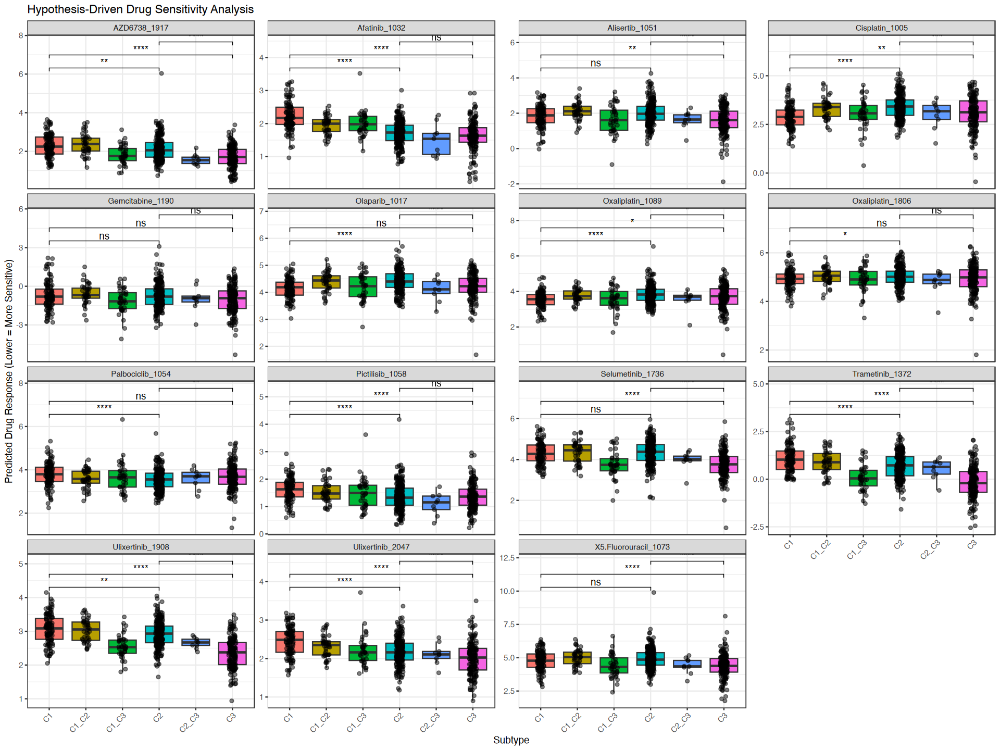

In [44]:
# 3. 绘制箱线图进行可视化和统计比较
options(repr.plot.width=16, repr.plot.height=12)
ggplot(plot_data_curated, aes(x = Ensemble, y = Predicted_Response, fill = Ensemble)) +
  geom_boxplot(outlier.shape = NA) +
  geom_jitter(width = 0.1, alpha = 0.5) +
  facet_wrap(~ Drug, scales = "free_y", ncol = 4) + # 每行最多显示4个药物
  stat_compare_means(
    comparisons = list(c("C1", "C2"), c("C1", "C3"), c("C2", "C3")), # 您可以按需修改比较组
    method = "wilcox.test",
    label = "p.signif" # 显示 *, **, ***
  ) +
  labs(
    title = "Hypothesis-Driven Drug Sensitivity Analysis",
    x = "Subtype",
    y = "Predicted Drug Response (Lower = More Sensitive)"
  ) +
  theme_bw() +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 45, hjust = 1) # 旋转X轴标签
  )

In [23]:
# 1. 准备数据：提取所有药物的预测结果
all_drug_matrix <- full_drug_data %>%
  tibble::column_to_rownames("Sample") %>%
  select(-Ensemble) %>% 
  as.matrix()

In [24]:
head(all_drug_matrix)

,Camptothecin_1003,Vinblastine_1004,Cisplatin_1005,Cytarabine_1006,Docetaxel_1007,Gefitinib_1010,Navitoclax_1011,Vorinostat_1012,Nilotinib_1013,Olaparib_1017,...,VX.11e_2096,Uprosertib_2106,LJI308_2107,AZ6102_2109,GSK591_2110,VE821_2111,AZD6482_2169,AT13148_2170,BMS.754807_2171,JQ1_2172
111,-2.544741,-4.462140,2.760441,1.273610,-5.192748,3.647424,2.722644,1.248311,3.166381,3.949610,...,2.796480,2.701909,4.973226,2.644635,4.375766,4.052236,3.255713,3.123800,0.2650429,2.441937
113,-1.297142,-2.359235,4.394331,3.465491,-3.550025,3.857511,3.576874,1.765795,4.299770,5.331178,...,3.283345,3.713926,6.043105,3.580797,5.239514,5.525842,3.827239,5.655670,1.1007976,3.451443
115,-1.330790,-2.122570,4.265188,2.966055,-3.337715,3.695155,2.077842,1.473303,4.198457,4.483012,...,3.599641,2.523678,5.423466,3.040202,4.926084,4.807267,3.258660,3.798461,0.6805672,2.151816
117,-1.562138,-3.111766,3.901744,2.114558,-3.681379,3.701026,1.680300,1.135506,3.723013,4.637770,...,3.691751,2.860669,5.639247,2.388830,4.929919,4.496971,3.697068,3.572159,0.8304809,2.558958
121,-1.835798,-3.097403,3.703273,1.939950,-3.990370,3.206096,1.820549,1.280421,3.379980,4.559512,...,3.204160,3.280807,5.032818,2.200763,4.657587,4.378581,3.749521,3.695947,0.7111988,2.786604
123,-2.779890,-3.555830,2.615333,1.418308,-4.369219,2.803387,2.111102,1.664228,3.753528,4.375705,...,3.187169,2.663318,4.699736,2.298710,4.511852,3.923225,2.802796,3.026373,0.6876473,2.145314


In [60]:
# 2. 对每种药物进行统计检验 (Kruskal-Wallis test)
# Kruskal-Wallis检验可以告诉我们某个药物的敏感性得分在三个或更多组之间是否存在显著差异
p_values <- apply(all_drug_matrix, 2, function(drug_responses) {
  kruskal.test(drug_responses ~ full_drug_data$Ensemble)$p.value
})

In [61]:
# 3. 创建结果表，并按p值排序
drug_screen_results <- data.frame(
  Drug = names(p_values),
  P_value = p_values
) %>%
  arrange(P_value)

In [62]:
cat("\n--- 无偏筛选出的Top 10差异最显著药物 ---\n")
print(head(drug_screen_results, 10))


--- <U+65E0><U+504F><U+7B5B><U+9009><U+51FA><U+7684>Top 10<U+5DEE><U+5F02><U+6700><U+663E><U+8457><U+836F><U+7269> ---
                                               Drug      P_value
TAF1_5496_1732                       TAF1_5496_1732 7.056350e-40
Sepantronium.bromide_1941 Sepantronium.bromide_1941 3.114049e-38
Savolitinib_1936                   Savolitinib_1936 1.126794e-37
SB505124_1194                         SB505124_1194 1.850886e-37
Ulixertinib_1908                   Ulixertinib_1908 6.351669e-37
Trametinib_1372                     Trametinib_1372 3.285231e-34
OF.1_1853                                 OF.1_1853 2.457655e-32
SCH772984_1564                       SCH772984_1564 2.725387e-32
Afatinib_1032                         Afatinib_1032 1.036557e-29
Dihydrorotenone_1827           Dihydrorotenone_1827 1.068064e-29


In [66]:
# 4. 挑选差异最显著的Top 20药物进行热图可视化
top_50_drugs <- head(drug_screen_results, 50)$Drug

In [71]:
head(full_drug_data)

Sample,Ensemble,Camptothecin_1003,Vinblastine_1004,Cisplatin_1005,Cytarabine_1006,Docetaxel_1007,Gefitinib_1010,Navitoclax_1011,Vorinostat_1012,...,VX.11e_2096,Uprosertib_2106,LJI308_2107,AZ6102_2109,GSK591_2110,VE821_2111,AZD6482_2169,AT13148_2170,BMS.754807_2171,JQ1_2172
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,C2_C3,-2.544741,-4.462140,2.760441,1.273610,-5.192748,3.647424,2.722644,1.248311,...,2.796480,2.701909,4.973226,2.644635,4.375766,4.052236,3.255713,3.123800,0.2650429,2.441937
113,C2,-1.297142,-2.359235,4.394331,3.465491,-3.550025,3.857511,3.576874,1.765795,...,3.283345,3.713926,6.043105,3.580797,5.239514,5.525842,3.827239,5.655670,1.1007976,3.451443
115,C1,-1.330790,-2.122570,4.265188,2.966055,-3.337715,3.695155,2.077842,1.473303,...,3.599641,2.523678,5.423466,3.040202,4.926084,4.807267,3.258660,3.798461,0.6805672,2.151816
117,C1,-1.562138,-3.111766,3.901744,2.114558,-3.681379,3.701026,1.680300,1.135506,...,3.691751,2.860669,5.639247,2.388830,4.929919,4.496971,3.697068,3.572159,0.8304809,2.558958
121,C2,-1.835798,-3.097403,3.703273,1.939950,-3.990370,3.206096,1.820549,1.280421,...,3.204160,3.280807,5.032818,2.200763,4.657587,4.378581,3.749521,3.695947,0.7111988,2.786604
123,C1,-2.779890,-3.555830,2.615333,1.418308,-4.369219,2.803387,2.111102,1.664228,...,3.187169,2.663318,4.699736,2.298710,4.511852,3.923225,2.802796,3.026373,0.6876473,2.145314


In [82]:
# 准备热图的矩阵和注释
heatmap_matrix <- all_drug_matrix[, top_50_drugs] # 药物为行，样本为列
annotation_df <- data.frame(
  Subtype = full_drug_data$Ensemble,
  row.names = full_drug_data$Sample
)

In [89]:
library(circlize)
library(ComplexHeatmap)
col_fun <- colorRamp2(c(-2, 0, 2), c("#2166AC", "#F7FBFF", "#B2182B")) # 冷暖对比

# 组合两个 top annotation
top_annotation <- HeatmapAnnotation(
  Subtype = annotation_df$Subtype,
  col = list(
        Subtype = c("C1"="#A6C2E0", "C2"="#C2E0A6", "C3"="#E0A6C2", "C1_C2"="#E0C2A6", "C1_C3"="#A6E0C2", "C2_C3"="#C2A6E0")
  ),
  #gp = gpar(col = "white"),
  annotation_name_side = "right",
  annotation_name_gp = gpar(fontsize = 8), # 调整注释标题字体大小
  simple_anno_size = unit(0.4, "cm")      # 调整每个注释层的高度
)

pdf(file = "./Heatmap_drug_sensitivity.pdf", width = 10, height = 12)  # 增加了高度以适应新的annotation
ht_obj <- draw(
        Heatmap(t(scale(heatmap_matrix)),
        border = FALSE,
        show_column_names = FALSE,
        show_row_names = TRUE,
        use_raster = FALSE,
        col = col_fun,
        column_title = NULL,
        column_split = factor(annotation_df$Subtype, levels = c("C1","C1_C2","C1_C3","C2","C2_C3","C3")),
        top_annotation = top_annotation,
        cluster_column_slices = FALSE,
        cluster_columns = TRUE,
        show_row_dend = FALSE,
        show_column_dend = FALSE,
        show_heatmap_legend = TRUE,
        heatmap_legend_param = list(
                title = bquote(~'sensitivity score'),
                title_gp = gpar(col = "black", cex = 0.75),
                title_position = "leftcenter-rot")
        )
)
dev.off()

agg_record_1350071021 
                    2

In [90]:
head(full_drug_data)

Sample,Ensemble,Camptothecin_1003,Vinblastine_1004,Cisplatin_1005,Cytarabine_1006,Docetaxel_1007,Gefitinib_1010,Navitoclax_1011,Vorinostat_1012,...,VX.11e_2096,Uprosertib_2106,LJI308_2107,AZ6102_2109,GSK591_2110,VE821_2111,AZD6482_2169,AT13148_2170,BMS.754807_2171,JQ1_2172
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,C2_C3,-2.544741,-4.462140,2.760441,1.273610,-5.192748,3.647424,2.722644,1.248311,...,2.796480,2.701909,4.973226,2.644635,4.375766,4.052236,3.255713,3.123800,0.2650429,2.441937
113,C2,-1.297142,-2.359235,4.394331,3.465491,-3.550025,3.857511,3.576874,1.765795,...,3.283345,3.713926,6.043105,3.580797,5.239514,5.525842,3.827239,5.655670,1.1007976,3.451443
115,C1,-1.330790,-2.122570,4.265188,2.966055,-3.337715,3.695155,2.077842,1.473303,...,3.599641,2.523678,5.423466,3.040202,4.926084,4.807267,3.258660,3.798461,0.6805672,2.151816
117,C1,-1.562138,-3.111766,3.901744,2.114558,-3.681379,3.701026,1.680300,1.135506,...,3.691751,2.860669,5.639247,2.388830,4.929919,4.496971,3.697068,3.572159,0.8304809,2.558958
121,C2,-1.835798,-3.097403,3.703273,1.939950,-3.990370,3.206096,1.820549,1.280421,...,3.204160,3.280807,5.032818,2.200763,4.657587,4.378581,3.749521,3.695947,0.7111988,2.786604
123,C1,-2.779890,-3.555830,2.615333,1.418308,-4.369219,2.803387,2.111102,1.664228,...,3.187169,2.663318,4.699736,2.298710,4.511852,3.923225,2.802796,3.026373,0.6876473,2.145314


In [25]:
# --- 第1步：进行循环统计分析，为每个亚型寻找敏感药物 ---

cat("--- 开始进行差异药物敏感性分析 ---\n")

# 获取所有亚型和药物的名称
all_subtypes <- unique(full_drug_data$Ensemble)
all_drugs <- colnames(full_drug_data)[!colnames(full_drug_data) %in% c("Sample", "Ensemble")]

# 创建一个列表来存储每个亚型的分析结果
subtype_sensitivity_results <- list()

# 首先确认敏感性得分的方向 (根据oncoPredict文档，较低值通常表示更敏感)
cat("注意：本分析假设较低的药物敏感性得分表示更敏感。\n")

# 外层循环：遍历每一个亚型
for (subtype in all_subtypes) {
  
  cat(paste("正在分析亚型:", subtype, "vs. Others\n"))
  
  # 为当前亚型创建一个临时分组列
  temp_data <- full_drug_data %>%
    mutate(Group = ifelse(Ensemble == subtype, subtype, "Others"))
  
  # 内层循环：对每一种药物进行检验
  drug_p_values <- lapply(all_drugs, function(drug) {
    
    # 获取当前药物的数据，移除可能的NA值
    drug_data <- temp_data %>% 
      filter(!is.na(.data[[drug]]))
    
    # 检查每组是否有足够的样本
    n_subtype <- sum(drug_data$Group == subtype)
    n_others <- sum(drug_data$Group == "Others")
    
    if(n_subtype < 3 || n_others < 3) {
      return(data.frame(
        Drug = drug,
        p.value = NA,
        median_subtype = NA,
        median_others = NA,
        sample_size_subtype = n_subtype,
        sample_size_others = n_others,
        test_performed = FALSE
      ))
    }
    
    # 检查极端值并考虑剔除
    q1_subtype <- quantile(drug_data[[drug]][drug_data$Group == subtype], 0.25)
    q3_subtype <- quantile(drug_data[[drug]][drug_data$Group == subtype], 0.75)
    iqr_subtype <- q3_subtype - q1_subtype
    
    q1_others <- quantile(drug_data[[drug]][drug_data$Group == "Others"], 0.25)
    q3_others <- quantile(drug_data[[drug]][drug_data$Group == "Others"], 0.75)
    iqr_others <- q3_others - q1_others
    
    # 标记极端值但不移除，仅做记录
    outliers_subtype <- sum(drug_data[[drug]][drug_data$Group == subtype] < (q1_subtype - 1.5 * iqr_subtype) | 
                          drug_data[[drug]][drug_data$Group == subtype] > (q3_subtype + 1.5 * iqr_subtype))
    
    outliers_others <- sum(drug_data[[drug]][drug_data$Group == "Others"] < (q1_others - 1.5 * iqr_others) | 
                         drug_data[[drug]][drug_data$Group == "Others"] > (q3_others + 1.5 * iqr_others))
    
    # 执行Wilcoxon检验
    test_result <- wilcox.test(
      as.formula(paste0("`", drug, "` ~ Group")), 
      data = drug_data
    )
    
    # 计算当前亚型和其他亚型的中位数敏感性得分
    median_subtype <- median(drug_data[[drug]][drug_data$Group == subtype], na.rm = TRUE)
    median_others <- median(drug_data[[drug]][drug_data$Group == "Others"], na.rm = TRUE)
    
    # 计算平均秩和（为了获得更稳健的效应大小度量）
    mean_rank_subtype <- mean(rank(drug_data[[drug]])[drug_data$Group == subtype])
    mean_rank_others <- mean(rank(drug_data[[drug]])[drug_data$Group == "Others"])
    
    # 返回一个包含所有需要信息的数据框
    return(data.frame(
      Drug = drug,
      p.value = test_result$p.value,
      median_subtype = median_subtype,
      median_others = median_others,
      mean_rank_subtype = mean_rank_subtype,
      mean_rank_others = mean_rank_others,
      sample_size_subtype = n_subtype,
      sample_size_others = n_others,
      outliers_subtype = outliers_subtype,
      outliers_others = outliers_others,
      test_performed = TRUE
    ))
  })
  
  # 将当前亚型的所有药物检验结果合并成一个大数据框
  subtype_sensitivity_results[[subtype]] <- bind_rows(drug_p_values)
}

--- <U+5F00><U+59CB><U+8FDB><U+884C><U+5DEE><U+5F02><U+836F><U+7269><U+654F><U+611F><U+6027><U+5206><U+6790> ---
<U+6CE8><U+610F><U+FF1A><U+672C><U+5206><U+6790><U+5047><U+8BBE><U+8F83><U+4F4E><U+7684><U+836F><U+7269><U+654F><U+611F><U+6027><U+5F97><U+5206><U+8868><U+793A><U+66F4><U+654F><U+611F><U+3002>
<U+6B63><U+5728><U+5206><U+6790><U+4E9A><U+578B>: C2_C3 vs. Others
<U+6B63><U+5728><U+5206><U+6790><U+4E9A><U+578B>: C2 vs. Others
<U+6B63><U+5728><U+5206><U+6790><U+4E9A><U+578B>: C1 vs. Others
<U+6B63><U+5728><U+5206><U+6790><U+4E9A><U+578B>: C3 vs. Others
<U+6B63><U+5728><U+5206><U+6790><U+4E9A><U+578B>: C1_C2 vs. Others
<U+6B63><U+5728><U+5206><U+6790><U+4E9A><U+578B>: C1_C3 vs. Others


In [26]:
# --- 第2步：筛选和整理结果 ---

# 将所有亚型的结果合并
all_results <- bind_rows(subtype_sensitivity_results, .id = "Subtype")

# 多重检验校正 - 在每个亚型内分别进行
corrected_results <- all_results %>%
  filter(test_performed) %>%
  group_by(Subtype) %>%
  mutate(
    p.adj = p.adjust(p.value, method = "BH"),  # Benjamini-Hochberg校正
    significant = p.adj < 0.05
  ) %>%
  ungroup()

# 筛选每个亚型最敏感的药物
top_hits_per_subtype <- corrected_results %>%
  # 筛选条件：1. 统计显著; 2. 当前亚型比其他亚型更敏感
  filter(significant, median_subtype < median_others) %>%
  # 计算敏感性差异的大小
  mutate(sensitivity_diff = median_others - median_subtype) %>%
  # 按亚型分组，并根据敏感性差异大小对药物进行排序
  group_by(Subtype) %>%
  arrange(desc(sensitivity_diff), .by_group = TRUE) %>%
  # 为每个亚型选出Top 5
  slice_head(n = 5) %>%
  ungroup()

cat("\n--- 每个亚型Top 5特异性敏感药物（校正后p值<0.05）---\n")
print(top_hits_per_subtype)

# 检查是否有亚型没有特异性敏感药物
missing_subtypes <- setdiff(all_subtypes, unique(top_hits_per_subtype$Subtype))
if(length(missing_subtypes) > 0) {
  cat("\n警告: 以下亚型没有找到统计显著的特异性敏感药物:\n")
  cat(paste(missing_subtypes, collapse = ", "), "\n")
  
  # 为这些亚型提供top药物，但明确标记为"不显著"
  fallback_results <- all_results %>%
    filter(Subtype %in% missing_subtypes, median_subtype < median_others) %>%
    mutate(sensitivity_diff = median_others - median_subtype,
           significant = FALSE) %>%
    group_by(Subtype) %>%
    arrange(p.value, .by_group = TRUE) %>%
    slice_head(n = 5) %>%
    ungroup()
  
  if(nrow(fallback_results) > 0) {
    cat("\n这些亚型的top药物（统计上不显著）:\n")
    print(fallback_results)
    
    # 将这些结果添加到main结果中，但标记为不显著
    top_hits_per_subtype <- bind_rows(
      top_hits_per_subtype,
      fallback_results %>% mutate(p.adj = p.value, significant = FALSE)
    )
  }
}


--- <U+6BCF><U+4E2A><U+4E9A><U+578B>Top 5<U+7279><U+5F02><U+6027><U+654F><U+611F><U+836F><U+7269><U+FF08><U+6821><U+6B63><U+540E>p<U+503C><0.05<U+FF09>---
# A tibble: 24 x 15
   Subtype Drug           p.value median_subtype median_others mean_rank_subtype
   <chr>   <chr>            <dbl>          <dbl>         <dbl>             <dbl>
 1 C1      AZD5991_1720  1.93e-13         3.76           4.37               188.
 2 C1      TAF1_5496_17~ 5.34e-33         3.37           3.93               121.
 3 C1      JAK1_8709_17~ 1.43e-24         3.76           4.27               146.
 4 C1      SB505124_1194 9.44e-18         1.82           2.27               170.
 5 C1      KRAS..G12C..~ 6.32e-16         4.02           4.46               177.
 6 C1_C2   SB505124_1194 1.08e- 5         1.83           2.20               181.
 7 C1_C2   TAF1_5496_17~ 1.15e- 3         3.57           3.84               211.
 8 C1_C2   Dihydroroten~ 1.83e- 3         0.695          0.869              214 
 9 C1_C2   AZD

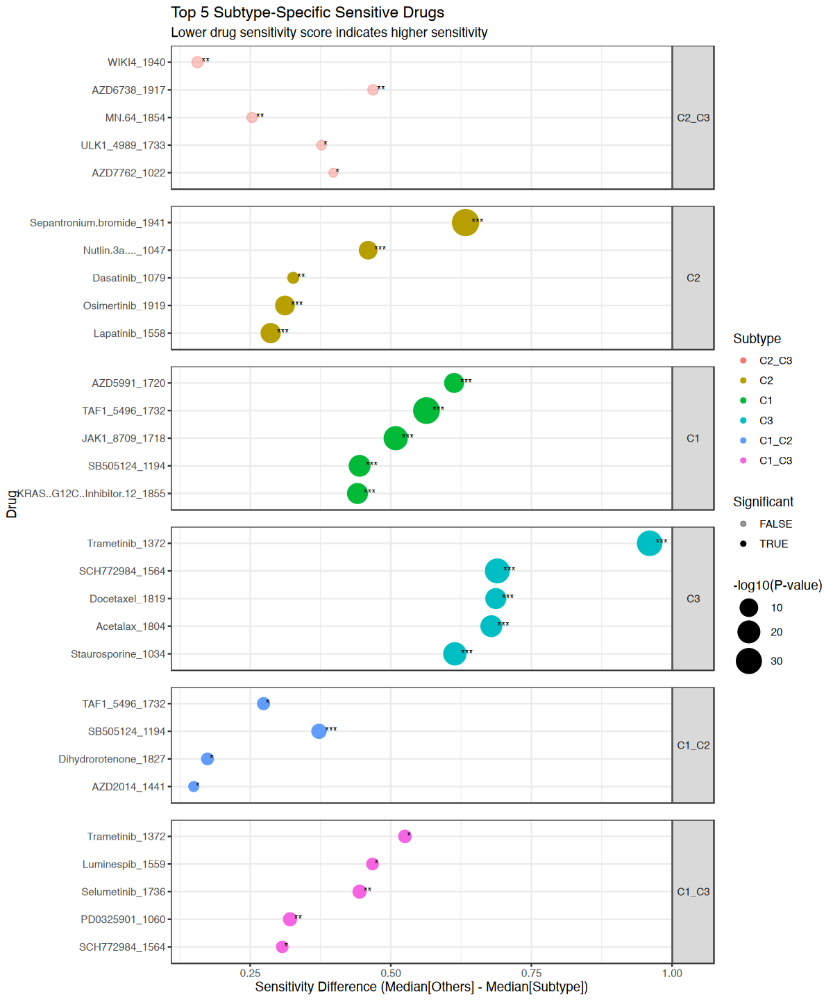

In [29]:
# --- 第3步：可视化结果 ---

# 确保亚型和药物的顺序在图中是固定的，以方便查看
top_hits_per_subtype$Drug <- factor(top_hits_per_subtype$Drug, 
                                   levels = rev(unique(top_hits_per_subtype$Drug)))
top_hits_per_subtype$Subtype <- factor(top_hits_per_subtype$Subtype, 
                                      levels = all_subtypes)

# 添加统计显著性标记
top_hits_per_subtype <- top_hits_per_subtype %>%
  mutate(sig_label = case_when(
    p.adj < 0.001 ~ "***",
    p.adj < 0.01 ~ "**",
    p.adj < 0.05 ~ "*",
    TRUE ~ "ns"
  ))
options(repr.plot.width=10, repr.plot.height=12)
# 绘制点图 (Dot Plot)
p <- ggplot(top_hits_per_subtype, 
           aes(x = sensitivity_diff, y = Drug)) +
  geom_point(aes(size = -log10(p.value), 
                color = Subtype, 
                alpha = significant)) +
  geom_text(aes(label = sig_label), hjust = -0.5, size = 3) +
  facet_grid(Subtype ~ ., scales = "free_y", space = "free_y") + # 按亚型分面
  scale_size_continuous(range = c(3, 10)) + # 点的大小反映P值的显著性
  scale_alpha_manual(values = c(0.4, 1)) + # 透明度标记显著性
  labs(
    title = "Top 5 Subtype-Specific Sensitive Drugs",
    subtitle = "Lower drug sensitivity score indicates higher sensitivity",
    x = "Sensitivity Difference (Median[Others] - Median[Subtype])",
    y = "Drug",
    size = "-log10(P-value)",
    color = "Subtype",
    alpha = "Significant"
  ) +
  theme_bw() +
  theme(
    strip.text.y = element_text(angle = 0),
    panel.spacing = unit(1, "lines")
  )

print(p)

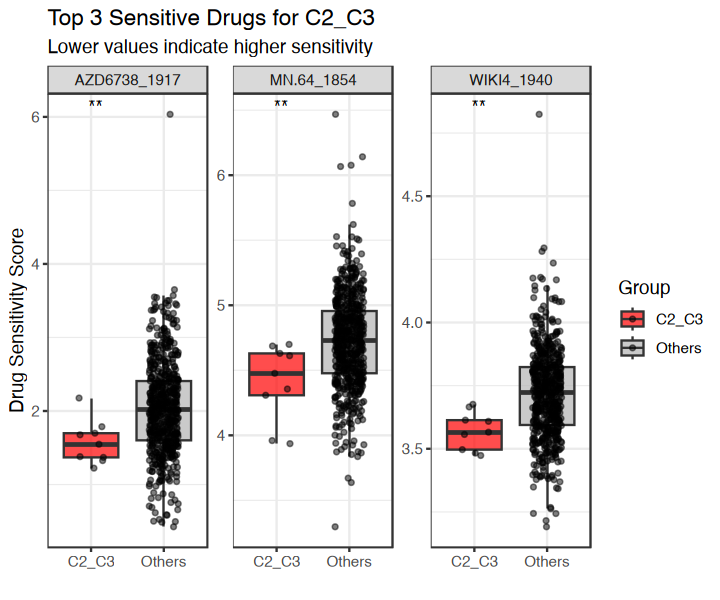

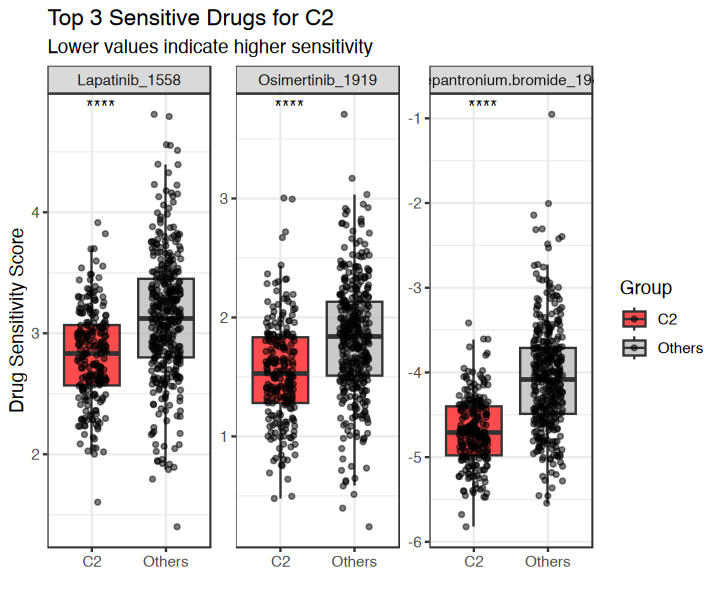

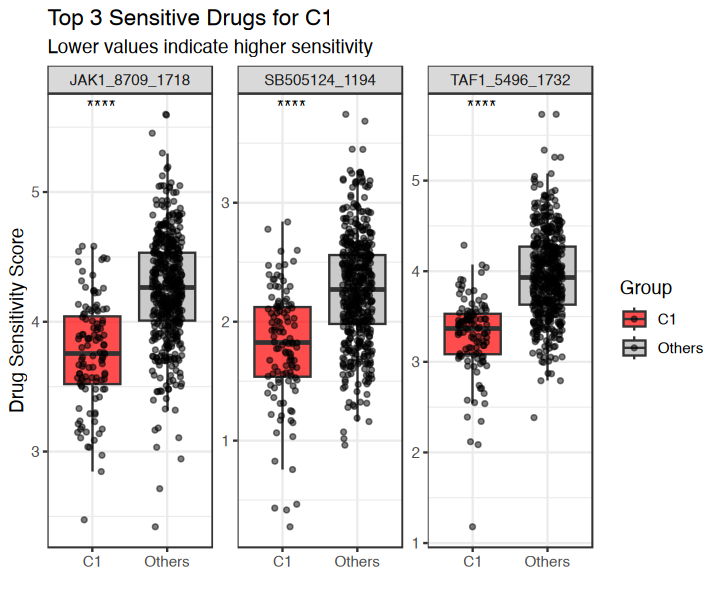

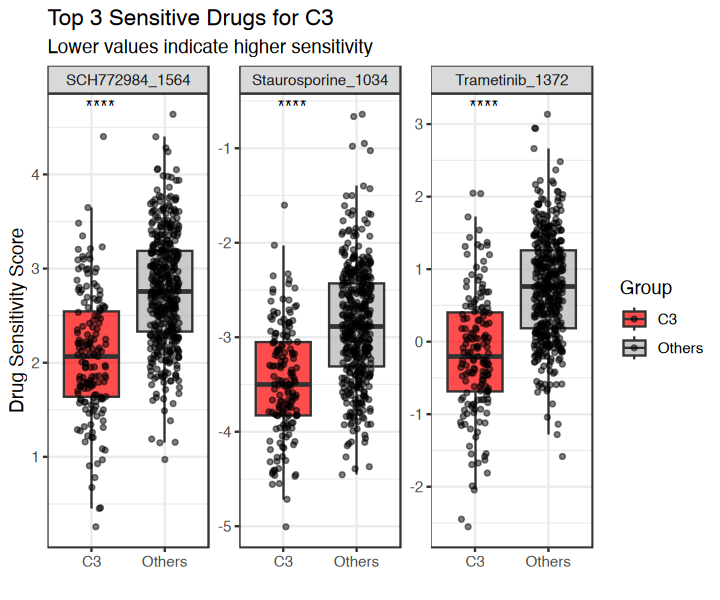

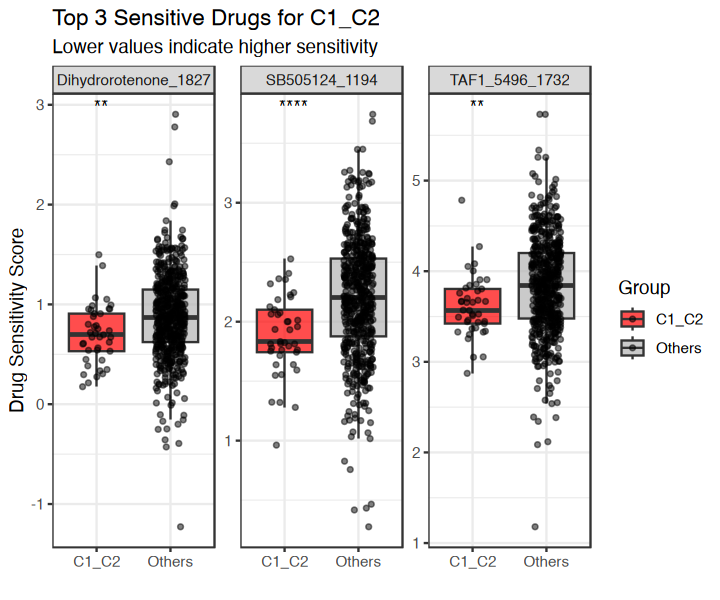

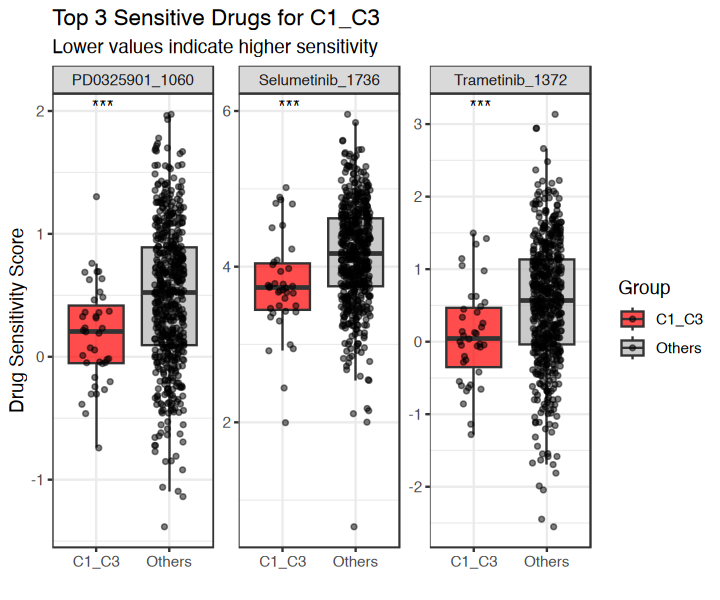

In [32]:
# --- 第4步：添加箱线图可视化 ---
# 为每个亚型的top 3药物创建箱线图
options(repr.plot.width=6, repr.plot.height=5)
for(subtype in all_subtypes) {
  # 获取当前亚型的top 3药物
  if(subtype %in% top_hits_per_subtype$Subtype) {
    top_drugs <- top_hits_per_subtype %>%
      filter(Subtype == subtype) %>%
      arrange(p.adj) %>%
      slice_head(n = 3) %>%
      pull(Drug)
    
    if(length(top_drugs) > 0) {
      # 为这些药物创建比较数据
      plot_data <- full_drug_data %>%
        mutate(Group = ifelse(Ensemble == subtype, subtype, "Others")) %>%
        select(Sample, Group, all_of(top_drugs)) %>%
        tidyr::pivot_longer(
          cols = all_of(top_drugs),
          names_to = "Drug",
          values_to = "Sensitivity"
        )
      
      # 创建箱线图
      p_box <- ggplot(plot_data, aes(x = Group, y = Sensitivity, fill = Group)) +
        geom_boxplot(alpha = 0.7, outlier.shape = NA) +
        geom_jitter(width = 0.2, height = 0, alpha = 0.5, size = 1) +
        facet_wrap(~ Drug, scales = "free_y", ncol = 3) +
        scale_fill_manual(values = c("Others" = "gray70", setNames(c("red"), subtype))) +
        labs(
          title = paste("Top 3 Sensitive Drugs for", subtype),
          subtitle = "Lower values indicate higher sensitivity",
          x = "",
          y = "Drug Sensitivity Score"
        ) +
        theme_bw() +
        stat_compare_means(label = "p.signif")  # 添加统计显著性标记
      
      print(p_box)
    }
  }
}

In [33]:
# --- 第5步：保存结果 ---
# 创建结果目录
results_dir <- "drug_sensitivity_results"
if(!dir.exists(results_dir)) {
  dir.create(results_dir)
}

# 保存完整结果表
write.csv(corrected_results, 
         file.path(results_dir, "all_drug_sensitivity_results.csv"), 
         row.names = FALSE)

# 保存top hits表
write.csv(top_hits_per_subtype, 
         file.path(results_dir, "top_subtype_specific_drugs.csv"), 
         row.names = FALSE)

cat("\n分析完成! 结果保存在", results_dir, "目录下\n")


<U+5206><U+6790><U+5B8C><U+6210>! <U+7ED3><U+679C><U+4FDD><U+5B58><U+5728> drug_sensitivity_results <U+76EE><U+5F55><U+4E0B>


### TF

In [25]:
library(dorothea)
library(viper)
library(pheatmap)
library(dplyr)
library(limma)
library(ComplexHeatmap)
library(circlize)
library(RColorBrewer)

In [11]:
# 加载dorothea提供的人类TF调控网络 (regulon)
# 我们只选择置信度为A, B, C的高质量调控关系
data(dorothea_hs, package = "dorothea")
regulon <- dorothea_hs %>%
  filter(confidence %in% c("A", "B", "C"))

In [12]:
# --- 将数据框转换为viper所需的列表格式 ---
regulon_list <- df2regulon(regulon)

In [13]:
# --- 第2步：使用viper算法推断TF活性 ---
cat("\n--- 正在推断转录因子(TF)活性 ---\n")
tf_activity_matrix <- viper(
  eset = corrected_expr_limma,
  regulon = regulon_list,
  nes = TRUE, # 使用归一化富集分数
  method = 'none',
  verbose = FALSE
)


--- <U+6B63><U+5728><U+63A8><U+65AD><U+8F6C><U+5F55><U+56E0><U+5B50>(TF)<U+6D3B><U+6027> ---


In [14]:
dim(tf_activity_matrix)
head(tf_activity_matrix)

[1] 145 586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
AHR,-2.0229669,-1.13564925,-2.1971492,-1.5025712,-1.7187196,-3.2580462,-0.7503232,-1.5706213,-2.6695935,-2.2312164,...,-2.01472978,-1.1636603,-1.1367183,-2.9309586,-2.1355810,-1.997669,-3.174924,-1.93626353,-2.9709039,-1.83749741
AR,3.5514037,3.57996364,5.0697352,2.2460166,2.7445461,3.6132134,4.3056483,4.0544653,4.0518405,2.7592321,...,2.95306556,3.5032342,3.4493526,4.5101468,3.4633823,4.605113,3.519293,0.90195964,3.8978933,3.34797740
ARID2,-0.4991370,0.03949945,-0.2468937,-0.1007401,-0.2633963,0.6218443,-0.1768345,0.2542364,-0.5918992,-0.6886496,...,-0.04500009,0.7340229,0.1945543,-0.2605882,-0.7207800,-1.327552,-1.034435,0.03911598,-0.3464286,0.46815651
ARNT,-0.5919713,0.15693738,-1.1270134,-0.5641502,-0.2328884,-0.5037275,0.2947847,-0.3416875,-1.5389242,-1.3689955,...,-0.02097038,0.6381782,-0.1033385,-1.4948282,0.5325551,-1.118373,-2.025975,-0.77607245,-1.9623676,-0.04336263
ASCL1,-1.8263721,-2.76574077,-0.9439612,-1.8078065,-0.9931423,-0.3461136,-2.6521645,-1.3343512,-0.6985812,-1.4445250,...,-1.95365235,-1.1990510,-2.0685847,-2.1534549,-0.3644725,-1.555928,-1.108819,-0.67605258,-0.5876599,-0.87267633
ATF3,-3.4310789,-2.48074167,-2.6568149,-3.3998097,-2.7090743,-1.2931597,-2.3301476,-3.0308703,-1.7734009,-2.1241091,...,-2.40050235,-2.1683378,-2.3944981,-2.2574434,-3.3583966,-2.789125,-1.039014,-2.60631322,-2.5563863,-2.22563495


In [15]:
write.csv(tf_activity_matrix, paste0(data_dir, "/tf_activity_matrix.csv"), row.names = TRUE)

In [16]:
# 确保样本顺序匹配
correct_sample_order <- colnames(tf_activity_matrix)
# 添加检查
if(!all(correct_sample_order %in% sample_cluster$Sample)) {
  stop("有些样本在TF活性矩阵中存在，但在sample_cluster中不存在")
}
sample_cluster_ordered <- sample_cluster[match(correct_sample_order, sample_cluster$Sample), ]

In [17]:
# 确保Ensemble列是因子类型
sample_cluster_ordered$Ensemble <- factor(sample_cluster_ordered$Ensemble)
subtype_levels <- levels(sample_cluster_ordered$Ensemble)

In [18]:
# 检查亚型数量
if(length(subtype_levels) <= 1) {
  stop("需要至少两个亚型才能进行对比分析")
}

In [33]:
# --- 设计矩阵 ---
design_tf <- model.matrix(~0 + sample_cluster_ordered$Ensemble)
colnames(design_tf) <- subtype_levels

# 创建列表存储结果
all_tf_results <- list()
top_tfs_per_subtype <- list()
# 设置过滤阈值
p_value_threshold <- 0.05
logFC_threshold <- 0.5  # 根据数据特性可以调整

for (subtype in subtype_levels) {
  # a. 创建"one-vs-rest"对比
  other_subtypes <- setdiff(subtype_levels, subtype)
  
  # 确保有其他亚型可比较
  if(length(other_subtypes) == 0) {
    cat(paste("警告：亚型", subtype, "没有其他亚型可比较，跳过\n"))
    next
  }
  
  contrast_formula <- paste0(subtype, " - (", paste(other_subtypes, collapse = " + "), ")/", length(other_subtypes))
  contrast_matrix <- makeContrasts(contrasts = contrast_formula, levels = design_tf)
  
  # b. 运行limma
  fit_tf <- lmFit(tf_activity_matrix, design_tf)
  fit_contrast <- contrasts.fit(fit_tf, contrast_matrix)
  fit_bayes <- eBayes(fit_contrast)
  
  # c. 提取所有差异活性结果
  all_results <- topTable(fit_bayes, number = Inf)
  all_tf_results[[subtype]] <- all_results
  
  # d. 应用p值和logFC过滤
  significant_tfs <- all_results %>%
    as_tibble(rownames = "TF") %>%
    filter(adj.P.Val < p_value_threshold, abs(logFC) > logFC_threshold) %>%
    arrange(adj.P.Val)
  
  if(nrow(significant_tfs) > 0) {
    top_n_significant <- head(significant_tfs$TF, min(10, nrow(significant_tfs)))
    top_tfs_per_subtype[[subtype]] <- top_n_significant
    cat(paste("为亚型", subtype, "筛选出符合条件的", length(top_n_significant), 
              "个TF (adj.P.Val <", p_value_threshold, ", |logFC| >", logFC_threshold, ")\n"))
  } else {
    cat(paste("警告：亚型", subtype, "没有找到符合过滤条件的TF\n"))
    # 如果没有满足严格条件的TF，使用top 10
    top_tfs_per_subtype[[subtype]] <- head(rownames(all_results), 10)
    cat(paste("  改为选择top 10的TF用于可视化\n"))
  }
}

# 合并所有亚型的Top TF，并去重
final_top_tf_names <- unique(unlist(top_tfs_per_subtype))

# 检查是否有TF可视化
if (length(final_top_tf_names) == 0) {
  stop("没有找到符合条件的TF。考虑放宽过滤条件。")
} else {
  cat(paste("共筛选出", length(final_top_tf_names), "个TF用于可视化\n"))
}

<U+4E3A><U+4E9A><U+578B> C1 <U+7B5B><U+9009><U+51FA><U+7B26><U+5408><U+6761><U+4EF6><U+7684> 10 <U+4E2A>TF (adj.P.Val < 0.05 , |logFC| > 0.5 )
<U+4E3A><U+4E9A><U+578B> C1_C2 <U+7B5B><U+9009><U+51FA><U+7B26><U+5408><U+6761><U+4EF6><U+7684> 10 <U+4E2A>TF (adj.P.Val < 0.05 , |logFC| > 0.5 )
<U+4E3A><U+4E9A><U+578B> C1_C3 <U+7B5B><U+9009><U+51FA><U+7B26><U+5408><U+6761><U+4EF6><U+7684> 10 <U+4E2A>TF (adj.P.Val < 0.05 , |logFC| > 0.5 )
<U+4E3A><U+4E9A><U+578B> C2 <U+7B5B><U+9009><U+51FA><U+7B26><U+5408><U+6761><U+4EF6><U+7684> 10 <U+4E2A>TF (adj.P.Val < 0.05 , |logFC| > 0.5 )
<U+4E3A><U+4E9A><U+578B> C2_C3 <U+7B5B><U+9009><U+51FA><U+7B26><U+5408><U+6761><U+4EF6><U+7684> 2 <U+4E2A>TF (adj.P.Val < 0.05 , |logFC| > 0.5 )
<U+4E3A><U+4E9A><U+578B> C3 <U+7B5B><U+9009><U+51FA><U+7B26><U+5408><U+6761><U+4EF6><U+7684> 10 <U+4E2A>TF (adj.P.Val < 0.05 , |logFC| > 0.5 )
<U+5171><U+7B5B><U+9009><U+51FA> 31 <U+4E2A>TF<U+7528><U+4E8E><U+53EF><U+89C6><U+5316>


In [34]:
# --- 可视化部分 ---
# 1. 提取最终筛选的TF活性矩阵子集
tf_activity_subset <- tf_activity_matrix[final_top_tf_names, ]

# 2. 标准化每个TF的活性分数，便于可视化
tf_activity_scaled <- t(scale(t(tf_activity_subset)))

# 3. 为热图准备注释数据
ha_column <- HeatmapAnnotation(
  Subtype = sample_cluster_ordered$Ensemble,
  col = list(Subtype = setNames(
    colorRampPalette(brewer.pal(8, "Dark2"))(length(subtype_levels)),
    subtype_levels
  )),
  show_annotation_name = TRUE,
  annotation_name_side = "left"
)

In [35]:
# 4. 创建TF来源注释 - 标记每个TF属于哪个亚型的顶部差异
tf_source <- rep("Multiple", length(final_top_tf_names))
names(tf_source) <- final_top_tf_names

for (subtype in names(top_tfs_per_subtype)) {
  for (tf in top_tfs_per_subtype[[subtype]]) {
    # 只为第一次出现的TF标记来源
    if (tf_source[tf] == "Multiple") {
      tf_source[tf] <- subtype
    }
  }
}

ha_row <- rowAnnotation(
  Source = tf_source,
  col = list(Source = setNames(
    colorRampPalette(brewer.pal(8, "Set1"))(length(subtype_levels)),
    subtype_levels
  )),
  show_annotation_name = TRUE
)

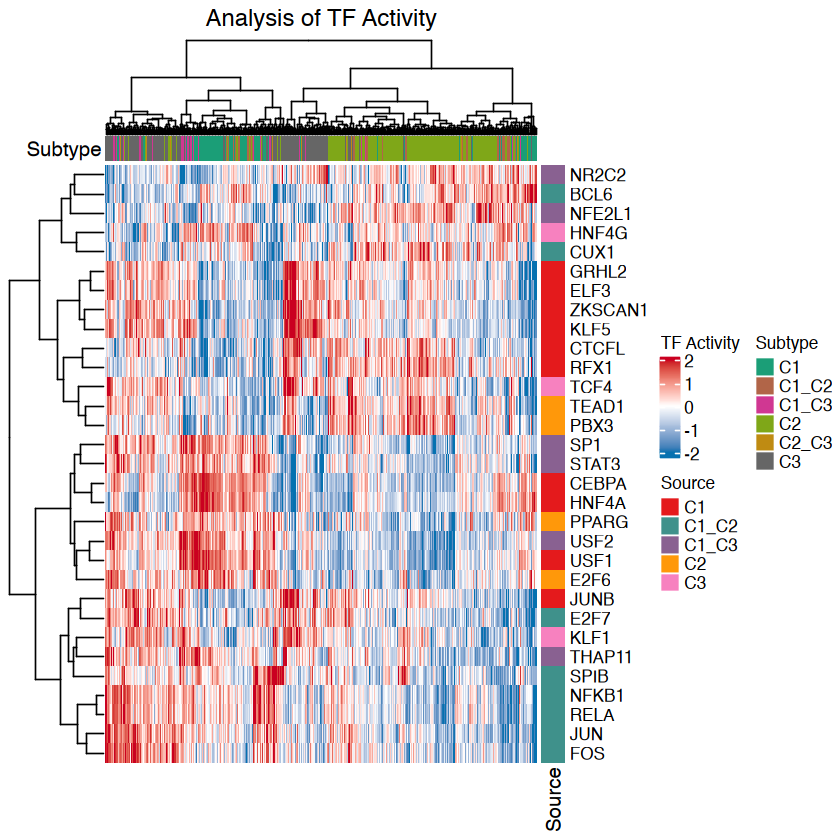

In [38]:
# 5. 创建热图
# 定义颜色映射
col_fun <- colorRamp2(
  c(-2, 0, 2), 
  c("#0571b0", "white", "#ca0020")
)

# 绘制热图
set.seed(123) # 为了结果可重复
tf_heatmap <- Heatmap(
  tf_activity_scaled,
  name = "TF Activity",
  col = col_fun,
  cluster_rows = TRUE,
  cluster_columns = TRUE,
  show_row_names = TRUE,
  show_column_names = FALSE,
  column_title = "Analysis of TF Activity",
  column_title_gp = gpar(fontsize = 14, fontface = "bold"),
  row_names_gp = gpar(fontsize = 10),
  top_annotation = ha_column,
  right_annotation = ha_row,
  clustering_distance_rows = "euclidean",
  clustering_distance_columns = "euclidean",
  clustering_method_rows = "ward.D2",
  clustering_method_columns = "ward.D2",
  row_dend_width = unit(2, "cm"),
  column_dend_height = unit(2, "cm")
)

# 显示热图
print(tf_heatmap)

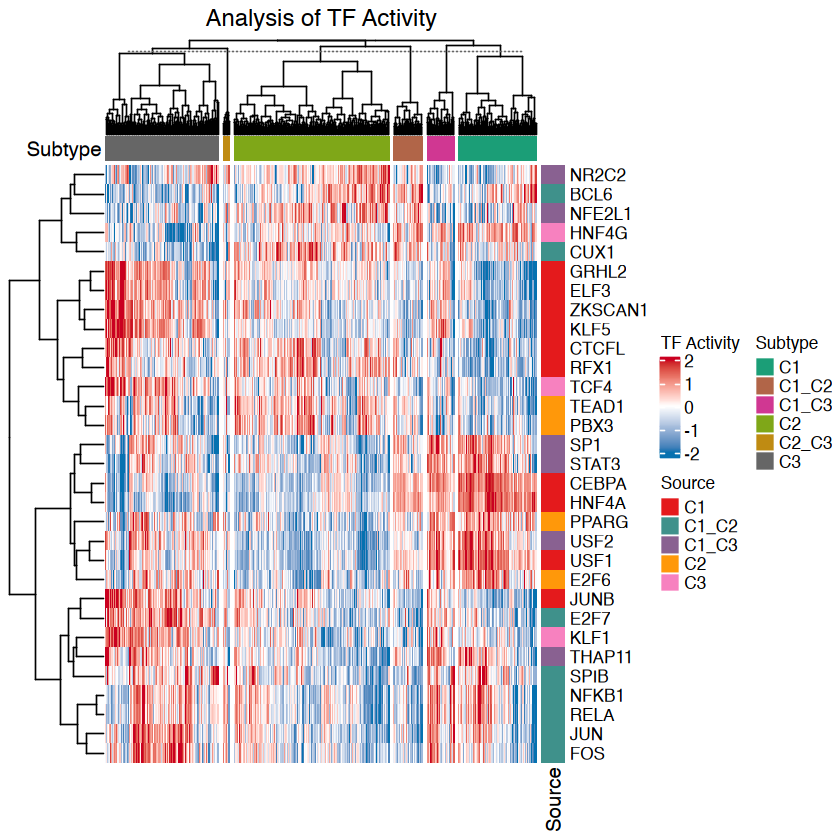

In [39]:
# 5. 创建热图
# 定义颜色映射
col_fun <- colorRamp2(
  c(-2, 0, 2), 
  c("#0571b0", "white", "#ca0020")
)

# 绘制热图
set.seed(123) # 为了结果可重复
tf_heatmap <- Heatmap(
  tf_activity_scaled,
  name = "TF Activity",
  col = col_fun,
  cluster_rows = TRUE,
  cluster_columns = TRUE,
  show_row_names = TRUE,
  show_column_names = FALSE,
  column_title = "Analysis of TF Activity",
  column_title_gp = gpar(fontsize = 14, fontface = "bold"),
  row_names_gp = gpar(fontsize = 10),
  top_annotation = ha_column,
  # 按照样本的亚型分割列
  column_split = sample_cluster_ordered$Ensemble,
  right_annotation = ha_row,
  clustering_distance_rows = "euclidean",
  clustering_distance_columns = "euclidean",
  clustering_method_rows = "ward.D2",
  clustering_method_columns = "ward.D2",
  row_dend_width = unit(2, "cm"),
  column_dend_height = unit(2, "cm")
)

# 显示热图
print(tf_heatmap)

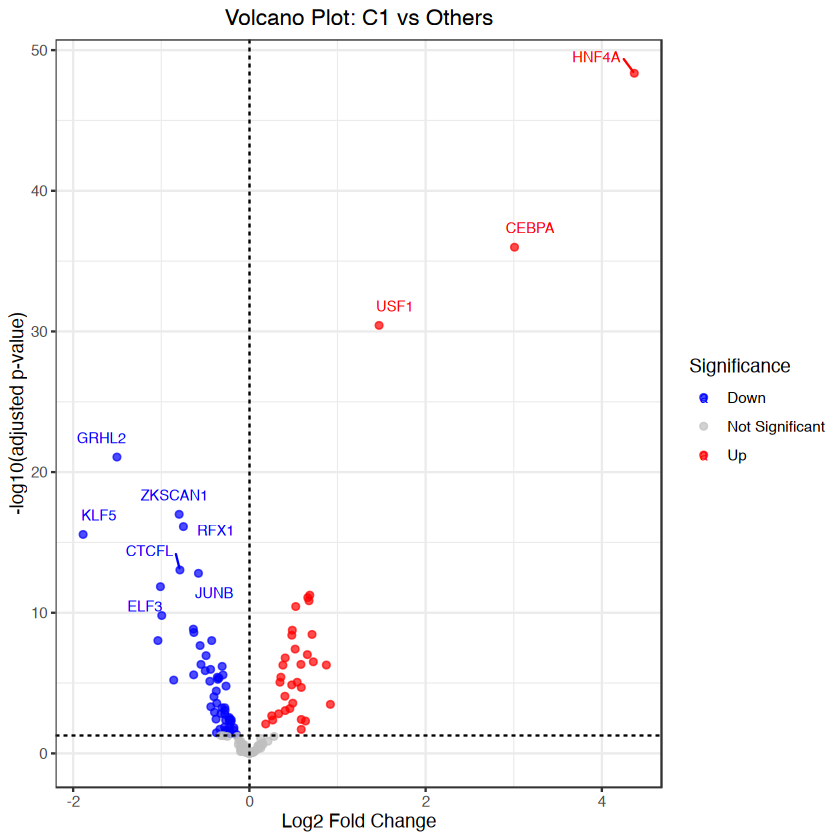

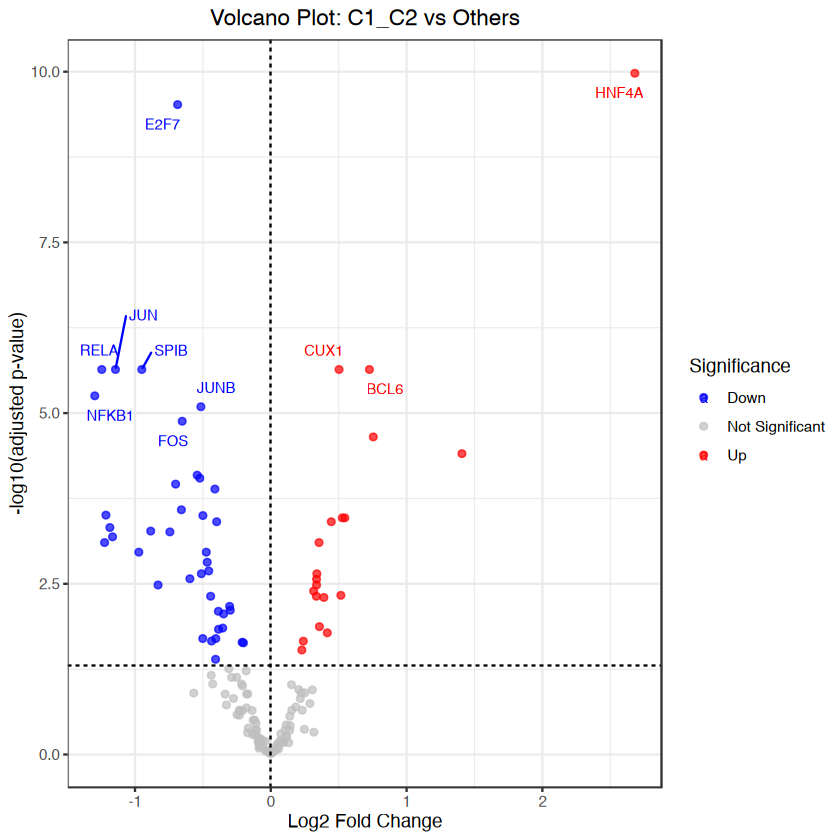

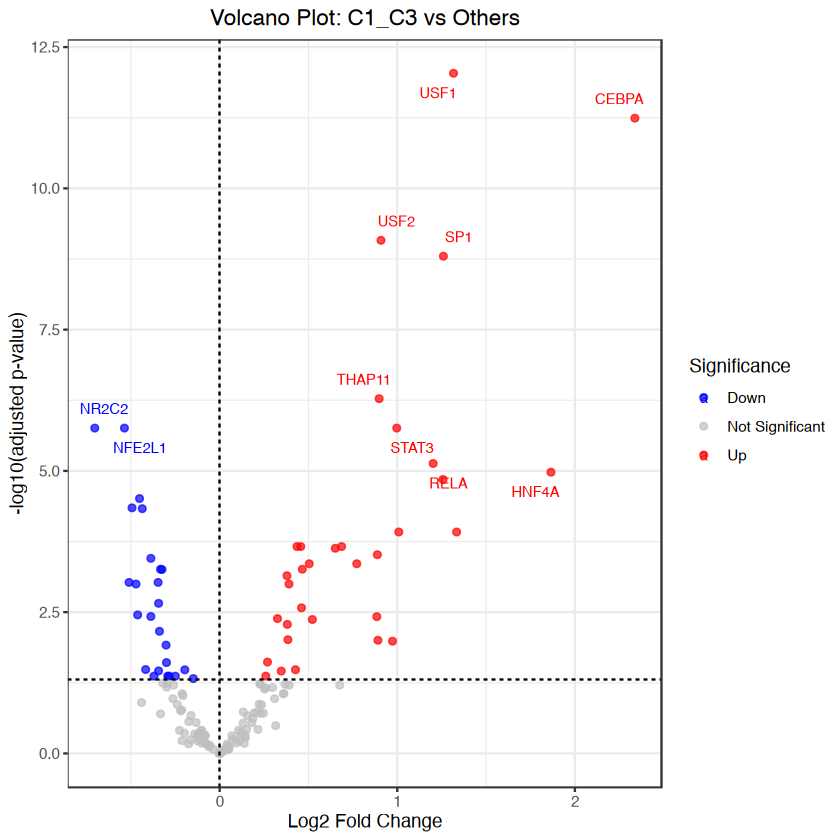

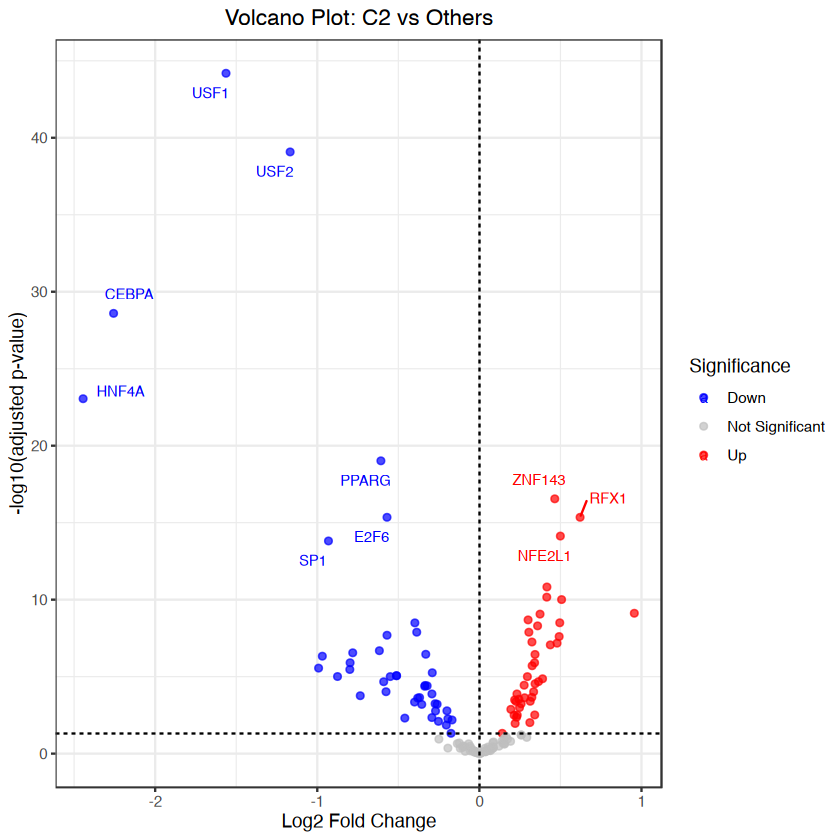

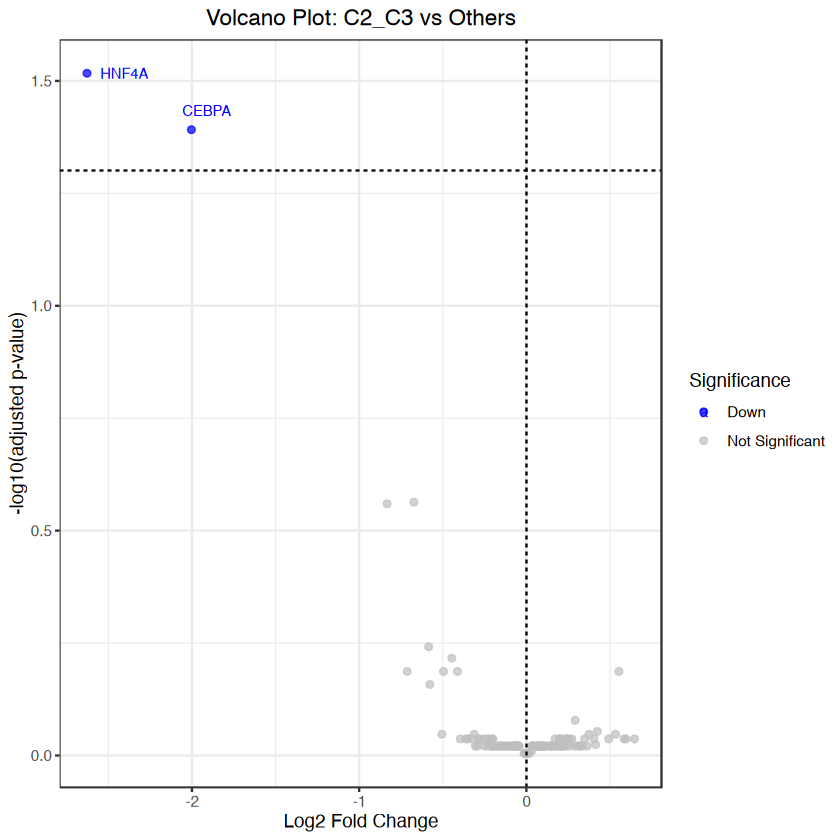

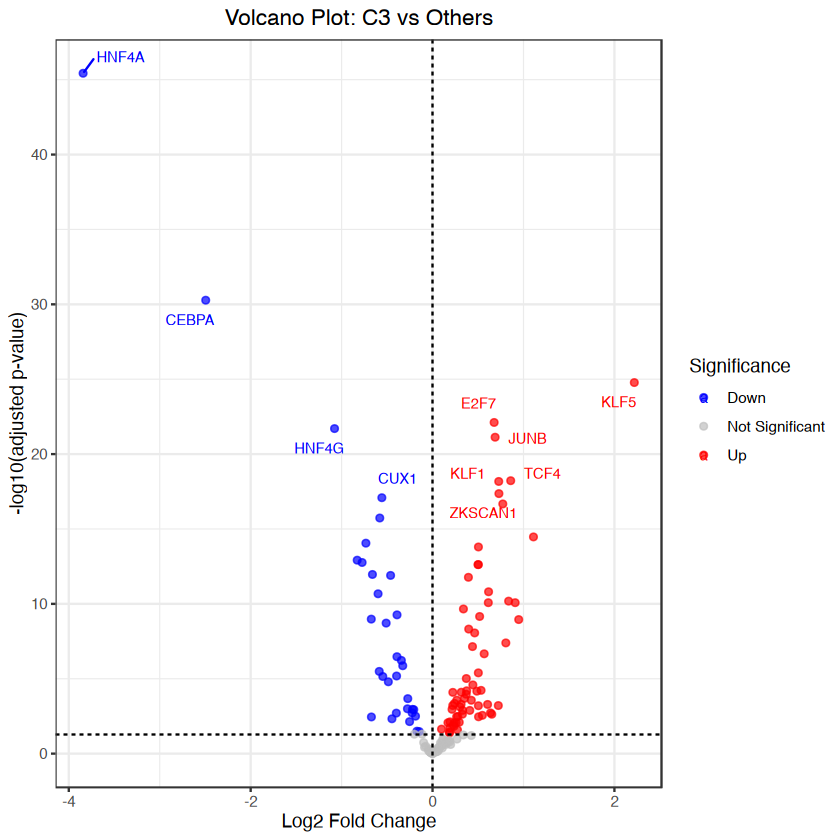

In [29]:
# 6. 可选：添加火山图可视化
# 为每个亚型创建火山图
for (subtype in names(all_tf_results)) {
  # 获取结果
  volcano_data <- all_tf_results[[subtype]] %>%
    as_tibble(rownames = "TF")
  
  # 添加显著性标记
  volcano_data$significance <- "Not Significant"
  volcano_data$significance[volcano_data$adj.P.Val < p_value_threshold & volcano_data$logFC > logFC_threshold] <- "Up"
  volcano_data$significance[volcano_data$adj.P.Val < p_value_threshold & volcano_data$logFC < -logFC_threshold] <- "Down"
  
  # 标记top TFs
  volcano_data$labeled <- volcano_data$TF %in% top_tfs_per_subtype[[subtype]]
  
  # 创建火山图
  p <- ggplot(volcano_data, aes(x = logFC, y = -log10(adj.P.Val), color = significance)) +
    geom_point(alpha = 0.7) +
    scale_color_manual(values = c("Not Significant" = "grey", "Up" = "red", "Down" = "blue")) +
    theme_bw() +
    geom_hline(yintercept = -log10(p_value_threshold), linetype = "dashed") +
    geom_vline(xintercept = c(-logFC_threshold, logFC_threshold), linetype = "dashed") +
    labs(
      title = paste("Volcano Plot:", subtype, "vs Others"),
      x = "Log2 Fold Change",
      y = "-log10(adjusted p-value)",
      color = "Significance"
    ) +
    theme(
      plot.title = element_text(hjust = 0.5, face = "bold"),
      legend.position = "right"
    )
  
  # 添加标签
  if (sum(volcano_data$labeled) > 0) {
    p <- p + geom_text_repel(
      data = volcano_data[volcano_data$labeled, ],
      aes(label = TF),
      size = 3,
      box.padding = 0.5,
      max.overlaps = 20
    )
  }
  
  # 显示图形
  print(p)
}

In [30]:
# 7. 导出结果表格 (可选)
# 合并所有亚型的结果到一个数据框
all_results_combined <- bind_rows(
  lapply(names(all_tf_results), function(subtype) {
    df <- all_tf_results[[subtype]] %>%
      as_tibble(rownames = "TF") %>%
      mutate(
        Subtype = subtype,
        Significant = adj.P.Val < p_value_threshold & abs(logFC) > logFC_threshold
      )
    return(df)
  })
)

# 保存到CSV文件
write.csv(all_results_combined, "TF_activity_differential_analysis_results.csv", row.names = FALSE)

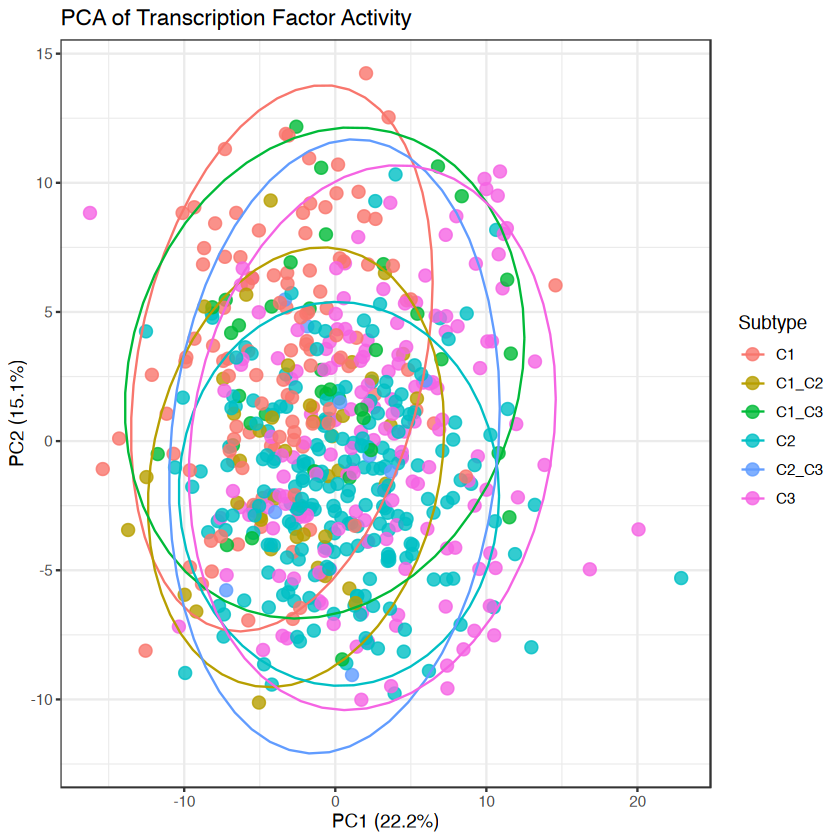

In [31]:
# 运行这段代码来生成PCA图
# 假设 tf_activity_matrix 和 sample_cluster_ordered 已存在

# a. 准备PCA数据
pca_data <- prcomp(t(tf_activity_matrix), scale. = TRUE)
pca_df <- as.data.frame(pca_data$x)
pca_df$Subtype <- sample_cluster_ordered$Ensemble

# b. 绘制PCA图
library(ggplot2)
ggplot(pca_df, aes(x = PC1, y = PC2, color = Subtype)) +
  geom_point(size = 3, alpha = 0.8) +
  labs(
    title = "PCA of Transcription Factor Activity",
    x = paste0("PC1 (", round(summary(pca_data)$importance[2,1]*100, 1), "%)"),
    y = paste0("PC2 (", round(summary(pca_data)$importance[2,2]*100, 1), "%)")
  ) +
  theme_bw() +
  stat_ellipse() # 添加置信椭圆

#===============================================================
# 第7部分: Pattern Analysis
#===============================================================

In [6]:
sample_cluster <- readxl::read_excel(paste0(data_dir, "/sample_info_with_clusters.xlsx"))
dim(sample_cluster)
head(sample_cluster)

[1] 586  38

Sample,NMF,KMeans,Ensemble,Study,Platform,Sex,Age_num,Age_group,Country,...,Distal metastasis (1=Positive),"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
111,3,1,C2_C3,2022Dong,RNAseq (Illumina),Male,49,40-60,China,...,0,8.4,36,5147,2.5,25.2,18,80,YES,NO
113,2,1,C2,2022Dong,RNAseq (Illumina),Male,59,40-60,China,...,0,9.1999999999999993,38,1.8,2.8,35,18,40,YES,NO
115,1,3,C1,2022Dong,RNAseq (Illumina),Male,74,>60,China,...,0,7.9,39,42.7,2,8.1999999999999904,11,29,YES,YES
117,1,3,C1,2022Dong,RNAseq (Illumina),Female,64,>60,China,...,0,14.1,47,2.8,1,7.9,17,27,YES,YES
121,2,1,C2,2022Dong,RNAseq (Illumina),Female,71,>60,China,...,0,8.6,42,215.1,1.4,24.9,10,23,YES,YES
123,1,3,C1,2022Dong,RNAseq (Illumina),Male,55,40-60,China,...,0,17.8,44,2.1,0.8,30.4,89,384,YES,YES


## **heatmap**

In [7]:
load(file = paste0(data_dir, "/combined_expr_after_correction.rds"))
dim(corrected_expr_limma)
head(corrected_expr_limma)

[1] 10531   586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
TMSB10,10.82928,10.890999,11.94522,12.778273,10.995143,11.226208,10.035329,10.398659,11.30408,12.16933,...,10.99660,11.026177,11.094798,12.008558,11.481356,12.627119,11.769922,11.4156781,11.201563,9.495304
ALB,12.05004,13.178437,10.79637,5.770313,7.063872,4.553839,12.638745,12.447035,10.08065,10.02450,...,11.00465,12.196094,10.683190,12.497491,2.410946,8.453237,7.411365,0.4926482,12.583942,7.533481
FTL,10.66605,12.897749,11.72236,11.072817,12.143254,12.137395,13.854919,12.317509,11.09063,11.08043,...,11.76724,9.781075,10.558542,10.432385,12.301201,12.339945,13.363718,11.6431148,10.730668,11.445058
S100A6,10.31944,5.593509,11.54254,10.995845,11.064880,10.134493,7.784021,10.904630,10.58029,10.69710,...,10.62347,10.704640,8.700956,7.914385,12.343699,11.888619,10.589558,8.2747927,8.948155,8.407319
RPS18,10.09080,10.167330,10.44833,10.278913,9.563777,9.050844,9.202332,9.774162,11.49839,10.09671,...,10.64097,11.134008,9.614914,10.565745,9.542747,9.639386,9.873656,11.1388385,10.614570,9.653813
TMSB4X,10.61613,10.408689,11.31893,11.724414,11.308622,11.295856,10.777988,11.413705,10.88848,11.85332,...,10.43501,10.587907,10.379686,11.303271,11.737150,11.998210,10.570807,12.4690672,10.863712,9.242494


In [7]:
top_var_genes <- read.csv(paste0(data_dir, "/top_variable_genes.csv"))
top_var_genes <- top_var_genes$Gene
var_expr <- corrected_expr_limma[top_var_genes, ]
dim(var_expr)
head(var_expr)

[1] 2000  586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
AGR2,-1.6070417,-1.4371293,8.058513,5.998575,9.088118,10.172491,5.1613282,9.019738,8.646718,-0.7480520,...,8.300053,6.776280,4.3066168,2.038226,12.0205280,7.812894,2.0398302,2.2741953,2.117453,1.978011
RPS4Y1,4.5146141,4.7707406,4.970964,0.668001,5.308624,8.543831,6.2956166,7.149047,7.135424,7.5568351,...,9.247006,9.363643,0.5373478,0.991313,0.5373478,7.767159,0.9970941,0.7869751,10.845060,1.384864
APOA2,8.0316785,12.5066827,10.097454,3.454750,5.305846,2.452445,9.2791108,9.869482,8.934140,6.0685903,...,9.833707,3.750004,6.4444012,7.792793,1.6190735,6.768808,12.8575103,1.9838700,12.451293,6.692598
APOC3,7.8473605,8.9205635,9.420874,3.195946,5.005174,2.627286,8.6166084,9.320015,8.586875,2.4120797,...,10.053816,4.008832,4.3636350,4.232026,1.9325470,5.765386,6.5851023,2.1462986,12.842842,6.085460
CEACAM5,-0.6430147,-0.7617758,6.433203,5.482220,9.255777,1.882357,-0.8914281,7.399052,7.401354,-0.5222687,...,1.963319,1.711830,1.8264748,1.370299,11.5432476,3.298878,1.5691708,1.5108164,1.503600,3.567032
HP,8.2867781,9.0689352,11.582767,3.889679,4.894185,2.695805,10.3153633,11.168352,10.037754,3.2133251,...,11.911654,5.823217,5.3994293,4.895138,4.1854607,10.006367,5.3582198,3.9722913,13.574577,7.871704


In [9]:
# 假设 sample_cluster 的行名是样本ID
# 确保 var_expr 的列名与 sample_cluster 的行名顺序一致
sample_order <- sample_cluster$Sample
var_expr_ordered <- var_expr[, sample_order]

In [ ]:
final_clusters <- sample_cluster$Ensemble 
nmf_clusters <- sample_cluster$NMF
kmeans_clusters <- sample_cluster$KMeans
batch_labels <- sample_cluster$Study
nmf_clusters_char <- paste0("N", nmf_clusters)
kmeans_clusters_char <- paste0("K", kmeans_clusters)

### *top2000 hvg*

In [ ]:
library(circlize)
library(ComplexHeatmap)
col_fun <- colorRamp2(c(-2, 0, 2), c("#2166AC", "#F7FBFF", "#B2182B")) # 冷暖对比

# 组合两个 top annotation
top_annotation <- HeatmapAnnotation(
  Subtype = final_clusters,
  NMF = nmf_clusters_char,
  KMeans = kmeans_clusters_char,
  Study = batch_labels,
  col = list(
        Subtype = c("C1"="#A6C2E0", "C2"="#C2E0A6", "C3"="#E0A6C2", "C1_C2"="#E0C2A6", "C1_C3"="#A6E0C2", "C2_C3"="#C2A6E0"),
        NMF = c("N1" = "gold", "N2" = "orange", "N3" = "darkred"), # 自定义NMF颜色
        KMeans = c("K1" = "lightblue", "K2" = "blue", "K3" = "darkblue"), # 自定义K-means颜色
        Study = c("2019Ahn"="#E0D6C2","2022Dong"="#F6C6CB", "2023Deng"="#6CB4AE", "2023Jeon"= "#D9E0A6",
              "2023Lee"='#D0E2E8', "2024Fan"='#F1DBB9', "TCGA-CHOL"='#E99C93')
  ),
  #gp = gpar(col = "white"),
  annotation_name_side = "right",
  annotation_name_gp = gpar(fontsize = 8), # 调整注释标题字体大小
  simple_anno_size = unit(0.4, "cm")      # 调整每个注释层的高度
)

pdf(file = "./Heatmap_top2000_CLuster_k7.pdf", width = 10, height = 12)  # 增加了高度以适应新的annotation

ht_obj <- draw(
        Heatmap(t(scale(t(var_expr_ordered))),
        border = FALSE,
        show_column_names = FALSE,
        show_row_names = FALSE,
        use_raster = FALSE,
        col = col_fun,
        column_title = NULL,
        column_split = factor(final_clusters, levels = c("C1","C1_C2","C1_C3","C2","C2_C3","C3")),
        top_annotation = top_annotation,
        cluster_column_slices = TRUE,
        cluster_rows = TRUE,
        clustering_method_rows = "ward.D2",  # 行聚类方法
        clustering_distance_rows = "euclidean",  # 行距离度量
        row_km = 7,
        cluster_columns = TRUE,
        show_row_dend = FALSE,
        show_column_dend = FALSE,
        show_heatmap_legend = TRUE,
        heatmap_legend_param = list(
                title = bquote(~'Scaled '~log[2]~'(tpm+1)'),
                title_gp = gpar(col = "black", cex = 0.75),
                title_position = "leftcenter-rot")
        )
)
dev.off()

agg_record_569004189 
                   2

### *top2000 hvg + degs*

In [ ]:
degs <- readxl::read_excel(paste0(data_dir, "/DEG_all_genes.xlsx"))
dim(degs)
head(degs)

[1] 63186     8

Gene,logFC,AveExpr,t,P.Value,adj.P.Val,B,Comparison
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
PROX1,2.871966,4.223508,27.07063,1.442026e-105,1.518598e-101,229.9788,C3 vs others
AGT,3.520345,7.376334,26.03241,4.214589e-100,2.219192e-96,217.4864,C3 vs others
SERPINA6,3.389931,5.089337,24.55148,2.793060e-92,9.804573e-89,199.6059,C3 vs others
VTN,3.794600,8.009701,23.38992,3.856777e-86,1.015393e-82,185.5659,C3 vs others
ONECUT1,2.948285,3.836185,23.36206,5.412561e-86,1.139994e-82,185.2293,C3 vs others
BAAT,2.809807,5.050768,22.73789,1.069561e-82,1.877258e-79,177.6922,C3 vs others


In [ ]:
degs <- degs[degs$Gene %in% top_var_genes, ]
length(unique(degs$Gene))

[1] 2000

In [ ]:
select <- degs[degs$adj.P.Val < 0.05, ]
length(unique(select$Gene))

[1] 1878

In [ ]:
select <- degs[degs$adj.P.Val < 0.05 & abs(degs$logFC) > 1, ]
length(unique(select$Gene))

[1] 737

In [ ]:
var_expr_ordered_sub <- var_expr_ordered[rownames(var_expr_ordered) %in% select$Gene, ]
dim(var_expr_ordered_sub)

[1] 737 586

In [ ]:
library(circlize)
library(ComplexHeatmap)
col_fun <- colorRamp2(c(-2, 0, 2), c("#2166AC", "#F7FBFF", "#B2182B")) # 冷暖对比

# 组合两个 top annotation
top_annotation <- HeatmapAnnotation(
  Subtype = final_clusters,
  NMF = nmf_clusters_char,
  KMeans = kmeans_clusters_char,
  Study = batch_labels,
  col = list(
        Subtype = c("C1"="#A6C2E0", "C2"="#C2E0A6", "C3"="#E0A6C2", "C1_C2"="#E0C2A6", "C1_C3"="#A6E0C2", "C2_C3"="#C2A6E0"),
        NMF = c("N1" = "gold", "N2" = "orange", "N3" = "darkred"), # 自定义NMF颜色
        KMeans = c("K1" = "lightblue", "K2" = "blue", "K3" = "darkblue"), # 自定义K-means颜色
        Study = c("2019Ahn"="#E0D6C2","2022Dong"="#F6C6CB", "2023Deng"="#6CB4AE", "2023Jeon"= "#D9E0A6",
              "2023Lee"='#D0E2E8', "2024Fan"='#F1DBB9', "TCGA-CHOL"='#E99C93')
  ),
  #gp = gpar(col = "white"),
  annotation_name_side = "right",
  annotation_name_gp = gpar(fontsize = 8), # 调整注释标题字体大小
  simple_anno_size = unit(0.4, "cm")      # 调整每个注释层的高度
)

pdf(file = "./Heatmap_deg_genes_k6.pdf", width = 10, height = 12)  # 增加了高度以适应新的annotation
row_dend <- hclust(dist(t(scale(t(var_expr_ordered_sub)))), method = "ward.D2")
ht_obj <- draw(
        Heatmap(t(scale(t(var_expr_ordered_sub))),
        border = FALSE,
        show_column_names = FALSE,
        show_row_names = FALSE,
        use_raster = FALSE,
        col = col_fun,
        column_title = NULL,
        column_split = factor(final_clusters, levels = c("C1","C1_C2","C1_C3","C2","C2_C3","C3")),
        top_annotation = top_annotation,
        cluster_column_slices = TRUE,
        cluster_rows = row_dend,
        row_split = 6,
        cluster_columns = TRUE,
        show_row_dend = FALSE,
        show_column_dend = FALSE,
        show_heatmap_legend = TRUE,
        heatmap_legend_param = list(
                title = bquote(~'Scaled '~log[2]~'(tpm+1)'),
                title_gp = gpar(col = "black", cex = 0.75),
                title_position = "leftcenter-rot")
        )
)
dev.off()

agg_record_1228985497 
                    2

In [ ]:
# =====================================================================
# 转录组热图聚类模式的高级富集分析与可视化系统 - 修复版本（Hemapplot）
# =====================================================================

# --- 加载必要的包 ---
library(clusterProfiler)
library(org.Hs.eg.db)
library(enrichplot)   # 用于高级富集可视化
library(msigdbr)      # 用于HALLMARK通路
library(writexl)      # 用于写入Excel
library(ggplot2)      # 用于绘图
library(dplyr)        # 用于数据处理
library(ComplexHeatmap) # 确保可以使用row_order函数
library(stringr)      # 用于字符串处理
library(RColorBrewer) # 更好的配色方案
library(ggpubr)       # 用于组合图表
library(igraph)       # 用于网络分析
library(circlize)     # 用于圈图
library(pheatmap)     # 用于热图可视化
library(tidyr)        # 用于数据处理

# --- 全局参数定义 ---
p_cutoff <- 0.2       # 用于富集分析的p值阈值
q_cutoff <- 0.5       # 用于富集分析的q值阈值
top_n_pathways <- 15  # 可视化中显示的顶部通路数
min_genes_in_module <- 10  # 富集分析所需的最小基因数

# --- 创建更丰富的输出目录结构 ---
dir.create("Enrichment_Results_Modules", showWarnings = FALSE)
dir.create("Enrichment_Results_Modules/Plots", showWarnings = FALSE)
dir.create("Enrichment_Results_Modules/Plots/GO", showWarnings = FALSE)
dir.create("Enrichment_Results_Modules/Plots/KEGG", showWarnings = FALSE)
dir.create("Enrichment_Results_Modules/Plots/HALLMARK", showWarnings = FALSE)
dir.create("Enrichment_Results_Modules/Plots/Reactome", showWarnings = FALSE)
dir.create("Enrichment_Results_Modules/Plots/Comparisons", showWarnings = FALSE)
dir.create("Enrichment_Results_Modules/Plots/Networks", showWarnings = FALSE)

# --- 设置更好的颜色主题 ---
module_colors <- c(
  "#E41A1C", "#377EB8", "#4DAF4A", "#984EA3", 
  "#FF7F00", "#FFFF33", "#A65628", "#F781BF"
)

# --- 辅助函数：更好的模块名称 ---
get_better_module_name <- function(module_name) {
  if(grepl("Module_", module_name)) {
    return(gsub("Module_", "模块", module_name))
  }
  return(module_name)
}

# --- 辅助函数：安全绘制cnetplot ---
safe_cnetplot <- function(go_res, fold_change = NULL) {
  tryCatch({
    set.seed(42)  # 设置随机数种子以确保可重复性
    # 使用新的参数格式
    p <- cnetplot(go_res, 
                 showCategory = min(8, nrow(go_res)), 
                 node_label = "all",
                 categorySize = "pvalue", 
                 color.params = list(
                   foldChange = fold_change,
                   edge = TRUE
                 ),
                 circular = FALSE)
    return(p)
  }, error = function(e) {
    message("创建cnetplot时出错: ", e$message)
    return(NULL)
  })
}

# ==============================================================================
# 分析流程 1: 对热图模块进行富集分析 (GO, KEGG, HALLMARK, Reactome)
# ==============================================================================
cat("--- 开始对热图模块进行富集分析 ---\n")

# --- 1.1 从热图对象中提取基因模块并进行质量控制 ---
gene_clusters_list <- row_order(ht_obj)
gene_sets <- lapply(gene_clusters_list, function(indices) {
  rownames(var_expr_ordered_sub)[indices]
})
# 为列表命名，方便后续识别
names(gene_sets) <- paste0("Module_", 1:length(gene_sets))

# 打印每个模块的基因数量
cat("模块基因数量统计：\n")
module_sizes <- sapply(gene_sets, length)
for(i in 1:length(module_sizes)) {
  cat(sprintf("  - %s: %d genes\n", names(gene_sets)[i], module_sizes[i]))
}

# --- 1.2 准备背景基因集和各种通路集 ---
universe_genes_modules <- top_var_genes # 背景集为热图中的所有基因

# 从msigdbr获取人类HALLMARK通路基因集
full_msigdb_df <- readRDS("/Users/luye/Data/Sig/msigdb.2024.1.Hs.rds")

# 获取HALLMARK基因集
hallmark_gmt <- full_msigdb_df %>%
  filter(gs_collection == "H") %>%
  dplyr::select(gs_name, gene_symbol = db_gene_symbol)

# 获取KEGG基因集
KEGG <- read.csv(file = "/Users/luye/Data/Sig/hsaMetaGenes.csv")
m_t2g <- KEGG[, c(1,3)]
colnames(m_t2g) <- c("gs_name", "gene_symbol")

# 获取Reactome基因集
reactome_gmt <- full_msigdb_df %>%
  filter(gs_collection == "C2", gs_subcollection == "CP:REACTOME") %>%
  dplyr::select(gs_name, gene_symbol = db_gene_symbol)

# --- 1.3 循环对每个模块进行增强的富集分析 ---
all_enrichment_results <- list()
all_gsea_results <- list()  # 用于存储GSEA结果
module_gene_lists <- list()  # 用于存储模块基因列表

for (module_name in names(gene_sets)) {
  cat(sprintf("  => 分析模块 %s (包含 %d 个基因)...\n", 
              module_name, length(gene_sets[[module_name]])))
  
  gene_list <- gene_sets[[module_name]]
  module_gene_lists[[module_name]] <- gene_list  # 存储基因列表
  
  # 跳过太小的模块
  if(length(gene_list) < min_genes_in_module) {
    cat(sprintf("    模块 %s 包含的基因数量（%d）少于阈值（%d），跳过富集分析\n", 
                module_name, length(gene_list), min_genes_in_module))
    next
  }
  
  # A. GO富集分析 (BP, MF, CC - 所有三种本体)
  go_ontologies <- c("BP", "MF", "CC")
  for(ontology in go_ontologies) {
    tryCatch({
      go_res <- enrichGO(
        gene = gene_list, universe = universe_genes_modules,
        OrgDb = org.Hs.eg.db, keyType = 'SYMBOL', ont = ontology,
        pAdjustMethod = "BH", pvalueCutoff = p_cutoff, qvalueCutoff = q_cutoff, 
        readable = TRUE
      )
      
      if(!is.null(go_res) && nrow(go_res) > 0) {
        result_name <- sprintf("GO_%s_%s", ontology, module_name)
        all_enrichment_results[[result_name]] <- as.data.frame(go_res)
        
        # 保存富集可视化结果
        if(nrow(go_res) > 0) {
          # 1. 气泡图
          p1 <- dotplot(go_res, showCategory=top_n_pathways, 
                        title=sprintf("GO %s Enrichment - %s", ontology, get_better_module_name(module_name)))
          ggsave(sprintf("Enrichment_Results_Modules/Plots/GO/GO_%s_dotplot_%s.pdf", 
                         ontology, module_name), p1, width=10, height=8)
          
          # 2. 条形图
          p2 <- barplot(go_res, showCategory=top_n_pathways, 
                       title=sprintf("GO %s Enrichment - %s", ontology, get_better_module_name(module_name)))
          ggsave(sprintf("Enrichment_Results_Modules/Plots/GO/GO_%s_barplot_%s.pdf", 
                         ontology, module_name), p2, width=10, height=8)
          
          # 4. 概念网络图 - 使用安全函数
          p4 <- safe_cnetplot(go_res, fold_change=NULL)
          if (!is.null(p4)) {
            ggsave(sprintf("Enrichment_Results_Modules/Plots/GO/GO_%s_cnetplot_%s.pdf", 
                           ontology, module_name), p4, width=12, height=10)
          }
        }
      }
    }, error = function(e) {
      cat(sprintf("    GO %s 分析出错: %s\n", ontology, e$message))
    })
  }
  
  # B. KEGG富集分析
  tryCatch({
    kegg_res <- enricher(
      gene = gene_list, universe = universe_genes_modules,
      pvalueCutoff = p_cutoff, pAdjustMethod = "BH",
      minGSSize = 3, maxGSSize = 500, qvalueCutoff = q_cutoff,
      TERM2GENE = m_t2g
    )
    
    if(!is.null(kegg_res) && nrow(kegg_res) > 0) {
      all_enrichment_results[[paste0("KEGG_", module_name)]] <- as.data.frame(kegg_res)
      
      # 保存富集可视化结果
      if(nrow(kegg_res) > 0) {
        # 1. 气泡图
        p1 <- dotplot(kegg_res, showCategory=top_n_pathways, 
                     title=sprintf("KEGG Enrichment - %s", get_better_module_name(module_name)))
        ggsave(sprintf("Enrichment_Results_Modules/Plots/KEGG/KEGG_dotplot_%s.pdf", 
                       module_name), p1, width=10, height=8)
        
        # 2. 条形图
        p2 <- barplot(kegg_res, showCategory=top_n_pathways,
                     title=sprintf("KEGG Enrichment - %s", get_better_module_name(module_name)))
        ggsave(sprintf("Enrichment_Results_Modules/Plots/KEGG/KEGG_barplot_%s.pdf", 
                       module_name), p2, width=10, height=8)
      }
    }
  }, error = function(e) {
    cat(sprintf("    KEGG分析出错: %s\n", e$message))
  })

  # C. HALLMARK富集分析
  tryCatch({
    hallmark_res <- enricher(
      gene = gene_list, universe = universe_genes_modules,
      TERM2GENE = hallmark_gmt, pvalueCutoff = p_cutoff, qvalueCutoff = q_cutoff
    )
    
    if(!is.null(hallmark_res) && nrow(hallmark_res) > 0) {
      all_enrichment_results[[paste0("HALLMARK_", module_name)]] <- as.data.frame(hallmark_res)
      
      # 保存富集可视化结果
      if(nrow(hallmark_res) > 0) {
        # 1. 气泡图
        p1 <- dotplot(hallmark_res, showCategory=top_n_pathways, 
                     title=sprintf("HALLMARK Enrichment - %s", get_better_module_name(module_name)))
        ggsave(sprintf("Enrichment_Results_Modules/Plots/HALLMARK/HALLMARK_dotplot_%s.pdf", 
                       module_name), p1, width=10, height=8)
        
        # 2. 条形图  
        p2 <- barplot(hallmark_res, showCategory=top_n_pathways,
                     title=sprintf("HALLMARK Enrichment - %s", get_better_module_name(module_name)))
        ggsave(sprintf("Enrichment_Results_Modules/Plots/HALLMARK/HALLMARK_barplot_%s.pdf", 
                       module_name), p2, width=10, height=8)
      }
    }
  }, error = function(e) {
    cat(sprintf("    HALLMARK分析出错: %s\n", e$message))
  })

  # D. Reactome富集分析
  tryCatch({
    reactome_res <- enricher(
      gene = gene_list, universe = universe_genes_modules,
      TERM2GENE = reactome_gmt, pvalueCutoff = p_cutoff, qvalueCutoff = q_cutoff
    )
    
    if(!is.null(reactome_res) && nrow(reactome_res) > 0) {
      all_enrichment_results[[paste0("Reactome_", module_name)]] <- as.data.frame(reactome_res)
      
      # 保存富集可视化结果
      if(nrow(reactome_res) > 0) {
        # 1. 气泡图
        p1 <- dotplot(reactome_res, showCategory=top_n_pathways, 
                     title=sprintf("Reactome Enrichment - %s", get_better_module_name(module_name)))
        ggsave(sprintf("Enrichment_Results_Modules/Plots/Reactome/Reactome_dotplot_%s.pdf", 
                       module_name), p1, width=10, height=8)
        
        # 2. 条形图
        p2 <- barplot(reactome_res, showCategory=top_n_pathways,
                     title=sprintf("Reactome Enrichment - %s", get_better_module_name(module_name)))
        ggsave(sprintf("Enrichment_Results_Modules/Plots/Reactome/Reactome_barplot_%s.pdf", 
                       module_name), p2, width=10, height=8)
      }
    }
  }, error = function(e) {
    cat(sprintf("    Reactome分析出错: %s\n", e$message))
  })
}

# --- 1.4 将所有模块的富集结果保存到一个多页的Excel文件中 ---
if (length(all_enrichment_results) > 0) {
  write_xlsx(all_enrichment_results, path = "Enrichment_Results_Modules/Enrichment_All_Modules.xlsx")
  cat("--- 热图模块富集分析完成！结果已保存到 'Enrichment_Results_Modules/Enrichment_All_Modules.xlsx' ---\n\n")
} else {
  cat("--- 热图模块富集分析未发现显著结果。 ---\n\n")
}

# ==============================================================================
# 分析流程 2: 模块间富集结果比较分析 - 修复版本
# ==============================================================================
cat("--- 开始模块间富集结果比较分析 ---\n")

# --- 2.1 创建模块间GO BP富集结果比较图 - 使用tidyr方法 ---
go_bp_results <- all_enrichment_results[grep("GO_BP", names(all_enrichment_results))]

if(length(go_bp_results) > 1) {  # 至少需要两个模块有结果才能比较
  # 合并所有模块的富集结果
  tryCatch({
    combined_df <- bind_rows(go_bp_results, .id = "Module") %>%
      # 清理模块名
      mutate(Module = gsub("GO_BP_", "", Module))
    
    # 只保留显著富集的通路
    combined_df <- combined_df %>% filter(p.adjust < 0.05)
    
    if(nrow(combined_df) > 0) {
      # 筛选出每个模块Top 5的通路，合并后取唯一值，作为要展示的通路列表
      top_pathways <- combined_df %>%
        group_by(Module) %>%
        top_n(-5, wt = p.adjust) %>%
        pull(Description) %>%
        unique()
      
      # 如果通路太多，只取前20个
      if(length(top_pathways) > 20) {
        # 按在不同模块中出现频率排序
        pathway_counts <- combined_df %>%
          filter(Description %in% top_pathways) %>%
          group_by(Description) %>%
          summarise(count = n(), avg_p = mean(p.adjust), .groups = "drop") %>%
          arrange(desc(count), avg_p)
        
        top_pathways <- pathway_counts$Description[1:20]
      }
      
      # 筛选出这些Top通路在所有模块中的结果
      plot_df <- combined_df %>%
        filter(Description %in% top_pathways) %>%
        mutate(
          # 创建数值型GeneRatio
          GeneRatio_val = sapply(GeneRatio, function(x) {
            parts <- strsplit(x, "/")[[1]]
            as.numeric(parts[1]) / as.numeric(parts[2])
          }),
          # 基因数量
          Count = as.numeric(sapply(strsplit(GeneRatio, "/"), `[`, 1))
        )
      
      # 简化过长的通路名称
      plot_df <- plot_df %>% 
        mutate(Description = str_wrap(Description, width = 40))
      
      # 绘制富集热图
      p_heatmap <- ggplot(plot_df, aes(x = Module, y = reorder(Description, -GeneRatio_val))) +
        geom_point(aes(size = Count, color = p.adjust)) +
        scale_color_gradientn(
          colors = c("red", "orange", "blue"), 
          name = "Adjusted\np-value",
          trans = "log10",
          labels = scales::scientific
        ) +
        scale_size_continuous(range = c(3, 12), name = "Gene Count") +
        labs(
          x = "Module", 
          y = "GO Biological Process", 
          title = "Comparative GO BP Enrichment Analysis Across Modules"
        ) +
        theme_bw() +
        theme(
          axis.text.x = element_text(angle = 45, hjust = 1, size = 11),
          axis.text.y = element_text(size = 10),
          legend.position = "right",
          plot.title = element_text(size = 14, face = "bold"),
          panel.grid.major = element_line(color = "grey90"),
          panel.grid.minor = element_blank()
        )
      
      # 保存图片
      ggsave("Enrichment_Results_Modules/Plots/Comparisons/GO_BP_Modules_Comparison.pdf", 
             p_heatmap, width = 12, height = 10)
      
      # --- 2.2 创建GO BP热图矩阵 - 使用tidyr方法重构 ---
      if(nrow(plot_df) > 0) {
        # 将数据转换为宽格式，以便于创建热图
        matrix_df <- plot_df %>%
          dplyr::select(Description, Module, p.adjust) %>%
          # 转换为-log10(p.adjust)
          mutate(neg_log_p = -log10(p.adjust)) %>%
          # 转换为宽格式
          tidyr::pivot_wider(
            id_cols = Description,
            names_from = Module,
            values_from = neg_log_p,
            values_fill = NA
          )
          
        # 创建矩阵
        result_matrix <- as.matrix(matrix_df[, -1])
        rownames(result_matrix) <- matrix_df$Description
        
        # 绘制热图
        color_palette <- colorRampPalette(c("white", "red"))(100)
        
        pdf("Enrichment_Results_Modules/Plots/Comparisons/GO_BP_Modules_Heatmap.pdf", width = 12, height = 10)
        pheatmap(
          result_matrix,
          color = color_palette,
          na_col = "grey90",
          main = "GO BP Enrichment Across Modules (-log10 p.adjust)",
          fontsize_row = 8,
          fontsize_col = 10,
          angle_col = 45,
          cluster_rows = TRUE,
          cluster_cols = FALSE,
          display_numbers = FALSE
        )
        dev.off()
      }
      
      cat("  -> GO BP比较分析已完成，结果保存在 'Enrichment_Results_Modules/Plots/Comparisons/'\n")
    } else {
      cat("  -> 没有找到显著富集的GO BP通路\n")
    }
  }, error = function(e) {
    cat(sprintf("  -> GO BP比较分析出错: %s\n", e$message))
  })
} else {
  cat("  -> 没有足够的模块具有GO BP富集结果，无法进行比较\n")
}

# --- 2.3 创建模块间HALLMARK富集结果比较图 - 使用tidyr方法 ---
hallmark_results <- all_enrichment_results[grep("HALLMARK_", names(all_enrichment_results))]

if(length(hallmark_results) > 1) {  # 至少需要两个模块有结果才能比较
  # 合并所有模块的富集结果
  tryCatch({
    combined_df <- bind_rows(hallmark_results, .id = "Module") %>%
      # 清理模块名
      mutate(Module = gsub("HALLMARK_", "", Module))
    
    # 只保留显著富集的通路
    combined_df <- combined_df %>% filter(p.adjust < 0.05)
    
    if(nrow(combined_df) > 0) {
      # 创建气泡图比较
      plot_df <- combined_df %>%
        mutate(
          GeneRatio_val = sapply(GeneRatio, function(x) {
            parts <- strsplit(x, "/")[[1]]
            as.numeric(parts[1]) / as.numeric(parts[2])
          }),
          Count = as.numeric(sapply(strsplit(GeneRatio, "/"), `[`, 1))
        )
      
      p_bubble <- ggplot(plot_df, aes(x = Module, y = Description)) +
        geom_point(aes(size = Count, color = p.adjust)) +
        scale_color_gradientn(
          colors = c("red", "orange", "blue"), 
          name = "Adjusted\np-value",
          trans = "log10",
          labels = scales::scientific
        ) +
        scale_size_continuous(range = c(3, 10), name = "Gene Count") +
        labs(
          x = "Module", 
          y = "HALLMARK Pathway", 
          title = "Comparative HALLMARK Enrichment Analysis Across Modules"
        ) +
        theme_bw() +
        theme(
          axis.text.x = element_text(angle = 45, hjust = 1, size = 11),
          axis.text.y = element_text(size = 10),
          legend.position = "right",
          plot.title = element_text(size = 14, face = "bold")
        )
      
      ggsave("Enrichment_Results_Modules/Plots/Comparisons/HALLMARK_Modules_Comparison.pdf", 
             p_bubble, width = 10, height = 8)
      
      # 使用tidyr方法创建热图数据
      if(nrow(plot_df) > 0) {
        # 将数据转换为宽格式
        matrix_df <- plot_df %>%
          dplyr::select(Description, Module, p.adjust) %>%
          # 转换为-log10(p.adjust)
          mutate(neg_log_p = -log10(p.adjust)) %>%
          # 转换为宽格式
          tidyr::pivot_wider(
            id_cols = Description,
            names_from = Module,
            values_from = neg_log_p,
            values_fill = NA
          )
          
        # 创建矩阵
        result_matrix <- as.matrix(matrix_df[, -1])
        rownames(result_matrix) <- matrix_df$Description
        
        # 绘制热图
        color_palette <- colorRampPalette(c("white", "red"))(100)
        
        pdf("Enrichment_Results_Modules/Plots/Comparisons/HALLMARK_Modules_Heatmap.pdf", width = 10, height = 8)
        pheatmap(
          result_matrix,
          color = color_palette,
          na_col = "grey90",
          main = "HALLMARK Enrichment Across Modules (-log10 p.adjust)",
          fontsize_row = 10,
          fontsize_col = 10,
          angle_col = 45,
          cluster_rows = TRUE,
          cluster_cols = FALSE,
          display_numbers = FALSE
        )
        dev.off()
      }
      
      cat("  -> HALLMARK比较分析已完成，结果保存在 'Enrichment_Results_Modules/Plots/Comparisons/'\n")
    } else {
      cat("  -> 没有找到显著富集的HALLMARK通路\n")
    }
  }, error = function(e) {
    cat(sprintf("  -> HALLMARK比较分析出错: %s\n", e$message))
  })
} else {
  cat("  -> 没有足够的模块具有HALLMARK富集结果，无法进行比较\n")
}

# ==============================================================================
# 分析流程 3: 模块间基因重叠分析与可视化 - 修复版本
# ==============================================================================
cat("--- 开始模块间基因重叠分析 ---\n")

if(length(module_gene_lists) > 1) {
  # --- 3.1 韦恩图分析模块间基因重叠 ---
  # 最多展示5个模块的韦恩图
  if(length(module_gene_lists) <= 5) {
    tryCatch({
      library(VennDiagram)
      # 为每个模块分配颜色
      venn_colors <- module_colors[1:length(module_gene_lists)]
      names(venn_colors) <- names(module_gene_lists)
      
      # 创建韦恩图目录
      dir.create("Enrichment_Results_Modules/Plots/Comparisons", showWarnings = FALSE)
      
      # 创建韦恩图
      venn_file <- "Enrichment_Results_Modules/Plots/Comparisons/Module_Gene_Overlap_Venn.png"
      
      # 使用grid.newpage确保干净的绘图环境
      library(grid)
      png(venn_file, width = 1000, height = 1000, res = 150)
      grid.newpage()
      
      # 仅创建韦恩图形并返回，不写入文件
      venn_obj <- venn.diagram(
        x = module_gene_lists,
        category.names = names(module_gene_lists),
        filename = NULL,
        output = TRUE,
        imagetype = "png",
        height = 1000, 
        width = 1000,
        resolution = 150,
        compression = "lzw",
        lwd = 1,
        col = venn_colors,
        fill = alpha(venn_colors, 0.5),
        cex = 1,
        fontface = "bold",
        fontfamily = "sans",
        cat.cex = 1,
        cat.fontface = "bold",
        cat.default.pos = "outer",
        cat.pos = NULL, # 自动定位
        cat.fontfamily = "sans",
        rotation = 1
      )
      
      # 手动绘制返回的网格对象
      grid.draw(venn_obj)
      dev.off()
      cat("  -> 模块基因重叠韦恩图已保存到", venn_file, "\n")
    }, error = function(e) {
      cat("  -> 创建韦恩图时出错:", e$message, "\n")
    })
  } else {
    cat("  -> 模块数量超过5个，跳过韦恩图分析\n")
  }
  
  # --- 3.2 创建模块间基因重叠热图 ---
  tryCatch({
    # 计算重叠系数矩阵
    n_modules <- length(module_gene_lists)
    overlap_matrix <- matrix(0, nrow = n_modules, ncol = n_modules)
    rownames(overlap_matrix) <- names(module_gene_lists)
    colnames(overlap_matrix) <- names(module_gene_lists)
    
    for(i in 1:n_modules) {
      for(j in 1:n_modules) {
        if(i == j) {
          overlap_matrix[i, j] <- 1  # 自己和自己的重叠系数为1
        } else {
          # 计算Jaccard重叠系数
          intersection_size <- length(intersect(module_gene_lists[[i]], module_gene_lists[[j]]))
          union_size <- length(union(module_gene_lists[[i]], module_gene_lists[[j]]))
          overlap_matrix[i, j] <- intersection_size / union_size
        }
      }
    }
    
    # 绘制热图
    pdf("Enrichment_Results_Modules/Plots/Comparisons/Module_Gene_Overlap_Heatmap.pdf", width = 8, height = 7)
    pheatmap(
      overlap_matrix,
      color = colorRampPalette(c("white", "steelblue", "darkblue"))(100),
      main = "模块间基因重叠度（Jaccard系数）",
      display_numbers = TRUE,
      number_format = "%.2f",
      fontsize_number = 10,
      fontsize = 10,
      fontsize_row = 10,
      fontsize_col = 10
    )
    dev.off()
    
    cat("  -> 模块基因重叠热图已保存\n")
  }, error = function(e) {
    cat("  -> 创建模块基因重叠热图时出错:", e$message, "\n")
  })
  
  # --- 3.3 创建模块间网络图 ---
  tryCatch({
    # 创建邻接矩阵，只保留重叠度大于阈值的连接
    adjacency_matrix <- overlap_matrix
    threshold <- 0.1  # 重叠系数阈值
    adjacency_matrix[adjacency_matrix < threshold] <- 0
    diag(adjacency_matrix) <- 0  # 移除自连接
    
    # 创建图形对象
    g <- graph_from_adjacency_matrix(
      adjacency_matrix,
      mode = "undirected",
      weighted = TRUE
    )
    
    if(ecount(g) > 0) {  # 确保图中有边
      # 设置节点大小为模块中的基因数量
      V(g)$size <- log2(sapply(module_gene_lists, length)) * 3
      
      # 设置边的宽度为重叠系数
      E(g)$width <- E(g)$weight * 10
      
      # 设置节点颜色
      V(g)$color <- module_colors[1:length(module_gene_lists)]
      
      # 设置边的颜色为半透明灰色
      E(g)$color <- "grey70"
      
      # 设置节点标签
      V(g)$label <- names(module_gene_lists)
      
      # 绘制网络图
      pdf("Enrichment_Results_Modules/Plots/Networks/Module_Relationship_Network.pdf", width = 10, height = 8)
      plot(g, 
           layout = layout_with_fr(g),
           vertex.label.cex = 1.2,
           vertex.label.color = "black",
           vertex.label.dist = 0.5,
           vertex.label.family = "sans",
           edge.curved = 0.2,
           main = "模块间基因共享网络")
      dev.off()
      
      cat("  -> 模块关系网络图已保存\n")
    } else {
      cat("  -> 模块间基因重叠度低于阈值，无法创建有意义的网络图\n")
    }
  }, error = function(e) {
    cat("  -> 创建模块关系网络图时出错:", e$message, "\n")
  })
  
} else {
  cat("  -> 没有足够的模块进行重叠分析\n")
}

# ==============================================================================
# 分析流程 4: 模块基因表达模式可视化增强 - 修复版本
# ==============================================================================
cat("--- 开始增强的模块基因表达模式可视化 ---\n")

# --- 4.1 为每个模块创建表达热图 ---
for(module_name in names(gene_sets)) {
  tryCatch({
    gene_list <- gene_sets[[module_name]]
    
    if(length(gene_list) > 5 && length(gene_list) <= 200) {  # 只处理合适大小的模块
      # 提取该模块的基因表达数据
      module_expr <- var_expr_ordered_sub[gene_list, ]
      
      # 确保矩阵格式
      if(!is.matrix(module_expr)) {
        module_expr <- as.matrix(module_expr)
      }
      
      # 创建注释数据（如果有样本分组信息）
      # 假设样本分组信息存在于一个名为sample_groups的对象中
      if(exists("sample_groups") && length(sample_groups) == ncol(module_expr)) {
        anno_col <- data.frame(Group = sample_groups)
        rownames(anno_col) <- colnames(module_expr)
        
        # 为不同组设置颜色
        group_colors <- list(Group = rainbow(length(unique(sample_groups))))
        names(group_colors$Group) <- unique(sample_groups)
        
        # 绘制带注释的热图
        pdf(sprintf("Enrichment_Results_Modules/Plots/Module_%s_Expression_Heatmap.pdf", module_name), 
            width = 10, height = min(12, max(7, length(gene_list)/10)))
        
        pheatmap(
          module_expr,
          scale = "row",  # 按行进行z-score标准化
          annotation_col = anno_col,
          annotation_colors = group_colors,
          show_rownames = (length(gene_list) <= 50),  # 只有在基因数量少时才显示行名
          show_colnames = FALSE,
          fontsize_row = 6,
          clustering_method = "ward.D2",
          clustering_distance_rows = "correlation",
          clustering_distance_cols = "correlation",
          color = colorRampPalette(c("navy", "white", "firebrick3"))(100),
          main = sprintf("Module %s: Gene Expression Pattern", module_name)
        )
        
        dev.off()
      } else {
        # 不带注释的热图
        pdf(sprintf("Enrichment_Results_Modules/Plots/Module_%s_Expression_Heatmap.pdf", module_name), 
            width = 10, height = min(12, max(7, length(gene_list)/10)))
        
        pheatmap(
          module_expr,
          scale = "row",  # 按行进行z-score标准化
          show_rownames = (length(gene_list) <= 50),  # 只有在基因数量少时才显示行名
          show_colnames = FALSE,
          fontsize_row = 6,
          clustering_method = "ward.D2",
          clustering_distance_rows = "correlation",
          clustering_distance_cols = "correlation",
          color = colorRampPalette(c("navy", "white", "firebrick3"))(100),
          main = sprintf("Module %s: Gene Expression Pattern", module_name)
        )
        
        dev.off()
      }
      
      cat(sprintf("  -> 模块 %s 的表达热图已保存\n", module_name))
    } else if(length(gene_list) > 200) {
      cat(sprintf("  -> 模块 %s 包含太多基因 (%d)，跳过热图生成\n", module_name, length(gene_list)))
    } else {
      cat(sprintf("  -> 模块 %s 包含的基因太少 (%d)，跳过热图生成\n", module_name, length(gene_list)))
    }
  }, error = function(e) {
    cat(sprintf("  -> 创建模块 %s 表达热图时出错: %s\n", module_name, e$message))
  })
}

# ==============================================================================
# 生成汇总报告 - 修复版本
# ==============================================================================
cat("--- 生成富集分析汇总报告 ---\n")

# 创建一个简单的文本汇总报告
report_file <- "Enrichment_Results_Modules/Enrichment_Analysis_Summary.txt"
sink(report_file)

cat("=======================================================\n")
cat("           转录组热图聚类模式富集分析汇总报告          \n")
cat("=======================================================\n\n")

cat("分析日期:", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), "\n\n")

cat("1. 模块基因数量统计\n")
cat("------------------\n")
for(i in 1:length(module_sizes)) {
  cat(sprintf("  - %s: %d genes\n", names(gene_sets)[i], module_sizes[i]))
}
cat("\n")

cat("2. 富集分析结果统计\n")
cat("------------------\n")
pathway_types <- c("GO_BP", "GO_MF", "GO_CC", "KEGG", "HALLMARK", "Reactome")
for(pt in pathway_types) {
  results <- all_enrichment_results[grep(pt, names(all_enrichment_results))]
  if(length(results) > 0) {
    cat(sprintf("  %s 富集分析:\n", pt))
    for(name in names(results)) {
      df <- results[[name]]
      significant <- sum(df$p.adjust < 0.05)
      cat(sprintf("    - %s: %d 个通路 (其中 %d 个显著富集)\n", 
                 name, nrow(df), significant))
    }
  } else {
    cat(sprintf("  %s 富集分析: 无结果\n", pt))
  }
  cat("\n")
}

cat("3. 顶部富集通路\n")
cat("------------------\n")
for(module_name in names(gene_sets)) {
  # 查找该模块的GO BP结果
  go_bp_name <- paste0("GO_BP_", module_name)
  if(go_bp_name %in% names(all_enrichment_results)) {
    go_results <- all_enrichment_results[[go_bp_name]]
    if(nrow(go_results) > 0) {
      cat(sprintf("  %s 的顶部GO生物过程:\n", module_name))
      top_go <- go_results %>% 
        filter(p.adjust < 0.05) %>% 
        top_n(5, -p.adjust)
      if(nrow(top_go) > 0) {
        for(i in 1:nrow(top_go)) {
          cat(sprintf("    - %s (p.adjust=%.2e, %s)\n", 
                     top_go$Description[i], top_go$p.adjust[i], top_go$GeneRatio[i]))
        }
      } else {
        cat("    - 无显著富集的GO生物过程\n")
      }
      cat("\n")
    }
  }
  
  # 查找该模块的HALLMARK结果
  hallmark_name <- paste0("HALLMARK_", module_name)
  if(hallmark_name %in% names(all_enrichment_results)) {
    hallmark_results <- all_enrichment_results[[hallmark_name]]
    if(nrow(hallmark_results) > 0) {
      cat(sprintf("  %s 的顶部HALLMARK通路:\n", module_name))
      top_hallmark <- hallmark_results %>% 
        filter(p.adjust < 0.05) %>% 
        top_n(5, -p.adjust)
      if(nrow(top_hallmark) > 0) {
        for(i in 1:nrow(top_hallmark)) {
          cat(sprintf("    - %s (p.adjust=%.2e, %s)\n", 
                     top_hallmark$Description[i], top_hallmark$p.adjust[i], top_hallmark$GeneRatio[i]))
        }
      } else {
        cat("    - 无显著富集的HALLMARK通路\n")
      }
      cat("\n")
    }
  }
}

cat("4. 模块间关系分析\n")
cat("------------------\n")
if(length(module_gene_lists) > 1) {
  cat("  模块间基因重叠分析已完成。详情请参阅:\n")
  cat("  - Enrichment_Results_Modules/Plots/Comparisons/Module_Gene_Overlap_Heatmap.pdf\n")
  if(length(module_gene_lists) <= 5) {
    cat("  - Enrichment_Results_Modules/Plots/Comparisons/Module_Gene_Overlap_Venn.png\n")
  }
  cat("  - Enrichment_Results_Modules/Plots/Networks/Module_Relationship_Network.pdf\n")
} else {
  cat("  模块数量不足，无法进行模块间关系分析。\n")
}
cat("\n")

cat("5. 图表清单\n")
cat("------------------\n")
cat("  富集分析图表:\n")
for(dir in c("GO", "KEGG", "HALLMARK", "Reactome")) {
  file_path <- paste0("Enrichment_Results_Modules/Plots/", dir)
  if(dir.exists(file_path)) {
    files <- list.files(file_path, pattern = ".pdf")
    if(length(files) > 0) {
      cat(sprintf("  - %s 目录: %d 个图表\n", dir, length(files)))
    }
  }
}

cat("\n  比较分析图表:\n")
comp_path <- "Enrichment_Results_Modules/Plots/Comparisons"
if(dir.exists(comp_path)) {
  comp_files <- list.files(comp_path, pattern = ".pdf|.png")
  if(length(comp_files) > 0) {
    for(file in comp_files) {
      cat(sprintf("  - %s\n", file))
    }
  }
}

cat("\n  网络分析图表:\n")
net_path <- "Enrichment_Results_Modules/Plots/Networks"
if(dir.exists(net_path)) {
  net_files <- list.files(net_path, pattern = ".pdf")
  if(length(net_files) > 0) {
    for(file in net_files) {
      cat(sprintf("  - %s\n", file))
    }
  }
}

cat("\n  模块表达热图:\n")
expr_files <- list.files("Enrichment_Results_Modules/Plots", pattern = "Module_.*_Expression_Heatmap.pdf")
if(length(expr_files) > 0) {
  for(file in expr_files) {
    cat(sprintf("  - %s\n", file))
  }
}

cat("\n=======================================================\n")
cat("                      分析完成                         \n")
cat("=======================================================\n")

# 关闭sink
sink()

cat("--- 汇总报告已生成:", report_file, "---\n")
cat("=== 转录组热图聚类模式富集分析全部完成! ===\n")

--- <U+5F00><U+59CB><U+5BF9><U+70ED><U+56FE><U+6A21><U+5757><U+8FDB><U+884C><U+5BCC><U+96C6><U+5206><U+6790> ---
<U+6A21><U+5757><U+57FA><U+56E0><U+6570><U+91CF><U+7EDF><U+8BA1><U+FF1A>
  - Module_1: 63 genes
  - Module_2: 221 genes
  - Module_3: 166 genes
  - Module_4: 79 genes
  - Module_5: 95 genes
  - Module_6: 113 genes
  => <U+5206><U+6790><U+6A21><U+5757> Module_1 (<U+5305><U+542B> 63 <U+4E2A><U+57FA><U+56E0>)...
    GO BP <U+5206><U+6790><U+51FA><U+9519>: Problem while converting geom to grob.
    GO MF <U+5206><U+6790><U+51FA><U+9519>: Problem while converting geom to grob.
    GO CC <U+5206><U+6790><U+51FA><U+9519>: Problem while converting geom to grob.
  => <U+5206><U+6790><U+6A21><U+5757> Module_2 (<U+5305><U+542B> 221 <U+4E2A><U+57FA><U+56E0>)...
    GO BP <U+5206><U+6790><U+51FA><U+9519>: Problem while converting geom to grob.
    GO MF <U+5206><U+6790><U+51FA><U+9519>: Problem while converting geom to grob.
    GO CC <U+5206><U+6790><U+51FA><U+9519>: Problem while conve

In [ ]:
sample <- sample_cluster$Sample[sample_cluster$Study == "2023Deng"]
length(sample)

[1] 84

In [ ]:
var_expr_ordered_sub_sub <- var_expr_ordered_sub[,sample]
dim(var_expr_ordered_sub_sub)

[1] 737  84

In [ ]:
library(circlize)
library(ComplexHeatmap)
col_fun <- colorRamp2(c(-2, 0, 2), c("#2166AC", "#F7FBFF", "#B2182B")) # 冷暖对比
final_clusters <- sample_cluster$Ensemble[sample_cluster$Study == "2023Deng"]
# 组合两个 top annotation
top_annotation <- HeatmapAnnotation(
  Subtype = sample_cluster$Ensemble[sample_cluster$Study == "2023Deng"],
  Proteomic_subtypes = sample_cluster$Subclass[sample_cluster$Study == "2023Deng"],
  #Transcriptome_subtypes = sample_cluster$`Subclass-add`[sample_cluster$Study == "2023Deng"],
  col = list(
        Subtype = c("C1"="#A6C2E0", "C2"="#C2E0A6", "C3"="#E0A6C2", "C1_C2"="#E0C2A6", "C1_C3"="#A6E0C2", "C2_C3"="#C2A6E0"),
        Proteomic_subtypes = c("S-I"="#E0D6C2","S-II"="#F6C6CB", "S-III"="#6CB4AE")
        #Proteomic_subtypes = c("S1"="#E0D6C2","S2"="#F6C6CB", "S3"="#6CB4AE", "S4"= "#D9E0A6","NA"="#CCCCCC"),
        #Transcriptome_subtypes =c("IG1"='#D0E2E8', "IG2"='#F1DBB9', "IG3"='#E99C93')
  ),
  #gp = gpar(col = "white"),
  annotation_name_side = "right",
  annotation_name_gp = gpar(fontsize = 8), # 调整注释标题字体大小
  simple_anno_size = unit(0.4, "cm")      # 调整每个注释层的高度
)

pdf(file = "./Heatmap_2023Deng_k6.pdf", width = 10, height = 12)  # 增加了高度以适应新的annotation
row_dend <- hclust(dist(t(scale(t(var_expr_ordered_sub_sub)))), method = "ward.D2")
ht_obj <- draw(
        Heatmap(t(scale(t(var_expr_ordered_sub_sub))),
        border = FALSE,
        show_column_names = FALSE,
        show_row_names = FALSE,
        use_raster = FALSE,
        col = col_fun,
        column_title = NULL,
        column_split = factor(final_clusters, levels = c("C1","C1_C2","C1_C3","C2","C2_C3","C3")),
        top_annotation = top_annotation,
        cluster_column_slices = TRUE,
        cluster_rows = row_dend,
        row_split = 6,
        cluster_columns = TRUE,
        show_row_dend = FALSE,
        show_column_dend = FALSE,
        show_heatmap_legend = TRUE,
        heatmap_legend_param = list(
                title = bquote(~'Scaled '~log[2]~'(tpm+1)'),
                title_gp = gpar(col = "black", cex = 0.75),
                title_position = "leftcenter-rot")
        )
)
dev.off()

agg_record_1977219828 
                    2

In [13]:
library(WGCNA)
options(stringsAsFactors = FALSE)
final_clusters <- sample_cluster$Ensemble
sample_order <- sample_cluster$Sample
corrected_expr_limma <- corrected_expr_limma[, sample_order]
datExpr <- t(corrected_expr_limma)  # WGCNA要求行为样本，列为基因

In [14]:
# 检查缺失值/异常值
gsg <- goodSamplesGenes(datExpr, verbose=3)
if (!gsg$allOK) {
    datExpr <- datExpr[gsg$goodSamples, gsg$goodGenes]
}

 Flagging genes and samples with too many missing values...
  ..step 1


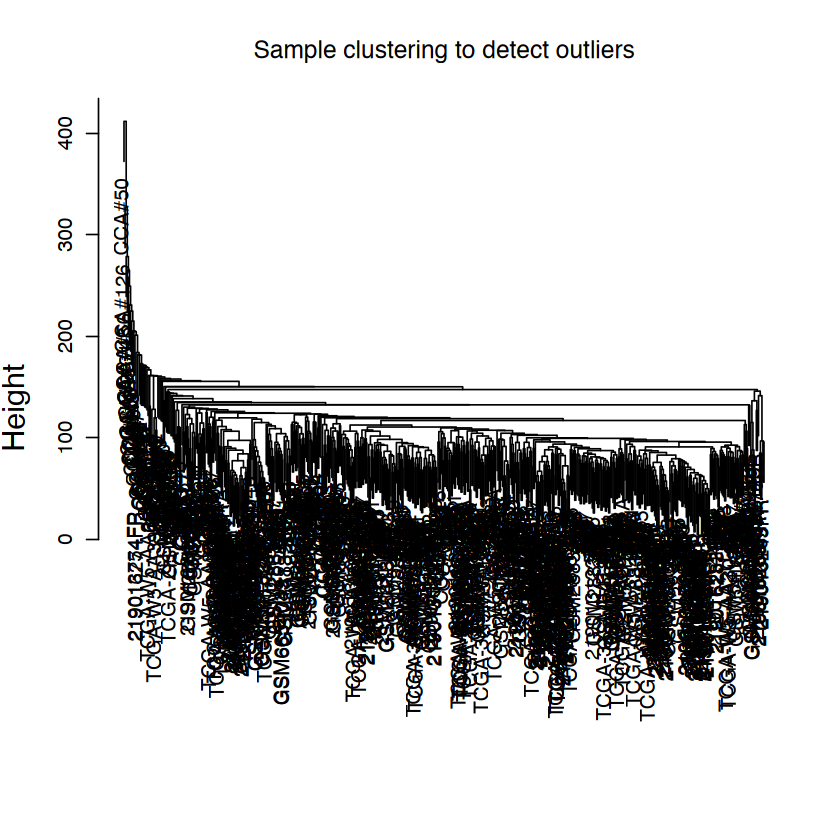

In [15]:
## 样本聚类检测异常
sampleTree <- hclust(dist(datExpr), method = "average")
plot(sampleTree, main = "Sample clustering to detect outliers", sub="", xlab="", cex.lab = 1.5)

pickSoftThreshold: will use block size 4248.
 pickSoftThreshold: calculating connectivity for given powers...
   ..working on genes 1 through 4248 of 10531
   ..working on genes 4249 through 8496 of 10531
   ..working on genes 8497 through 10531 of 10531
   Power SFT.R.sq  slope truncated.R.sq  mean.k. median.k.  max.k.
1      1   0.2600  1.620          0.944 2.09e+03  2.10e+03 3440.00
2      2   0.0724 -0.495          0.936 5.87e+02  5.61e+02 1400.00
3      3   0.4910 -1.370          0.974 1.98e+02  1.75e+02  649.00
4      4   0.7010 -1.800          0.987 7.56e+01  6.20e+01  329.00
5      5   0.7920 -2.040          0.991 3.19e+01  2.40e+01  180.00
6      6   0.8400 -2.140          0.995 1.45e+01  9.85e+00  104.00
7      7   0.8700 -2.170          0.997 7.06e+00  4.29e+00   62.10
8      8   0.8820 -2.140          0.994 3.64e+00  1.94e+00   38.40
9      9   0.8970 -2.060          0.990 1.98e+00  9.08e-01   25.00
10    10   0.8940 -2.270          0.989 1.13e+00  4.39e-01   21.60
11    11

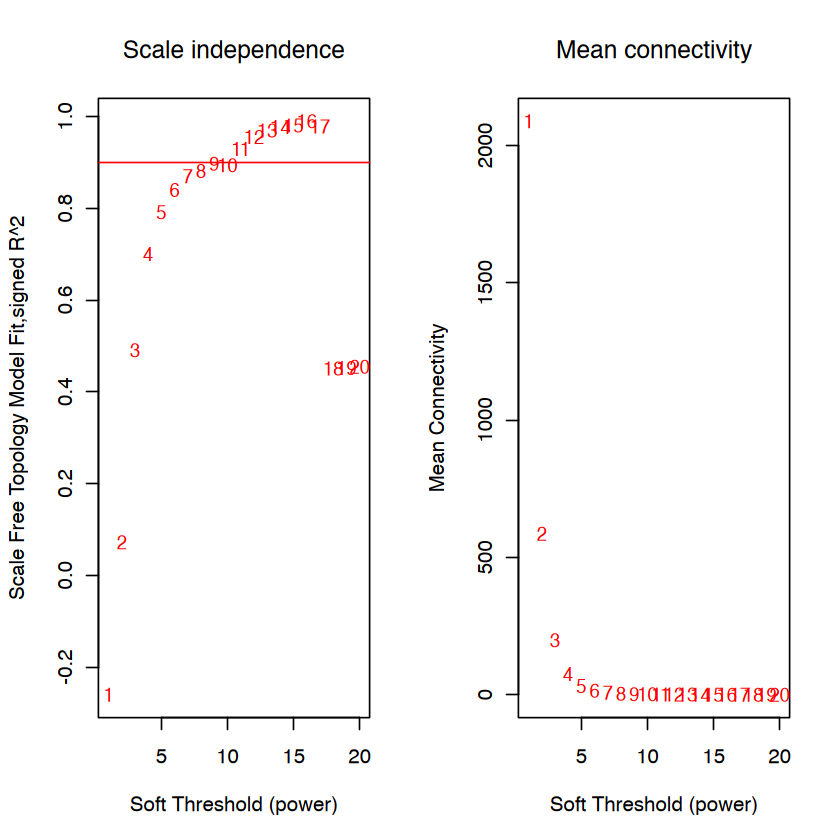

In [16]:
# 选择软阈值
powers <- c(1:20)
sft <- pickSoftThreshold(datExpr, powerVector = powers, verbose = 5)
# 可视化
par(mfrow = c(1,2))
plot(sft$fitIndices[,1], -sign(sft$fitIndices[,3])*sft$fitIndices[,2],
     xlab="Soft Threshold (power)", ylab="Scale Free Topology Model Fit,signed R^2",
     type="n", main = "Scale independence")
text(sft$fitIndices[,1], -sign(sft$fitIndices[,3])*sft$fitIndices[,2],
     labels=powers, cex=0.9, col="red")
abline(h=0.9, col="red")
plot(sft$fitIndices[,1], sft$fitIndices[,5],
     xlab="Soft Threshold (power)", ylab="Mean Connectivity", type="n",
     main = "Mean connectivity")
text(sft$fitIndices[,1], sft$fitIndices[,5], labels=powers, cex=0.9, col="red")

In [17]:
# 选择合适的power（如满足scale free R^2>0.9的最小power）
softPower <- sft$powerEstimate
if (is.null(softPower) || is.na(softPower)) softPower <- 11 # 若未自动选出，可手动设定

In [18]:
# 构建网络并识别模块
net <- blockwiseModules(
    datExpr,
    power = softPower,
    TOMType = "unsigned",
    minModuleSize = 30,
    reassignThreshold = 0,
    mergeCutHeight = 0.25,
    numericLabels = TRUE,
    pamRespectsDendro = FALSE,
    saveTOMs = FALSE,
    verbose = 3
)

moduleColors <- labels2colors(net$colors)

 Calculating module eigengenes block-wise from all genes
   Flagging genes and samples with too many missing values...
    ..step 1
 ....pre-clustering genes to determine blocks..
   Projective K-means:
   ..k-means clustering..
   ..merging smaller clusters...
Block sizes:
gBlocks
   1    2    3 
4997 4987  547 
 ..Working on block 1 .
    TOM calculation: adjacency..
    ..will not use multithreading.
     Fraction of slow calculations: 0.000000
    ..connectivity..
    ..matrix multiplication (system BLAS)..
    ..normalization..
    ..done.
 ....clustering..
 ....detecting modules..
 ....calculating module eigengenes..
 ....checking kME in modules..
     ..removing 1 genes from module 3 because their KME is too low.
 ..Working on block 2 .
    TOM calculation: adjacency..
    ..will not use multithreading.
     Fraction of slow calculations: 0.000000
    ..connectivity..
    ..matrix multiplication (system BLAS)..
    ..normalization..
    ..done.
 ....clustering..
 ....detecting m

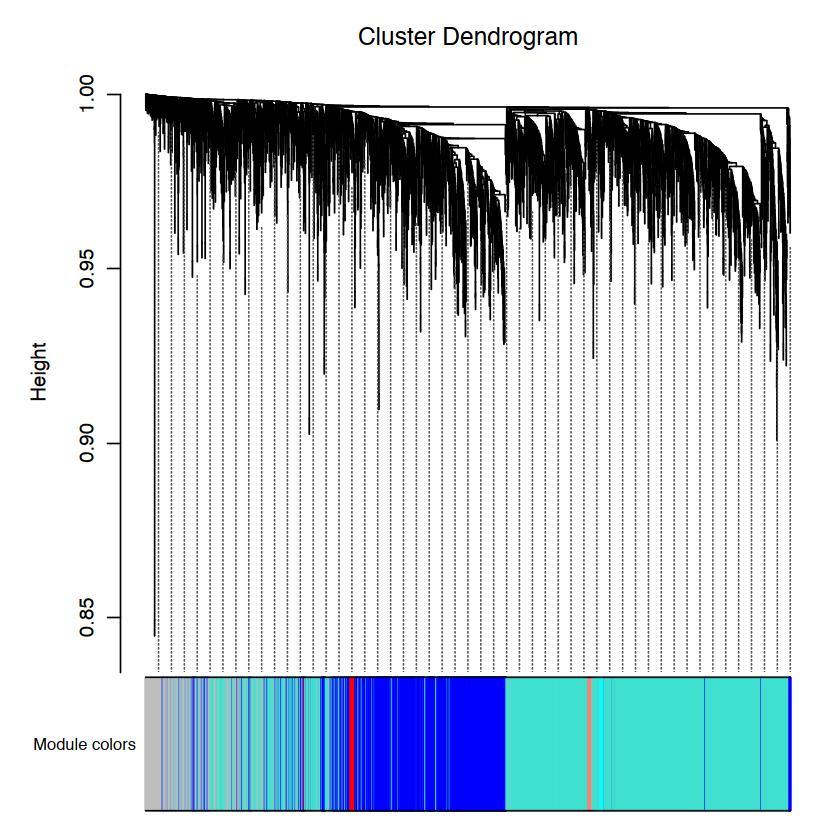

In [19]:
# 可视化模块与聚类树
plotDendroAndColors(
    net$dendrograms[[1]], 
    moduleColors[net$blockGenes[[1]]], 
    "Module colors",
    dendroLabels = FALSE, hang = 0.03, addGuide = TRUE, guideHang = 0.05
)

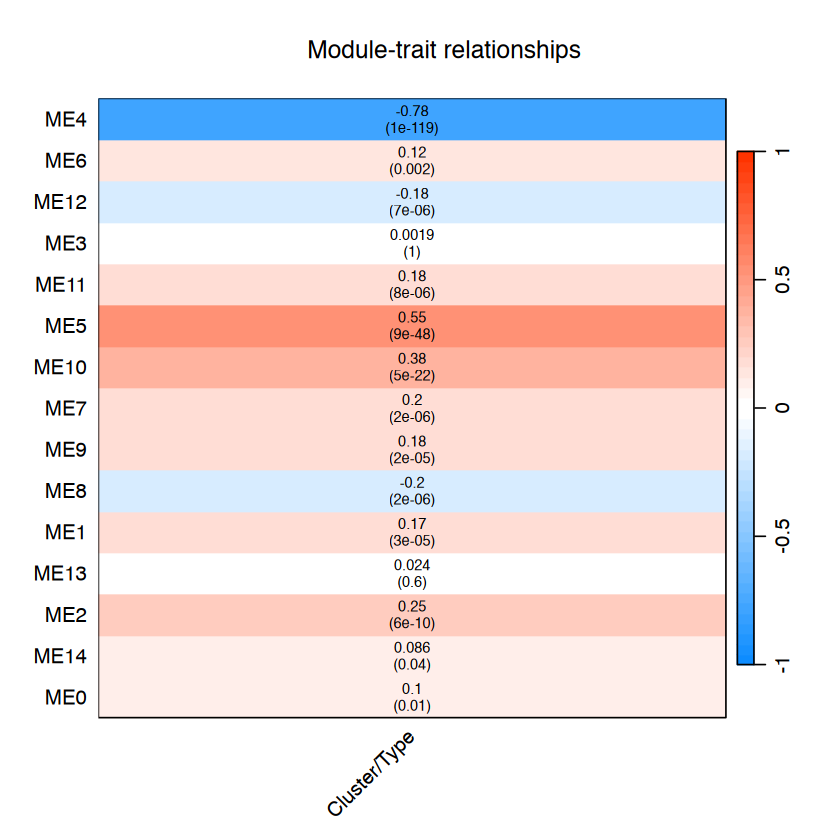

In [20]:
## 计算模块特征基因并与分型相关性
# 模块特征基因
MEs <- net$MEs

# 分型标签转为数字型（如A/B/C -> 1/2/3）
if (is.character(final_clusters) || is.factor(final_clusters)) {
    group_num <- as.numeric(as.factor(final_clusters))
} else {
    group_num <- final_clusters
}

# 计算每个模块与分型的相关性及p值
moduleTraitCor <- cor(MEs, group_num, use="p")
moduleTraitPvalue <- corPvalueStudent(moduleTraitCor, nrow(datExpr))

# 可视化相关性热图
textMatrix <- paste(signif(moduleTraitCor, 2), "\n(", signif(moduleTraitPvalue, 1), ")", sep = "")
labeledHeatmap(
    Matrix = moduleTraitCor,
    xLabels = "Cluster/Type",
    yLabels = names(MEs),
    ySymbols = names(MEs),
    colorLabels = FALSE,
    colors = blueWhiteRed(50),
    textMatrix = textMatrix,
    setStdMargins = FALSE,
    cex.text = 0.7,
    zlim = c(-1,1),
    main = paste("Module-trait relationships")
)

In [39]:
# 核心一键操作
module_colors_order <- unique(moduleColors)
module_numbers <- as.numeric(gsub("ME", "", names(MEs)))
ME_color_map <- data.frame(
  ME = names(MEs),
  module_number = module_numbers,
  color = module_colors_order[module_numbers + 1]
)
print(ME_color_map)

     ME module_number       color
1   ME4             4     magenta
2   ME6             6        grey
3  ME12            12        cyan
4   ME3             3       green
5  ME11            11      purple
6   ME5             5        pink
7  ME10            10       black
8   ME7             7 greenyellow
9   ME9             9         red
10  ME8             8   turquoise
11  ME1             1      yellow
12 ME13            13         tan
13  ME2             2       brown
14 ME14            14      salmon
15  ME0             0        blue


In [38]:
# 假设ME4和ME5分别是数字4、5
genes_ME4 <- names(moduleColors)[moduleColors == "magenta"]
genes_ME5 <- names(moduleColors)[moduleColors == "pink"]

cat("ME4基因数:", length(genes_ME4), "\n")
cat("ME5基因数:", length(genes_ME5), "\n")

ME4<U+57FA><U+56E0><U+6570>: 111 
ME5<U+57FA><U+56E0><U+6570>: 203 


'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(genes_ME4, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db):
"0.9% of input gene IDs are fail to map..."
'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(genes_ME5, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db):
"0.49% of input gene IDs are fail to map..."
Reading KEGG annotation online: "https://rest.kegg.jp/link/hsa/pathway"...

Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/hsa"...



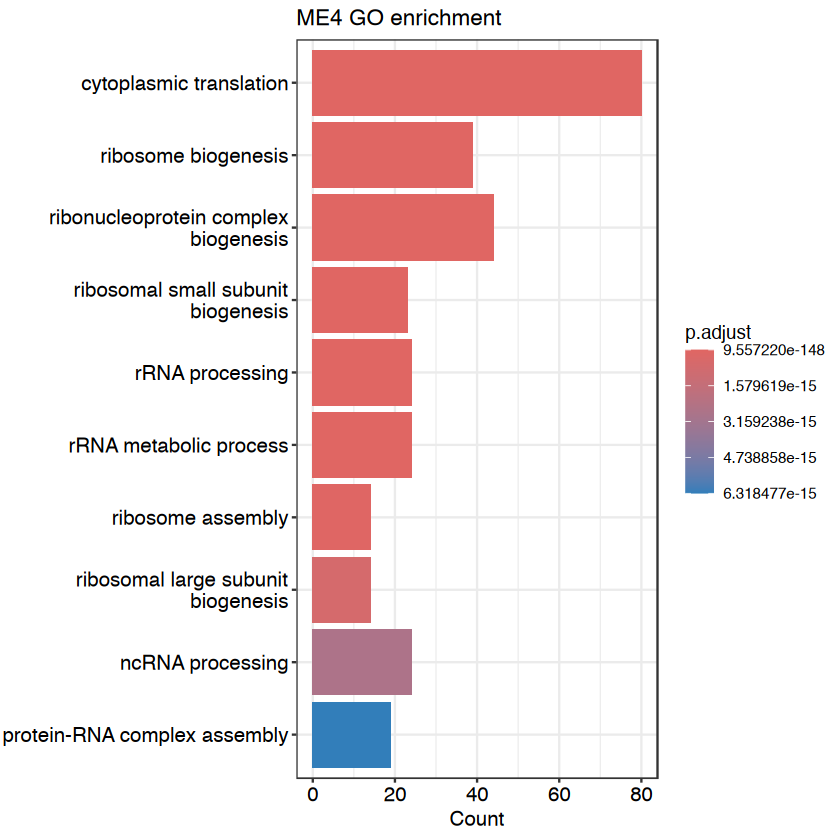

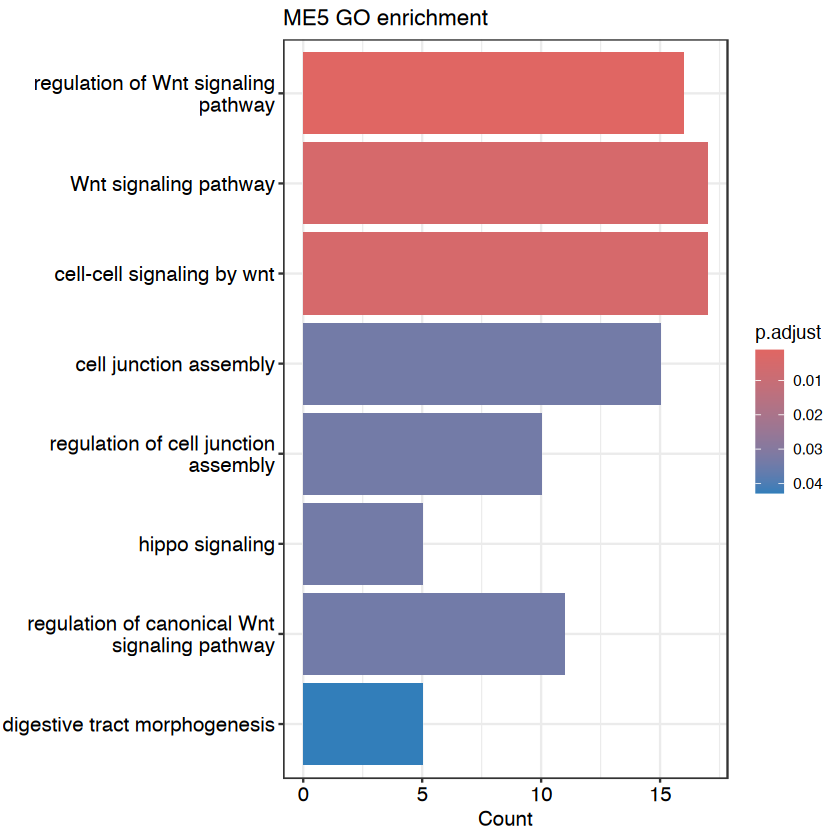

Warning message in rep(yes, length.out = len):
"'x' is NULL so the result will be NULL"
ERROR while rich displaying an object: Error in ans[ypos] <- rep(yes, length.out = len)[ypos]: replacement has length zero

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)

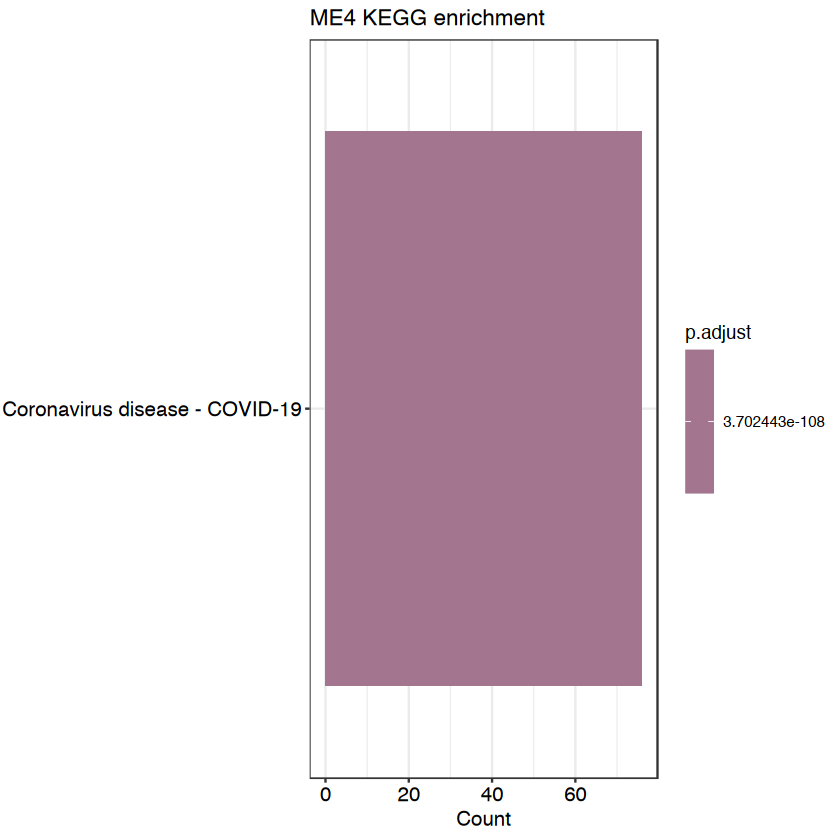

In [40]:
if (!requireNamespace("clusterProfiler", quietly = TRUE))
    BiocManager::install("clusterProfiler")
if (!requireNamespace("org.Hs.eg.db", quietly = TRUE))
    BiocManager::install("org.Hs.eg.db")
library(clusterProfiler)
library(org.Hs.eg.db)

# 转换为ENTREZID
gene_df4 <- bitr(genes_ME4, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db)
gene_df5 <- bitr(genes_ME5, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db)

# GO富集
ego4 <- enrichGO(gene = gene_df4$ENTREZID, OrgDb = org.Hs.eg.db, keyType = "ENTREZID",
                 ont = "BP", pAdjustMethod = "BH", qvalueCutoff = 0.05)
ego5 <- enrichGO(gene = gene_df5$ENTREZID, OrgDb = org.Hs.eg.db, keyType = "ENTREZID",
                 ont = "BP", pAdjustMethod = "BH", qvalueCutoff = 0.05)

# KEGG富集
ekegg4 <- enrichKEGG(gene = gene_df4$ENTREZID, organism = "hsa",
                     pAdjustMethod = "BH", qvalueCutoff = 0.05)
ekegg5 <- enrichKEGG(gene = gene_df5$ENTREZID, organism = "hsa",
                     pAdjustMethod = "BH", qvalueCutoff = 0.05)

# 可视化
barplot(ego4, showCategory=10, title="ME4 GO enrichment")
barplot(ego5, showCategory=10, title="ME5 GO enrichment")
barplot(ekegg4, showCategory=10, title="ME4 KEGG enrichment")
barplot(ekegg5, showCategory=10, title="ME5 KEGG enrichment")

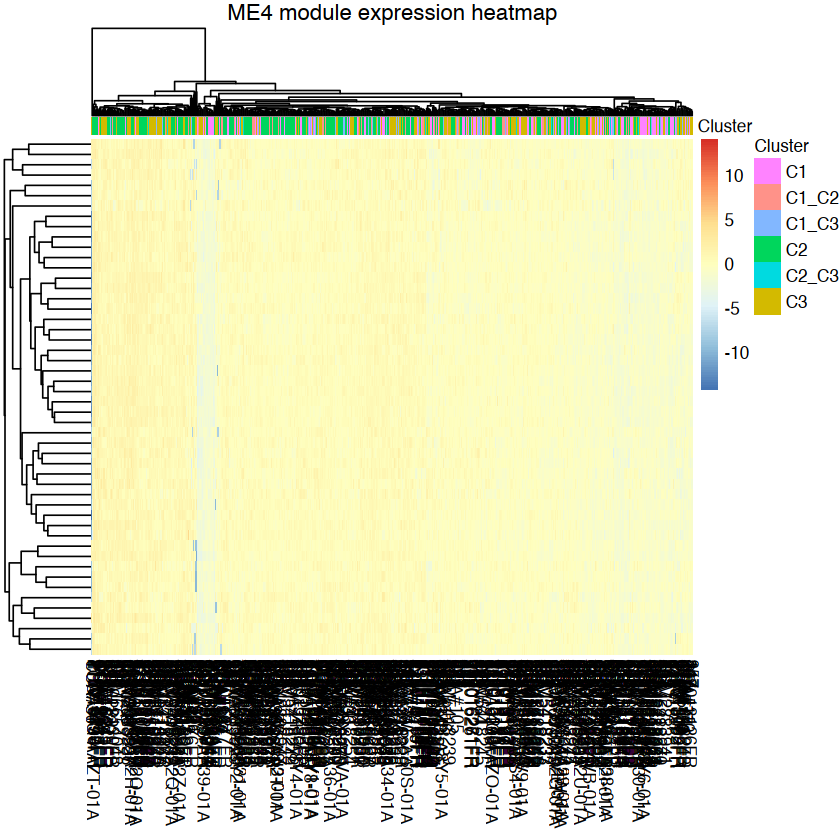

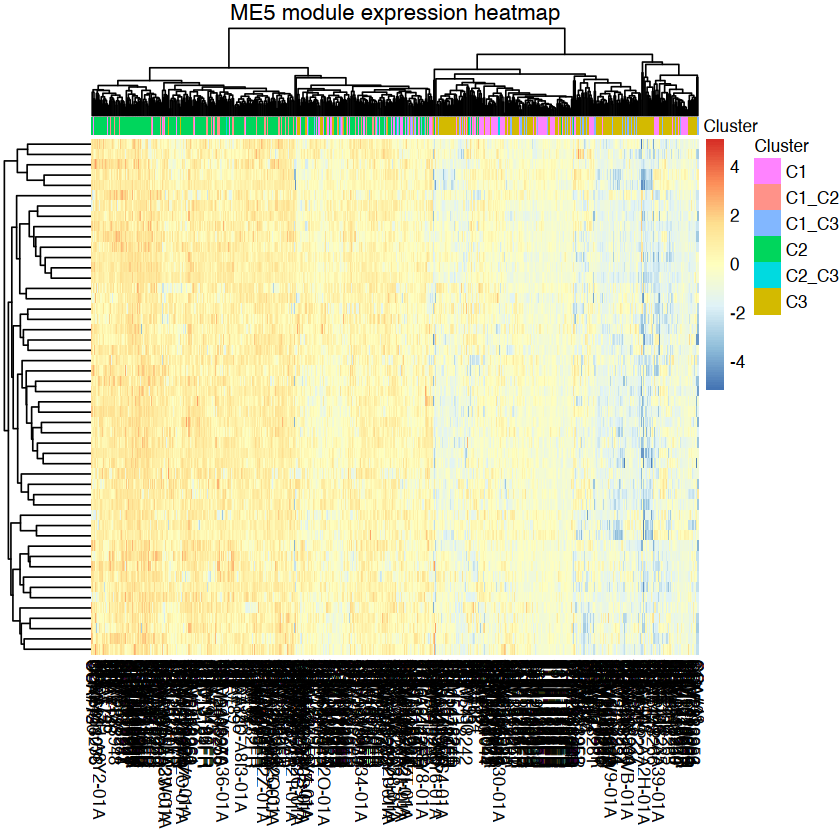

In [41]:
## 热图（pheatmap）
library(pheatmap)

# 选择高变异前50基因，可自行调整
get_top_var_genes <- function(expr, genes, n=50) {
  dat <- expr[genes, ]
  if (length(genes) > n) {
    gene_var <- apply(dat, 1, var)
    dat <- dat[order(gene_var, decreasing=TRUE)[1:n], ]
  }
  return(dat)
}

expr_ME4 <- get_top_var_genes(corrected_expr_limma, genes_ME4, 50)
expr_ME5 <- get_top_var_genes(corrected_expr_limma, genes_ME5, 50)

annotation_col <- data.frame(Cluster=final_clusters)
rownames(annotation_col) <- colnames(corrected_expr_limma)

pheatmap(expr_ME4, scale="row", annotation_col=annotation_col, show_rownames=FALSE,
         main="ME4 module expression heatmap")
pheatmap(expr_ME5, scale="row", annotation_col=annotation_col, show_rownames=FALSE,
         main="ME5 module expression heatmap")

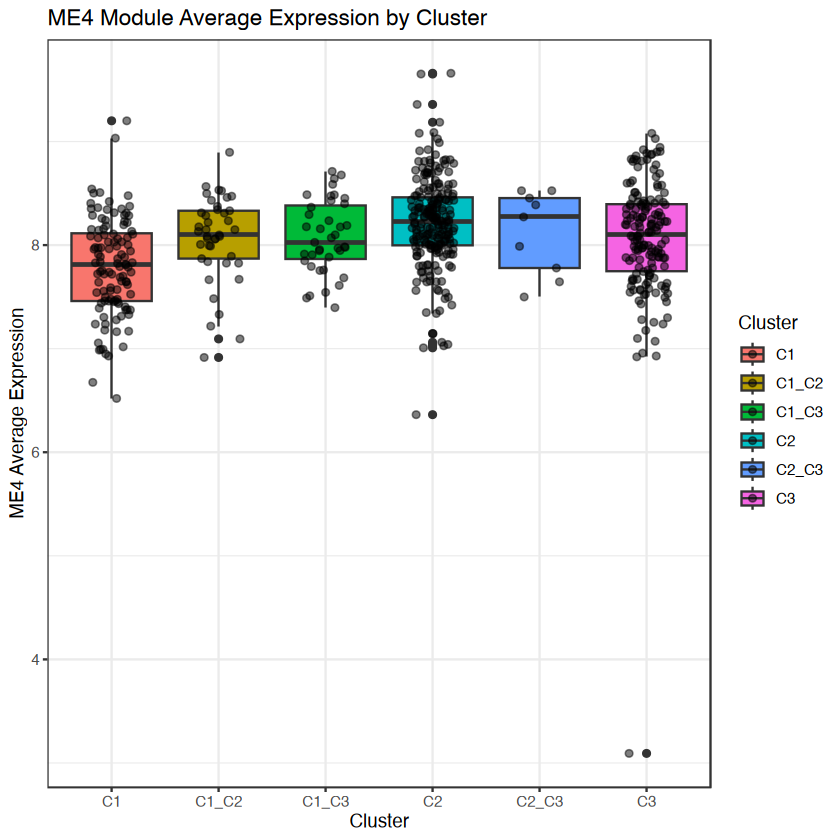

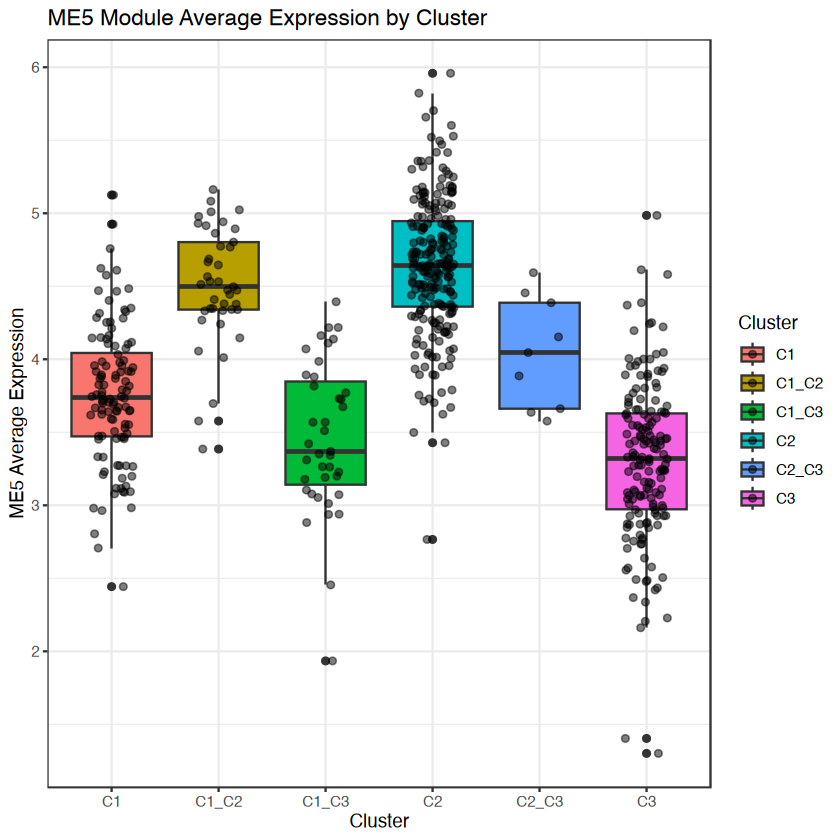

In [42]:
## 箱线图（每个样本的模块平均表达）
library(ggplot2)

modexpr_ME4 <- colMeans(corrected_expr_limma[genes_ME4, , drop=FALSE])
modexpr_ME5 <- colMeans(corrected_expr_limma[genes_ME5, , drop=FALSE])
box_df <- data.frame(
  ME4 = modexpr_ME4,
  ME5 = modexpr_ME5,
  Cluster = final_clusters
)

# ME4
ggplot(box_df, aes(x=Cluster, y=ME4, fill=Cluster)) +
  geom_boxplot() +
  geom_jitter(width=0.2, alpha=0.5) +
  theme_bw() +
  labs(title="ME4 Module Average Expression by Cluster", y="ME4 Average Expression")

# ME5
ggplot(box_df, aes(x=Cluster, y=ME5, fill=Cluster)) +
  geom_boxplot() +
  geom_jitter(width=0.2, alpha=0.5) +
  theme_bw() +
  labs(title="ME5 Module Average Expression by Cluster", y="ME5 Average Expression")

In [43]:
write.table(genes_ME4, file="ME4_genes.txt", quote=F, row.names=F, col.names=F)
write.table(genes_ME5, file="ME5_genes.txt", quote=F, row.names=F, col.names=F)